---

# **Dataset Preparation for Gemma3 1B Reasoning Fine-Tuning**

> Link: https://www.kaggle.com/code/kuhans/gemma3-tunix-reasoning-dataset-creation

Read this document for complete reasoning of this notebook

### Why Build a Custom Dataset?

Existing reasoning datasets present several limitations for fine-tuning a compact 1B parameter model:

| Challenge | Impact | Solution |
|-----------|--------|----------|
| **Inconsistent formatting** | Different schemas across datasets complicate unified training pipelines | Standardized 6-field schema across all domains |
| **Missing reasoning traces** | Many QA datasets provide answers without explicit chain-of-thought | Curated sources with explicit reasoning steps |
| **Quality variance** | Raw data contains noise, duplicates, and context-limit violations | Multi-stage filtering with deduplication & token validation |
| **Domain imbalance** | Heavy math/coding focus underrepresents real-world reasoning diversity | Balanced allocation across 6 reasoning domains |

### Dataset Size Note

> Quality over Quantity: The initial plan targets ~42K train + 7K validation 
(~49K total), though the final size will vary based on filtering results. 
Iterative quality checks and token constraints will shape the final 
composition, flexibility built in for optimization.


### Why These Domains?

The [Google TunIX Hackathon](https://www.kaggle.com/competitions/google-tunix-hackathon/overview) evaluation spans diverse reasoning capabilities. The domain selection ensures coverage of:

- **Analytical reasoning** → Math, Coding, Science
- **World knowledge** → Basic Science, Commonsense  
- **Language understanding** → Summarization, Creative
- **Multi-step inference** → All domains via explicit reasoning traces

### Output Format

| Format | Purpose | Compression |
|--------|---------|-------------|
| **Parquet** (Primary) | Optimized storage with Snappy compression, dictionary encoding | ~3-4x smaller than JSON |
| **JSONL** (Backup) | Compatibility with streaming loaders | UTF-8 with full Unicode sanitization |

---

### **IMPORTS & GLOBAL CONFIGURATION**

In [1]:
# Standard library
import re
import json
import random
from collections import defaultdict, Counter  # Data aggregation

# Data processing
import numpy as np
import pandas as pd

# HuggingFace
from datasets import Dataset, DatasetDict, load_dataset  # Dataset loading
from transformers import AutoTokenizer  # Tokenization for context limits

# PyTorch (optional - for complete seed fixing)
try:
    import torch
    torch.manual_seed(42)
    torch.cuda.manual_seed_all(42)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    TORCH_AVAILABLE = True
except ImportError:
    TORCH_AVAILABLE = False

# ────────────────────────────────────────────────────────────
# GLOBAL CONSTANTS
# ────────────────────────────────────────────────────────────

# Reproducibility
GLOBAL_SEED = 42
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)

TRAIN_RATIO = 0.95
TEST_RATIO = 0.05

# # UNRESTRICTED (40K)
# DOMAIN_TARGETS = {
#     'math':          {'total': 12300, 'train': 11685, 'test': 615},
#     'commonsense':   {'total': 12300, 'train': 11685, 'test': 615},
#     'science':       {'total': 11900, 'train': 11305, 'test': 595},
#     'coding':        {'total': 7348,  'train': 7734,  'test': 386},
#     'summarization': {'total': 3760,  'train': 3572,  'test': 188},
#     'creative':      {'total': 4830,  'train': 4590,  'test': 240},
# }

# SINGLE SESSION MODE
DOMAIN_TARGETS = {
    'math':          {'total': 4000,  'train': 3800,  'test': 200},
    'coding':        {'total': 4000,  'train': 3800,  'test': 200},
    'commonsense':   {'total': 10000, 'train': 9500,  'test': 500},
    'science':       {'total': 8000,  'train': 7600,  'test': 400},
    'summarization': {'total': 3760,  'train': 3572,  'test': 188},
    'creative':      {'total': 4830,  'train': 4590,  'test': 240},
}

TRAIN_SIZE = sum(d['train'] for d in DOMAIN_TARGETS.values())
TEST_SIZE = sum(d['test'] for d in DOMAIN_TARGETS.values())
TOTAL_EXAMPLES = sum(d['total'] for d in DOMAIN_TARGETS.values())

print("DOMAIN_TARGETS = {")
for domain, vals in DOMAIN_TARGETS.items():
    print(f"    '{domain}':{' '*(13-len(domain))}{{'total': {vals['total']},  'train': {vals['train']}, 'test': {vals['test']}}},")
print("}")

print(f"\nTrain: {TRAIN_SIZE:,}")
print(f"Test:  {TEST_SIZE:,}")
print(f"Total: {TOTAL_EXAMPLES:,}\n")

# Quality thresholds
MIN_QUESTION_LEN = 10
MIN_ANSWER_LEN = 5
MIN_REASONING_LEN = 80
MIN_SUPPORT_LENGTH = 100  # For science domain datasets

# Validation
REQUIRED_FIELDS = {'question', 'answer', 'reasoning', 'topic', 'domain', 'category'}

# Output files
OUTPUT_FILES = {
    'train': 'gemma3-1B-tunix-finetune-unified_train.jsonl',
    'test': 'gemma3-1B-tunix-finetune-unified_test.jsonl'
}

# ────────────────────────────────────────────────────────────
# HUGGINGFACE AUTHENTICATION (KAGGLE COMPATIBLE)
# ────────────────────────────────────────────────────────────
import os

# Add HF_TOKEN in add-ons
try:
    from kaggle_secrets import UserSecretsClient
    secrets = UserSecretsClient()
    HF_TOKEN = secrets.get_secret("HF_TOKEN")
    print("Using HF token from Kaggle secrets")
except:
    HF_TOKEN = os.environ.get("HF_TOKEN") or os.environ.get("HUGGINGFACE_TOKEN")
    if HF_TOKEN:
        print("Using HF token from environment variable")
    else:
        print("No HF token found - some models may not be accessible")
        HF_TOKEN = None

# Tokenizer (loaded once for efficiency)
tokenizer = AutoTokenizer.from_pretrained(
    "google/gemma-3-1b-it",
    token=HF_TOKEN
)

# Token/context limits
CONTEXT_LIMIT = 4096   # Max training context for Gemma 1B (32,768 tokens), but for FT efficiency, use 4096
SAFETY_BUFFER = len(tokenizer.encode("\n<reasoning></reasoning>\n\n<answer></answer>"))+2     # Buffer for special tokens (<reasoning></reasoning>, <answer></answer>)

print(f"Context size: {CONTEXT_LIMIT}")
print(f"Extra buffer token length (<reasoning>, <answers> tags): {SAFETY_BUFFER}")
print(f"Room for training data: {CONTEXT_LIMIT - SAFETY_BUFFER}")

# Suppress warnings
import warnings
warnings.filterwarnings("ignore", message="Some datasets params were ignored")

# ────────────────────────────────────────────────────────────
# UNICODE CLEANING (prevents validation failures)
# ────────────────────────────────────────────────────────────

PROBLEMATIC_UNICODE = {
    # CRITICAL - Line separators (break JSONL parsing!)
    '\u2028': ' ',    # LINE SEPARATOR → space
    '\u2029': ' ',    # PARAGRAPH SEPARATOR → space
    
    # Invisible/zero-width characters
    '\u00a0': ' ',    # NON-BREAKING SPACE → regular space
    '\u200b': '',     # ZERO-WIDTH SPACE → remove
    '\u200c': '',     # ZERO-WIDTH NON-JOINER → remove
    '\u200d': '',     # ZERO-WIDTH JOINER → remove
    '\u2060': '',     # WORD JOINER → remove
    '\ufeff': '',     # BOM (Byte Order Mark) → remove
    
    # Null and control characters
    '\u0000': '',     # NULL character → remove
    '\ufffe': '',     # NONCHARACTER → remove
    '\uffff': '',     # NONCHARACTER → remove
    
    # Ambiguous hyphens/dashes → standard hyphen
    '\u00ad': '',     # SOFT HYPHEN → remove
    '\u2010': '-',    # HYPHEN
    '\u2011': '-',    # NON-BREAKING HYPHEN
    '\u2012': '-',    # FIGURE DASH
    '\u2013': '-',    # EN DASH
    '\u2014': '-',    # EM DASH
    
    # Ambiguous quotes → standard quotes
    '\u2018': "'",    # LEFT SINGLE QUOTE
    '\u2019': "'",    # RIGHT SINGLE QUOTE
    '\u201c': '"',    # LEFT DOUBLE QUOTE
    '\u201d': '"',    # RIGHT DOUBLE QUOTE
    
    # Other typography
    '\u2026': '...',  # HORIZONTAL ELLIPSIS
    '\u00b7': '.',    # MIDDLE DOT
}

def clean_unicode(text):
    """Remove problematic Unicode characters that break JSON parsing or training."""
    if not isinstance(text, str):
        return text
    for char, replacement in PROBLEMATIC_UNICODE.items():
        text = text.replace(char, replacement)
    return text

def clean_example(ex):
    """Clean all string fields in an example dict."""
    return {k: clean_unicode(v) if isinstance(v, str) else v for k, v in ex.items()}

# ────────────────────────────────────────────────────────────
# QUICK VERIFICATION
# ────────────────────────────────────────────────────────────
print("\n" + "=" * 70)
print(f"Imports loaded | Seed: {GLOBAL_SEED} | PyTorch: {TORCH_AVAILABLE}")
print(f"Target: {TOTAL_EXAMPLES:,} examples ({TRAIN_SIZE:,} train / {TEST_SIZE:,} test)")
print(f"Domains: {list(DOMAIN_TARGETS.keys())}")
print(f"Unicode cleaning: {len(PROBLEMATIC_UNICODE)} problematic chars will be cleaned")
print("=" * 70)

DOMAIN_TARGETS = {
    'math':         {'total': 4000,  'train': 3800, 'test': 200},
    'coding':       {'total': 4000,  'train': 3800, 'test': 200},
    'commonsense':  {'total': 10000,  'train': 9500, 'test': 500},
    'science':      {'total': 8000,  'train': 7600, 'test': 400},
    'summarization':{'total': 3760,  'train': 3572, 'test': 188},
    'creative':     {'total': 4830,  'train': 4590, 'test': 240},
}

Train: 32,862
Test:  1,728
Total: 34,590

Using HF token from Kaggle secrets


tokenizer_config.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/4.69M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

Context size: 4096
Extra buffer token length (<reasoning>, <answers> tags): 17
Room for training data: 4079

Imports loaded | Seed: 42 | PyTorch: True
Target: 34,590 examples (32,862 train / 1,728 test)
Domains: ['math', 'coding', 'commonsense', 'science', 'summarization', 'creative']
Unicode cleaning: 23 problematic chars will be cleaned


In [2]:
# ────────────────────────────────────────────────────────────
# UTILITY FUNCTIONS
# ────────────────────────────────────────────────────────────

def format_example(ex):
    """Format example for token counting."""
    return f"Question: {ex['question']}\n\nDomain: {ex['domain']}\nTopic: {ex['topic']}\nCategory: {ex['category']}\n\nReasoning: {ex['reasoning']}\n\nAnswer: {ex['answer']}"

def count_tokens(text):
    """Count tokens using global tokenizer."""
    return len(tokenizer.encode(text, add_special_tokens=True))

def load_jsonl(paths):
    """Load data from JSONL file(s)."""
    if isinstance(paths, str):
        paths = [paths]
    data = []
    for path in paths:
        with open(path, 'r') as f:
            for line in f:
                data.append(json.loads(line))
    return data

def validate_domain(train_paths, test_paths, domain_name="DOMAIN"):
    """Validate and analyze domain dataset files."""
    print("=" * 70)
    print(f"{domain_name.upper()} - VALIDATION & TOKEN ANALYSIS")
    print("=" * 70)
    
    def validate_data(data, split_name):
        errors = []
        for i, ex in enumerate(data):
            missing = REQUIRED_FIELDS - set(ex.keys())
            if missing:
                errors.append(f"{split_name}[{i}]: missing {missing}")
                continue
            for field in REQUIRED_FIELDS:
                val = ex.get(field)
                if val is None or (isinstance(val, str) and not val.strip()):
                    errors.append(f"{split_name}[{i}]: {field} is NULL/empty")
        return errors
    
    # Load & validate
    train_data = load_jsonl(train_paths)
    test_data = load_jsonl(test_paths)
    all_errors = validate_data(train_data, "train") + validate_data(test_data, "test")
    
    print(f"\n[VALIDATION]")
    print(f"  Train: {len(train_data):,} | Test: {len(test_data):,}")
    print(f"  Errors: {len(all_errors)} {'✓' if len(all_errors) == 0 else '✗'}")
    
    if all_errors:
        for e in all_errors[:5]:
            print(f"    - {e}")
        if len(all_errors) > 5:
            print(f"    ... and {len(all_errors) - 5} more")
        return
    
    # Token analysis
    train_tokens = [count_tokens(format_example(ex)) + SAFETY_BUFFER for ex in train_data]
    test_tokens = [count_tokens(format_example(ex)) + SAFETY_BUFFER for ex in test_data]
    all_tokens = train_tokens + test_tokens
    
    train_over = sum(1 for t in train_tokens if t > CONTEXT_LIMIT)
    test_over = sum(1 for t in test_tokens if t > CONTEXT_LIMIT)
    
    print(f"\n[TOKEN ANALYSIS] (limit: {CONTEXT_LIMIT:,})")
    print(f"  Exceeding: {train_over + test_over} {'✓' if train_over + test_over == 0 else '✗'}")
    print(f"\n[STATS] Min: {min(all_tokens):,} | Max: {max(all_tokens):,} | Avg: {np.mean(all_tokens):,.0f} | P95: {np.percentile(all_tokens, 95):,.0f}")
    print(f"[TOTAL] Train: {sum(train_tokens):,} | Test: {sum(test_tokens):,}")
    print("=" * 70)

def sanitize_text(text):
    """Remove problematic Unicode characters from text."""
    if not isinstance(text, str):
        return text
    for char, replacement in PROBLEMATIC_UNICODE.items():
        text = text.replace(char, replacement)
    return text

def sanitize_example(example):
    """Sanitize all string fields in an example."""
    return {k: sanitize_text(v) if isinstance(v, str) else v for k, v in example.items()}


def save_domain(data_dict, domain_name, output_dir="ds"):
    """Save domain dataset to JSONL files with Unicode sanitization."""
    os.makedirs(output_dir, exist_ok=True)
    
    print(f"SAVING {domain_name.upper()}: ", end="")
    output_files = {}
    total_sanitized = 0
    
    for split_name, data in data_dict.items():
        filepath = os.path.join(output_dir, f"the_{domain_name}_{split_name}.jsonl")
        split_sanitized = 0
        
        with open(filepath, 'w', encoding='utf-8') as f:
            for ex in data:
                # Sanitize before saving to prevent Unicode issues
                original_str = json.dumps(ex, ensure_ascii=False)
                sanitized_ex = sanitize_example(ex)
                sanitized_str = json.dumps(sanitized_ex, ensure_ascii=False)
                
                if original_str != sanitized_str:
                    split_sanitized += 1
                
                f.write(sanitized_str + '\n')
        
        output_files[split_name] = filepath
        total_sanitized += split_sanitized
        print(f"{split_name}={len(data):,} ", end="")
    
    if total_sanitized > 0:
        print(f"(File sanitized {total_sanitized}) ", end="")
    print("✓")
    return output_files

---

### **DATA SOURCES**

Load all source datasets for the 6 reasoning domains:

| Domain | Datasets | Rationale |
|--------|----------|-----------|
| **Math** | [GSM8K](https://huggingface.co/datasets/openai/gsm8k), [Hendrycks MATH](https://huggingface.co/datasets/EleutherAI/hendrycks_math) (3 subsets) | Grade-school + competition-level problems with step-by-step solutions |
| **Coding** | [rStar-Coder](https://huggingface.co/datasets/microsoft/rStar-Coder) | Verified & passed code solutions with reasoning traces |
| **Science** | [SciQ](https://huggingface.co/datasets/allenai/sciq), [Academic Chains](https://huggingface.co/datasets/marcodsn/academic-chains) | Multiple-choice science QA + research paper reasoning chains |
| **Summarization** | [Qwen Thinking Summaries](https://huggingface.co/datasets/davanstrien/qwen-thinking-summaries), [ACLSum](https://huggingface.co/datasets/sobamchan/aclsum), AllenAI Big Reasoning Traces | CoT summaries + academic abstracts + synthetic reasoning |
| **Creative** | [RekRek Stories](https://huggingface.co/datasets/rekrek/reasoning-engaging-story), AllenAI Big Reasoning Traces | Story generation with explicit reasoning traces |
| **Commonsense** | [StrategyQA](https://huggingface.co/datasets/ChilleD/StrategyQA), [ECQA](https://huggingface.co/datasets/yangdong/ecqa) | Multi-hop reasoning + explained commonsense QA |

> **Note**: Creative and Summarization domains use tiered CSV data from [AllenAI Big Reasoning Traces](https://huggingface.co/datasets/allenai/big-reasoning-traces).

In [3]:
# ─────────────────────────────────────────────────────────────
# HUGGINGFACE DATASETS
# ─────────────────────────────────────────────────────────────

# --- MATH ---
gsm8k = load_dataset("openai/gsm8k", "main")
hendrycks_math_intermediate_algebra = load_dataset("EleutherAI/hendrycks_math", "intermediate_algebra")
hendrycks_math_counting_and_probability = load_dataset("EleutherAI/hendrycks_math", "counting_and_probability")
hendrycks_math_number_theory = load_dataset("EleutherAI/hendrycks_math", "number_theory")

# --- CODING ---
rStar_coder = load_dataset("microsoft/rStar-Coder", "seed_sft")

# --- SCIENCE ---
sciq = load_dataset("allenai/sciq")
academic_chains = load_dataset("marcodsn/academic-chains")

# --- SUMMARIZATION ---
qwen_thinking_summaries = load_dataset("davanstrien/qwen-thinking-summaries")
aclsum = load_dataset("sobamchan/aclsum", "abstractive")

# --- CREATIVE ---
rekrek = load_dataset("rekrek/reasoning-engaging-story", "default")

# --- COMMONSENSE ---
strategyqa = load_dataset("ChilleD/StrategyQA")
ecqa = load_dataset("yangdong/ecqa")

# ─────────────────────────────────────────────────────────────
# CSV DATASETS
# ─────────────────────────────────────────────────────────────

elite_summarization_csv = pd.read_csv("/kaggle/input/allenai-big-reasoning-traces/elite_summarization_reasoning_15k.csv")
elite_creative_csv = pd.read_csv("/kaggle/input/allenai-big-reasoning-traces/elite_creative_reasoning_15k.csv")

# ────────────────────────────────────────────────────────────
# SUMMARY
# ────────────────────────────────────────────────────────────

print("=" * 70)
print("DATASETS LOADED")
print("=" * 70)

print("\n[HUGGINGFACE DATASETS]")

print("\n  MATH")
print(f"    GSM8K:                          train={len(gsm8k['train']):,} | test={len(gsm8k['test']):,}")
print(f"    Hendrycks (Intermediate Alg):   train={len(hendrycks_math_intermediate_algebra['train']):,} | test={len(hendrycks_math_intermediate_algebra['test']):,}")
print(f"    Hendrycks (Counting & Prob):    train={len(hendrycks_math_counting_and_probability['train']):,} | test={len(hendrycks_math_counting_and_probability['test']):,}")
print(f"    Hendrycks (Number Theory):      train={len(hendrycks_math_number_theory['train']):,} | test={len(hendrycks_math_number_theory['test']):,}")

print("\n  CODING")
print(f"    rStar_coder:                    train={len(rStar_coder['train']):,}")

print("\n  SCIENCE")
print(f"    SciQ:                           train={len(sciq['train']):,} | val={len(sciq['validation']):,} | test={len(sciq['test']):,}")
print(f"    Academic Chains:                train={len(academic_chains['train']):,}")

print("\n  SUMMARIZATION")
print(f"    Qwen Thinking Summaries:        train={len(qwen_thinking_summaries['train']):,}")
print(f"    ACLSum:                         train={len(aclsum['train']):,} | val={len(aclsum['validation']):,} | test={len(aclsum['test']):,}")

print("\n  CREATIVE")
print(f"    RekRek Stories:                 v1={len(rekrek['v1']):,}")

print("\n  COMMONSENSE")
print(f"    StrategyQA:                     train={len(strategyqa['train']):,} | test={len(strategyqa['test']):,}")
print(f"    ECQA:                           train={len(ecqa['train']):,} | val={len(ecqa['validation']):,} | test={len(ecqa['test']):,}")

print("\n[CSV DATASETS - Elite Reasoning from AllenAI Big Reasoning Traces]")
print(f"    Elite Summarization:            rows={len(elite_summarization_csv):,} | cols={len(elite_summarization_csv.columns)}")
print(f"    Elite Creative:                 rows={len(elite_creative_csv):,} | cols={len(elite_creative_csv.columns)}")

print("\n" + "=" * 70)

README.md: 0.00B [00:00, ?B/s]

main/train-00000-of-00001.parquet:   0%|          | 0.00/2.31M [00:00<?, ?B/s]

main/test-00000-of-00001.parquet:   0%|          | 0.00/419k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

README.md: 0.00B [00:00, ?B/s]

... (69 outputs left out)

Generating train split:   0%|          | 0/7598 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1090 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2194 [00:00<?, ? examples/s]

DATASETS LOADED

[HUGGINGFACE DATASETS]

  MATH
    GSM8K:                          train=7,473 | test=1,319
    Hendrycks (Intermediate Alg):   train=1,295 | test=903
    Hendrycks (Counting & Prob):    train=771 | test=474
    Hendrycks (Number Theory):      train=869 | test=540

  CODING
    rStar_coder:                    train=591,660

  SCIENCE
    SciQ:                           train=11,679 | val=1,000 | test=1,000
    Academic Chains:                train=1,975

  SUMMARIZATION
    Qwen Thinking Summaries:        train=2,082
    ACLSum:                         train=100 | val=50 | test=100

  CREATIVE
    RekRek Stories:                 v1=110

  COMMONSENSE
    StrategyQA:                     train=1,603 | test=687
    ECQA:                           train=7,598 | val=1,090 | test=2,194

[CSV DATASETS - Elite Reasoning from AllenAI Big Reasoning Traces]
    Elite Summarization:            rows=1,634 | cols=7
    Elite Creative:                 rows=5,432 | cols=7



---

### **PIPELINE**

Each domain passes through a **three-stage pipeline** ensuring high-quality, balanced training data:

| Stage | Purpose | Key Operations |
|-------|---------|----------------|
| **Analysis** | Understand source distributions | Token counting, quality metrics, length analysis |
| **Sampling** | Extract optimal examples | Quality-based scoring, deduplication, train/test splitting |
| **Validation** | Ensure data integrity | Schema verification, leakage detection, token limit checks |

### Unified Output Schema

```python
{
    "question": str,    # Problem/prompt/instruction
    "answer": str,      # Final solution/output
    "reasoning": str,   # Chain-of-thought traces
    "topic": str,       # Specific topic within domain
    "domain": str,      # One of 6 domains
    "category": str     # SOURCE-BASED identifier (e.g., gsm8k_3steps, hendrycks_level_2, ecqa, rekrek)
}
```

### Source-Based Category System

Categories identify the **data source and characteristics**, NOT difficulty tiers:

| Domain | Category Examples | Description |
|--------|-------------------|-------------|
| **Math** | `gsm8k_1steps`, `gsm8k_5steps`, `hendrycks_level_1`, `hendrycks_level_4` | Source + step count or level |
| **Coding** | `rstar_coder` | Single verified source |
| **Science** | `sciq`, `academic_chains` | Dataset source name |
| **Summarization** | `qwen_thinking`, `aclsum`, `allenai_traces` | Dataset source name |
| **Creative** | `rekrek`, `csv_tier1`, `csv_tier2`, `csv_tier3`, `csv_tier4` | Source + quality tier |
| **Commonsense** | `ecqa`, `strategyqa` | Dataset source name |

### Quality Assurance

| Check | Threshold | Purpose |
|-------|-----------|---------|
| **Question Length** | ≥20 chars (≥30 for commonsense context) | Ensure standalone questions |
| **Reasoning Length** | ≥80-100 chars | Meaningful chain-of-thought |
| **Answer Length** | ≥2-100 chars (domain-specific) | Valid responses |
| **Deduplication** | Full question text (normalized) | Prevent memorization |
| **Leakage Check** | Zero train/test overlap | Valid evaluation |
| **Token Limit** | ≤4,084 tokens (4,096 - 12 buffer) | Gemma3 context window |
| **Unicode Sanitization** | 50+ problematic chars | Training stability |

### Train/Test Split Strategy

- **95% Train / 5% Test** per source
- **Quality-based ordering**: Best examples → Train, Second-best → Test
- **Stratified by source**: Each source represented in both splits

---

#### The Math

**Datasets**: GSM8K (train only), Hendrycks MATH (Intermediate Algebra, Counting & Probability, Number Theory).

**Quality Filtering**:
- Token limit: ≤4,084 tokens per example
- Priority sampling: GSM8K 3-5 steps first, then Hendrycks Level 2-3
- Answers extracted from `\boxed{}` with nested brace handling
- Deduplication by full question text

**Train/Test Split**: 95/5 stratified by category, quality-ordered (best → train).

> **Benchmark**: GSM8K actual test set preserved separately as `gsm8k_test` for standardized evaluation (not used in training).

In [4]:
# ────────────────────────────────────────────────────────────
# MATH DOMAIN - ANALYSIS
# ────────────────────────────────────────────────────────────

MATH_TOTAL = DOMAIN_TARGETS["math"]["total"]
MATH_TRAIN = DOMAIN_TARGETS["math"]["train"]
MATH_TEST = DOMAIN_TARGETS["math"]["test"]

MAX_TOKENS = CONTEXT_LIMIT - SAFETY_BUFFER  # 4096 - 12 = 4084

# ────────────────────────────────────────────────────────────
# TOKEN COUNTING
# ────────────────────────────────────────────────────────────

def count_math_tokens(question, answer, reasoning, topic="math"):
    """Count tokens for a formatted math example using actual tokenizer."""
    formatted = f"Question: {question}\n\nDomain: math\nTopic: {topic}\n\nReasoning: {reasoning}\n\nAnswer: {answer}"
    return len(tokenizer.encode(formatted, add_special_tokens=True))

# ────────────────────────────────────────────────────────────
# PRIORITY TIERS (for sampling order)
# ────────────────────────────────────────────────────────────

# GSM8K: Fill 3-5 steps first (95% train, 5% test), then 1-2, then 6+
GSM8K_PRIORITY_TIERS = {
    1: [3, 4, 5],      # Priority 1: 3-5 steps (sweet spot for 1B model)
    2: [1, 2],         # Priority 2: 1-2 steps (easier)
    3: [6, 7, 8, 9],   # Priority 3: 6+ steps (harder)
}

# Hendrycks: Fill Level 2-3 first, then 1, then 4, then 5
HENDRYCKS_PRIORITY_TIERS = {
    1: [2, 3],         # Priority 1: Level 2-3 (optimal difficulty)
    2: [1],            # Priority 2: Level 1 (easier)
    3: [4],            # Priority 3: Level 4 (challenging)
    4: [5],            # Priority 4: Level 5 (hardest - minimal)
}

# ────────────────────────────────────────────────────────────
# HENDRYCKS MATH - ANALYZE ALL LEVELS
# ────────────────────────────────────────────────────────────

def get_hendrycks_level(level_str):
    """Extract numeric level from Hendrycks level string."""
    return int(level_str.replace('Level ', ''))

def analyze_hendrycks_with_tokens(dataset, name):
    """Analyze Hendrycks subset with token counting and reasoning length."""
    # Combine train + test from Hendrycks (this is fine - it's Hendrycks splits)
    all_examples = list(dataset['train']) + list(dataset['test'])
    
    within_limit = []
    over_limit = []
    by_level = {1: [], 2: [], 3: [], 4: [], 5: []}
    token_counts = []
    
    for ex in all_examples:
        level = get_hendrycks_level(ex['level'])
        solution = ex['solution']
        
        # Extract answer from boxed
        if 'boxed{' in solution:
            idx = solution.rfind('boxed{')
            start = idx + 6
            brace_count = 1
            end = start
            while end < len(solution) and brace_count > 0:
                if solution[end] == '{':
                    brace_count += 1
                elif solution[end] == '}':
                    brace_count -= 1
                end += 1
            answer = solution[start:end-1] if brace_count == 0 else solution.strip().split('\n')[-1]
        else:
            answer = solution.strip().split('\n')[-1]
        
        tokens = count_math_tokens(
            question=ex['problem'],
            answer=answer,
            reasoning=solution,
            topic=name.lower().replace(' ', '_').replace('&', 'and')
        )
        
        token_counts.append(tokens)
        reasoning_length = len(solution)
        
        item = {
            'example': ex,
            'level': level,
            'token_count': tokens,
            'reasoning_length': reasoning_length,
            '_source_subset': name.lower().replace(' ', '_').replace('&', 'and'),
            'category': f"hendrycks-level-{level}"  # Descriptive category
        }
        
        by_level[level].append(item)
        
        if tokens <= MAX_TOKENS:
            within_limit.append(item)
        else:
            over_limit.append(item)
    
    return {
        'name': name,
        'total': len(all_examples),
        'within_limit': within_limit,
        'over_limit': over_limit,
        'by_level': {k: len(v) for k, v in by_level.items()},
        'by_level_data': by_level,
        'token_counts': token_counts,
        'avg_tokens': np.mean(token_counts) if token_counts else 0,
        'max_tokens': max(token_counts) if token_counts else 0,
        'min_tokens': min(token_counts) if token_counts else 0,
    }

print("=" * 70)
print("MATH DOMAIN ANALYSIS")
print("=" * 70)
print(f"Target: {MATH_TOTAL:,} (Train: {MATH_TRAIN:,} | Test: {MATH_TEST:,})")
print(f"Token limit: {MAX_TOKENS:,} tokens")
print(f"\nSampling Strategy:")
print(f"  GSM8K Priority:     3-5 steps → 1-2 steps → 6+ steps")
print(f"  Hendrycks Priority: Level 2-3 → Level 1 → Level 4 → Level 5")
print(f"  Within each tier:   Sort by reasoning length (longer first)")

print(f"\n[HENDRYCKS MATH] All levels - Token filtered")

hendrycks_subsets = {
    'number_theory': analyze_hendrycks_with_tokens(hendrycks_math_number_theory, "Number Theory"),
    'counting_prob': analyze_hendrycks_with_tokens(hendrycks_math_counting_and_probability, "Counting & Probability"),
    'intermediate_algebra': analyze_hendrycks_with_tokens(hendrycks_math_intermediate_algebra, "Intermediate Algebra")
}

hendrycks_within_total = 0
hendrycks_over_total = 0
hendrycks_all_tokens = []

for key, subset in hendrycks_subsets.items():
    within = len(subset['within_limit'])
    over = len(subset['over_limit'])
    hendrycks_within_total += within
    hendrycks_over_total += over
    hendrycks_all_tokens.extend(subset['token_counts'])
    
    level_str = " | ".join([f"L{l}={c}" for l, c in subset['by_level'].items()])
    print(f"  {subset['name']:25s}: {subset['total']:,} total | {within:,} within | {over:,} over")
    print(f"    Levels: {level_str}")
    print(f"    Tokens: avg={subset['avg_tokens']:.0f} | min={subset['min_tokens']} | max={subset['max_tokens']}")

print(f"  {'SUBTOTAL':25s}: within={hendrycks_within_total:,} | over={hendrycks_over_total:,}")
print(f"  Average tokens: {np.mean(hendrycks_all_tokens):.0f}")

# ────────────────────────────────────────────────────────────
# HENDRYCKS - PRIORITY TIER BREAKDOWN
# ────────────────────────────────────────────────────────────

print(f"\n[HENDRYCKS PRIORITY TIERS] (within token limit)")

hendrycks_by_priority = {1: [], 2: [], 3: [], 4: []}

for key, subset in hendrycks_subsets.items():
    for item in subset['within_limit']:
        level = item['level']
        for priority, levels in HENDRYCKS_PRIORITY_TIERS.items():
            if level in levels:
                hendrycks_by_priority[priority].append(item)
                break

for priority in sorted(hendrycks_by_priority.keys()):
    items = hendrycks_by_priority[priority]
    levels = HENDRYCKS_PRIORITY_TIERS[priority]
    level_str = f"Level {','.join(map(str, levels))}"
    avg_reasoning = np.mean([i['reasoning_length'] for i in items]) if items else 0
    print(f"  Priority {priority} ({level_str:12s}): {len(items):,} examples | avg_reasoning={avg_reasoning:,.0f} chars")

# ────────────────────────────────────────────────────────────
# GSM8K - TRAIN ONLY (NO TEST SET!)
# ────────────────────────────────────────────────────────────

def analyze_gsm8k_with_tokens(questions, answers, split_name):
    """Analyze GSM8K split with token counting and reasoning length."""
    within_limit = []
    over_limit = []
    by_steps = {}
    token_counts = []
    
    for i, (q, a) in enumerate(zip(questions, answers)):
        steps = a.count('<<')
        
        # Parse answer
        if '####' in a:
            parts = a.split('####')
            reasoning, answer = parts[0].strip(), parts[1].strip()
        else:
            reasoning = answer = a
        
        tokens = count_math_tokens(
            question=q,
            answer=answer,
            reasoning=reasoning,
            topic='elementary_math'
        )
        
        token_counts.append(tokens)
        reasoning_length = len(reasoning)
        
        item = {
            'index': i,
            'question': q,
            'answer': a,
            'steps': steps,
            'token_count': tokens,
            'reasoning_length': reasoning_length,
            'category': f"gsm8k-{steps}steps"  # Descriptive category
        }
        
        if steps not in by_steps:
            by_steps[steps] = []
        by_steps[steps].append(item)
        
        if tokens <= MAX_TOKENS:
            within_limit.append(item)
        else:
            over_limit.append(item)
    
    return {
        'split': split_name,
        'total': len(questions),
        'within_limit': within_limit,
        'over_limit': over_limit,
        'by_steps': {k: len(v) for k, v in sorted(by_steps.items())},
        'by_steps_data': by_steps,
        'token_counts': token_counts,
        'avg_tokens': np.mean(token_counts) if token_counts else 0,
        'max_tokens': max(token_counts) if token_counts else 0,
        'min_tokens': min(token_counts) if token_counts else 0,
    }

print(f"\n[GSM8K] TRAIN ONLY - Token filtered (Test set excluded for benchmark!)")

# ONLY analyze GSM8K train - DO NOT USE TEST SET!
gsm8k_train_analysis = analyze_gsm8k_with_tokens(
    gsm8k['train']['question'], 
    gsm8k['train']['answer'], 
    'train'
)

within = len(gsm8k_train_analysis['within_limit'])
over = len(gsm8k_train_analysis['over_limit'])
steps_str = " | ".join([f"{s}s={c}" for s, c in list(gsm8k_train_analysis['by_steps'].items())[:10]])

print(f"  TRAIN: {gsm8k_train_analysis['total']:,} total | {within:,} within | {over:,} over")
print(f"    Steps: {steps_str}")
print(f"    Tokens: avg={gsm8k_train_analysis['avg_tokens']:.0f} | min={gsm8k_train_analysis['min_tokens']} | max={gsm8k_train_analysis['max_tokens']}")

# ────────────────────────────────────────────────────────────
# GSM8K - PRIORITY TIER BREAKDOWN
# ────────────────────────────────────────────────────────────

print(f"\n[GSM8K PRIORITY TIERS] (within token limit)")

gsm8k_by_priority = {1: [], 2: [], 3: []}

for item in gsm8k_train_analysis['within_limit']:
    steps = item['steps']
    assigned = False
    for priority, step_list in GSM8K_PRIORITY_TIERS.items():
        if steps in step_list:
            gsm8k_by_priority[priority].append(item)
            assigned = True
            break
    if not assigned:
        # Steps outside defined ranges (0 or 10+) go to lowest priority
        gsm8k_by_priority[3].append(item)

for priority in sorted(gsm8k_by_priority.keys()):
    items = gsm8k_by_priority[priority]
    steps_list = GSM8K_PRIORITY_TIERS[priority]
    steps_str = f"{min(steps_list)}-{max(steps_list)} steps"
    avg_reasoning = np.mean([i['reasoning_length'] for i in items]) if items else 0
    print(f"  Priority {priority} ({steps_str:12s}): {len(items):,} examples | avg_reasoning={avg_reasoning:,.0f} chars")

gsm8k_within_total = len(gsm8k_train_analysis['within_limit'])
gsm8k_over_total = len(gsm8k_train_analysis['over_limit'])

print(f"\n  GSM8K Test Set: {len(gsm8k['test']):,} examples (RESERVED FOR BENCHMARK - NOT USED)")

# ────────────────────────────────────────────────────────────
# COMBINED AVAILABILITY
# ────────────────────────────────────────────────────────────

total_within = hendrycks_within_total + gsm8k_within_total
total_over = hendrycks_over_total + gsm8k_over_total
all_tokens = hendrycks_all_tokens + gsm8k_train_analysis['token_counts']

print(f"\n[AVAILABILITY SUMMARY]")
print(f"  Hendrycks (within limit): {hendrycks_within_total:,}")
print(f"  GSM8K train (within limit): {gsm8k_within_total:,}")
print(f"  TOTAL AVAILABLE:          {total_within:,}")
print(f"  Over limit (excluded):    {total_over:,} ({total_over/(total_within+total_over)*100:.1f}%)")
print(f"  Target:                   {MATH_TOTAL:,}")

# ────────────────────────────────────────────────────────────
# PRIORITY-BASED AVAILABILITY
# ────────────────────────────────────────────────────────────

print(f"\n[PRIORITY-BASED AVAILABILITY]")
print(f"  GSM8K Priority 1 (3-5 steps):    {len(gsm8k_by_priority[1]):,}")
print(f"  GSM8K Priority 2 (1-2 steps):    {len(gsm8k_by_priority[2]):,}")
print(f"  GSM8K Priority 3 (6+ steps):     {len(gsm8k_by_priority[3]):,}")
print(f"  Hendrycks Priority 1 (L2-3):     {len(hendrycks_by_priority[1]):,}")
print(f"  Hendrycks Priority 2 (L1):       {len(hendrycks_by_priority[2]):,}")
print(f"  Hendrycks Priority 3 (L4):       {len(hendrycks_by_priority[3]):,}")
print(f"  Hendrycks Priority 4 (L5):       {len(hendrycks_by_priority[4]):,}")

total_priority_1 = len(gsm8k_by_priority[1]) + len(hendrycks_by_priority[1])
print(f"\n  Combined Priority 1 (best):      {total_priority_1:,}")

print(f"\n[TOKEN STATISTICS]")
print(f"  Average tokens: {np.mean(all_tokens):.0f}")
print(f"  Min tokens:     {min(all_tokens):,}")
print(f"  Max tokens:     {max(all_tokens):,}")
print(f"  P50 tokens:     {np.percentile(all_tokens, 50):.0f}")
print(f"  P95 tokens:     {np.percentile(all_tokens, 95):.0f}")
print(f"  P99 tokens:     {np.percentile(all_tokens, 99):.0f}")

# Examples beyond limit breakdown
print(f"\n[OVER LIMIT BREAKDOWN]")
print(f"  Hendrycks over {MAX_TOKENS}: {hendrycks_over_total:,}")
for key, subset in hendrycks_subsets.items():
    if len(subset['over_limit']) > 0:
        print(f"    {subset['name']}: {len(subset['over_limit']):,}")
print(f"  GSM8K over {MAX_TOKENS}:     {gsm8k_over_total:,}")

sufficient = total_within >= MATH_TOTAL
print(f"\n  Status: {'✓ SUFFICIENT' if sufficient else '⚠ MAY NEED ADJUSTMENT'}")
if not sufficient:
    print(f"  Shortfall: {MATH_TOTAL - total_within:,} examples needed")

# ────────────────────────────────────────────────────────────
# STORE ANALYSIS
# ────────────────────────────────────────────────────────────

math_analysis = {
    'hendrycks_subsets': hendrycks_subsets,
    'hendrycks_within_total': hendrycks_within_total,
    'hendrycks_over_total': hendrycks_over_total,
    'hendrycks_by_priority': hendrycks_by_priority,
    'gsm8k_train': gsm8k_train_analysis,
    'gsm8k_within_total': gsm8k_within_total,
    'gsm8k_over_total': gsm8k_over_total,
    'gsm8k_by_priority': gsm8k_by_priority,
    'total_within': total_within,
    'total_over': total_over,
    'max_tokens': MAX_TOKENS,
    'avg_tokens': np.mean(all_tokens),
    'gsm8k_priority_tiers': GSM8K_PRIORITY_TIERS,
    'hendrycks_priority_tiers': HENDRYCKS_PRIORITY_TIERS,
}

print("=" * 70)

MATH DOMAIN ANALYSIS
Target: 4,000 (Train: 3,800 | Test: 200)
Token limit: 4,079 tokens

Sampling Strategy:
  GSM8K Priority:     3-5 steps → 1-2 steps → 6+ steps
  Hendrycks Priority: Level 2-3 → Level 1 → Level 4 → Level 5
  Within each tier:   Sort by reasoning length (longer first)

[HENDRYCKS MATH] All levels - Token filtered
  Number Theory            : 1,409 total | 1,409 within | 0 over
    Levels: L1=77 | L2=223 | L3=313 | L4=329 | L5=467
    Tokens: avg=258 | min=59 | max=1154
  Counting & Probability   : 1,245 total | 1,245 within | 0 over
    Levels: L1=89 | L2=220 | L3=260 | L4=277 | L5=399
    Tokens: avg=276 | min=57 | max=1656
  Intermediate Algebra     : 2,198 total | 2,198 within | 0 over
    Levels: L1=110 | L2=295 | L3=496 | L4=588 | L5=709
    Tokens: avg=411 | min=61 | max=2690
  SUBTOTAL                 : within=4,852 | over=0
  Average tokens: 332

[HENDRYCKS PRIORITY TIERS] (within token limit)
  Priority 1 (Level 2,3   ): 1,807 examples | avg_reasoning=401 cha

In [5]:
# ────────────────────────────────────────────────────────────
# MATH DOMAIN - SAMPLING
# ────────────────────────────────────────────────────────────

print("=" * 70)
print("MATH DOMAIN SAMPLING (PRIORITY-BASED)")
print("=" * 70)
print(f"Target: {MATH_TOTAL:,} (Train: {MATH_TRAIN:,} | Test: {MATH_TEST:,})")
print(f"Token limit: {MAX_TOKENS:,} (pre-filtered in analysis)")

# ────────────────────────────────────────────────────────────
# STEP 1: SORT EACH PRIORITY TIER BY REASONING LENGTH (DESC)
# ────────────────────────────────────────────────────────────

print("\n[1] SORT PRIORITY TIERS BY REASONING LENGTH")

# Hendrycks: Sort each priority tier by reasoning_length descending
for priority in sorted(math_analysis['hendrycks_by_priority'].keys()):
    items = math_analysis['hendrycks_by_priority'][priority]
    items.sort(key=lambda x: x['reasoning_length'], reverse=True)
    avg_len = np.mean([i['reasoning_length'] for i in items]) if items else 0
    levels = HENDRYCKS_PRIORITY_TIERS[priority]
    print(f"    Hendrycks P{priority} (L{','.join(map(str, levels))}): {len(items):,} | avg_reasoning={avg_len:,.0f}")

# GSM8K: Sort each priority tier by reasoning_length descending
for priority in sorted(math_analysis['gsm8k_by_priority'].keys()):
    items = math_analysis['gsm8k_by_priority'][priority]
    items.sort(key=lambda x: x['reasoning_length'], reverse=True)
    avg_len = np.mean([i['reasoning_length'] for i in items]) if items else 0
    steps = GSM8K_PRIORITY_TIERS[priority]
    print(f"    GSM8K P{priority} ({min(steps)}-{max(steps)} steps): {len(items):,} | avg_reasoning={avg_len:,.0f}")

# ────────────────────────────────────────────────────────────
# STEP 2: COLLECT IN INTERLEAVED PRIORITY ORDER
# ────────────────────────────────────────────────────────────

print("\n[2] COLLECT IN INTERLEAVED PRIORITY ORDER")

# Define the interleaved priority order
PRIORITY_ORDER = [
    ('hendrycks', 1),  # 1. Hendrycks Priority 1 (Level 2-3)
    ('gsm8k', 1),      # 2. GSM8K Priority 1 (3-5 steps)
    ('gsm8k', 2),      # 3. GSM8K Priority 2 (1-2 steps)
    ('hendrycks', 2),  # 4. Hendrycks Priority 2 (Level 1)
    ('gsm8k', 3),      # 5. GSM8K Priority 3 (6+ steps)
    ('hendrycks', 3),  # 6. Hendrycks Priority 3 (Level 4)
    ('hendrycks', 4),  # 7. Hendrycks Priority 4 (Level 5)
]

# Collect all examples in priority order
all_math_prioritized = []
priority_counts = []

for source, priority in PRIORITY_ORDER:
    if source == 'gsm8k':
        items = math_analysis['gsm8k_by_priority'].get(priority, [])
        steps = GSM8K_PRIORITY_TIERS.get(priority, [])
        desc = f"GSM8K P{priority} ({min(steps)}-{max(steps)} steps)" if steps else f"GSM8K P{priority}"
    else:
        items = math_analysis['hendrycks_by_priority'].get(priority, [])
        levels = HENDRYCKS_PRIORITY_TIERS.get(priority, [])
        desc = f"Hendrycks P{priority} (L{','.join(map(str, levels))})" if levels else f"Hendrycks P{priority}"
    
    # Tag items with source for later processing
    for item in items:
        item['_priority_source'] = source
        item['_priority_level'] = priority
    
    all_math_prioritized.extend(items)
    priority_counts.append((desc, len(items)))
    print(f"    {desc}: {len(items):,}")

print(f"\n    TOTAL AVAILABLE: {len(all_math_prioritized):,}")

# ────────────────────────────────────────────────────────────
# STEP 3: DEDUPLICATE BY QUESTION BEFORE SELECTION
# ────────────────────────────────────────────────────────────

print("\n[3] DEDUPLICATE BY QUESTION")

def get_question_key(item):
    """Get unique question key for deduplication."""
    if item['_priority_source'] == 'hendrycks':
        return item['example']['problem'][:200].lower().strip()
    else:  # gsm8k
        return item['question'][:200].lower().strip()

seen_questions = set()
unique_math_prioritized = []
duplicates_removed = 0

for item in all_math_prioritized:
    q_key = get_question_key(item)
    if q_key not in seen_questions:
        seen_questions.add(q_key)
        unique_math_prioritized.append(item)
    else:
        duplicates_removed += 1

print(f"    Before: {len(all_math_prioritized):,}")
print(f"    After:  {len(unique_math_prioritized):,}")
print(f"    Duplicates removed: {duplicates_removed:,}")

all_math_prioritized = unique_math_prioritized

# ────────────────────────────────────────────────────────────
# STEP 4: SELECT UP TO TARGET
# ────────────────────────────────────────────────────────────

print("\n[4] SELECT UP TO TARGET")

# Take examples in priority order until we reach target
selected_examples = all_math_prioritized[:MATH_TOTAL]

# Report selection breakdown
print(f"    Selected: {len(selected_examples):,} / {MATH_TOTAL:,}")

# Count by source and priority
selection_breakdown = {}
for item in selected_examples:
    key = (item['_priority_source'], item['_priority_level'])
    selection_breakdown[key] = selection_breakdown.get(key, 0) + 1

print("\n    Selection by priority tier:")
for source, priority in PRIORITY_ORDER:
    count = selection_breakdown.get((source, priority), 0)
    if source == 'gsm8k':
        steps = GSM8K_PRIORITY_TIERS.get(priority, [])
        desc = f"GSM8K P{priority} ({min(steps)}-{max(steps)} steps)" if steps else f"GSM8K P{priority}"
    else:
        levels = HENDRYCKS_PRIORITY_TIERS.get(priority, [])
        desc = f"Hendrycks P{priority} (L{','.join(map(str, levels))})" if levels else f"Hendrycks P{priority}"
    print(f"      {desc}: {count:,}")

# Count totals by source
gsm8k_selected = sum(1 for item in selected_examples if item['_priority_source'] == 'gsm8k')
hendrycks_selected = sum(1 for item in selected_examples if item['_priority_source'] == 'hendrycks')
print(f"\n    GSM8K total: {gsm8k_selected:,} | Hendrycks total: {hendrycks_selected:,}")

# ────────────────────────────────────────────────────────────
# STEP 5: STRATIFIED TRAIN/TEST SPLIT (NO LEAKAGE)
# ────────────────────────────────────────────────────────────

print("\n[5] STRATIFIED TRAIN/TEST SPLIT (LEAKAGE-FREE)")

test_ratio = MATH_TEST / MATH_TOTAL

# Group by category for stratified split
by_category = {}
for item in selected_examples:
    cat = item['category']  # e.g., "hendrycks-level-2" or "gsm8k-3steps"
    if cat not in by_category:
        by_category[cat] = []
    by_category[cat].append(item)

# Shuffle within each category
for cat in by_category:
    random.shuffle(by_category[cat])

math_train_raw = []
math_test_raw = []

for cat, items in by_category.items():
    n_test = max(1, int(len(items) * test_ratio)) if len(items) > 0 else 0
    math_test_raw.extend(items[:n_test])
    math_train_raw.extend(items[n_test:])

print(f"    Categories: {len(by_category)}")
print(f"    Initial split: Train={len(math_train_raw):,} | Test={len(math_test_raw):,}")

# ────────────────────────────────────────────────────────────
# STEP 6: ADJUST TO EXACT TARGETS (LEAKAGE-FREE)
# ────────────────────────────────────────────────────────────

print("\n[6] ADJUST TO EXACT TARGETS (LEAKAGE-FREE)")

random.shuffle(math_train_raw)
random.shuffle(math_test_raw)

# Build question key sets for leakage prevention
def get_item_question_key(item):
    """Get question key from raw item."""
    if item['_priority_source'] == 'hendrycks':
        return item['example']['problem'][:200].lower().strip()
    else:
        return item['question'][:200].lower().strip()

if len(math_test_raw) > MATH_TEST:
    # Move excess from test to train
    excess = math_test_raw[MATH_TEST:]
    math_test_raw = math_test_raw[:MATH_TEST]
    math_train_raw.extend(excess)
    print(f"    Moved {len(excess):,} excess from test to train")

elif len(math_test_raw) < MATH_TEST:
    # Move from train to test, ensuring no duplicates
    needed = MATH_TEST - len(math_test_raw)
    test_question_keys = set(get_item_question_key(item) for item in math_test_raw)
    
    moved = 0
    new_train_raw = []
    for item in math_train_raw:
        q_key = get_item_question_key(item)
        if moved < needed and q_key not in test_question_keys:
            math_test_raw.append(item)
            test_question_keys.add(q_key)
            moved += 1
        else:
            new_train_raw.append(item)
    
    math_train_raw = new_train_raw
    print(f"    Moved {moved:,} from train to test")

# Trim to exact targets
math_train_raw = math_train_raw[:MATH_TRAIN]
math_test_raw = math_test_raw[:MATH_TEST]

print(f"    Final: Train={len(math_train_raw):,} | Test={len(math_test_raw):,}")

# ────────────────────────────────────────────────────────────
# STEP 7: VERIFY NO LEAKAGE IN RAW DATA
# ────────────────────────────────────────────────────────────

print("\n[7] VERIFY NO LEAKAGE IN RAW DATA")

train_keys = set(get_item_question_key(item) for item in math_train_raw)
test_keys = set(get_item_question_key(item) for item in math_test_raw)
raw_leakage = train_keys & test_keys

print(f"    Train unique: {len(train_keys):,} | Test unique: {len(test_keys):,}")
print(f"    Leakage: {len(raw_leakage)} {'✓' if len(raw_leakage) == 0 else '✗ FIXING...'}")

# Fix any leakage by removing from test
if len(raw_leakage) > 0:
    # Remove leaked items from test
    math_test_raw = [item for item in math_test_raw 
                     if get_item_question_key(item) not in raw_leakage]
    print(f"    Removed {len(raw_leakage)} leaked items from test")
    
    # Replenish test from remaining train
    test_keys_new = set(get_item_question_key(item) for item in math_test_raw)
    needed = MATH_TEST - len(math_test_raw)
    
    if needed > 0:
        # Find candidates from train that aren't in test
        candidates = [item for item in math_train_raw 
                     if get_item_question_key(item) not in test_keys_new]
        random.shuffle(candidates)
        
        for item in candidates[:needed]:
            math_test_raw.append(item)
            math_train_raw.remove(item)
        
        print(f"    Replenished {min(needed, len(candidates))} items to test")
    
    print(f"    After fix: Train={len(math_train_raw):,} | Test={len(math_test_raw):,}")

# ────────────────────────────────────────────────────────────
# STEP 8: TRANSFORM TO UNIFIED STRUCTURE
# ────────────────────────────────────────────────────────────

print("\n[8] TRANSFORM TO UNIFIED STRUCTURE")
def extract_boxed_answer(solution):
    """Extract answer from \\boxed{} handling nested braces and empty boxes."""
    if 'boxed{' not in solution:
        return solution.strip().split('\n')[-1].strip()
    
    idx = solution.rfind('boxed{')
    if idx == -1:
        return solution.strip().split('\n')[-1].strip()
    
    start = idx + 6  # len('boxed{')
    brace_count = 1
    end = start
    
    while end < len(solution) and brace_count > 0:
        if solution[end] == '{':
            brace_count += 1
        elif solution[end] == '}':
            brace_count -= 1
        end += 1
    
    if brace_count == 0:
        answer = solution[start:end-1].strip()
        # FIX: Handle empty boxed answers - fallback to last line or "0"
        if not answer:
            # Try to find answer in reasoning (last numeric/text before boxed)
            before_boxed = solution[:idx].strip()
            lines = [l.strip() for l in before_boxed.split('\n') if l.strip()]
            if lines:
                last_line = lines[-1]
                # Clean up common patterns
                for marker in ['so the answer is', 'therefore', 'thus', 'answer is', '=']:
                    if marker in last_line.lower():
                        parts = last_line.lower().split(marker)
                        if len(parts) > 1 and parts[-1].strip():
                            answer = parts[-1].strip().rstrip('.')
                            break
                if not answer:
                    answer = last_line
        return answer if answer else "0"  # Default for truly empty
    
    return solution.strip().split('\n')[-1].strip()

def transform_hendrycks(item):
    """Transform Hendrycks MATH example to unified format."""
    ex = item['example']
    solution = ex['solution']
    answer = extract_boxed_answer(solution)
    
    # Keep source with level info (NOT difficulty tier)
    level = item['level']
    
    return {
        'question': ex['problem'],
        'answer': answer,
        'reasoning': solution,
        'topic': item['_source_subset'],
        'domain': 'math',
        'category': f"hendrycks_level_{level}"
    }

def transform_gsm8k(item):
    """Transform GSM8K example to unified format."""
    answer_text = item['answer']
    if '####' in answer_text:
        parts = answer_text.split('####')
        reasoning, answer = parts[0].strip(), parts[1].strip()
    else:
        reasoning = answer = answer_text
    
    # Keep source with steps info (NOT difficulty tier)
    steps = item['steps']
    
    return {
        'question': item['question'],
        'answer': answer,
        'reasoning': reasoning,
        'topic': 'elementary_math',
        'domain': 'math',
        'category': f"gsm8k_{steps}steps"
    }

def transform_math_item(item):
    """Route to correct transformer based on source."""
    if item['_priority_source'] == 'hendrycks':
        return transform_hendrycks(item)
    else:
        return transform_gsm8k(item)

# Transform all examples
math_train = [transform_math_item(item) for item in math_train_raw]
math_test = [transform_math_item(item) for item in math_test_raw]

# ────────────────────────────────────────────────────────────
# TRANSFORM ACTUAL GSM8K TEST SET FOR BENCHMARK (UNTOUCHED)
# ────────────────────────────────────────────────────────────
gsm8k_benchmark_transformed = []
gsm8k_test_total = len(gsm8k['test'])
gsm8k_test_within_limit = 0
gsm8k_test_over_limit = 0

for i, (q, a) in enumerate(zip(gsm8k['test']['question'], gsm8k['test']['answer'])):
    steps = a.count('<<')
    
    # Parse answer
    if '####' in a:
        parts = a.split('####')
        reasoning, answer = parts[0].strip(), parts[1].strip()
    else:
        reasoning = answer = a
    
    # Count tokens to filter within limit
    tokens = count_math_tokens(q, answer, reasoning, 'elementary_math')
    
    if tokens <= MAX_TOKENS:
        gsm8k_test_within_limit += 1
        
        gsm8k_benchmark_transformed.append({
            'question': q,
            'answer': answer,
            'reasoning': reasoning,
            'topic': 'elementary_math',
            'domain': 'math',
            'category': f"gsm8k_{steps}steps"
        })
    else:
        gsm8k_test_over_limit += 1

print(f"    Transformed: Train={len(math_train):,} | Test={len(math_test):,}")
print(f"    GSM8K Benchmark (actual test set): {len(gsm8k_benchmark_transformed):,} / {gsm8k_test_total:,}")
print(f"      Within token limit: {gsm8k_test_within_limit:,} | Over limit: {gsm8k_test_over_limit:,}")

# ────────────────────────────────────────────────────────────
# STEP 9: VERIFY DISTRIBUTIONS
# ────────────────────────────────────────────────────────────

print("\n[9] VERIFY DISTRIBUTIONS")

train_diff = Counter(ex['category'] for ex in math_train)
test_diff = Counter(ex['category'] for ex in math_test)

train_topics = Counter(ex['topic'] for ex in math_train)
print(f"\n    Topics ({len(train_topics)} unique):")
for topic, count in train_topics.most_common():
    print(f"      {topic}: {count:,} ({count/len(math_train)*100:.1f}%)")

# Source distribution
train_gsm8k = sum(1 for ex in math_train if ex['topic'] == 'elementary_math')
train_hendrycks = len(math_train) - train_gsm8k
print(f"\n    Source distribution:")
print(f"      Train: GSM8K={train_gsm8k:,} | Hendrycks={train_hendrycks:,}")

# ────────────────────────────────────────────────────────────
# STEP 10: FINAL LEAKAGE CHECK (TRANSFORMED DATA)
# ────────────────────────────────────────────────────────────

print("\n[10] FINAL LEAKAGE CHECK (TRANSFORMED DATA)")

train_questions = set(ex['question'][:200].lower().strip() for ex in math_train)
test_questions = set(ex['question'][:200].lower().strip() for ex in math_test)
leakage = train_questions & test_questions

print(f"    Train questions: {len(train_questions):,}")
print(f"    Test questions:  {len(test_questions):,}")
print(f"    Leakage: {len(leakage)} {'✓' if len(leakage) == 0 else '✗'}")

if len(leakage) > 0:
    print(f"\n    *** LEAKED QUESTIONS - REMOVING FROM TEST ***")
    for q in list(leakage)[:3]:
        print(f"      - {q[:80]}...")
    
    # Remove leaked questions from test
    math_test = [ex for ex in math_test if ex['question'][:200].lower().strip() not in leakage]
    print(f"    After removal: Test={len(math_test):,}")

# Check for leakage between train and GSM8K benchmark
benchmark_questions = set(ex['question'][:200].lower().strip() for ex in gsm8k_benchmark_transformed)
benchmark_leakage = train_questions & benchmark_questions
print(f"    Train vs GSM8K Benchmark leakage: {len(benchmark_leakage)} (expected - separate datasets)")

# ────────────────────────────────────────────────────────────
# STEP 11: FINALIZE
# ────────────────────────────────────────────────────────────

print("\n[11] FINALIZE")

random.shuffle(math_train)
random.shuffle(math_test)

the_math = {
    'train': math_train,
    'test': math_test,
    'gsm8k_test': gsm8k_benchmark_transformed
}

train_ok = len(the_math['train']) == MATH_TRAIN
test_ok = len(the_math['test']) == MATH_TEST
total = len(the_math['train']) + len(the_math['test'])

# Recalculate leakage after potential removals
final_train_q = set(ex['question'][:200].lower().strip() for ex in the_math['train'])
final_test_q = set(ex['question'][:200].lower().strip() for ex in the_math['test'])
final_leakage = final_train_q & final_test_q

print(f"    Train: {len(the_math['train']):,} / {MATH_TRAIN:,} {'✓' if train_ok else '✗'}")
print(f"    Test:  {len(the_math['test']):,} / {MATH_TEST:,} {'✓' if test_ok else '✗'}")
print(f"    TOTAL: {total:,} / {MATH_TOTAL:,}")
print(f"    GSM8K Benchmark (actual test set): {len(the_math['gsm8k_test']):,}")
print(f"    Final leakage: {len(final_leakage)} {'✓' if len(final_leakage) == 0 else '✗'}")

# ────────────────────────────────────────────────────────────
# SUMMARY
# ────────────────────────────────────────────────────────────

print("\n" + "=" * 70)
print("MATH DOMAIN SAMPLING COMPLETE")
print("=" * 70)

print(f"\nPriority Order Used:")
print(f"  1. GSM8K P1 (3-5 steps)     → selected {selection_breakdown.get(('gsm8k', 1), 0):,}")
print(f"  2. Hendrycks P1 (L2-3)      → selected {selection_breakdown.get(('hendrycks', 1), 0):,}")
print(f"  3. GSM8K P2 (1-2 steps)     → selected {selection_breakdown.get(('gsm8k', 2), 0):,}")
print(f"  4. Hendrycks P2 (L1)        → selected {selection_breakdown.get(('hendrycks', 2), 0):,}")
print(f"  5. GSM8K P3 (6+ steps)      → selected {selection_breakdown.get(('gsm8k', 3), 0):,}")
print(f"  6. Hendrycks P3 (L4)        → selected {selection_breakdown.get(('hendrycks', 3), 0):,}")
print(f"  7. Hendrycks P4 (L5)        → selected {selection_breakdown.get(('hendrycks', 4), 0):,}")

# Recalculate difficulty distribution
train_diff = Counter(ex['category'] for ex in the_math['train'])
test_diff = Counter(ex['category'] for ex in the_math['test'])

print(f"\nFinal counts:")
print(f"  Train: {len(the_math['train']):,} (E={train_diff.get('easy', 0)} M={train_diff.get('medium', 0)} H={train_diff.get('hard', 0)})")
print(f"  Test:  {len(the_math['test']):,} (E={test_diff.get('easy', 0)} M={test_diff.get('medium', 0)} H={test_diff.get('hard', 0)})")
print(f"  GSM8K Benchmark (ACTUAL TEST SET): {len(the_math['gsm8k_test']):,}")

all_checks_pass = train_ok and test_ok and len(final_leakage) == 0
print(f"\nChecks: Train={'✓' if train_ok else '✗'} | Test={'✓' if test_ok else '✗'} | Leakage={'✓' if len(final_leakage) == 0 else '✗'}")
print(f"\n{'*** SAMPLING COMPLETE *** Ready for validation!' if all_checks_pass else '*** REVIEW ISSUES ABOVE ***'}")
print("=" * 70)

MATH DOMAIN SAMPLING (PRIORITY-BASED)
Target: 4,000 (Train: 3,800 | Test: 200)
Token limit: 4,079 (pre-filtered in analysis)

[1] SORT PRIORITY TIERS BY REASONING LENGTH
    Hendrycks P1 (L2,3): 1,807 | avg_reasoning=401
    Hendrycks P2 (L1): 276 | avg_reasoning=235
    Hendrycks P3 (L4): 1,194 | avg_reasoning=581
    Hendrycks P4 (L5): 1,575 | avg_reasoning=843
    GSM8K P1 (3-5 steps): 4,346 | avg_reasoning=308
    GSM8K P2 (1-2 steps): 2,579 | avg_reasoning=187
    GSM8K P3 (6-9 steps): 548 | avg_reasoning=482

[2] COLLECT IN INTERLEAVED PRIORITY ORDER
    Hendrycks P1 (L2,3): 1,807
    GSM8K P1 (3-5 steps): 4,346
    GSM8K P2 (1-2 steps): 2,579
    Hendrycks P2 (L1): 276
    GSM8K P3 (6-9 steps): 548
    Hendrycks P3 (L4): 1,194
    Hendrycks P4 (L5): 1,575

    TOTAL AVAILABLE: 12,325

[3] DEDUPLICATE BY QUESTION
    Before: 12,325
    After:  12,310
    Duplicates removed: 15

[4] SELECT UP TO TARGET
    Selected: 4,000 / 4,000

    Selection by priority tier:
      Hendrycks P1

In [6]:
# ────────────────────────────────────────────────────────────
# MATH DOMAIN - VALIDATION
# ────────────────────────────────────────────────────────────

VALID_TOPICS = ['elementary_math', 'number_theory', 'counting_and_probability', 'intermediate_algebra']

VALID_GSM8K_CATEGORIES = [f'gsm8k_{i}steps' for i in range(15)]
VALID_HENDRYCKS_CATEGORIES = [f'hendrycks_level_{i}' for i in range(1, 6)]
VALID_CATEGORIES = VALID_GSM8K_CATEGORIES + VALID_HENDRYCKS_CATEGORIES

errors = []
field_errors = []
answer_issues = []

# ────────────────────────────────────────────────────────────
# TEST 1: STRUCTURE & FIELD VALIDATION
# ────────────────────────────────────────────────────────────

print("=" * 70)
print("MATH DOMAIN VALIDATION")
print("=" * 70)

print("\n[1] STRUCTURE & FIELD VALIDATION")

for split_name, split_data in [('train', the_math['train']), ('test', the_math['test']), ('gsm8k_test', the_math['gsm8k_test'])]:
    for idx, ex in enumerate(split_data):
        if not isinstance(ex, dict):
            errors.append(f"{split_name}[{idx}]: Not a dictionary")
            continue
        
        missing = REQUIRED_FIELDS - set(ex.keys())
        if missing:
            errors.append(f"{split_name}[{idx}]: Missing {missing}")
        
        extra = set(ex.keys()) - REQUIRED_FIELDS
        if extra:
            errors.append(f"{split_name}[{idx}]: Extra {extra}")
        
        for field in REQUIRED_FIELDS:
            if not isinstance(ex.get(field), str):
                field_errors.append(f"{split_name}[{idx}]: {field} not string")
        
        if not ex.get('question', '').strip():
            field_errors.append(f"{split_name}[{idx}]: question empty")
        if not ex.get('answer', '').strip():
            field_errors.append(f"{split_name}[{idx}]: answer empty")
        if not ex.get('reasoning', '').strip():
            field_errors.append(f"{split_name}[{idx}]: reasoning empty")
        if ex.get('domain') != 'math':
            field_errors.append(f"{split_name}[{idx}]: domain != 'math'")
        if ex.get('category') not in VALID_CATEGORIES:
            field_errors.append(f"{split_name}[{idx}]: invalid category '{ex.get('category')}'")
        if ex.get('topic') not in VALID_TOPICS:
            field_errors.append(f"{split_name}[{idx}]: invalid topic '{ex.get('topic')}'")
        
        if len(ex.get('answer', '')) > 200:
            answer_issues.append(f"{split_name}[{idx}]: answer too long ({len(ex['answer'])} chars)")
        if '<<' in ex.get('answer', '') and '>>' in ex.get('answer', ''):
            answer_issues.append(f"{split_name}[{idx}]: answer has calc markers")
    
    split_errs = len([e for e in errors + field_errors if split_name in e])
    print(f"    {split_name.upper()}: {len(split_data):,} examples | Errors: {split_errs} {'✓' if split_errs == 0 else '✗'}")

# ────────────────────────────────────────────────────────────
# TEST 2: CATEGORY DISTRIBUTION (SOURCE-BASED)
# ────────────────────────────────────────────────────────────

print("\n[2] CATEGORY DISTRIBUTION (SOURCE-BASED)")

train_cats = Counter(ex['category'] for ex in the_math['train'])
test_cats = Counter(ex['category'] for ex in the_math['test'])

print(f"    Train categories ({len(train_cats)} unique):")
for cat, count in sorted(train_cats.items()):
    print(f"      {cat}: {count:,} ({count/len(the_math['train'])*100:.1f}%)")

print(f"\n    Test categories ({len(test_cats)} unique):")
for cat, count in sorted(test_cats.items()):
    print(f"      {cat}: {count:,} ({count/len(the_math['test'])*100:.1f}%)")

# Check that categories are valid (source-based, not difficulty)
invalid_train_cats = [c for c in train_cats.keys() if c not in VALID_CATEGORIES]
invalid_test_cats = [c for c in test_cats.keys() if c not in VALID_CATEGORIES]

train_cats_ok = len(invalid_train_cats) == 0
test_cats_ok = len(invalid_test_cats) == 0

print(f"\n    Valid categories: Train={'✓' if train_cats_ok else '✗'} | Test={'✓' if test_cats_ok else '✗'}")
if invalid_train_cats:
    print(f"      Invalid in train: {invalid_train_cats}")
if invalid_test_cats:
    print(f"      Invalid in test: {invalid_test_cats}")

# ────────────────────────────────────────────────────────────
# TEST 3: DUPLICATE & LEAKAGE CHECK (COMPREHENSIVE)
# ────────────────────────────────────────────────────────────

print("\n[3] DUPLICATE & LEAKAGE CHECK (COMPREHENSIVE)")

# Use normalized keys for accurate comparison
def normalize_question(q):
    """Normalize question for deduplication check."""
    return q[:200].lower().strip()

train_questions_full = [ex['question'] for ex in the_math['train']]
test_questions_full = [ex['question'] for ex in the_math['test']]

train_questions_normalized = set(normalize_question(q) for q in train_questions_full)
test_questions_normalized = set(normalize_question(q) for q in test_questions_full)

# Check for duplicates within splits
train_duplicates = len(train_questions_full) - len(train_questions_normalized)
test_duplicates = len(test_questions_full) - len(test_questions_normalized)

# Check for leakage between splits
leakage = train_questions_normalized & test_questions_normalized

# Source-specific checks
gsm8k_train_q = set(normalize_question(ex['question']) for ex in the_math['train'] if ex['topic'] == 'elementary_math')
gsm8k_test_q = set(normalize_question(ex['question']) for ex in the_math['test'] if ex['topic'] == 'elementary_math')
hendrycks_train_q = set(normalize_question(ex['question']) for ex in the_math['train'] if ex['topic'] != 'elementary_math')
hendrycks_test_q = set(normalize_question(ex['question']) for ex in the_math['test'] if ex['topic'] != 'elementary_math')

gsm8k_leak = gsm8k_train_q & gsm8k_test_q
hendrycks_leak = hendrycks_train_q & hendrycks_test_q
cross_leak = (gsm8k_train_q | gsm8k_test_q) & (hendrycks_train_q | hendrycks_test_q)

print(f"    Train: {len(train_questions_full):,} total | {len(train_questions_normalized):,} unique | {train_duplicates:,} duplicates")
print(f"    Test:  {len(test_questions_full):,} total | {len(test_questions_normalized):,} unique | {test_duplicates:,} duplicates")
print(f"    Train/Test leakage:  {len(leakage)} {'✓' if len(leakage) == 0 else '✗'}")
print(f"    GSM8K internal leak: {len(gsm8k_leak)} {'✓' if len(gsm8k_leak) == 0 else '✗'}")
print(f"    Hendrycks leak:      {len(hendrycks_leak)} {'✓' if len(hendrycks_leak) == 0 else '✗'}")
print(f"    Cross-source leak:   {len(cross_leak)} {'✓' if len(cross_leak) == 0 else '✗'}")

if len(leakage) > 0:
    print(f"\n    *** LEAKED QUESTIONS ({len(leakage)}) ***")
    for q in list(leakage)[:3]:
        print(f"      - {q[:80]}...")
    if len(leakage) > 3:
        print(f"      ... and {len(leakage) - 3} more")

# ────────────────────────────────────────────────────────────
# TEST 4: TOPIC DISTRIBUTION
# ────────────────────────────────────────────────────────────

print("\n[4] TOPIC DISTRIBUTION")

train_topics = Counter(ex['topic'] for ex in the_math['train'])
test_topics = Counter(ex['topic'] for ex in the_math['test'])

print(f"    Train topics ({len(train_topics)} unique):")
for topic, count in train_topics.most_common():
    print(f"      {topic}: {count:,} ({count/len(the_math['train'])*100:.1f}%)")

print(f"\n    Test topics ({len(test_topics)} unique):")
for topic, count in test_topics.most_common():
    print(f"      {topic}: {count:,} ({count/len(the_math['test'])*100:.1f}%)")

# ────────────────────────────────────────────────────────────
# TEST 5: ANSWER QUALITY
# ────────────────────────────────────────────────────────────

print("\n[5] ANSWER QUALITY")

print(f"    Answer issues: {len(answer_issues)} {'✓' if len(answer_issues) == 0 else '⚠'}")
if answer_issues:
    for issue in answer_issues[:3]:
        print(f"      - {issue}")
    if len(answer_issues) > 3:
        print(f"      ... and {len(answer_issues) - 3} more")

# Answer length stats
train_answer_lens = [len(ex['answer']) for ex in the_math['train']]
print(f"\n    Answer length stats (train):")
print(f"      Min: {min(train_answer_lens):,} | Max: {max(train_answer_lens):,} | Avg: {np.mean(train_answer_lens):,.0f}")

# ────────────────────────────────────────────────────────────
# TEST 6: FINAL COUNTS
# ────────────────────────────────────────────────────────────

print("\n[6] FINAL COUNTS")

train_ok = len(the_math['train']) == MATH_TRAIN
test_ok = len(the_math['test']) == MATH_TEST
total = len(the_math['train']) + len(the_math['test'])

print(f"    Train:     {len(the_math['train']):,} / {MATH_TRAIN:,} {'✓' if train_ok else '✗'}")
print(f"    Test:      {len(the_math['test']):,} / {MATH_TEST:,} {'✓' if test_ok else '✗'}")
print(f"    Benchmark: {len(the_math['gsm8k_test']):,}")
print(f"    TOTAL:     {total:,} / {MATH_TOTAL:,}")

# Source breakdown
train_gsm8k = sum(1 for ex in the_math['train'] if ex['topic'] == 'elementary_math')
train_hendrycks = len(the_math['train']) - train_gsm8k
test_gsm8k = sum(1 for ex in the_math['test'] if ex['topic'] == 'elementary_math')
test_hendrycks = len(the_math['test']) - test_gsm8k

print(f"\n    Source breakdown:")
print(f"      Train: GSM8K={train_gsm8k:,} | Hendrycks={train_hendrycks:,}")
print(f"      Test:  GSM8K={test_gsm8k:,} | Hendrycks={test_hendrycks:,}")

# ────────────────────────────────────────────────────────────
# SUMMARY
# ────────────────────────────────────────────────────────────

print("\n" + "=" * 70)

total_errors = len(errors) + len(field_errors)
all_cats_ok = train_cats_ok and test_cats_ok
all_counts_ok = train_ok and test_ok
total_leakage = len(leakage) + len(gsm8k_leak) + len(hendrycks_leak) + len(cross_leak)
no_leakage = total_leakage == 0
no_duplicates = train_duplicates == 0 and test_duplicates == 0

if total_errors == 0 and all_cats_ok and all_counts_ok and no_leakage:
    print("*** ALL TESTS PASSED *** Ready for save!")
else:
    issues = []
    if total_errors > 0:
        issues.append(f"{total_errors} field errors")
    if not all_counts_ok:
        issues.append("count mismatch")
    if not all_cats_ok:
        issues.append("invalid categories")
    if not no_leakage:
        issues.append(f"leakage: {total_leakage}")
    if not no_duplicates:
        issues.append(f"duplicates: train={train_duplicates}, test={test_duplicates}")
    print(f"*** ISSUES: {', '.join(issues)} *** Review above.")
    if errors + field_errors:
        for e in (errors + field_errors)[:5]:
            print(f"  - {e}")
print("=" * 70)

MATH DOMAIN VALIDATION

[1] STRUCTURE & FIELD VALIDATION
    TRAIN: 3,800 examples | Errors: 0 ✓
    TEST: 200 examples | Errors: 0 ✓
    GSM8K_TEST: 1,319 examples | Errors: 0 ✓

[2] CATEGORY DISTRIBUTION (SOURCE-BASED)
    Train categories (5 unique):
      gsm8k_3steps: 655 (17.2%)
      gsm8k_4steps: 798 (21.0%)
      gsm8k_5steps: 634 (16.7%)
      hendrycks_level_2: 700 (18.4%)
      hendrycks_level_3: 1,013 (26.7%)

    Test categories (5 unique):
      gsm8k_3steps: 34 (17.0%)
      gsm8k_4steps: 42 (21.0%)
      gsm8k_5steps: 33 (16.5%)
      hendrycks_level_2: 37 (18.5%)
      hendrycks_level_3: 54 (27.0%)

    Valid categories: Train=✓ | Test=✓

[3] DUPLICATE & LEAKAGE CHECK (COMPREHENSIVE)
    Train: 3,800 total | 3,800 unique | 0 duplicates
    Test:  200 total | 200 unique | 0 duplicates
    Train/Test leakage:  0 ✓
    GSM8K internal leak: 0 ✓
    Hendrycks leak:      0 ✓
    Cross-source leak:   0 ✓

[4] TOPIC DISTRIBUTION
    Train topics (4 unique):
      elementary_m

In [7]:
# Save domain
save_domain(the_math, "math", output_dir="ds")

# Validate domain
validate_domain(['ds/the_math_train.jsonl'], ['ds/the_math_test.jsonl'], "MATH")

SAVING MATH: train=3,800 test=200 gsm8k_test=1,319 (File sanitized 275) ✓
MATH - VALIDATION & TOKEN ANALYSIS

[VALIDATION]
  Train: 3,800 | Test: 200
  Errors: 0 ✓

[TOKEN ANALYSIS] (limit: 4,096)
  Exceeding: 0 ✓

[STATS] Min: 84 | Max: 1,575 | Avg: 274 | P95: 428
[TOTAL] Train: 1,043,008 | Test: 53,177


---

#### The Coding

**Dataset**: rStar-Coder

**Quality Filtering**:
- Only `verified=True` AND `is_passed=True` examples (Gold Standard)
- Token limit: ≤4,084 tokens per example
- One best solution per `question_id` (shortest = most concise)
- Deduplication by question_id

**Quality Scoring** (for train/test ordering):
- Reasoning length, keywords (because, therefore, algorithm, O(n), etc.)
- Code quality (has `def`, `return`, comments)
- Token efficiency bonus (500-2500 tokens optimal)

**Topic Classification**: Auto-classified into: `arrays_matrices`, `strings`, `trees`, `graphs`, `dynamic_programming`, `sorting_searching`, `math_number_theory`, `general_algorithms`, etc.

**Train/Test Split**: 95/5 quality-ordered (best → train, second-best → test).

In [9]:
# ────────────────────────────────────────────────────────────
# CODING DOMAIN - ANALYSIS (MEMORY EFFICIENT)
# ────────────────────────────────────────────────────────────

from tqdm import tqdm

CODING_TOTAL = DOMAIN_TARGETS["coding"]["total"]
CODING_TRAIN = DOMAIN_TARGETS["coding"]["train"]
CODING_TEST = DOMAIN_TARGETS["coding"]["test"]     

MAX_TOKENS = CONTEXT_LIMIT - SAFETY_BUFFER  # 4096 - 12 = 4084

print("=" * 70)
print("CODING DOMAIN ANALYSIS (MEMORY EFFICIENT)")
print("=" * 70)
print(f"Target: {CODING_TOTAL:,} (Train: {CODING_TRAIN:,} | Test: {CODING_TEST:,})")
print(f"Token limit: {MAX_TOKENS:,} tokens")
print(f"Tokenizer: {tokenizer.name_or_path}")

# ────────────────────────────────────────────────────────────
# STEP 1: FILTER GOLD STANDARD + CALCULATE CHAR LENGTH
# ────────────────────────────────────────────────────────────

print("\n[1] GOLD STANDARD FILTERING + CHAR LENGTH")

total_count = len(rStar_coder['train'])
print(f"    Total rStar-Coder: {total_count:,}")

tier1_gold = []
skipped_not_gold = 0

for ex in tqdm(rStar_coder['train'], desc="    Filtering gold"):
    if not ex['verified'] or not ex['is_passed']:
        skipped_not_gold += 1
        continue
    
    question = str(ex['question'])
    code = str(ex['code'])
    response = str(ex['response'])
    char_len = len(question) + len(code) + len(response)
    
    tier1_gold.append({
        'example': ex,
        'question_id': ex['question_id'],
        'char_len': char_len,
        'response_len': len(response),
        'code_len': len(code),
    })

print(f"    Skipped (not gold): {skipped_not_gold:,}")
print(f"    Tier 1 Gold: {len(tier1_gold):,}")

# ────────────────────────────────────────────────────────────
# STEP 2: SORT BY SIZE & REMOVE LARGEST HALF
# ────────────────────────────────────────────────────────────

print("\n[2] SORT BY SIZE & REMOVE LARGEST HALF")

# Sort by char length (smallest first)
tier1_gold.sort(key=lambda x: x['char_len'])

# Keep only smaller half
original_count = len(tier1_gold)
keep_count = original_count // 2
tier1_candidates = tier1_gold[:keep_count]

print(f"    Original: {original_count:,}")
print(f"    Keeping smaller half: {len(tier1_candidates):,}")
print(f"    Removed largest: {original_count - len(tier1_candidates):,}")
print(f"    Char range: {tier1_candidates[0]['char_len']:,} - {tier1_candidates[-1]['char_len']:,}")

# Free memory
del tier1_gold

# ────────────────────────────────────────────────────────────
# STEP 3: ACTUAL TOKENIZATION
# ────────────────────────────────────────────────────────────

print("\n[3] TOKEN ANALYSIS")
print(f"    Tokenizing {len(tier1_candidates):,} examples...")

def format_for_tokenization(ex):
    return f"Question: {ex['question']}\n\nDomain: coding\nTopic: algorithms\n\nReasoning: {ex['response']}\n\nAnswer: {ex['code']}"

# Batch tokenization
texts = [format_for_tokenization(item['example']) for item in tier1_candidates]

token_counts = []
batch_size = 512

for i in tqdm(range(0, len(texts), batch_size), desc="    Tokenizing"):
    batch = texts[i:i + batch_size]
    encoded = tokenizer(
        batch,
        add_special_tokens=True,
        padding=False,
        truncation=False,
        return_attention_mask=False,
        return_length=True,
    )
    token_counts.extend(encoded['length'])

# Add token counts
for item, tokens in zip(tier1_candidates, token_counts):
    item['token_count'] = tokens

# Filter by actual token limit
tier1_with_tokens = [item for item in tier1_candidates if item['token_count'] <= MAX_TOKENS]
tier1_over_limit = [item for item in tier1_candidates if item['token_count'] > MAX_TOKENS]

print(f"\n    Token Statistics:")
print(f"      Total tokenized:  {len(tier1_candidates):,}")
print(f"      Within limit:     {len(tier1_with_tokens):,} ({len(tier1_with_tokens)/len(tier1_candidates)*100:.1f}%)")
print(f"      Over limit:       {len(tier1_over_limit):,}")
print(f"\n      Min tokens: {min(token_counts):,}")
print(f"      Max tokens: {max(token_counts):,}")
print(f"      Avg tokens: {np.mean(token_counts):,.0f}")
print(f"      Median:     {np.median(token_counts):,.0f}")

# ────────────────────────────────────────────────────────────
# STEP 4: GROUP BY QUESTION_ID
# ────────────────────────────────────────────────────────────

print("\n[4] GROUP BY QUESTION_ID")

by_question_id = defaultdict(list)
for item in tier1_with_tokens:
    by_question_id[item['question_id']].append(item)

print(f"    Unique questions: {len(by_question_id):,}")
print(f"    Avg solutions per question: {len(tier1_with_tokens)/len(by_question_id):.1f}")

# ────────────────────────────────────────────────────────────
# STEP 5: SELECT BEST SOLUTION PER QUESTION
# ────────────────────────────────────────────────────────────

print("\n[5] SELECT BEST SOLUTION PER QUESTION")

unique_best = []
for qid, solutions in by_question_id.items():
    best = min(solutions, key=lambda x: x['response_len'])
    unique_best.append(best)

print(f"    Unique best solutions: {len(unique_best):,}")

# ────────────────────────────────────────────────────────────
# STEP 6: SUFFICIENCY CHECK & 2ND-BEST IF NEEDED
# ────────────────────────────────────────────────────────────

print("\n[6] SUFFICIENCY CHECK")

gap = CODING_TOTAL - len(unique_best)
print(f"    Target:    {CODING_TOTAL:,}")
print(f"    Available: {len(unique_best):,}")

second_best_selected = []

if len(unique_best) >= CODING_TOTAL:
    print(f"    Status:    ✓ SUFFICIENT (buffer: {-gap:,})")
else:
    print(f"    Status:    ⚠ NEED {gap:,} MORE")
    
    # Get 2nd-best
    second_best_candidates = []
    for qid, solutions in by_question_id.items():
        if len(solutions) >= 2:
            sorted_solutions = sorted(solutions, key=lambda x: x['response_len'])
            second_best_candidates.append(sorted_solutions[1])
    
    second_best_selected = second_best_candidates[:gap]
    print(f"    2nd-best added: {len(second_best_selected):,}")

# ────────────────────────────────────────────────────────────
# STEP 7: FINAL COMPOSITION
# ────────────────────────────────────────────────────────────

print("\n[7] FINAL COMPOSITION")

all_coding_items = unique_best + second_best_selected
all_coding_examples = [item['example'] for item in all_coding_items]

print(f"    Unique best:     {len(unique_best):,}")
print(f"    2nd-best added:  {len(second_best_selected):,}")
print(f"    TOTAL:           {len(all_coding_examples):,}")

final_tokens = [item['token_count'] for item in all_coding_items]
print(f"\n    Final token stats:")
print(f"      Min: {min(final_tokens):,} | Max: {max(final_tokens):,}")
print(f"      Avg: {np.mean(final_tokens):,.0f} | Median: {np.median(final_tokens):,.0f}")

# ────────────────────────────────────────────────────────────
# STORE ANALYSIS
# ────────────────────────────────────────────────────────────

coding_analysis = {
    'unique_best': unique_best,
    'second_best_selected': second_best_selected,
    'all_items': all_coding_items,
    'all_examples': all_coding_examples,
    'by_question_id': dict(by_question_id),
    'tier1_with_tokens': tier1_with_tokens,
    'targets': {'train': CODING_TRAIN, 'test': CODING_TEST, 'total': CODING_TOTAL},
    'max_tokens': MAX_TOKENS,
}

# ────────────────────────────────────────────────────────────
# SUMMARY
# ────────────────────────────────────────────────────────────

print("\n" + "=" * 70)
print("CODING DOMAIN ANALYSIS SUMMARY")
print("=" * 70)

print(f"\nData Pipeline:")
print(f"  rStar-Coder total:       {total_count:,}")
print(f"  → Gold (verified+passed): {total_count - skipped_not_gold:,}")
print(f"  → Removed largest half:  {original_count - keep_count:,}")
print(f"  → Tokenized:             {len(tier1_candidates):,}")
print(f"  → Within token limit:    {len(tier1_with_tokens):,}")
print(f"  → Unique questions:      {len(by_question_id):,}")
print(f"  → Best per question:     {len(unique_best):,}")
print(f"  → 2nd-best added:        {len(second_best_selected):,}")
print(f"  → FINAL AVAILABLE:       {len(all_coding_examples):,}")

print(f"\nTarget: {CODING_TOTAL:,}")
sufficient = len(all_coding_examples) >= CODING_TOTAL
print(f"Status: {'✓ SUFFICIENT' if sufficient else '✗ INSUFFICIENT'}")
print("=" * 70)

CODING DOMAIN ANALYSIS (MEMORY EFFICIENT)
Target: 4,000 (Train: 3,800 | Test: 200)
Token limit: 4,079 tokens
Tokenizer: google/gemma-3-1b-it

[1] GOLD STANDARD FILTERING + CHAR LENGTH
    Total rStar-Coder: 591,660


    Filtering gold: 100%|██████████| 591660/591660 [02:29<00:00, 3957.07it/s]


    Skipped (not gold): 466,139
    Tier 1 Gold: 125,521

[2] SORT BY SIZE & REMOVE LARGEST HALF
    Original: 125,521
    Keeping smaller half: 62,760
    Removed largest: 62,761
    Char range: 1,551 - 26,276

[3] TOKEN ANALYSIS
    Tokenizing 62,760 examples...


    Tokenizing: 100%|██████████| 123/123 [04:31<00:00,  2.21s/it]



    Token Statistics:
      Total tokenized:  62,760
      Within limit:     30,804 (49.1%)
      Over limit:       31,956

      Min tokens: 493
      Max tokens: 12,762
      Avg tokens: 4,339
      Median:     4,145

[4] GROUP BY QUESTION_ID
    Unique questions: 2,823
    Avg solutions per question: 10.9

[5] SELECT BEST SOLUTION PER QUESTION
    Unique best solutions: 2,823

[6] SUFFICIENCY CHECK
    Target:    4,000
    Available: 2,823
    Status:    ⚠ NEED 1,177 MORE
    2nd-best added: 1,177

[7] FINAL COMPOSITION
    Unique best:     2,823
    2nd-best added:  1,177
    TOTAL:           4,000

    Final token stats:
      Min: 493 | Max: 4,079
      Avg: 2,092 | Median: 1,906

CODING DOMAIN ANALYSIS SUMMARY

Data Pipeline:
  rStar-Coder total:       591,660
  → Gold (verified+passed): 125,521
  → Removed largest half:  62,761
  → Tokenized:             62,760
  → Within token limit:    30,804
  → Unique questions:      2,823
  → Best per question:     2,823
  → 2nd-best adde

Stick with 4386 samples. Diversity > Samples

In [10]:
# ────────────────────────────────────────────────────────────
# CODING DOMAIN - SAMPLING
# ────────────────────────────────────────────────────────────

random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)

print("=" * 70)
print("CODING DOMAIN SAMPLING")
print("=" * 70)

# ────────────────────────────────────────────────────────────
# CONFIGURATION
# ────────────────────────────────────────────────────────────

TRAIN_RATIO = 0.95
TEST_RATIO = 0.05

# Quality thresholds
MIN_QUESTION_LEN = 20
MIN_REASONING_LEN = 100
MIN_CODE_LEN = 50

# SOURCE-BASED CATEGORY (not difficulty!)
VALID_CATEGORIES = ['rstar_coder']

print(f"Target: {CODING_TOTAL:,} (Train: {CODING_TRAIN:,} | Test: {CODING_TEST:,})")
print(f"Token limit: {MAX_TOKENS:,} (pre-filtered in analysis)")
print(f"Split ratio: {TRAIN_RATIO*100:.0f}% train (BEST) / {TEST_RATIO*100:.0f}% test (second-best)")
print(f"Category: SOURCE-BASED (rstar_coder)")

# ────────────────────────────────────────────────────────────
# QUALITY SCORING FUNCTION
# ────────────────────────────────────────────────────────────

REASONING_KEYWORDS = [
    'because', 'therefore', 'since', 'thus', 'hence',
    'first', 'then', 'next', 'finally', 'step',
    'approach', 'algorithm', 'complexity', 'solution',
    'we need', 'we can', 'let us', 'consider',
    'optimal', 'efficient', 'iterate', 'traverse',
    'base case', 'recursive', 'dynamic programming',
    'time complexity', 'space complexity', 'O(n)', 'O(1)',
]

def score_coding_quality(item):
    """
    Score coding example by reasoning quality.
    Higher score = better reasoning explanation.
    """
    # Get the actual example data
    if 'example' in item:
        ex = item['example']
        response_text = str(ex.get('response', ''))
        code_text = str(ex.get('code', ''))
        question_text = str(ex.get('question', ''))
    else:
        response_text = str(item.get('response', ''))
        code_text = str(item.get('code', ''))
        question_text = str(item.get('question', ''))
    
    response_lower = response_text.lower()
    
    # 1. Reasoning length score (longer explanations = better, up to a point)
    response_len = len(response_text)
    if response_len < 100:
        length_score = response_len / 10  # 0-10 points
    elif response_len < 500:
        length_score = 10 + (response_len - 100) / 40  # 10-20 points
    elif response_len < 1500:
        length_score = 20 + (response_len - 500) / 100  # 20-30 points
    else:
        length_score = 30  # Max 30 points for length
    
    # 2. Reasoning keyword score (presence of explanation markers)
    keyword_count = sum(1 for kw in REASONING_KEYWORDS if kw in response_lower)
    keyword_score = min(keyword_count * 2, 30)  # Max 30 points
    
    # 3. Code quality score (has function definition, proper structure)
    code_score = 0
    if 'def ' in code_text:
        code_score += 10
    if 'return ' in code_text:
        code_score += 5
    if '#' in code_text:  # Has comments
        code_score += 5
    if len(code_text) > 100:
        code_score += 5
    # Max 25 points for code quality
    
    # 4. Token efficiency bonus (prefer examples that use tokens well)
    token_count = item.get('token_count', 2000)
    if 500 <= token_count <= 2500:
        token_bonus = 15  # Sweet spot
    elif 300 <= token_count <= 3500:
        token_bonus = 10
    else:
        token_bonus = 5
    
    total_score = length_score + keyword_score + code_score + token_bonus
    
    return total_score

# ────────────────────────────────────────────────────────────
# STEP 1: GET TOKEN-FILTERED DATA FROM ANALYSIS
# ────────────────────────────────────────────────────────────

print("\n[1] GET TOKEN-FILTERED DATA FROM ANALYSIS")

# Get unique_best and by_question_id from analysis
unique_best = coding_analysis['unique_best']
by_question_id = coding_analysis['by_question_id']

print(f"    Unique best (1 per question): {len(unique_best):,}")
print(f"    Total questions with solutions: {len(by_question_id):,}")
print(f"    Target: {CODING_TOTAL:,}")

# ────────────────────────────────────────────────────────────
# STEP 2: SCORE ALL UNIQUE-BEST EXAMPLES
# ────────────────────────────────────────────────────────────

print("\n[2] SCORE ALL UNIQUE-BEST EXAMPLES BY REASONING QUALITY")

scored_best = []
for item in unique_best:
    quality_score = score_coding_quality(item)
    scored_best.append({
        **item,
        '_quality_score': quality_score,
        '_rank': 1  # 1st best per question
    })

# Sort by quality score (BEST FIRST)
scored_best.sort(key=lambda x: x['_quality_score'], reverse=True)

scores = [item['_quality_score'] for item in scored_best]
print(f"    Scored: {len(scored_best):,} examples")
print(f"    Score range: {min(scores):.1f} - {max(scores):.1f}")
print(f"    Score avg: {np.mean(scores):.1f} | median: {np.median(scores):.1f}")

# ────────────────────────────────────────────────────────────
# STEP 3: ADD 2ND-BEST AND 3RD-BEST IF NEEDED
# ────────────────────────────────────────────────────────────

print("\n[3] ADD 2ND-BEST AND 3RD-BEST SOLUTIONS IF NEEDED")

current_count = len(scored_best)
gap = CODING_TOTAL - current_count

print(f"    Current (1st-best): {current_count:,}")
print(f"    Target: {CODING_TOTAL:,}")
print(f"    Gap: {gap:,}")

all_scored_items = scored_best.copy()

if gap > 0:
    # Get 2nd-best solutions
    second_best = []
    for qid, solutions in by_question_id.items():
        if len(solutions) >= 2:
            sorted_solutions = sorted(solutions, key=lambda x: x['response_len'])
            second = sorted_solutions[1]
            quality_score = score_coding_quality(second)
            second_best.append({
                **second,
                '_quality_score': quality_score,
                '_rank': 2
            })
    
    # Sort 2nd-best by quality
    second_best.sort(key=lambda x: x['_quality_score'], reverse=True)
    
    print(f"    2nd-best available: {len(second_best):,}")
    
    # Add 2nd-best to fill gap
    second_best_to_add = second_best[:gap]
    all_scored_items.extend(second_best_to_add)
    
    print(f"    2nd-best added: {len(second_best_to_add):,}")
    
    # Check if still need more
    remaining_gap = CODING_TOTAL - len(all_scored_items)
    
    if remaining_gap > 0:
        # Get 3rd-best solutions
        third_best = []
        for qid, solutions in by_question_id.items():
            if len(solutions) >= 3:
                sorted_solutions = sorted(solutions, key=lambda x: x['response_len'])
                third = sorted_solutions[2]
                quality_score = score_coding_quality(third)
                third_best.append({
                    **third,
                    '_quality_score': quality_score,
                    '_rank': 3
                })
        
        # Sort 3rd-best by quality
        third_best.sort(key=lambda x: x['_quality_score'], reverse=True)
        
        print(f"    3rd-best available: {len(third_best):,}")
        
        # Add 3rd-best to fill remaining gap
        third_best_to_add = third_best[:remaining_gap]
        all_scored_items.extend(third_best_to_add)
        
        print(f"    3rd-best added: {len(third_best_to_add):,}")

print(f"\n    TOTAL after adding extras: {len(all_scored_items):,}")

# Count by rank
rank_counts = Counter(item['_rank'] for item in all_scored_items)
print(f"    By rank: 1st={rank_counts.get(1, 0):,} | 2nd={rank_counts.get(2, 0):,} | 3rd={rank_counts.get(3, 0):,}")

# ────────────────────────────────────────────────────────────
# STEP 4: DEDUPLICATE BY REASONING (NOT QUESTION!)
# ────────────────────────────────────────────────────────────

print("\n[4] DEDUPLICATE BY REASONING (preserves different solutions to same question)")

def get_reasoning_key(item):
    """Get a key based on reasoning/response content for deduplication."""
    ex = item['example']
    response = str(ex.get('response', ''))
    code = str(ex.get('code', ''))
    
    # Use first 300 chars of reasoning + first 200 chars of code
    reasoning_part = response[:300].lower().strip()
    code_part = code[:200].lower().strip()
    
    # Normalize whitespace
    reasoning_part = re.sub(r'\s+', ' ', reasoning_part)
    code_part = re.sub(r'\s+', ' ', code_part)
    
    return f"{reasoning_part}|||{code_part}"

seen_reasoning = set()
unique_items = []
duplicates_removed = 0

# Sort by quality first to keep best when deduplicating
all_scored_items.sort(key=lambda x: x['_quality_score'], reverse=True)

for item in all_scored_items:
    reasoning_key = get_reasoning_key(item)
    
    if reasoning_key not in seen_reasoning:
        seen_reasoning.add(reasoning_key)
        unique_items.append(item)
    else:
        duplicates_removed += 1

print(f"    Before dedup: {len(all_scored_items):,}")
print(f"    After dedup:  {len(unique_items):,}")
print(f"    Duplicates removed: {duplicates_removed:,}")

# Verify we still have diverse questions
unique_questions = len(set(item['question_id'] for item in unique_items))
print(f"    Unique questions preserved: {unique_questions:,}")

# Count by rank after dedup
rank_counts_after = Counter(item['_rank'] for item in unique_items)
print(f"    By rank after dedup: 1st={rank_counts_after.get(1, 0):,} | 2nd={rank_counts_after.get(2, 0):,} | 3rd={rank_counts_after.get(3, 0):,}")

# ────────────────────────────────────────────────────────────
# STEP 5: CALCULATE ACTUAL TARGETS
# ────────────────────────────────────────────────────────────

print("\n[5] CALCULATE ACTUAL TARGETS")

ACTUAL_TOTAL = min(len(unique_items), CODING_TOTAL)

if ACTUAL_TOTAL < CODING_TOTAL:
    print(f"    ⚠ Using all {ACTUAL_TOTAL:,} available examples (target was {CODING_TOTAL:,})")
    ACTUAL_TEST = max(1, int(ACTUAL_TOTAL * TEST_RATIO))
    ACTUAL_TRAIN = ACTUAL_TOTAL - ACTUAL_TEST
else:
    ACTUAL_TRAIN = CODING_TRAIN
    ACTUAL_TEST = CODING_TEST

print(f"    Available: {len(unique_items):,}")
print(f"    Actual targets: Train={ACTUAL_TRAIN:,} | Test={ACTUAL_TEST:,}")

# ────────────────────────────────────────────────────────────
# STEP 6: SELECT TOP EXAMPLES AND SPLIT
# ────────────────────────────────────────────────────────────

print("\n[6] SELECT TOP EXAMPLES AND SPLIT: 95% TRAIN / 5% TEST")

# Take top examples (already sorted by quality - best first)
selected_items = unique_items[:ACTUAL_TOTAL]

print(f"    Selected: {len(selected_items):,} (top quality)")
if selected_items:
    print(f"    Quality cutoff score: {selected_items[-1]['_quality_score']:.1f}")

# Split: Best go to train, second-best to test
coding_train_items = selected_items[:ACTUAL_TRAIN]
coding_test_items = selected_items[ACTUAL_TRAIN:ACTUAL_TRAIN + ACTUAL_TEST]

# Verify quality ordering
train_avg_score = np.mean([item['_quality_score'] for item in coding_train_items]) if coding_train_items else 0
test_avg_score = np.mean([item['_quality_score'] for item in coding_test_items]) if coding_test_items else 0
quality_order_ok = train_avg_score >= test_avg_score or not coding_test_items

print(f"    Train: {len(coding_train_items):,} (avg score: {train_avg_score:.1f})")
print(f"    Test:  {len(coding_test_items):,} (avg score: {test_avg_score:.1f})")
print(f"    Quality order (train ≥ test): {'✓' if quality_order_ok else '✗'}")

# ────────────────────────────────────────────────────────────
# STEP 7: VERIFY NO LEAKAGE BY REASONING
# ────────────────────────────────────────────────────────────

print("\n[7] LEAKAGE CHECK (BY REASONING)")

train_reasoning_keys = set(get_reasoning_key(item) for item in coding_train_items)
test_reasoning_keys = set(get_reasoning_key(item) for item in coding_test_items)
leaked_reasoning = train_reasoning_keys & test_reasoning_keys

print(f"    Train unique reasoning: {len(train_reasoning_keys):,}")
print(f"    Test unique reasoning:  {len(test_reasoning_keys):,}")
print(f"    Leaked by reasoning: {len(leaked_reasoning)} {'✓' if len(leaked_reasoning) == 0 else '✗'}")

if leaked_reasoning:
    # Remove leaked from test
    coding_test_items = [item for item in coding_test_items 
                         if get_reasoning_key(item) not in leaked_reasoning]
    print(f"    Fixed: Removed {len(leaked_reasoning)} leaked items from test")
    print(f"    New test size: {len(coding_test_items):,}")

# ────────────────────────────────────────────────────────────
# STEP 8: TRANSFORM TO UNIFIED STRUCTURE
# ────────────────────────────────────────────────────────────

print("\n[8] TRANSFORM TO UNIFIED STRUCTURE")

CODING_TOPICS = {
    'arrays_matrices': ['array', 'list', 'matrix', 'grid', 'vector'],
    'strings': ['string', 'substring', 'character', 'palindrome', 'anagram'],
    'trees': ['tree', 'binary', 'node', 'root', 'leaf', 'bst'],
    'graphs': ['graph', 'edge', 'vertex', 'path', 'cycle', 'dfs', 'bfs'],
    'sorting_searching': ['sort', 'search', 'binary search', 'merge', 'quick'],
    'dynamic_programming': ['dynamic', 'dp', 'memoization', 'subproblem', 'tabulation'],
    'recursion_backtracking': ['recursion', 'recursive', 'backtrack', 'permutation', 'combination'],
    'math_number_theory': ['math', 'number', 'prime', 'factorial', 'gcd', 'lcm', 'modulo'],
    'linked_lists': ['linked list', 'linkedlist', 'pointer', 'next'],
    'stacks_queues': ['stack', 'queue', 'deque', 'fifo', 'lifo'],
    'hash_tables': ['hash', 'dictionary', 'map', 'set', 'lookup'],
}

def classify_coding_topic(question):
    """Classify coding problem topic by keywords."""
    q_lower = question.lower()
    for topic, keywords in CODING_TOPICS.items():
        if any(kw in q_lower for kw in keywords):
            return topic
    return 'general_algorithms'

def transform_coding_item(item):
    """Transform coding item to unified format."""
    ex = item['example']
    
    question = str(ex['question']).strip()
    code = str(ex['code']).strip()
    response = str(ex['response']).strip()
    
    return {
        'question': question,
        'answer': code,
        'reasoning': response,
        'topic': classify_coding_topic(question),
        'domain': 'coding',
        'category': 'rstar_coder',  # SOURCE-BASED CATEGORY
        '_rank': item.get('_rank', 1)  # Keep rank for verification
    }

coding_train = [transform_coding_item(item) for item in coding_train_items]
coding_test = [transform_coding_item(item) for item in coding_test_items]

print(f"    Transformed: Train={len(coding_train):,} | Test={len(coding_test):,}")

# ────────────────────────────────────────────────────────────
# STEP 9: VERIFY DISTRIBUTIONS
# ────────────────────────────────────────────────────────────

print("\n[9] VERIFY DISTRIBUTIONS")

# Category distribution (should all be rstar_coder)
train_cats = Counter(ex['category'] for ex in coding_train)
test_cats = Counter(ex['category'] for ex in coding_test)

print(f"    Category (source):")
print(f"      Train: {dict(train_cats)}")
print(f"      Test:  {dict(test_cats)}")

# Topic distribution
train_topics = Counter(ex['topic'] for ex in coding_train)
test_topics = Counter(ex['topic'] for ex in coding_test)

print(f"\n    Topics ({len(train_topics)} unique in train):")
for topic, count in train_topics.most_common(5):
    print(f"      {topic}: {count:,} ({count/len(coding_train)*100:.1f}%)")

# Rank distribution (how many 1st, 2nd, 3rd best were used)
train_ranks = Counter(ex['_rank'] for ex in coding_train)
test_ranks = Counter(ex['_rank'] for ex in coding_test)
print(f"\n    Solution ranks used:")
print(f"      Train: 1st={train_ranks.get(1, 0):,} | 2nd={train_ranks.get(2, 0):,} | 3rd={train_ranks.get(3, 0):,}")
print(f"      Test:  1st={test_ranks.get(1, 0):,} | 2nd={test_ranks.get(2, 0):,} | 3rd={test_ranks.get(3, 0):,}")

# ────────────────────────────────────────────────────────────
# STEP 10: CONTENT QUALITY VERIFICATION
# ────────────────────────────────────────────────────────────

print("\n[10] CONTENT QUALITY VERIFICATION")

train_q_lens = [len(ex['question']) for ex in coding_train]
train_r_lens = [len(ex['reasoning']) for ex in coding_train]
train_a_lens = [len(ex['answer']) for ex in coding_train]

print(f"    Question length: Min={min(train_q_lens):,} | Max={max(train_q_lens):,} | Avg={np.mean(train_q_lens):,.0f}")
print(f"    Reasoning length: Min={min(train_r_lens):,} | Max={max(train_r_lens):,} | Avg={np.mean(train_r_lens):,.0f}")
print(f"    Code length: Min={min(train_a_lens):,} | Max={max(train_a_lens):,} | Avg={np.mean(train_a_lens):,.0f}")

# Check for code quality
has_def = sum(1 for ex in coding_train if 'def ' in ex['answer'])
has_return = sum(1 for ex in coding_train if 'return ' in ex['answer'])
print(f"\n    Code quality:")
print(f"      Has 'def': {has_def:,} ({has_def/len(coding_train)*100:.1f}%)")
print(f"      Has 'return': {has_return:,} ({has_return/len(coding_train)*100:.1f}%)")

# ────────────────────────────────────────────────────────────
# STEP 11: CREATE FINAL DATASET
# ────────────────────────────────────────────────────────────

print("\n[11] CREATE FINAL DATASET")

# Remove internal _rank field before saving
def finalize_coding_example(ex):
    return {k: v for k, v in ex.items() if not k.startswith('_')}

coding_train_final = [finalize_coding_example(ex) for ex in coding_train]
coding_test_final = [finalize_coding_example(ex) for ex in coding_test]

# Shuffle to mix (quality ordering was for selection, now mix for training)
random.shuffle(coding_train_final)
random.shuffle(coding_test_final)

the_coding = {'train': coding_train_final, 'test': coding_test_final}

total = len(the_coding['train']) + len(the_coding['test'])

train_ok = len(the_coding['train']) == ACTUAL_TRAIN or len(the_coding['train']) >= ACTUAL_TRAIN * 0.95
test_ok = len(the_coding['test']) == ACTUAL_TEST or len(the_coding['test']) >= ACTUAL_TEST * 0.90

print(f"    Train: {len(the_coding['train']):,} / {ACTUAL_TRAIN:,} {'✓' if train_ok else '✗'}")
print(f"    Test:  {len(the_coding['test']):,} / {ACTUAL_TEST:,} {'✓' if test_ok else '✗'}")
print(f"    TOTAL: {total:,}")

# Verify uniqueness by reasoning
train_unique_r = len(set(ex['reasoning'][:300].lower().strip() for ex in the_coding['train']))
test_unique_r = len(set(ex['reasoning'][:300].lower().strip() for ex in the_coding['test']))

print(f"\n    Unique reasoning: Train={train_unique_r:,} | Test={test_unique_r:,}")

# ────────────────────────────────────────────────────────────
# STEP 12: FINAL LEAKAGE CHECK (TRANSFORMED DATA)
# ────────────────────────────────────────────────────────────

print("\n[12] FINAL LEAKAGE CHECK (BY REASONING)")

def get_final_reasoning_key(ex):
    """Get reasoning key from final transformed example."""
    reasoning = str(ex.get('reasoning', ''))[:300].lower().strip()
    code = str(ex.get('answer', ''))[:200].lower().strip()
    reasoning = re.sub(r'\s+', ' ', reasoning)
    code = re.sub(r'\s+', ' ', code)
    return f"{reasoning}|||{code}"

train_reasoning = set(get_final_reasoning_key(ex) for ex in the_coding['train'])
test_reasoning = set(get_final_reasoning_key(ex) for ex in the_coding['test'])
final_leakage = train_reasoning & test_reasoning

print(f"    Train unique: {len(train_reasoning):,} | Test unique: {len(test_reasoning):,}")
print(f"    Leakage: {len(final_leakage)} {'✓' if len(final_leakage) == 0 else '✗'}")

if final_leakage:
    # Remove leaked from test
    the_coding['test'] = [ex for ex in the_coding['test'] 
                          if get_final_reasoning_key(ex) not in final_leakage]
    print(f"    Fixed: Removed {len(final_leakage)} leaked items from test")
    print(f"    New test size: {len(the_coding['test']):,}")

# Re-check leakage after fix
train_reasoning_final = set(get_final_reasoning_key(ex) for ex in the_coding['train'])
test_reasoning_final = set(get_final_reasoning_key(ex) for ex in the_coding['test'])
final_leakage_after_fix = train_reasoning_final & test_reasoning_final

print(f"    Post-fix leakage: {len(final_leakage_after_fix)} {'✓' if len(final_leakage_after_fix) == 0 else '✗'}")

# ────────────────────────────────────────────────────────────
# SUMMARY
# ────────────────────────────────────────────────────────────

print("\n" + "=" * 70)
print("CODING DOMAIN SAMPLING SUMMARY")
print("=" * 70)

print(f"\nSource: rStar-Coder (Tier 1 Gold: verified + passed)")
print(f"Selection: Top examples by reasoning quality score")
print(f"Deduplication: By REASONING (not question) - preserves multiple solutions!")

print(f"\nData composition:")
print(f"  1st-best solutions: {rank_counts.get(1, 0):,}")
print(f"  2nd-best solutions: {rank_counts.get(2, 0):,}")
print(f"  3rd-best solutions: {rank_counts.get(3, 0):,}")

print(f"\nAfter dedup by reasoning:")
print(f"  1st-best: {rank_counts_after.get(1, 0):,}")
print(f"  2nd-best: {rank_counts_after.get(2, 0):,}")
print(f"  3rd-best: {rank_counts_after.get(3, 0):,}")

print(f"\nFinal counts:")
print(f"  Train: {len(the_coding['train']):,} (BEST quality examples)")
print(f"  Test:  {len(the_coding['test']):,} (second-best quality examples)")
print(f"  TOTAL: {len(the_coding['train']) + len(the_coding['test']):,}")

print(f"\nQuality scores:")
print(f"  Train avg: {train_avg_score:.1f}")
print(f"  Test avg:  {test_avg_score:.1f}")

print(f"\nCategory: rstar_coder (source-based, not difficulty)")

print(f"\nTopic distribution (top 5):")
for topic, count in train_topics.most_common(5):
    print(f"  {topic}: {count:,}")

# Use post-fix leakage count for final check
all_checks_pass = (
    train_ok and test_ok and 
    len(final_leakage_after_fix) == 0 and
    quality_order_ok
)

print(f"\nChecks:")
print(f"  Train count:    {'✓' if train_ok else '✗'}")
print(f"  Test count:     {'✓' if test_ok else '✗'}")
print(f"  No leakage:     {'✓' if len(final_leakage_after_fix) == 0 else '✗'}")
print(f"  Quality order:  {'✓' if quality_order_ok else '✗'}")

print(f"\n{'*** SAMPLING COMPLETE *** Ready for validation!' if all_checks_pass else '*** REVIEW ISSUES ABOVE ***'}")
print("=" * 70)

CODING DOMAIN SAMPLING
Target: 4,000 (Train: 3,800 | Test: 200)
Token limit: 4,079 (pre-filtered in analysis)
Split ratio: 95% train (BEST) / 5% test (second-best)
Category: SOURCE-BASED (rstar_coder)

[1] GET TOKEN-FILTERED DATA FROM ANALYSIS
    Unique best (1 per question): 2,823
    Total questions with solutions: 2,823
    Target: 4,000

[2] SCORE ALL UNIQUE-BEST EXAMPLES BY REASONING QUALITY
    Scored: 2,823 examples
    Score range: 45.0 - 96.0
    Score avg: 69.4 | median: 68.0

[3] ADD 2ND-BEST AND 3RD-BEST SOLUTIONS IF NEEDED
    Current (1st-best): 2,823
    Target: 4,000
    Gap: 1,177
    2nd-best available: 2,558
    2nd-best added: 1,177

    TOTAL after adding extras: 4,000
    By rank: 1st=2,823 | 2nd=1,177 | 3rd=0

[4] DEDUPLICATE BY REASONING (preserves different solutions to same question)
    Before dedup: 4,000
    After dedup:  3,997
    Duplicates removed: 3
    Unique questions preserved: 2,823
    By rank after dedup: 1st=2,823 | 2nd=1,174 | 3rd=0

[5] CALCUL

In [11]:
# ────────────────────────────────────────────────────────────
# CODING DOMAIN VALIDATION
# ────────────────────────────────────────────────────────────

print("=" * 70)
print("CODING DOMAIN VALIDATION (SOURCE-BASED)")
print("=" * 70)

VALID_TOPICS = [
    'arrays_matrices', 'strings', 'trees', 'graphs', 'sorting_searching',
    'dynamic_programming', 'recursion_backtracking', 'math_number_theory',
    'linked_lists', 'stacks_queues', 'hash_tables', 'general_algorithms'
]

# SOURCE-BASED CATEGORY (not difficulty!)
VALID_CATEGORIES = ['rstar_coder']

errors = []
field_errors = []

# ────────────────────────────────────────────────────────────
# TEST 1: STRUCTURE & FIELD VALIDATION
# ────────────────────────────────────────────────────────────

print("\n[1] STRUCTURE & FIELD VALIDATION")

for split_name, split_data in [('train', the_coding['train']), ('test', the_coding['test'])]:
    for idx, ex in enumerate(split_data):
        if not isinstance(ex, dict):
            errors.append(f"{split_name}[{idx}]: Not a dictionary")
            continue
        
        missing = REQUIRED_FIELDS - set(ex.keys())
        if missing:
            errors.append(f"{split_name}[{idx}]: Missing {missing}")
        
        for field in REQUIRED_FIELDS:
            if not isinstance(ex.get(field), str):
                field_errors.append(f"{split_name}[{idx}]: {field} not string")
        
        if not ex.get('question', '').strip():
            field_errors.append(f"{split_name}[{idx}]: question empty")
        if not ex.get('answer', '').strip():
            field_errors.append(f"{split_name}[{idx}]: answer empty")
        if not ex.get('reasoning', '').strip():
            field_errors.append(f"{split_name}[{idx}]: reasoning empty")
        if ex.get('domain') != 'coding':
            field_errors.append(f"{split_name}[{idx}]: domain != 'coding'")
        if ex.get('category') not in VALID_CATEGORIES:
            field_errors.append(f"{split_name}[{idx}]: invalid category '{ex.get('category')}'")
        if ex.get('topic') not in VALID_TOPICS:
            field_errors.append(f"{split_name}[{idx}]: invalid topic '{ex.get('topic')}'")
    
    split_errs = len([e for e in errors + field_errors if split_name in e])
    print(f"    {split_name.upper()}: {len(split_data):,} examples | Errors: {split_errs} {'✓' if split_errs == 0 else '✗'}")

# ────────────────────────────────────────────────────────────
# TEST 2: SOURCE/CATEGORY DISTRIBUTION
# ────────────────────────────────────────────────────────────

print("\n[2] SOURCE/CATEGORY DISTRIBUTION")

train_cats = Counter(ex['category'] for ex in the_coding['train'])
test_cats = Counter(ex['category'] for ex in the_coding['test'])

print(f"    Train:")
for cat in VALID_CATEGORIES:
    count = train_cats.get(cat, 0)
    pct = count / len(the_coding['train']) * 100 if the_coding['train'] else 0
    print(f"      {cat}: {count:,} ({pct:.1f}%)")

print(f"    Test:")
for cat in VALID_CATEGORIES:
    count = test_cats.get(cat, 0)
    pct = count / len(the_coding['test']) * 100 if the_coding['test'] else 0
    print(f"      {cat}: {count:,} ({pct:.1f}%)")

train_has_all = all(train_cats.get(cat, 0) > 0 for cat in VALID_CATEGORIES)
test_has_all = all(test_cats.get(cat, 0) > 0 for cat in VALID_CATEGORIES)
print(f"    All sources present: Train={'✓' if train_has_all else '✗'} | Test={'✓' if test_has_all else '✗'}")

# ────────────────────────────────────────────────────────────
# TEST 3: DUPLICATE & LEAKAGE CHECK (BY REASONING, NOT QUESTION!)
# ────────────────────────────────────────────────────────────

print("\n[3] DUPLICATE & LEAKAGE CHECK (BY REASONING)")

def get_reasoning_key(ex):
    """Get reasoning key for deduplication/leakage check."""
    reasoning = str(ex.get('reasoning', ''))[:300].lower().strip()
    code = str(ex.get('answer', ''))[:200].lower().strip()
    reasoning = re.sub(r'\s+', ' ', reasoning)
    code = re.sub(r'\s+', ' ', code)
    return f"{reasoning}|||{code}"

train_reasoning_keys = [get_reasoning_key(ex) for ex in the_coding['train']]
test_reasoning_keys = [get_reasoning_key(ex) for ex in the_coding['test']]

train_unique_r = set(train_reasoning_keys)
test_unique_r = set(test_reasoning_keys)

train_dups = len(train_reasoning_keys) - len(train_unique_r)
test_dups = len(test_reasoning_keys) - len(test_unique_r)

# Leakage by reasoning (not question!)
leakage_reasoning = train_unique_r & test_unique_r
leakage_count = len(leakage_reasoning)

print(f"    Train: {len(train_reasoning_keys):,} total | {len(train_unique_r):,} unique | {train_dups:,} duplicates")
print(f"    Test:  {len(test_reasoning_keys):,} total | {len(test_unique_r):,} unique | {test_dups:,} duplicates")
print(f"    Train/Test leakage (by reasoning): {leakage_count} {'✓' if leakage_count == 0 else '✗'}")

if leakage_count > 0:
    print(f"\n    *** LEAKED REASONING ({leakage_count}) - FIXING ***")
    # Remove leaked from test
    the_coding['test'] = [ex for ex in the_coding['test'] 
                          if get_reasoning_key(ex) not in leakage_reasoning]
    print(f"    Fixed: Removed {leakage_count} leaked items from test")
    print(f"    New test size: {len(the_coding['test']):,}")
    
    # Recalculate leakage after fix
    test_reasoning_keys_new = [get_reasoning_key(ex) for ex in the_coding['test']]
    test_unique_r_new = set(test_reasoning_keys_new)
    leakage_after_fix = train_unique_r & test_unique_r_new
    leakage_count = len(leakage_after_fix)
    print(f"    Post-fix leakage: {leakage_count} {'✓' if leakage_count == 0 else '✗'}")

# Also report question-level stats (informational only)
train_q = [ex['question'][:200].lower().strip() for ex in the_coding['train']]
test_q = [ex['question'][:200].lower().strip() for ex in the_coding['test']]
train_unique_q = set(train_q)
test_unique_q = set(test_q)
question_overlap = train_unique_q & test_unique_q

print(f"\n    [INFO] Question-level stats (multiple solutions per question expected):")
print(f"      Train unique questions: {len(train_unique_q):,}")
print(f"      Test unique questions:  {len(test_unique_q):,}")
print(f"      Shared questions: {len(question_overlap):,} (OK - different solutions)")

# ────────────────────────────────────────────────────────────
# TEST 4: CODE QUALITY
# ────────────────────────────────────────────────────────────

print("\n[4] CODE QUALITY")

for split_name, split_data in [('train', the_coding['train']), ('test', the_coding['test'])]:
    if not split_data:
        print(f"    {split_name.upper()}: No data")
        continue
    
    has_def = sum(1 for ex in split_data if 'def ' in ex['answer'])
    has_return = sum(1 for ex in split_data if 'return ' in ex['answer'])
    has_class = sum(1 for ex in split_data if 'class ' in ex['answer'])
    avg_len = np.mean([len(ex['answer']) for ex in split_data])
    
    print(f"    {split_name.upper()}: def={has_def/len(split_data)*100:.0f}% | return={has_return/len(split_data)*100:.0f}% | class={has_class/len(split_data)*100:.0f}% | avg_len={avg_len:.0f}")

# ────────────────────────────────────────────────────────────
# TEST 5: TOPIC DISTRIBUTION
# ────────────────────────────────────────────────────────────

print("\n[5] TOPIC DISTRIBUTION")

train_topics = Counter(ex['topic'] for ex in the_coding['train'])
test_topics = Counter(ex['topic'] for ex in the_coding['test'])

print(f"    Train topics ({len(train_topics)} unique):")
for topic, count in train_topics.most_common(8):
    print(f"      {topic}: {count:,} ({count/len(the_coding['train'])*100:.1f}%)")

print(f"\n    Test topics ({len(test_topics)} unique):")
for topic, count in test_topics.most_common(5):
    print(f"      {topic}: {count:,} ({count/len(the_coding['test'])*100:.1f}%)")

# ────────────────────────────────────────────────────────────
# TEST 6: CONTENT QUALITY
# ────────────────────────────────────────────────────────────

print("\n[6] CONTENT QUALITY")

train_q_lens = [len(ex['question']) for ex in the_coding['train']]
train_r_lens = [len(ex['reasoning']) for ex in the_coding['train']]
train_a_lens = [len(ex['answer']) for ex in the_coding['train']]

print(f"    Question length: Min={min(train_q_lens):,} | Max={max(train_q_lens):,} | Avg={np.mean(train_q_lens):,.0f}")
print(f"    Reasoning length: Min={min(train_r_lens):,} | Max={max(train_r_lens):,} | Avg={np.mean(train_r_lens):,.0f}")
print(f"    Code length: Min={min(train_a_lens):,} | Max={max(train_a_lens):,} | Avg={np.mean(train_a_lens):,.0f}")

short_question = sum(1 for l in train_q_lens if l < 20)
short_reasoning = sum(1 for l in train_r_lens if l < 50)
short_code = sum(1 for l in train_a_lens if l < 20)

print(f"\n    Quality issues:")
print(f"      Short question (<20 chars): {short_question} {'✓' if short_question == 0 else '⚠'}")
print(f"      Short reasoning (<50 chars): {short_reasoning} {'✓' if short_reasoning == 0 else '⚠'}")
print(f"      Short code (<20 chars): {short_code} {'✓' if short_code == 0 else '⚠'}")

# ────────────────────────────────────────────────────────────
# TEST 7: FINAL COUNTS
# ────────────────────────────────────────────────────────────

print("\n[7] FINAL COUNTS")

train_count = len(the_coding['train'])
test_count = len(the_coding['test'])
total = train_count + test_count

# Use tolerance since quality filtering may reduce counts
train_ok = train_count >= CODING_TRAIN * 0.95 or train_count == CODING_TRAIN
test_ok = test_count >= CODING_TEST * 0.90 or test_count == CODING_TEST

print(f"    Train: {train_count:,} / {CODING_TRAIN:,} ({train_count/CODING_TRAIN*100:.1f}%) {'✓' if train_ok else '⚠'}")
print(f"    Test:  {test_count:,} / {CODING_TEST:,} ({test_count/CODING_TEST*100:.1f}%) {'✓' if test_ok else '⚠'}")
print(f"    Total: {total:,} / {CODING_TOTAL:,} ({total/CODING_TOTAL*100:.1f}%)")

if total < CODING_TOTAL:
    print(f"\n    ⚠ Note: Using {total:,} quality examples (target was {CODING_TOTAL:,})")
    print(f"         Quality > Quantity - all examples meet thresholds")

# ────────────────────────────────────────────────────────────
# TEST 8: SPLIT RATIO VERIFICATION
# ────────────────────────────────────────────────────────────

print("\n[8] SPLIT RATIO VERIFICATION (Target: 95% train / 5% test)")

actual_train_ratio = train_count / total * 100 if total > 0 else 0
actual_test_ratio = test_count / total * 100 if total > 0 else 0

print(f"    Actual: {actual_train_ratio:.1f}% train / {actual_test_ratio:.1f}% test")
print(f"    Target: 95.0% train / 5.0% test")

ratio_ok = 93.0 <= actual_train_ratio <= 97.0
print(f"    Ratio within tolerance: {'✓' if ratio_ok else '✗'}")

# ────────────────────────────────────────────────────────────
# SUMMARY
# ────────────────────────────────────────────────────────────

print("\n" + "=" * 70)

total_errors = len(errors) + len(field_errors)
all_sources_ok = train_has_all and test_has_all
no_leakage = leakage_count == 0
counts_ok = train_count > 0 and test_count > 0

if total_errors == 0 and all_sources_ok and no_leakage and counts_ok:
    print("*** ALL TESTS PASSED *** Ready for save!")
else:
    issues = []
    if total_errors > 0:
        issues.append(f"{total_errors} field errors")
    if not counts_ok:
        issues.append(f"missing data")
    if not all_sources_ok:
        issues.append("missing sources in splits")
    if not no_leakage:
        issues.append(f"LEAKAGE: {leakage_count}")
    print(f"*** ISSUES: {', '.join(issues)} *** Review above.")
    if errors + field_errors:
        for e in (errors + field_errors)[:5]:
            print(f"  - {e}")
print("=" * 70)

CODING DOMAIN VALIDATION (SOURCE-BASED)

[1] STRUCTURE & FIELD VALIDATION
    TRAIN: 3,798 examples | Errors: 0 ✓
    TEST: 199 examples | Errors: 0 ✓

[2] SOURCE/CATEGORY DISTRIBUTION
    Train:
      rstar_coder: 3,798 (100.0%)
    Test:
      rstar_coder: 199 (100.0%)
    All sources present: Train=✓ | Test=✓

[3] DUPLICATE & LEAKAGE CHECK (BY REASONING)
    Train: 3,798 total | 3,798 unique | 0 duplicates
    Test:  199 total | 199 unique | 0 duplicates
    Train/Test leakage (by reasoning): 0 ✓

    [INFO] Question-level stats (multiple solutions per question expected):
      Train unique questions: 2,422
      Test unique questions:  195
      Shared questions: 17 (OK - different solutions)

[4] CODE QUALITY
    TRAIN: def=44% | return=9% | class=1% | avg_len=329
    TEST: def=0% | return=0% | class=0% | avg_len=104

[5] TOPIC DISTRIBUTION
    Train topics (12 unique):
      math_number_theory: 1,672 (44.0%)
      strings: 907 (23.9%)
      arrays_matrices: 551 (14.5%)
      gene

In [12]:
# Save domain
save_domain(the_coding, "coding", output_dir="ds")

# Validate domain
validate_domain(['ds/the_coding_train.jsonl'], ['ds/the_coding_test.jsonl'], "CODING")

SAVING CODING: train=3,798 test=199 (File sanitized 1830) ✓
CODING - VALIDATION & TOKEN ANALYSIS

[VALIDATION]
  Train: 3,798 | Test: 199
  Errors: 0 ✓

[TOKEN ANALYSIS] (limit: 4,096)
  Exceeding: 9 ✗

[STATS] Min: 517 | Max: 4,106 | Avg: 2,465 | P95: 3,930
[TOTAL] Train: 9,599,770 | Test: 251,612


---

#### The Science

**Dataset**: SciQ, Academic Chains

**Quality Filtering**:
- SciQ: support ≥100 chars, token limit ≤4,084
- Academic Chains: suitability_score ≥0.7, suitability="Suitable", token limit ≤4,084
- Deduplicated by first 200 chars (normalized)
- Cross-source leakage removed

**Quality Scoring** (for train/test ordering):
- SciQ: reasoning length + keyword count (because, therefore, causes, etc.) + optimal length bonus
- Academic Chains: response length + suitability score + conversation depth

**Train/Test Split**: 95/5 per source, quality-ordered (best → train, second-best → test).

In [13]:
# ────────────────────────────────────────────────────────────
# SCIENCE DOMAIN - ANALYSIS
# ────────────────────────────────────────────────────────────

SCIENCE_TOTAL = DOMAIN_TARGETS["science"]["total"]
SCIENCE_TRAIN = DOMAIN_TARGETS["science"]["train"]
SCIENCE_TEST = DOMAIN_TARGETS["science"]["test"]

MAX_TOKENS = CONTEXT_LIMIT - SAFETY_BUFFER  # 4096 - 12 = 4084

# ────────────────────────────────────────────────────────────
# TOKEN COUNTING HELPER
# ────────────────────────────────────────────────────────────

def count_science_tokens(question, answer, reasoning, topic="science"):
    """Count tokens for a formatted science example using actual tokenizer."""
    formatted = f"Question: {question}\n\nDomain: science\nTopic: {topic}\n\nReasoning: {reasoning}\n\nAnswer: {answer}"
    return len(tokenizer.encode(formatted, add_special_tokens=True))

def get_token_stats(token_list):
    """Calculate token statistics."""
    if not token_list:
        return {'min': 0, 'max': 0, 'avg': 0, 'median': 0, 'p95': 0, 'p99': 0, 'over_limit': 0}
    
    over_limit = sum(1 for t in token_list if t > MAX_TOKENS)
    return {
        'min': min(token_list),
        'max': max(token_list),
        'avg': np.mean(token_list),
        'median': np.median(token_list),
        'p95': np.percentile(token_list, 95),
        'p99': np.percentile(token_list, 99),
        'over_limit': over_limit,
        'over_limit_pct': over_limit / len(token_list) * 100
    }

# ────────────────────────────────────────────────────────────
# STEP 1: SCIQ - FILTER & ANALYZE WITH TOKENS
# ────────────────────────────────────────────────────────────

print("=" * 70)
print("SCIENCE DOMAIN ANALYSIS")
print("=" * 70)
print(f"Target: {SCIENCE_TOTAL:,} (Train: {SCIENCE_TRAIN:,} | Test: {SCIENCE_TEST:,})")
print(f"Token limit: {MAX_TOKENS:,} tokens")
print(f"Category: source-based (sciq / academic_chains)")

print("\n[1] SciQ ANALYSIS (with token counting)")

all_sciq = list(sciq['train']) + list(sciq['validation']) + list(sciq['test'])
print(f"    Total examples: {len(all_sciq):,}")

sciq_filtered = []
sciq_token_counts = []
sciq_over_limit = 0

for ex in all_sciq:
    support_len = len(ex['support'])
    
    # Only include if support >= 100 chars (has meaningful reasoning)
    if support_len < MIN_SUPPORT_LENGTH:
        continue
    
    # Build question with options for token counting
    question = ex['question']
    choices = [ex['correct_answer'], ex['distractor1'], ex['distractor2'], ex['distractor3']]
    question_with_choices = question + "\n\nA. " + choices[0] + "\nB. " + choices[1] + "\nC. " + choices[2] + "\nD. " + choices[3]
    
    # Count tokens
    tokens = count_science_tokens(
        question=question_with_choices,
        answer=ex['correct_answer'],
        reasoning=ex['support'],
        topic='general_science'
    )
    
    sciq_token_counts.append(tokens)
    
    if tokens <= MAX_TOKENS:
        sciq_filtered.append({
            'example': ex,
            'support_len': support_len,
            'token_count': tokens,
            'category': 'sciq'  # Source-based category
        })
    else:
        sciq_over_limit += 1

sciq_stats = get_token_stats(sciq_token_counts)

print(f"    Usable (≥{MIN_SUPPORT_LENGTH} chars, ≤{MAX_TOKENS} tokens): {len(sciq_filtered):,}")
print(f"    Over token limit: {sciq_over_limit:,}")
print(f"\n    [TOKEN STATS - SciQ]")
print(f"      Min: {sciq_stats['min']:,} | Max: {sciq_stats['max']:,} | Avg: {sciq_stats['avg']:,.0f}")
print(f"      Median: {sciq_stats['median']:,.0f} | P95: {sciq_stats['p95']:,.0f} | P99: {sciq_stats['p99']:,.0f}")
print(f"      Over {MAX_TOKENS}: {sciq_stats['over_limit']:,} ({sciq_stats['over_limit_pct']:.2f}%)")

# Support length distribution for reference
support_lens = [item['support_len'] for item in sciq_filtered]
print(f"\n    [SUPPORT LENGTH STATS]")
print(f"      Min: {min(support_lens):,} | Max: {max(support_lens):,} | Avg: {np.mean(support_lens):,.0f}")

# ────────────────────────────────────────────────────────────
# STEP 2: ACADEMIC CHAINS - FILTER HIGH-SCORE WITH TOKENS
# ────────────────────────────────────────────────────────────

print("\n[2] ACADEMIC CHAINS ANALYSIS (with token counting)")

ac_filtered = []
ac_token_counts = []
ac_over_limit = 0

for ex in academic_chains['train']:
    if ex['suitability'] != 'Suitable' or ex['suitability_score'] < 0.7:
        continue
    
    # Extract question and reasoning from conversations
    user_msgs = [m['content'] for m in ex['conversations'] if m['role'] == 'user']
    asst_msgs = [m['content'] for m in ex['conversations'] if m['role'] == 'assistant']
    
    if not user_msgs or not asst_msgs:
        continue
    
    question = user_msgs[0]
    full_reasoning = "\n\n".join(asst_msgs)
    answer = asst_msgs[-1] if asst_msgs else ""
    
    # Truncate answer if too long
    if len(answer) > 500:
        paragraphs = answer.strip().split('\n\n')
        answer = paragraphs[-1] if paragraphs else answer[:500]
    
    # Count tokens
    tokens = count_science_tokens(
        question=question,
        answer=answer,
        reasoning=full_reasoning,
        topic='interdisciplinary'
    )
    
    ac_token_counts.append(tokens)
    total_chars = sum(len(m) for m in asst_msgs)
    
    if tokens <= MAX_TOKENS:
        ac_filtered.append({
            'example': ex,
            'total_chars': total_chars,
            'conv_turns': len(ex['conversations']),
            'score': ex['suitability_score'],
            'token_count': tokens,
            'category': 'academic_chains'  # Source-based category
        })
    else:
        ac_over_limit += 1

ac_stats = get_token_stats(ac_token_counts)

print(f"    High-score (≥0.7) & within token limit: {len(ac_filtered):,}")
print(f"    Over token limit: {ac_over_limit:,}")
print(f"\n    [TOKEN STATS - Academic Chains]")
print(f"      Min: {ac_stats['min']:,} | Max: {ac_stats['max']:,} | Avg: {ac_stats['avg']:,.0f}")
print(f"      Median: {ac_stats['median']:,.0f} | P95: {ac_stats['p95']:,.0f} | P99: {ac_stats['p99']:,.0f}")
print(f"      Over {MAX_TOKENS}: {ac_stats['over_limit']:,} ({ac_stats['over_limit_pct']:.2f}%)")

# Response length distribution for reference
if ac_filtered:
    total_chars_list = [item['total_chars'] for item in ac_filtered]
    print(f"\n    [RESPONSE CHAR STATS]")
    print(f"      Min: {min(total_chars_list):,} | Max: {max(total_chars_list):,} | Median: {np.median(total_chars_list):,.0f}")

# ────────────────────────────────────────────────────────────
# STEP 3: COMBINED TOKEN ANALYSIS
# ────────────────────────────────────────────────────────────

print("\n[3] COMBINED TOKEN ANALYSIS")

all_tokens = [item['token_count'] for item in sciq_filtered] + [item['token_count'] for item in ac_filtered]
combined_stats = get_token_stats(all_tokens)

print(f"    Total within limit: {len(sciq_filtered) + len(ac_filtered):,}")
print(f"    Total over limit: {sciq_over_limit + ac_over_limit:,}")
print(f"\n    [COMBINED TOKEN STATS]")
print(f"      Min: {combined_stats['min']:,} | Max: {combined_stats['max']:,} | Avg: {combined_stats['avg']:,.0f}")
print(f"      Median: {combined_stats['median']:,.0f} | P95: {combined_stats['p95']:,.0f} | P99: {combined_stats['p99']:,.0f}")

# ────────────────────────────────────────────────────────────
# STEP 4: ALLOCATION STRATEGY
# ────────────────────────────────────────────────────────────

print("\n[4] ALLOCATION STRATEGY")

ac_take = len(ac_filtered)
sciq_take = SCIENCE_TOTAL - ac_take

# Adjust if we don't have enough SciQ
if len(sciq_filtered) < sciq_take:
    sciq_take = len(sciq_filtered)
    print(f"    ⚠ Adjusting: Only {len(sciq_filtered):,} SciQ available")

total_available = ac_take + sciq_take

print(f"    Target: {SCIENCE_TOTAL:,}")
print(f"    Academic Chains: {ac_take:,} (all high-score ≥0.7, within token limit)")
print(f"    SciQ:            {sciq_take:,}")
print(f"    TOTAL:           {total_available:,}")

sufficient = total_available >= SCIENCE_TOTAL
print(f"\n    Status: {'✓ SUFFICIENT' if sufficient else f'⚠ SHORTFALL: {SCIENCE_TOTAL - total_available:,}'}")

# ────────────────────────────────────────────────────────────
# STEP 5: SOURCE DISTRIBUTION SUMMARY
# ────────────────────────────────────────────────────────────

print("\n[5] SOURCE DISTRIBUTION (Category = Source)")

print(f"    SciQ:            {sciq_take:,} ({sciq_take/total_available*100:.1f}%)")
print(f"    Academic Chains: {ac_take:,} ({ac_take/total_available*100:.1f}%)")

# ────────────────────────────────────────────────────────────
# STORE ANALYSIS RESULTS
# ────────────────────────────────────────────────────────────

science_analysis = {
    'sciq_filtered': sciq_filtered,
    'sciq_take': sciq_take,
    'sciq_stats': sciq_stats,
    'ac_filtered': ac_filtered,
    'ac_take': ac_take,
    'ac_stats': ac_stats,
    'combined_stats': combined_stats,
    'max_tokens': MAX_TOKENS,
}

# ────────────────────────────────────────────────────────────
# SUMMARY
# ────────────────────────────────────────────────────────────

print("\n" + "=" * 70)
print("ANALYSIS SUMMARY")
print("=" * 70)
print(f"Target: {SCIENCE_TOTAL:,} (Train: {SCIENCE_TRAIN:,} | Test: {SCIENCE_TEST:,})")
print(f"Token limit: {MAX_TOKENS:,}")
print(f"\nSources (category = source name):")
print(f"  SciQ:            {sciq_take:,} examples")
print(f"  Academic Chains: {ac_take:,} examples")
print(f"  TOTAL:           {total_available:,}")
print(f"\nToken Stats (combined):")
print(f"  Avg: {combined_stats['avg']:,.0f} | Max: {combined_stats['max']:,} | P95: {combined_stats['p95']:,.0f}")
print(f"  Over limit excluded: {sciq_over_limit + ac_over_limit:,}")
print(f"\nReady for sampling: {'✓' if sufficient else '✗'}")
print("=" * 70)

SCIENCE DOMAIN ANALYSIS
Target: 8,000 (Train: 7,600 | Test: 400)
Token limit: 4,079 tokens
Category: source-based (sciq / academic_chains)

[1] SciQ ANALYSIS (with token counting)
    Total examples: 13,679
    Usable (≥100 chars, ≤4079 tokens): 10,774
    Over token limit: 0

    [TOKEN STATS - SciQ]
      Min: 63 | Max: 738 | Avg: 160
      Median: 131 | P95: 360 | P99: 506
      Over 4079: 0 (0.00%)

    [SUPPORT LENGTH STATS]
      Min: 100 | Max: 3,559 | Avg: 519

[2] ACADEMIC CHAINS ANALYSIS (with token counting)
    High-score (≥0.7) & within token limit: 1,282
    Over token limit: 6

    [TOKEN STATS - Academic Chains]
      Min: 513 | Max: 13,001 | Avg: 1,631
      Median: 1,478 | P95: 2,798 | P99: 3,669
      Over 4079: 6 (0.47%)

    [RESPONSE CHAR STATS]
      Min: 1,495 | Max: 20,064 | Median: 5,010

[3] COMBINED TOKEN ANALYSIS
    Total within limit: 12,056
    Total over limit: 6

    [COMBINED TOKEN STATS]
      Min: 63 | Max: 4,012 | Avg: 314
      Median: 139 | P95: 

In [14]:
# ────────────────────────────────────────────────────────────
# SCIENCE DOMAIN - SAMPLING & TRANSFORMATION
# ────────────────────────────────────────────────────────────

print("=" * 70)
print("SCIENCE DOMAIN SAMPLING & TRANSFORMATION (DEDUP-FIRST)")
print("=" * 70)

# ────────────────────────────────────────────────────────────
# CONFIGURATION
# ────────────────────────────────────────────────────────────

SCIQ_AVAILABLE = len(science_analysis['sciq_filtered'])
AC_AVAILABLE = len(science_analysis['ac_filtered'])

# Calculate how many SciQ we need: Total - AC available
SCIQ_NEEDED = SCIENCE_TOTAL - AC_AVAILABLE

print(f"Target: {SCIENCE_TOTAL:,} (Train: {SCIENCE_TRAIN:,} | Test: {SCIENCE_TEST:,})")
print(f"Train/Test Split: 95% / 5% (Train gets BEST examples)")
print(f"\nAvailable (before dedup):")
print(f"  Academic Chains: {AC_AVAILABLE:,}")
print(f"  SciQ: {SCIQ_AVAILABLE:,}")

# ────────────────────────────────────────────────────────────
# STEP 1: DEDUPLICATE RAW DATA FIRST (Before Scoring)
# ────────────────────────────────────────────────────────────

print("\n[1] DEDUPLICATE RAW DATA FIRST (FULL QUESTION CHECK)")

def get_question_key_full(item, source):
    """Get FULL question text for deduplication (normalized)."""
    if source == 'sciq':
        text = item['example']['question']
    else:  # academic_chains
        user_msgs = [m['content'] for m in item['example']['conversations'] if m['role'] == 'user']
        text = user_msgs[0] if user_msgs else ""
    
    # Normalize: lowercase, strip whitespace, collapse multiple spaces
    text = text.lower().strip()
    text = ' '.join(text.split())  # Collapse whitespace
    return text

# Deduplicate SciQ using FULL question
seen_sciq = set()
sciq_unique = []
sciq_dups = 0
sciq_dup_examples = []

for item in science_analysis['sciq_filtered']:
    key = get_question_key_full(item, 'sciq')
    if key and key not in seen_sciq:
        seen_sciq.add(key)
        sciq_unique.append(item)
    elif key:
        sciq_dups += 1
        if len(sciq_dup_examples) < 3:
            sciq_dup_examples.append(key[:100])

print(f"    SciQ: {SCIQ_AVAILABLE:,} → {len(sciq_unique):,} (removed {sciq_dups:,} duplicates)")
if sciq_dup_examples:
    print(f"    Sample duplicates found:")
    for ex in sciq_dup_examples:
        print(f"      - {ex}...")

# Deduplicate AC using FULL question
seen_ac = set()
ac_unique = []
ac_dups = 0
ac_dup_examples = []

for item in science_analysis['ac_filtered']:
    key = get_question_key_full(item, 'academic_chains')
    if key and key not in seen_ac:
        seen_ac.add(key)
        ac_unique.append(item)
    elif key:
        ac_dups += 1
        if len(ac_dup_examples) < 3:
            ac_dup_examples.append(key[:100])

print(f"    AC: {AC_AVAILABLE:,} → {len(ac_unique):,} (removed {ac_dups:,} duplicates)")
if ac_dup_examples:
    print(f"    Sample duplicates found:")
    for ex in ac_dup_examples:
        print(f"      - {ex}...")

# Check cross-source duplicates using FULL question
cross_duplicates = seen_sciq & seen_ac
if cross_duplicates:
    print(f"    Cross-source duplicates: {len(cross_duplicates):,} (will remove from SciQ)")
    sciq_unique = [item for item in sciq_unique 
                   if get_question_key_full(item, 'sciq') not in cross_duplicates]
    print(f"    SciQ after cross-dedup: {len(sciq_unique):,}")
    
    # Show sample cross-source duplicates
    sample_cross = list(cross_duplicates)[:2]
    if sample_cross:
        print(f"    Sample cross-source duplicates:")
        for ex in sample_cross:
            print(f"      - {ex[:80]}...")

# Update counts after deduplication
SCIQ_UNIQUE = len(sciq_unique)
AC_UNIQUE = len(ac_unique)

print(f"\n    After deduplication (FULL question check):")
print(f"      SciQ unique: {SCIQ_UNIQUE:,}")
print(f"      AC unique: {AC_UNIQUE:,}")
print(f"      Total unique: {SCIQ_UNIQUE + AC_UNIQUE:,}")

# Recalculate how many SciQ we need
SCIQ_NEEDED = SCIENCE_TOTAL - AC_UNIQUE
print(f"    SciQ needed: {SCIQ_NEEDED:,} (Total {SCIENCE_TOTAL:,} - AC {AC_UNIQUE:,})")

# ────────────────────────────────────────────────────────────
# QUALITY SCORING FUNCTIONS
# ────────────────────────────────────────────────────────────

REASONING_KEYWORDS = [
    'because', 'therefore', 'since', 'due to', 'as a result', 
    'causes', 'leads to', 'results in', 'explains', 'reason',
    'thus', 'hence', 'consequently', 'this means', 'which means',
    'for this reason', 'the reason', 'this is why', 'so that',
    'in order to', 'as a consequence', 'it follows that'
]

def calculate_sciq_quality_score(item):
    """Calculate quality score for SciQ example."""
    support = item['example']['support']
    support_lower = support.lower()
    support_len = len(support)
    
    length_score = min(support_len / 20, 50)
    keyword_count = sum(1 for kw in REASONING_KEYWORDS if kw in support_lower)
    keyword_score = min(keyword_count * 5, 30)
    
    if 200 <= support_len <= 800:
        optimal_bonus = 20
    elif 100 <= support_len < 200 or 800 < support_len <= 1200:
        optimal_bonus = 10
    else:
        optimal_bonus = 0
    
    total_score = length_score + keyword_score + optimal_bonus
    
    return {
        'item': item,
        'quality_score': total_score,
        'support_len': support_len,
        'keyword_count': keyword_count,
        '_source': 'sciq'
    }

def calculate_ac_quality_score(item):
    """Calculate quality score for Academic Chains example."""
    ex = item['example']
    asst_msgs = [m['content'] for m in ex['conversations'] if m['role'] == 'assistant']
    total_response_len = sum(len(m) for m in asst_msgs)
    
    length_score = min(total_response_len / 100, 40)
    suitability = item.get('score', ex.get('suitability_score', 0.7))
    suitability_score = suitability * 30
    num_turns = len(ex['conversations'])
    depth_score = min(num_turns * 5, 30)
    
    total_score = length_score + suitability_score + depth_score
    
    return {
        'item': item,
        'quality_score': total_score,
        'response_len': total_response_len,
        'suitability': suitability,
        '_source': 'academic_chains'
    }

# ────────────────────────────────────────────────────────────
# STEP 2: SCORE ALL UNIQUE SCIQ EXAMPLES
# ────────────────────────────────────────────────────────────

print("\n[2] SCORE ALL UNIQUE SciQ EXAMPLES BY QUALITY")

sciq_scored = [calculate_sciq_quality_score(item) for item in sciq_unique]
sciq_scored.sort(key=lambda x: x['quality_score'], reverse=True)

scores = [s['quality_score'] for s in sciq_scored]
print(f"    Total scored: {len(sciq_scored):,}")
print(f"    Score range: {min(scores):.1f} - {max(scores):.1f}")
print(f"    Score avg: {np.mean(scores):.1f} | median: {np.median(scores):.1f}")

# ────────────────────────────────────────────────────────────
# STEP 3: SELECT BEST SCIQ EXAMPLES (only what's needed)
# ────────────────────────────────────────────────────────────

print(f"\n[3] SELECT BEST {SCIQ_NEEDED:,} SciQ EXAMPLES")

sciq_best = sciq_scored[:SCIQ_NEEDED]
sciq_rejected = sciq_scored[SCIQ_NEEDED:]

best_scores = [s['quality_score'] for s in sciq_best]
print(f"    Selected: {len(sciq_best):,} (best)")
print(f"    Rejected: {len(sciq_rejected):,} (lowest quality)")
if sciq_best:
    print(f"    Quality cutoff: {min(best_scores):.1f}")

# ────────────────────────────────────────────────────────────
# STEP 4: SCORE ALL UNIQUE ACADEMIC CHAINS EXAMPLES
# ────────────────────────────────────────────────────────────

print(f"\n[4] SCORE ALL UNIQUE ACADEMIC CHAINS EXAMPLES BY QUALITY")

ac_scored = [calculate_ac_quality_score(item) for item in ac_unique]
ac_scored.sort(key=lambda x: x['quality_score'], reverse=True)

ac_scores = [s['quality_score'] for s in ac_scored]
print(f"    Total scored: {len(ac_scored):,}")
print(f"    Score range: {min(ac_scores):.1f} - {max(ac_scores):.1f}")
print(f"    Score avg: {np.mean(ac_scores):.1f} | median: {np.median(ac_scores):.1f}")

# ────────────────────────────────────────────────────────────
# STEP 5: SPLIT EACH SOURCE 95/5 SEPARATELY
# ────────────────────────────────────────────────────────────

print(f"\n[5] SPLIT EACH SOURCE: 95% TRAIN (BEST) / 5% TEST")

# SciQ split (already sorted by quality - best first)
sciq_train_count = int(len(sciq_best) * 0.95)
sciq_test_count = len(sciq_best) - sciq_train_count

sciq_train_scored = sciq_best[:sciq_train_count]
sciq_test_scored = sciq_best[sciq_train_count:]

print(f"    SciQ: {len(sciq_best):,} total → Train: {len(sciq_train_scored):,} | Test: {len(sciq_test_scored):,}")

# AC split (already sorted by quality - best first)
ac_train_count = int(len(ac_scored) * 0.95)
ac_test_count = len(ac_scored) - ac_train_count

ac_train_scored = ac_scored[:ac_train_count]
ac_test_scored = ac_scored[ac_train_count:]

print(f"    AC:   {len(ac_scored):,} total → Train: {len(ac_train_scored):,} | Test: {len(ac_test_scored):,}")

# Combine
science_train_scored = sciq_train_scored + ac_train_scored
science_test_scored = sciq_test_scored + ac_test_scored

print(f"\n    COMBINED:")
print(f"      Train: {len(science_train_scored):,} (SciQ: {len(sciq_train_scored):,} + AC: {len(ac_train_scored):,})")
print(f"      Test:  {len(science_test_scored):,} (SciQ: {len(sciq_test_scored):,} + AC: {len(ac_test_scored):,})")

# Verify quality ordering
train_scores = [s['quality_score'] for s in science_train_scored]
test_scores = [s['quality_score'] for s in science_test_scored]

print(f"\n    Quality verification:")
print(f"      Train avg score: {np.mean(train_scores):.1f}")
print(f"      Test avg score:  {np.mean(test_scores):.1f}")
print(f"      Train > Test: {'✓' if np.mean(train_scores) > np.mean(test_scores) else '✗'}")

# ────────────────────────────────────────────────────────────
# STEP 6: ADJUST TO TARGET COUNTS IF NEEDED
# ────────────────────────────────────────────────────────────

print(f"\n[6] ADJUST TO TARGET COUNTS")

current_train = len(science_train_scored)
current_test = len(science_test_scored)
current_total = current_train + current_test

print(f"    Current: Train={current_train:,} | Test={current_test:,} | Total={current_total:,}")
print(f"    Target:  Train={SCIENCE_TRAIN:,} | Test={SCIENCE_TEST:,} | Total={SCIENCE_TOTAL:,}")

# If we have more than needed, trim (keep best)
if current_train > SCIENCE_TRAIN:
    science_train_scored.sort(key=lambda x: x['quality_score'], reverse=True)
    excess = science_train_scored[SCIENCE_TRAIN:]
    science_train_scored = science_train_scored[:SCIENCE_TRAIN]
    if current_test < SCIENCE_TEST:
        needed_for_test = min(SCIENCE_TEST - current_test, len(excess))
        science_test_scored.extend(excess[:needed_for_test])
    print(f"    Trimmed train from {current_train:,} to {len(science_train_scored):,}")

if len(science_test_scored) > SCIENCE_TEST:
    science_test_scored.sort(key=lambda x: x['quality_score'], reverse=True)
    science_test_scored = science_test_scored[:SCIENCE_TEST]
    print(f"    Trimmed test to {len(science_test_scored):,}")

print(f"    Final: Train={len(science_train_scored):,} | Test={len(science_test_scored):,}")

# ────────────────────────────────────────────────────────────
# STEP 7: TRANSFORM TO UNIFIED STRUCTURE
# ────────────────────────────────────────────────────────────

print(f"\n[7] TRANSFORM TO UNIFIED STRUCTURE")

SCIQ_TOPIC_KEYWORDS = {
    'physics': ['force', 'energy', 'motion', 'velocity', 'acceleration', 'gravity', 'mass', 
                'electric', 'magnetic', 'wave', 'light', 'heat', 'temperature', 'pressure'],
    'biology': ['cell', 'organism', 'species', 'evolution', 'dna', 'gene', 'protein', 
                'plant', 'animal', 'bacteria', 'virus', 'ecosystem', 'photosynthesis'],
    'chemistry': ['atom', 'molecule', 'element', 'compound', 'reaction', 'bond', 'acid', 
                  'base', 'solution', 'ion', 'electron', 'proton', 'neutron'],
    'earth_science': ['earth', 'rock', 'mineral', 'volcano', 'earthquake', 'weather', 
                      'climate', 'ocean', 'atmosphere', 'fossil', 'erosion', 'plate']
}

def classify_sciq_topic(question, support):
    """Classify SciQ topic based on keywords."""
    text = (question + ' ' + support).lower()
    for topic, keywords in SCIQ_TOPIC_KEYWORDS.items():
        if any(kw in text for kw in keywords):
            return topic
    return 'general_science'

def transform_sciq(scored_item):
    """Transform SciQ example to unified format."""
    item = scored_item['item']
    ex = item['example']
    question = ex['question']
    support = ex['support']
    choices = [ex['correct_answer'], ex['distractor1'], ex['distractor2'], ex['distractor3']]
    random.shuffle(choices)
    
    choice_labels = ['A', 'B', 'C', 'D']
    correct_idx = choices.index(ex['correct_answer'])
    
    question_with_choices = question + "\n\n"
    for i, choice in enumerate(choices):
        question_with_choices += f"{choice_labels[i]}. {choice}\n"
    
    return {
        'question': question_with_choices.strip(),
        'answer': f"{choice_labels[correct_idx]}. {ex['correct_answer']}",
        'reasoning': support,
        'topic': classify_sciq_topic(question, support),
        'domain': 'science',
        'category': 'sciq'  # Source-based category
    }

def transform_ac(scored_item):
    """Transform Academic Chains example to unified format."""
    item = scored_item['item']
    ex = item['example']
    conversations = ex['conversations']
    
    user_msgs = [m['content'] for m in conversations if m['role'] == 'user']
    asst_msgs = [m['content'] for m in conversations if m['role'] == 'assistant']
    
    question = user_msgs[0] if user_msgs else ""
    full_reasoning = "\n\n".join(asst_msgs)
    
    answer = asst_msgs[-1] if asst_msgs else ""
    if len(answer) > 500:
        paragraphs = answer.strip().split('\n\n')
        answer = paragraphs[-1] if paragraphs else answer[:500]
    
    categories = ex.get('categories', [])
    topic = 'interdisciplinary'
    if categories:
        primary_cat = categories[0].lower()
        if 'cs.' in primary_cat or 'stat.' in primary_cat:
            topic = 'computer_science'
        elif 'physics' in primary_cat or 'astro' in primary_cat:
            topic = 'physics'
        elif 'math' in primary_cat:
            topic = 'mathematics'
        elif 'bio' in primary_cat or 'q-bio' in primary_cat:
            topic = 'biology'
        elif 'chem' in primary_cat:
            topic = 'chemistry'
        elif 'econ' in primary_cat or 'q-fin' in primary_cat:
            topic = 'economics'
    
    return {
        'question': question,
        'answer': answer,
        'reasoning': full_reasoning,
        'topic': topic,
        'domain': 'science',
        'category': 'academic_chains'  # Source-based category
    }

def transform_science_scored(scored_item):
    """Route to correct transformer based on source."""
    if scored_item['_source'] == 'sciq':
        return transform_sciq(scored_item)
    return transform_ac(scored_item)

# Transform train and test (no percentiles needed - category is source-based)
science_train = [transform_science_scored(s) for s in science_train_scored]
science_test = [transform_science_scored(s) for s in science_test_scored]

# Shuffle to mix sources
random.shuffle(science_train)
random.shuffle(science_test)

print(f"    Transformed: Train={len(science_train):,} | Test={len(science_test):,}")

# ────────────────────────────────────────────────────────────
# STEP 8: VERIFY DISTRIBUTIONS
# ────────────────────────────────────────────────────────────

print(f"\n[8] VERIFY DISTRIBUTIONS")

train_categories = Counter(ex['category'] for ex in science_train)
test_categories = Counter(ex['category'] for ex in science_test)
train_topics = Counter(ex['topic'] for ex in science_train)

print(f"    Source (category):")
print(f"      Train: sciq={train_categories.get('sciq', 0):,} | academic_chains={train_categories.get('academic_chains', 0):,}")
print(f"      Test:  sciq={test_categories.get('sciq', 0):,} | academic_chains={test_categories.get('academic_chains', 0):,}")

print(f"\n    Topics ({len(train_topics)} unique):")
for topic, count in train_topics.most_common(8):
    print(f"      {topic}: {count:,} ({count/len(science_train)*100:.1f}%)")


# Source distribution - count from scored data
train_sciq = sum(1 for s in science_train_scored if s['_source'] == 'sciq')
train_ac = sum(1 for s in science_train_scored if s['_source'] == 'academic_chains')
test_sciq = sum(1 for s in science_test_scored if s['_source'] == 'sciq')
test_ac = sum(1 for s in science_test_scored if s['_source'] == 'academic_chains')

print(f"\n    Source distribution:")
print(f"      Train: SciQ={train_sciq:,} | AC={train_ac:,}")
print(f"      Test:  SciQ={test_sciq:,} | AC={test_ac:,}")

# ────────────────────────────────────────────────────────────
# STEP 9: CREATE FINAL DATASET
# ────────────────────────────────────────────────────────────

print(f"\n[9] CREATE FINAL DATASET")

the_science = {'train': science_train, 'test': science_test}

train_ok = len(the_science['train']) == SCIENCE_TRAIN or len(the_science['train']) >= SCIENCE_TRAIN * 0.95
test_ok = len(the_science['test']) == SCIENCE_TEST or len(the_science['test']) >= SCIENCE_TEST * 0.95
total = len(the_science['train']) + len(the_science['test'])

print(f"    Train: {len(the_science['train']):,} / {SCIENCE_TRAIN:,} {'✓' if train_ok else '✗'}")
print(f"    Test:  {len(the_science['test']):,} / {SCIENCE_TEST:,} {'✓' if test_ok else '✗'}")
print(f"    TOTAL: {total:,} / {SCIENCE_TOTAL:,}")

# ────────────────────────────────────────────────────────────
# STEP 10: LEAKAGE CHECK
# ────────────────────────────────────────────────────────────

print(f"\n[10] LEAKAGE CHECK")

train_questions = set(ex['question'][:200].lower() for ex in the_science['train'])
test_questions = set(ex['question'][:200].lower() for ex in the_science['test'])
leakage = train_questions & test_questions

print(f"    Train questions: {len(train_questions):,}")
print(f"    Test questions:  {len(test_questions):,}")
print(f"    Leakage: {len(leakage)} {'✓' if len(leakage) == 0 else '✗'}")

if leakage:
    print(f"\n    *** FIXING LEAKAGE - Removing from test ***")
    science_test = [ex for ex in science_test if ex['question'][:200].lower() not in leakage]
    the_science['test'] = science_test
    print(f"    New test size: {len(science_test):,}")

# ────────────────────────────────────────────────────────────
# SUMMARY
# ────────────────────────────────────────────────────────────

print("\n" + "=" * 70)

total = len(the_science['train']) + len(the_science['test'])
train_ok = len(the_science['train']) >= SCIENCE_TRAIN * 0.95
test_ok = len(the_science['test']) >= SCIENCE_TEST * 0.90

if train_ok and test_ok:
    print("*** SAMPLING COMPLETE *** Ready for validation!")
    print(f"\n    Final counts:")
    print(f"      Train: {len(the_science['train']):,}")
    print(f"      Test:  {len(the_science['test']):,}")
    print(f"      Total: {total:,}")
    print(f"\n    Deduplication summary:")
    print(f"      SciQ duplicates removed: {sciq_dups:,}")
    print(f"      AC duplicates removed: {ac_dups:,}")
    print(f"      Cross-source duplicates: {len(cross_duplicates):,}")
    print(f"\n    Source distribution (BOTH sources in BOTH splits!):")
    print(f"      Train: SciQ={train_sciq:,} | AC={train_ac:,}")
    print(f"      Test:  SciQ={test_sciq:,} | AC={test_ac:,}")
else:
    issues = []
    if not train_ok:
        issues.append(f"train count ({len(the_science['train'])}/{SCIENCE_TRAIN})")
    if not test_ok:
        issues.append(f"test count ({len(the_science['test'])}/{SCIENCE_TEST})")
    print(f"*** ISSUES: {', '.join(issues)} ***")
print("=" * 70)

SCIENCE DOMAIN SAMPLING & TRANSFORMATION (DEDUP-FIRST)
Target: 8,000 (Train: 7,600 | Test: 400)
Train/Test Split: 95% / 5% (Train gets BEST examples)

Available (before dedup):
  Academic Chains: 1,282
  SciQ: 10,774

[1] DEDUPLICATE RAW DATA FIRST (FULL QUESTION CHECK)
    SciQ: 10,774 → 10,714 (removed 60 duplicates)
    Sample duplicates found:
      - what is the first digestive organ that food enters?...
      - what are used to balance chemical equations?...
      - what is the largest artery in the body called?...
    AC: 1,282 → 1,274 (removed 8 duplicates)
    Sample duplicates found:
      - what are the main drawbacks of traditional eeg setups that motivate looking for alternatives?...
      - what are the main drawbacks of traditional eeg setups that motivate looking for alternatives?...
      - what are the main drawbacks of traditional eeg setups that motivate looking for alternatives?...

    After deduplication (FULL question check):
      SciQ unique: 10,714
      AC u

In [15]:
# ────────────────────────────────────────────────────────────
# SCIENCE DOMAIN VALIDATION
# ────────────────────────────────────────────────────────────

print("=" * 70)
print("SCIENCE DOMAIN VALIDATION")
print("=" * 70)

VALID_TOPICS = ['general_science', 'computer_science', 'physics', 'mathematics', 
                'biology', 'chemistry', 'economics', 'interdisciplinary', 'earth_science']
VALID_CATEGORIES = ['sciq', 'academic_chains']

errors = []
field_errors = []

# ────────────────────────────────────────────────────────────
# TEST 1: STRUCTURE & FIELD VALIDATION
# ────────────────────────────────────────────────────────────

print("\n[1] STRUCTURE & FIELD VALIDATION")

for split_name, split_data in [('train', the_science['train']), ('test', the_science['test'])]:
    for idx, ex in enumerate(split_data):
        if not isinstance(ex, dict):
            errors.append(f"{split_name}[{idx}]: Not a dictionary")
            continue
        
        missing = REQUIRED_FIELDS - set(ex.keys())
        if missing:
            errors.append(f"{split_name}[{idx}]: Missing {missing}")
        
        for field in REQUIRED_FIELDS:
            if not isinstance(ex.get(field), str):
                field_errors.append(f"{split_name}[{idx}]: {field} not string")
        
        if not ex.get('question', '').strip():
            field_errors.append(f"{split_name}[{idx}]: question empty")
        if not ex.get('answer', '').strip():
            field_errors.append(f"{split_name}[{idx}]: answer empty")
        if not ex.get('reasoning', '').strip():
            field_errors.append(f"{split_name}[{idx}]: reasoning empty")
        if ex.get('domain') != 'science':
            field_errors.append(f"{split_name}[{idx}]: domain != 'science'")
        if ex.get('category') not in VALID_CATEGORIES:
            field_errors.append(f"{split_name}[{idx}]: invalid category '{ex.get('category')}'")
        if ex.get('topic') not in VALID_TOPICS:
            field_errors.append(f"{split_name}[{idx}]: invalid topic '{ex.get('topic')}'")
    
    split_errs = len([e for e in errors + field_errors if split_name in e])
    print(f"    {split_name.upper()}: {len(split_data):,} examples | Errors: {split_errs} {'✓' if split_errs == 0 else '✗'}")

# ────────────────────────────────────────────────────────────
# TEST 2: SOURCE DISTRIBUTION (category = source)
# ────────────────────────────────────────────────────────────

print("\n[2] SOURCE DISTRIBUTION (category = source)")

train_sources = Counter(ex['category'] for ex in the_science['train'])
test_sources = Counter(ex['category'] for ex in the_science['test'])

print(f"    Train: sciq={train_sources.get('sciq', 0):,} | academic_chains={train_sources.get('academic_chains', 0):,}")
print(f"    Test:  sciq={test_sources.get('sciq', 0):,} | academic_chains={test_sources.get('academic_chains', 0):,}")

train_has_all = all(train_sources.get(s, 0) > 0 for s in VALID_CATEGORIES)
test_has_all = all(test_sources.get(s, 0) > 0 for s in VALID_CATEGORIES)
print(f"    All sources present: Train={'✓' if train_has_all else '✗'} | Test={'✓' if test_has_all else '✗'}")

# ────────────────────────────────────────────────────────────
# TEST 3: DUPLICATE & LEAKAGE CHECK
# ────────────────────────────────────────────────────────────

print("\n[3] DUPLICATE & LEAKAGE CHECK")

train_q = [ex['question'][:200].lower() for ex in the_science['train']]
test_q = [ex['question'][:200].lower() for ex in the_science['test']]

train_unique_q = set(train_q)
test_unique_q = set(test_q)

train_dups = len(train_q) - len(train_unique_q)
test_dups = len(test_q) - len(test_unique_q)

leakage = train_unique_q & test_unique_q
leakage_count = len(leakage)

print(f"    Train: {len(train_q):,} total | {len(train_unique_q):,} unique | {train_dups:,} duplicates")
print(f"    Test:  {len(test_q):,} total | {len(test_unique_q):,} unique | {test_dups:,} duplicates")
print(f"    Train/Test leakage: {leakage_count} {'✓' if leakage_count == 0 else '✗'}")

if leakage_count > 0:
    print(f"\n    *** LEAKED QUESTIONS ***")
    for q in list(leakage)[:3]:
        print(f"      - {q[:100]}...")

# ────────────────────────────────────────────────────────────
# TEST 4: TOPIC DISTRIBUTION
# ────────────────────────────────────────────────────────────

print("\n[4] TOPIC DISTRIBUTION")

train_topics = Counter(ex['topic'] for ex in the_science['train'])
test_topics = Counter(ex['topic'] for ex in the_science['test'])

print(f"    Train topics ({len(train_topics)} unique):")
for topic, count in train_topics.most_common():
    print(f"      {topic}: {count:,} ({count/len(the_science['train'])*100:.1f}%)")

print(f"\n    Test topics ({len(test_topics)} unique):")
for topic, count in test_topics.most_common():
    print(f"      {topic}: {count:,} ({count/len(the_science['test'])*100:.1f}%)")

# ────────────────────────────────────────────────────────────
# TEST 5: FINAL COUNTS
# ────────────────────────────────────────────────────────────

print("\n[5] FINAL COUNTS")

# Use tolerances since we might have slightly fewer due to deduplication
train_ok = len(the_science['train']) >= SCIENCE_TRAIN * 0.95 or len(the_science['train']) == SCIENCE_TRAIN
test_ok = len(the_science['test']) >= SCIENCE_TEST * 0.90 or len(the_science['test']) == SCIENCE_TEST
total = len(the_science['train']) + len(the_science['test'])

print(f"    Train: {len(the_science['train']):,} / {SCIENCE_TRAIN:,} {'✓' if train_ok else '✗'}")
print(f"    Test:  {len(the_science['test']):,} / {SCIENCE_TEST:,} {'✓' if test_ok else '✗'}")
print(f"    Total: {total:,} / {SCIENCE_TOTAL:,}")

if len(the_science['train']) != SCIENCE_TRAIN or len(the_science['test']) != SCIENCE_TEST:
    print(f"\n    Note: Counts may differ slightly due to deduplication/quality filtering")

# ────────────────────────────────────────────────────────────
# TEST 6: CONTENT QUALITY SPOT CHECK
# ────────────────────────────────────────────────────────────

print("\n[6] CONTENT QUALITY SPOT CHECK")

train_q_lens = [len(ex['question']) for ex in the_science['train']]
train_r_lens = [len(ex['reasoning']) for ex in the_science['train']]
train_a_lens = [len(ex['answer']) for ex in the_science['train']]

print(f"    Question length: Min={min(train_q_lens):,} | Max={max(train_q_lens):,} | Avg={np.mean(train_q_lens):,.0f}")
print(f"    Reasoning length: Min={min(train_r_lens):,} | Max={max(train_r_lens):,} | Avg={np.mean(train_r_lens):,.0f}")
print(f"    Answer length: Min={min(train_a_lens):,} | Max={max(train_a_lens):,} | Avg={np.mean(train_a_lens):,.0f}")

short_reasoning = sum(1 for l in train_r_lens if l < 50)
print(f"    Short reasoning (<50 chars): {short_reasoning} {'✓' if short_reasoning == 0 else '⚠'}")

# ────────────────────────────────────────────────────────────
# SUMMARY
# ────────────────────────────────────────────────────────────

print("\n" + "=" * 70)

total_errors = len(errors) + len(field_errors)
all_counts_ok = train_ok and test_ok
all_sources_ok = train_has_all and test_has_all
no_leakage = leakage_count == 0

if total_errors == 0 and all_counts_ok and all_sources_ok and no_leakage:
    print("*** ALL TESTS PASSED *** Ready for save!")
else:
    issues = []
    if total_errors > 0:
        issues.append(f"{total_errors} field errors")
    if not all_counts_ok:
        issues.append(f"count mismatch (train:{len(the_science['train'])}/{SCIENCE_TRAIN}, test:{len(the_science['test'])}/{SCIENCE_TEST})")
    if not all_sources_ok:
        issues.append("missing sources in splits")
    if not no_leakage:
        issues.append(f"LEAKAGE: {leakage_count} questions")
    print(f"*** ISSUES: {', '.join(issues)} *** Review above.")
print("=" * 70)

SCIENCE DOMAIN VALIDATION

[1] STRUCTURE & FIELD VALIDATION
    TRAIN: 7,599 examples | Errors: 0 ✓
    TEST: 400 examples | Errors: 0 ✓

[2] SOURCE DISTRIBUTION (category = source)
    Train: sciq=6,389 | academic_chains=1,210
    Test:  sciq=336 | academic_chains=64
    All sources present: Train=✓ | Test=✓

[3] DUPLICATE & LEAKAGE CHECK
    Train: 7,599 total | 7,599 unique | 0 duplicates
    Test:  400 total | 400 unique | 0 duplicates
    Train/Test leakage: 0 ✓

[4] TOPIC DISTRIBUTION
    Train topics (9 unique):
      physics: 2,903 (38.2%)
      biology: 2,148 (28.3%)
      chemistry: 1,114 (14.7%)
      interdisciplinary: 410 (5.4%)
      computer_science: 329 (4.3%)
      economics: 325 (4.3%)
      general_science: 196 (2.6%)
      earth_science: 115 (1.5%)
      mathematics: 59 (0.8%)

    Test topics (9 unique):
      biology: 122 (30.5%)
      physics: 111 (27.8%)
      chemistry: 69 (17.2%)
      general_science: 29 (7.2%)
      computer_science: 24 (6.0%)
      earth_sc

In [16]:
# Save domain
save_domain(the_science, "science", output_dir="ds")

# Validate domain
validate_domain(['ds/the_science_train.jsonl'], ['ds/the_science_test.jsonl'], "SCIENCE")

SAVING SCIENCE: train=7,599 test=400 (File sanitized 3050) ✓
SCIENCE - VALIDATION & TOKEN ANALYSIS

[VALIDATION]
  Train: 7,599 | Test: 400
  Errors: 0 ✓

[TOKEN ANALYSIS] (limit: 4,096)
  Exceeding: 0 ✓

[STATS] Min: 105 | Max: 4,036 | Avg: 445 | P95: 1,839
[TOTAL] Train: 3,453,632 | Test: 102,549


---

#### The Summarization

**Dataset**: Qwen Thinking Summaries, ACLSum, Elite CSV (AllenAI Big Reasoning Traces).

**Quality Filtering**:
- Question ≥20 chars, Reasoning ≥100 chars, Answer ≥20 chars
- Token limit ≤4,084
- Deduplicated by first 200 chars (normalized)
- Cross-source leakage removed

**Quality Scoring** (for train/test ordering):
- Qwen: `<think>` tag presence + reasoning length + token efficiency (500-2000 optimal)
- ACLSum: Completeness of challenge/approach/outcome fields + length balance
- CSV: `<think>` tags + prompt quality + response structure

**Train/Test Split**: 95/5 per source, quality-ordered (best → train, second-best → test).

In [17]:
# ────────────────────────────────────────────────────────────
# SUMMARIZATION DOMAIN - ANALYSIS
# ────────────────────────────────────────────────────────────

SUMM_TOTAL = DOMAIN_TARGETS["summarization"]["total"]
SUMM_TRAIN = DOMAIN_TARGETS["summarization"]["train"]
SUMM_TEST = DOMAIN_TARGETS["summarization"]["test"]

MAX_TOKENS = CONTEXT_LIMIT - SAFETY_BUFFER  # 4096 - 12 = 4084

print("=" * 70)
print("SUMMARIZATION - ANALYSIS")
print("=" * 70)
print(f"Token limit: {MAX_TOKENS:,}")

# ────────────────────────────────────────────────────────────
# TOKEN COUNTING HELPERS
# ────────────────────────────────────────────────────────────

def count_full_tokens(question, answer, reasoning, topic="summarization"):
    """Count tokens for full formatted example."""
    formatted = f"Question: {question}\n\nDomain: summarization\nTopic: {topic}\n\nReasoning: {reasoning}\n\nAnswer: {answer}"
    return len(tokenizer.encode(formatted, add_special_tokens=True))

def count_reasoning_only(reasoning):
    """Count tokens for reasoning field only."""
    return len(tokenizer.encode(str(reasoning), add_special_tokens=True))

# ────────────────────────────────────────────────────────────
# [1] QWEN THINKING SUMMARIES
# ────────────────────────────────────────────────────────────

print("\n[1] QWEN THINKING SUMMARIES")

qwen_all = list(qwen_thinking_summaries['train'])
qwen_full_tokens = []
qwen_reasoning_tokens = []

for ex in qwen_all:
    response = str(ex['response'])
    messages = ex.get('messages', [])
    question = messages[0].get('content', '') if messages else str(ex.get('datasetId', ''))
    
    if '</think>' in response:
        parts = response.split('</think>')
        reasoning = parts[0].replace('<think>', '').strip()
        answer = parts[1].strip() if len(parts) > 1 else reasoning.split('\n')[-1]
    else:
        reasoning = response
        answer = response.strip().split('\n')[-1]
    
    qwen_full_tokens.append(count_full_tokens(question, answer, reasoning, 'dataset_summaries'))
    qwen_reasoning_tokens.append(count_reasoning_only(reasoning))

qwen_full_within = sum(1 for t in qwen_full_tokens if t <= MAX_TOKENS)
qwen_reason_within = sum(1 for t in qwen_reasoning_tokens if t <= MAX_TOKENS)

print(f"    Total: {len(qwen_all):,}")
print(f"    Full sample tokens:  Min={min(qwen_full_tokens):,} | Max={max(qwen_full_tokens):,} | Avg={np.mean(qwen_full_tokens):,.0f}")
print(f"    Reasoning tokens:    Min={min(qwen_reasoning_tokens):,} | Max={max(qwen_reasoning_tokens):,} | Avg={np.mean(qwen_reasoning_tokens):,.0f}")
print(f"    Full ≤{MAX_TOKENS}:      {qwen_full_within:,} / {len(qwen_all):,} ({qwen_full_within/len(qwen_all)*100:.1f}%)")
print(f"    Reasoning ≤{MAX_TOKENS}: {qwen_reason_within:,} / {len(qwen_all):,} ({qwen_reason_within/len(qwen_all)*100:.1f}%)")

# ────────────────────────────────────────────────────────────
# [2] ACLSUM
# ────────────────────────────────────────────────────────────

print("\n[2] ACLSUM")

all_aclsum = list(aclsum['train']) + list(aclsum['validation']) + list(aclsum['test'])
acl_full_tokens = []
acl_reasoning_tokens = []

for ex in all_aclsum:
    question = f"Summarize the following academic paper:\n\n{ex['document']}"
    challenge = ex.get('challenge', '')
    approach = ex.get('approach', '')
    outcome = ex.get('outcome', '')
    
    reasoning = f"""To summarize this paper, I need to identify:

1. **Challenge**: What problem does this paper address?
{challenge}

2. **Approach**: How do the authors solve this problem?
{approach}

3. **Outcome**: What are the results?
{outcome}"""
    
    answer = f"{challenge} {approach} {outcome}"
    
    acl_full_tokens.append(count_full_tokens(question, answer, reasoning, 'academic_papers'))
    acl_reasoning_tokens.append(count_reasoning_only(reasoning))

acl_full_within = sum(1 for t in acl_full_tokens if t <= MAX_TOKENS)
acl_reason_within = sum(1 for t in acl_reasoning_tokens if t <= MAX_TOKENS)

print(f"    Total: {len(all_aclsum):,}")
print(f"    Full sample tokens:  Min={min(acl_full_tokens):,} | Max={max(acl_full_tokens):,} | Avg={np.mean(acl_full_tokens):,.0f}")
print(f"    Reasoning tokens:    Min={min(acl_reasoning_tokens):,} | Max={max(acl_reasoning_tokens):,} | Avg={np.mean(acl_reasoning_tokens):,.0f}")
print(f"    Full ≤{MAX_TOKENS}:      {acl_full_within:,} / {len(all_aclsum):,} ({acl_full_within/len(all_aclsum)*100:.1f}%)")
print(f"    Reasoning ≤{MAX_TOKENS}: {acl_reason_within:,} / {len(all_aclsum):,} ({acl_reason_within/len(all_aclsum)*100:.1f}%)")

# ────────────────────────────────────────────────────────────
# [3] ELITE CSV
# ────────────────────────────────────────────────────────────

print("\n[3] ELITE CSV")

df_csv = elite_summarization_csv.copy()
csv_full_tokens = []
csv_reasoning_tokens = []

for idx, row in df_csv.iterrows():
    prompt = str(row['prompt'])
    response = str(row['response'])
    
    if '<think>' in response and '</think>' in response:
        think_match = re.search(r'<think>(.*?)</think>', response, re.DOTALL)
        if think_match:
            reasoning = think_match.group(1).strip()
            answer = response.split('</think>')[-1].strip()
        else:
            reasoning = response
            paragraphs = response.strip().split('\n\n')
            answer = paragraphs[-1] if len(paragraphs) > 1 else response
    else:
        reasoning = response
        paragraphs = response.strip().split('\n\n')
        answer = paragraphs[-1] if len(paragraphs) > 1 else response
    
    csv_full_tokens.append(count_full_tokens(prompt, answer, reasoning, 'general_summaries'))
    csv_reasoning_tokens.append(count_reasoning_only(reasoning))

csv_full_within = sum(1 for t in csv_full_tokens if t <= MAX_TOKENS)
csv_reason_within = sum(1 for t in csv_reasoning_tokens if t <= MAX_TOKENS)

print(f"    Total: {len(df_csv):,}")
print(f"    Full sample tokens:  Min={min(csv_full_tokens):,} | Max={max(csv_full_tokens):,} | Avg={np.mean(csv_full_tokens):,.0f}")
print(f"    Reasoning tokens:    Min={min(csv_reasoning_tokens):,} | Max={max(csv_reasoning_tokens):,} | Avg={np.mean(csv_reasoning_tokens):,.0f}")
print(f"    Full ≤{MAX_TOKENS}:      {csv_full_within:,} / {len(df_csv):,} ({csv_full_within/len(df_csv)*100:.1f}%)")
print(f"    Reasoning ≤{MAX_TOKENS}: {csv_reason_within:,} / {len(df_csv):,} ({csv_reason_within/len(df_csv)*100:.1f}%)")

# ────────────────────────────────────────────────────────────
# SUMMARY TABLE
# ────────────────────────────────────────────────────────────

print("\n" + "=" * 70)
print(f"SUMMARY (Token Limit: {MAX_TOKENS:,})")
print("=" * 70)

print(f"\n{'Source':<20} {'Total':>8} {'Min':>7} {'Max':>7} {'Avg':>7} {'Full OK':>9} {'Reason OK':>10}")
print(f"{'-'*20} {'-'*8} {'-'*7} {'-'*7} {'-'*7} {'-'*9} {'-'*10}")
print(f"{'Qwen Thinking':<20} {len(qwen_all):>8,} {min(qwen_full_tokens):>7,} {max(qwen_full_tokens):>7,} {np.mean(qwen_full_tokens):>7,.0f} {qwen_full_within:>9,} {qwen_reason_within:>10,}")
print(f"{'ACLSum':<20} {len(all_aclsum):>8,} {min(acl_full_tokens):>7,} {max(acl_full_tokens):>7,} {np.mean(acl_full_tokens):>7,.0f} {acl_full_within:>9,} {acl_reason_within:>10,}")
print(f"{'Elite CSV':<20} {len(df_csv):>8,} {min(csv_full_tokens):>7,} {max(csv_full_tokens):>7,} {np.mean(csv_full_tokens):>7,.0f} {csv_full_within:>9,} {csv_reason_within:>10,}")
print(f"{'-'*20} {'-'*8} {'-'*7} {'-'*7} {'-'*7} {'-'*9} {'-'*10}")

total_all = len(qwen_all) + len(all_aclsum) + len(df_csv)
total_full_ok = qwen_full_within + acl_full_within + csv_full_within
total_reason_ok = qwen_reason_within + acl_reason_within + csv_reason_within

print(f"{'TOTAL':<20} {total_all:>8,} {'':<7} {'':<7} {'':<7} {total_full_ok:>9,} {total_reason_ok:>10,}")
print("=" * 70)

# ────────────────────────────────────────────────────────────
# SUFFICIENCY ANALYSIS
# ────────────────────────────────────────────────────────────

print("\n" + "=" * 70)
print("SUFFICIENCY ANALYSIS")
print("=" * 70)

print(f"\n[TARGET REQUIREMENTS]")
print(f"    Domain Total:  {SUMM_TOTAL:,}")
print(f"    Train Target:  {SUMM_TRAIN:,}")
print(f"    Test Target:   {SUMM_TEST:,}")
print(f"    Token Limit:   {MAX_TOKENS:,}")

print(f"\n[AVAILABLE DATA - FULL EXAMPLES WITHIN TOKEN LIMIT]")
print(f"    Qwen Thinking: {qwen_full_within:,}")
print(f"    ACLSum:        {acl_full_within:,}")
print(f"    Elite CSV:     {csv_full_within:,}")
print(f"    {'─'*40}")
print(f"    TOTAL:         {total_full_ok:,}")

print(f"\n[AVAILABLE DATA - REASONING ONLY WITHIN TOKEN LIMIT]")
print(f"    Qwen Thinking: {qwen_reason_within:,}")
print(f"    ACLSum:        {acl_reason_within:,}")
print(f"    Elite CSV:     {csv_reason_within:,}")
print(f"    {'─'*40}")
print(f"    TOTAL:         {total_reason_ok:,}")

# Sufficiency checks
full_sufficient = total_full_ok >= SUMM_TOTAL
reason_sufficient = total_reason_ok >= SUMM_TOTAL

full_surplus = total_full_ok - SUMM_TOTAL
reason_surplus = total_reason_ok - SUMM_TOTAL

print(f"\n[SUFFICIENCY CHECK]")
print(f"    Full examples vs Target ({SUMM_TOTAL:,}):")
print(f"      Available: {total_full_ok:,} | {'✓ SUFFICIENT' if full_sufficient else '✗ INSUFFICIENT'}")
if full_sufficient:
    print(f"      Surplus:   {full_surplus:,} ({full_surplus/SUMM_TOTAL*100:.1f}% buffer)")
else:
    print(f"      Shortfall: {abs(full_surplus):,} ({abs(full_surplus)/SUMM_TOTAL*100:.1f}% deficit)")

print(f"\n    Reasoning-only vs Target ({SUMM_TOTAL:,}):")
print(f"      Available: {total_reason_ok:,} | {'✓ SUFFICIENT' if reason_sufficient else '✗ INSUFFICIENT'}")
if reason_sufficient:
    print(f"      Surplus:   {reason_surplus:,} ({reason_surplus/SUMM_TOTAL*100:.1f}% buffer)")
else:
    print(f"      Shortfall: {abs(reason_surplus):,} ({abs(reason_surplus)/SUMM_TOTAL*100:.1f}% deficit)")

# Per-source breakdown for planning
print(f"\n[SOURCE CONTRIBUTION (Full Examples)]")
print(f"    {'Source':<20} {'Available':>10} {'% of Target':>12} {'Can Provide':>12}")
print(f"    {'-'*20} {'-'*10} {'-'*12} {'-'*12}")
print(f"    {'Qwen Thinking':<20} {qwen_full_within:>10,} {qwen_full_within/SUMM_TOTAL*100:>11.1f}% {min(qwen_full_within, SUMM_TOTAL):>12,}")
print(f"    {'ACLSum':<20} {acl_full_within:>10,} {acl_full_within/SUMM_TOTAL*100:>11.1f}% {min(acl_full_within, SUMM_TOTAL):>12,}")
print(f"    {'Elite CSV':<20} {csv_full_within:>10,} {csv_full_within/SUMM_TOTAL*100:>11.1f}% {min(csv_full_within, SUMM_TOTAL):>12,}")

# Recommended allocation
print(f"\n[RECOMMENDED ALLOCATION]")
if full_sufficient:
    # Proportional allocation based on availability
    qwen_alloc = int(SUMM_TOTAL * qwen_full_within / total_full_ok)
    acl_alloc = int(SUMM_TOTAL * acl_full_within / total_full_ok)
    csv_alloc = SUMM_TOTAL - qwen_alloc - acl_alloc  # Remainder to CSV
    
    print(f"    Qwen Thinking: {qwen_alloc:,} ({qwen_alloc/SUMM_TOTAL*100:.1f}%)")
    print(f"    ACLSum:        {acl_alloc:,} ({acl_alloc/SUMM_TOTAL*100:.1f}%)")
    print(f"    Elite CSV:     {csv_alloc:,} ({csv_alloc/SUMM_TOTAL*100:.1f}%)")
    print(f"    {'─'*40}")
    print(f"    TOTAL:         {SUMM_TOTAL:,}")
else:
    print(f"    ⚠ Cannot meet target with full examples within token limit!")
    print(f"    Options:")
    print(f"      1. Reduce target to {total_full_ok:,}")
    print(f"      2. Increase token limit")
    print(f"      3. Add more source data")

# Final verdict
print(f"\n{'='*70}")
if full_sufficient:
    print(f"✓ SUMMARIZATION DOMAIN: SUFFICIENT DATA AVAILABLE")
    print(f"  {total_full_ok:,} examples available for {SUMM_TOTAL:,} target ({full_surplus:,} buffer)")
else:
    print(f"✗ SUMMARIZATION DOMAIN: INSUFFICIENT DATA")
    print(f"  {total_full_ok:,} examples available for {SUMM_TOTAL:,} target ({abs(full_surplus):,} shortfall)")
print("=" * 70)

# ────────────────────────────────────────────────────────────
# STORE ANALYSIS FOR DOWNSTREAM USE
# ────────────────────────────────────────────────────────────

summ_analysis = {
    'qwen_filtered': [{'example': ex, 'token_count': t, 'difficulty': 'easy' if t < np.percentile(qwen_full_tokens, 33) else ('medium' if t < np.percentile(qwen_full_tokens, 66) else 'hard')} 
                      for ex, t in zip(qwen_all, qwen_full_tokens) if t <= MAX_TOKENS],
    'acl_filtered': [{'example': ex, 'token_count': t, 'difficulty': 'easy' if t < np.percentile(acl_full_tokens, 33) else ('medium' if t < np.percentile(acl_full_tokens, 66) else 'hard')} 
                     for ex, t in zip(all_aclsum, acl_full_tokens) if t <= MAX_TOKENS],
    'csv_filtered': [{'row': df_csv.iloc[i], 'token_count': t, 'difficulty': 'easy' if t < np.percentile(csv_full_tokens, 33) else ('medium' if t < np.percentile(csv_full_tokens, 66) else 'hard')} 
                     for i, t in enumerate(csv_full_tokens) if t <= MAX_TOKENS],
    'total_available': total_full_ok,
    'is_sufficient': full_sufficient,
    'surplus': full_surplus,
    'targets': {
        'total': SUMM_TOTAL,
        'train': SUMM_TRAIN,
        'test': SUMM_TEST
    }
}

print(f"\n[STORED] summ_analysis with {len(summ_analysis['qwen_filtered']):,} Qwen + {len(summ_analysis['acl_filtered']):,} ACL + {len(summ_analysis['csv_filtered']):,} CSV examples")

SUMMARIZATION - ANALYSIS
Token limit: 4,079

[1] QWEN THINKING SUMMARIES
    Total: 2,082
    Full sample tokens:  Min=563 | Max=7,474 | Avg=1,905
    Reasoning tokens:    Min=282 | Max=3,498 | Avg=669
    Full ≤4079:      2,048 / 2,082 (98.4%)
    Reasoning ≤4079: 2,082 / 2,082 (100.0%)

[2] ACLSUM
    Total: 250
    Full sample tokens:  Min=606 | Max=3,520 | Avg=1,407
    Reasoning tokens:    Min=104 | Max=155 | Avg=131
    Full ≤4079:      250 / 250 (100.0%)
    Reasoning ≤4079: 250 / 250 (100.0%)

[3] ELITE CSV
    Total: 1,634
    Full sample tokens:  Min=156 | Max=14,991 | Avg=1,269
    Reasoning tokens:    Min=1 | Max=14,591 | Avg=646
    Full ≤4079:      1,605 / 1,634 (98.2%)
    Reasoning ≤4079: 1,620 / 1,634 (99.1%)

SUMMARY (Token Limit: 4,079)

Source                  Total     Min     Max     Avg   Full OK  Reason OK
-------------------- -------- ------- ------- ------- --------- ----------
Qwen Thinking           2,082     563   7,474   1,905     2,048      2,082
ACLSum  

In [18]:
# ────────────────────────────────────────────────────────────
# SUMMARIZATION DOMAIN - SAMPLING & TRANSFORMATION
# ────────────────────────────────────────────────────────────

random.seed(GLOBAL_SEED)

print("=" * 70)
print("SUMMARIZATION DOMAIN SAMPLING & TRANSFORMATION")
print("=" * 70)

# ────────────────────────────────────────────────────────────
# CONFIGURATION
# ────────────────────────────────────────────────────────────

SUMM_TOTAL = DOMAIN_TARGETS["summarization"]["total"]   # 3,900
SUMM_TRAIN = DOMAIN_TARGETS["summarization"]["train"]   # 3,705
SUMM_TEST = DOMAIN_TARGETS["summarization"]["test"]     # 195

# Quality thresholds
MIN_QUESTION_LEN = 20
MIN_REASONING_LEN = 100
MIN_ANSWER_LEN = 20

# Train/test ratio per source
TRAIN_RATIO = 0.95
TEST_RATIO = 0.05

# SOURCE-BASED CATEGORIES (not difficulty!)
VALID_CATEGORIES = ['qwen_thinking', 'aclsum', 'allenai_traces']

print(f"Target: {SUMM_TOTAL:,} (Train: {SUMM_TRAIN:,} | Test: {SUMM_TEST:,})")
print(f"Split ratio: {TRAIN_RATIO*100:.0f}% train (best) / {TEST_RATIO*100:.0f}% test (second-best)")
print(f"Categories (source-based): {VALID_CATEGORIES}")
print(f"\nQuality thresholds:")
print(f"  Min question:  {MIN_QUESTION_LEN} chars")
print(f"  Min reasoning: {MIN_REASONING_LEN} chars")
print(f"  Min answer:    {MIN_ANSWER_LEN} chars")

# Available data from analysis
qwen_available = len(summ_analysis['qwen_filtered'])
acl_available = len(summ_analysis['acl_filtered'])
csv_available = len(summ_analysis['csv_filtered'])

print(f"\nAvailable (within token limit): {qwen_available + acl_available + csv_available:,}")
print(f"  Qwen Thinking: {qwen_available:,}")
print(f"  ACLSum: {acl_available:,}")
print(f"  AllenAI Traces (CSV): {csv_available:,}")

# ────────────────────────────────────────────────────────────
# QUALITY SCORING FUNCTIONS
# ────────────────────────────────────────────────────────────

def score_qwen_quality(item):
    """Score Qwen example by reasoning quality and token efficiency."""
    ex = item['example']
    response = str(ex.get('response', ''))
    
    # Longer reasoning with think tags = better
    has_think = '</think>' in response
    reasoning_len = len(response)
    
    # Score components
    think_bonus = 20 if has_think else 0
    length_score = min(reasoning_len / 50, 30)  # Up to 30 points for length
    
    # Prefer medium token count (not too short, not too long)
    token_count = item['token_count']
    if 500 <= token_count <= 2000:
        token_bonus = 20
    elif 300 <= token_count <= 3000:
        token_bonus = 10
    else:
        token_bonus = 0
    
    return think_bonus + length_score + token_bonus

def score_acl_quality(item):
    """Score ACL example by completeness of structured fields."""
    ex = item['example']
    
    challenge = len(str(ex.get('challenge', '')))
    approach = len(str(ex.get('approach', '')))
    outcome = len(str(ex.get('outcome', '')))
    
    # All three fields present and substantial
    completeness = sum(1 for x in [challenge, approach, outcome] if x > 50)
    completeness_score = completeness * 15  # Up to 45
    
    # Length balance
    total_len = challenge + approach + outcome
    if 200 <= total_len <= 800:
        balance_score = 25
    elif 100 <= total_len <= 1000:
        balance_score = 15
    else:
        balance_score = 5
    
    return completeness_score + balance_score

def score_csv_quality(item):
    """Score CSV example by reasoning structure and quality."""
    row = item['row']
    response = str(row['response'])
    prompt = str(row['prompt'])
    
    # Has explicit think tags
    has_think = '<think>' in response and '</think>' in response
    think_score = 30 if has_think else 0
    
    # Prompt quality (longer, more detailed prompts)
    prompt_score = min(len(prompt) / 50, 20)
    
    # Response structure (multiple paragraphs)
    paragraphs = response.strip().split('\n\n')
    structure_score = min(len(paragraphs) * 5, 20)
    
    return think_score + prompt_score + structure_score

# ────────────────────────────────────────────────────────────
# TRANSFORMATION FUNCTIONS (CATEGORY = SOURCE!)
# ────────────────────────────────────────────────────────────

def transform_qwen(item):
    """Transform Qwen Thinking example to unified format."""
    ex = item['example']
    
    messages = ex.get('messages', [])
    question_content = messages[0].get('content', '') if messages else str(ex.get('datasetId', 'Unknown dataset'))
    
    response = str(ex.get('response', ''))
    
    if '</think>' in response:
        parts = response.split('</think>')
        reasoning = parts[0].replace('<think>', '').strip()
        answer = parts[1].strip() if len(parts) > 1 else ""
    else:
        reasoning = response
        answer = response.strip().split('\n')[-1] if response else ""
    
    if not answer:
        paragraphs = reasoning.strip().split('\n\n')
        answer = paragraphs[-1] if paragraphs else reasoning
    
    return {
        'question': question_content,
        'answer': answer,
        'reasoning': reasoning,
        'topic': 'dataset_summaries',
        'domain': 'summarization',
        'category': 'qwen_thinking',  # SOURCE-BASED CATEGORY
        '_source': 'qwen',
        '_quality_score': item.get('_quality_score', 0)
    }

def transform_acl(item):
    """Transform ACLSum example to unified format."""
    ex = item['example']
    
    document = ex.get('document', '')
    challenge = ex.get('challenge', '')
    approach = ex.get('approach', '')
    outcome = ex.get('outcome', '')
    
    question = f"Summarize the following academic paper:\n\n{document}"
    
    reasoning = f"""To summarize this paper, I need to identify:

1. **Challenge**: What problem does this paper address?
{challenge}

2. **Approach**: How do the authors solve this problem?
{approach}

3. **Outcome**: What are the results?
{outcome}"""
    
    answer = f"{challenge} {approach} {outcome}"
    
    return {
        'question': question,
        'answer': answer,
        'reasoning': reasoning,
        'topic': 'academic_papers',
        'domain': 'summarization',
        'category': 'aclsum',  # SOURCE-BASED CATEGORY
        '_source': 'acl',
        '_quality_score': item.get('_quality_score', 0)
    }

def transform_csv(item):
    """Transform CSV example to unified format."""
    row = item['row']
    
    prompt = str(row['prompt'])
    response = str(row['response'])
    
    if '<think>' in response and '</think>' in response:
        think_match = re.search(r'<think>(.*?)</think>', response, re.DOTALL)
        if think_match:
            reasoning = think_match.group(1).strip()
            answer = response.split('</think>')[-1].strip()
        else:
            reasoning = response
            paragraphs = response.strip().split('\n\n')
            answer = paragraphs[-1] if len(paragraphs) > 1 else response
    else:
        reasoning = response
        paragraphs = response.strip().split('\n\n')
        answer = paragraphs[-1] if len(paragraphs) > 1 else response
    
    return {
        'question': prompt,
        'answer': answer,
        'reasoning': reasoning,
        'topic': 'general_summaries',
        'domain': 'summarization',
        'category': 'allenai_traces',  # SOURCE-BASED CATEGORY (AllenAI Big Reasoning Traces)
        '_source': 'csv',
        '_quality_score': item.get('_quality_score', 0)
    }

def is_quality_example(ex):
    """Check if transformed example meets quality thresholds."""
    q_len = len(str(ex.get('question', '')).strip())
    r_len = len(str(ex.get('reasoning', '')).strip())
    a_len = len(str(ex.get('answer', '')).strip())
    
    return q_len >= MIN_QUESTION_LEN and r_len >= MIN_REASONING_LEN and a_len >= MIN_ANSWER_LEN

# ────────────────────────────────────────────────────────────
# STEP 1: SCORE ALL EXAMPLES BY SOURCE
# ────────────────────────────────────────────────────────────

print("\n[1] SCORE ALL EXAMPLES BY SOURCE")

# Score Qwen examples
qwen_scored = []
for item in summ_analysis['qwen_filtered']:
    item_copy = dict(item)
    item_copy['_quality_score'] = score_qwen_quality(item)
    qwen_scored.append(item_copy)
qwen_scored.sort(key=lambda x: x['_quality_score'], reverse=True)

# Score ACL examples
acl_scored = []
for item in summ_analysis['acl_filtered']:
    item_copy = dict(item)
    item_copy['_quality_score'] = score_acl_quality(item)
    acl_scored.append(item_copy)
acl_scored.sort(key=lambda x: x['_quality_score'], reverse=True)

# Score CSV examples
csv_scored = []
for item in summ_analysis['csv_filtered']:
    item_copy = dict(item)
    item_copy['_quality_score'] = score_csv_quality(item)
    csv_scored.append(item_copy)
csv_scored.sort(key=lambda x: x['_quality_score'], reverse=True)

print(f"    Qwen scored: {len(qwen_scored):,} | Score range: {qwen_scored[-1]['_quality_score']:.1f} - {qwen_scored[0]['_quality_score']:.1f}")
print(f"    ACL scored:  {len(acl_scored):,} | Score range: {acl_scored[-1]['_quality_score']:.1f} - {acl_scored[0]['_quality_score']:.1f}")
print(f"    CSV scored:  {len(csv_scored):,} | Score range: {csv_scored[-1]['_quality_score']:.1f} - {csv_scored[0]['_quality_score']:.1f}")

# ────────────────────────────────────────────────────────────
# STEP 2: TRANSFORM AND QUALITY FILTER PER SOURCE
# ────────────────────────────────────────────────────────────

print("\n[2] TRANSFORM AND QUALITY FILTER PER SOURCE")

def transform_and_filter(scored_items, transform_func, source_name):
    """Transform items and filter by quality, preserving order."""
    quality_items = []
    filtered_out = {'question': 0, 'reasoning': 0, 'answer': 0}
    
    for item in scored_items:
        transformed = transform_func(item)
        
        if len(transformed['question'].strip()) < MIN_QUESTION_LEN:
            filtered_out['question'] += 1
        elif len(transformed['reasoning'].strip()) < MIN_REASONING_LEN:
            filtered_out['reasoning'] += 1
        elif len(transformed['answer'].strip()) < MIN_ANSWER_LEN:
            filtered_out['answer'] += 1
        else:
            quality_items.append(transformed)
    
    print(f"    {source_name}: {len(scored_items):,} → {len(quality_items):,} quality")
    print(f"      Filtered: Q={filtered_out['question']} | R={filtered_out['reasoning']} | A={filtered_out['answer']}")
    
    return quality_items

qwen_quality = transform_and_filter(qwen_scored, transform_qwen, "Qwen Thinking")
acl_quality = transform_and_filter(acl_scored, transform_acl, "ACLSum")
csv_quality = transform_and_filter(csv_scored, transform_csv, "AllenAI Traces")

# ────────────────────────────────────────────────────────────
# STEP 3: DEDUPLICATE WITHIN EACH SOURCE
# ────────────────────────────────────────────────────────────

print("\n[3] DEDUPLICATE WITHIN EACH SOURCE")

def deduplicate_by_question(items, source_name):
    """Remove duplicates, keeping first (highest scored) occurrence."""
    seen_keys = set()
    unique_items = []
    
    for item in items:
        q_key = item['question'][:200].lower().strip()
        q_key = re.sub(r'\s+', ' ', q_key)
        
        if q_key and q_key not in seen_keys:
            seen_keys.add(q_key)
            unique_items.append(item)
    
    dups = len(items) - len(unique_items)
    print(f"    {source_name}: {len(items):,} → {len(unique_items):,} unique ({dups:,} duplicates)")
    return unique_items

qwen_unique = deduplicate_by_question(qwen_quality, "Qwen Thinking")
acl_unique = deduplicate_by_question(acl_quality, "ACLSum")
csv_unique = deduplicate_by_question(csv_quality, "AllenAI Traces")

# ────────────────────────────────────────────────────────────
# STEP 4: CALCULATE ALLOCATION PER SOURCE
# ────────────────────────────────────────────────────────────

print("\n[4] CALCULATE ALLOCATION PER SOURCE (Proportional)")

total_available = len(qwen_unique) + len(acl_unique) + len(csv_unique)
print(f"    Total available: {total_available:,}")

# Proportional allocation based on availability
if total_available >= SUMM_TOTAL:
    # Use proportional allocation
    qwen_alloc = int(SUMM_TOTAL * len(qwen_unique) / total_available)
    acl_alloc = int(SUMM_TOTAL * len(acl_unique) / total_available)
    csv_alloc = SUMM_TOTAL - qwen_alloc - acl_alloc
    
    # Cap at available
    qwen_alloc = min(qwen_alloc, len(qwen_unique))
    acl_alloc = min(acl_alloc, len(acl_unique))
    csv_alloc = min(csv_alloc, len(csv_unique))
else:
    # Use all available
    qwen_alloc = len(qwen_unique)
    acl_alloc = len(acl_unique)
    csv_alloc = len(csv_unique)

print(f"    Allocation:")
print(f"      Qwen Thinking:  {qwen_alloc:,} / {len(qwen_unique):,} available")
print(f"      ACLSum:         {acl_alloc:,} / {len(acl_unique):,} available")
print(f"      AllenAI Traces: {csv_alloc:,} / {len(csv_unique):,} available")
print(f"      TOTAL: {qwen_alloc + acl_alloc + csv_alloc:,}")

# ────────────────────────────────────────────────────────────
# STEP 5: SPLIT EACH SOURCE 95/5 (BEST → TRAIN, 2ND BEST → TEST)
# ────────────────────────────────────────────────────────────

print("\n[5] SPLIT EACH SOURCE: 95% TRAIN (BEST) / 5% TEST (2ND BEST)")

def split_source_95_5(items, allocation, source_name):
    """Split source with 95% best to train, 5% second-best to test."""
    # Take only allocated amount (already sorted by quality - best first)
    selected = items[:allocation]
    
    # Calculate split
    n_train = int(len(selected) * TRAIN_RATIO)
    n_test = len(selected) - n_train
    
    # Best go to train, second-best to test
    train_items = selected[:n_train]
    test_items = selected[n_train:]
    
    # Verify quality ordering
    if train_items and test_items:
        train_avg = np.mean([ex['_quality_score'] for ex in train_items])
        test_avg = np.mean([ex['_quality_score'] for ex in test_items])
        quality_ok = train_avg >= test_avg
    else:
        quality_ok = True
    
    print(f"    {source_name}: {len(selected):,} → Train: {len(train_items):,} | Test: {len(test_items):,} | Quality order: {'✓' if quality_ok else '✗'}")
    
    return train_items, test_items

qwen_train, qwen_test = split_source_95_5(qwen_unique, qwen_alloc, "Qwen Thinking")
acl_train, acl_test = split_source_95_5(acl_unique, acl_alloc, "ACLSum")
csv_train, csv_test = split_source_95_5(csv_unique, csv_alloc, "AllenAI Traces")

# ────────────────────────────────────────────────────────────
# STEP 6: COMBINE ALL SOURCES
# ────────────────────────────────────────────────────────────

print("\n[6] COMBINE ALL SOURCES")

summ_train_raw = qwen_train + acl_train + csv_train
summ_test_raw = qwen_test + acl_test + csv_test

print(f"    Combined Train: {len(summ_train_raw):,}")
print(f"      qwen_thinking:  {len(qwen_train):,}")
print(f"      aclsum:         {len(acl_train):,}")
print(f"      allenai_traces: {len(csv_train):,}")
print(f"    Combined Test:  {len(summ_test_raw):,}")
print(f"      qwen_thinking:  {len(qwen_test):,}")
print(f"      aclsum:         {len(acl_test):,}")
print(f"      allenai_traces: {len(csv_test):,}")

# ────────────────────────────────────────────────────────────
# STEP 7: CROSS-SOURCE DEDUPLICATION
# ────────────────────────────────────────────────────────────

print("\n[7] CROSS-SOURCE DEDUPLICATION")

# Check for duplicates across sources
all_train_keys = set()
unique_train = []
cross_dups_train = 0

for ex in summ_train_raw:
    q_key = ex['question'][:200].lower().strip()
    q_key = re.sub(r'\s+', ' ', q_key)
    if q_key not in all_train_keys:
        all_train_keys.add(q_key)
        unique_train.append(ex)
    else:
        cross_dups_train += 1

all_test_keys = set()
unique_test = []
cross_dups_test = 0

for ex in summ_test_raw:
    q_key = ex['question'][:200].lower().strip()
    q_key = re.sub(r'\s+', ' ', q_key)
    # Also check against train to prevent leakage
    if q_key not in all_test_keys and q_key not in all_train_keys:
        all_test_keys.add(q_key)
        unique_test.append(ex)
    else:
        cross_dups_test += 1

summ_train_raw = unique_train
summ_test_raw = unique_test

print(f"    Train: {len(summ_train_raw):,} ({cross_dups_train:,} cross-source duplicates removed)")
print(f"    Test:  {len(summ_test_raw):,} ({cross_dups_test:,} cross-source/leakage duplicates removed)")

# ────────────────────────────────────────────────────────────
# STEP 8: CALCULATE ACTUAL TARGETS
# ────────────────────────────────────────────────────────────

print("\n[8] CALCULATE ACTUAL TARGETS")

ACTUAL_TOTAL = len(summ_train_raw) + len(summ_test_raw)

if ACTUAL_TOTAL >= SUMM_TOTAL:
    ACTUAL_TRAIN = SUMM_TRAIN
    ACTUAL_TEST = SUMM_TEST
else:
    # Use all available with 95/5 ratio
    ACTUAL_TEST = max(1, int(ACTUAL_TOTAL * TEST_RATIO))
    ACTUAL_TRAIN = ACTUAL_TOTAL - ACTUAL_TEST

print(f"    Available: {ACTUAL_TOTAL:,} | Target: {SUMM_TOTAL:,}")
print(f"    Actual targets: Train={ACTUAL_TRAIN:,} | Test={ACTUAL_TEST:,}")

if ACTUAL_TOTAL < SUMM_TOTAL:
    print(f"    ⚠ Using all {ACTUAL_TOTAL:,} quality examples (target was {SUMM_TOTAL:,})")

# ────────────────────────────────────────────────────────────
# STEP 9: ADJUST TO EXACT TARGETS
# ────────────────────────────────────────────────────────────

print("\n[9] ADJUST TO EXACT TARGETS")

# Shuffle to mix sources
random.shuffle(summ_train_raw)
random.shuffle(summ_test_raw)

# Adjust test size
if len(summ_test_raw) > ACTUAL_TEST:
    excess = summ_test_raw[ACTUAL_TEST:]
    summ_test_raw = summ_test_raw[:ACTUAL_TEST]
    summ_train_raw.extend(excess)
    print(f"    Moved {len(excess):,} excess test examples to train")
elif len(summ_test_raw) < ACTUAL_TEST:
    needed = ACTUAL_TEST - len(summ_test_raw)
    # Move from train, but avoid leakage
    test_keys = set(ex['question'][:200].lower().strip() for ex in summ_test_raw)
    moved = 0
    new_train = []
    for ex in summ_train_raw:
        q_key = ex['question'][:200].lower().strip()
        if moved < needed and q_key not in test_keys:
            summ_test_raw.append(ex)
            test_keys.add(q_key)
            moved += 1
        else:
            new_train.append(ex)
    summ_train_raw = new_train
    print(f"    Moved {moved:,} examples from train to test")

# Trim to exact targets
summ_train_raw = summ_train_raw[:ACTUAL_TRAIN]
summ_test_raw = summ_test_raw[:ACTUAL_TEST]

print(f"    Final: Train={len(summ_train_raw):,} | Test={len(summ_test_raw):,}")

# ────────────────────────────────────────────────────────────
# STEP 10: LEAKAGE CHECK
# ────────────────────────────────────────────────────────────

print("\n[10] LEAKAGE CHECK")

train_keys = set(ex['question'][:200].lower().strip() for ex in summ_train_raw)
test_keys = set(ex['question'][:200].lower().strip() for ex in summ_test_raw)
leaked_keys = train_keys & test_keys

print(f"    Train unique keys: {len(train_keys):,}")
print(f"    Test unique keys:  {len(test_keys):,}")
print(f"    Leaked keys: {len(leaked_keys)} {'✓' if len(leaked_keys) == 0 else '✗'}")

if leaked_keys:
    # Remove leaked from test
    summ_test_raw = [ex for ex in summ_test_raw if ex['question'][:200].lower().strip() not in leaked_keys]
    print(f"    Fixed: Removed {len(leaked_keys)} leaked examples from test")
    print(f"    New test size: {len(summ_test_raw):,}")

# ────────────────────────────────────────────────────────────
# STEP 11: FINALIZE UNIFIED FORMAT
# ────────────────────────────────────────────────────────────

print("\n[11] FINALIZE UNIFIED FORMAT")

def finalize_example(ex):
    """Remove internal fields, keep only unified format."""
    return {
        'question': ex['question'],
        'answer': ex['answer'],
        'reasoning': ex['reasoning'],
        'topic': ex['topic'],
        'domain': ex['domain'],
        'category': ex['category']  # Now source-based: qwen_thinking, aclsum, allenai_traces
    }

summ_train = [finalize_example(ex) for ex in summ_train_raw]
summ_test = [finalize_example(ex) for ex in summ_test_raw]

random.shuffle(summ_train)
random.shuffle(summ_test)

print(f"    Finalized: Train={len(summ_train):,} | Test={len(summ_test):,}")

# ────────────────────────────────────────────────────────────
# STEP 12: VERIFY DISTRIBUTIONS
# ────────────────────────────────────────────────────────────

print("\n[12] VERIFY DISTRIBUTIONS")

# Category distribution (source-based!)
train_categories = Counter([ex['category'] for ex in summ_train])
test_categories = Counter([ex['category'] for ex in summ_test])

print(f"    Category (Source) Distribution:")
print(f"      Train:")
for cat in VALID_CATEGORIES:
    count = train_categories.get(cat, 0)
    pct = count / len(summ_train) * 100 if summ_train else 0
    print(f"        {cat}: {count:,} ({pct:.1f}%)")
print(f"      Test:")
for cat in VALID_CATEGORIES:
    count = test_categories.get(cat, 0)
    pct = count / len(summ_test) * 100 if summ_test else 0
    print(f"        {cat}: {count:,} ({pct:.1f}%)")

train_topics = Counter([ex['topic'] for ex in summ_train])
test_topics = Counter([ex['topic'] for ex in summ_test])

print(f"\n    Train topics ({len(train_topics)} unique):")
for topic, count in train_topics.most_common():
    print(f"      {topic}: {count:,} ({count/len(summ_train)*100:.1f}%)")

# Verify 95/5 ratio per source (category)
print(f"\n    Split ratio verification (per source/category):")
for cat in VALID_CATEGORIES:
    train_count = train_categories.get(cat, 0)
    test_count = test_categories.get(cat, 0)
    total = train_count + test_count
    if total > 0:
        train_pct = train_count / total * 100
        test_pct = test_count / total * 100
        print(f"      {cat}: {train_count:,}/{total:,} train ({train_pct:.1f}%) | {test_count:,}/{total:,} test ({test_pct:.1f}%)")

# ────────────────────────────────────────────────────────────
# STEP 13: CREATE FINAL DATASET
# ────────────────────────────────────────────────────────────

print("\n[13] CREATE FINAL DATASET")

the_summarization = {'train': summ_train, 'test': summ_test}

total = len(the_summarization['train']) + len(the_summarization['test'])

train_ok = len(the_summarization['train']) == ACTUAL_TRAIN or len(the_summarization['train']) >= ACTUAL_TRAIN * 0.95
test_ok = len(the_summarization['test']) == ACTUAL_TEST or len(the_summarization['test']) >= ACTUAL_TEST * 0.90

print(f"    Train: {len(the_summarization['train']):,} / {ACTUAL_TRAIN:,} {'✓' if train_ok else '✗'}")
print(f"    Test:  {len(the_summarization['test']):,} / {ACTUAL_TEST:,} {'✓' if test_ok else '✗'}")
print(f"    TOTAL: {total:,}")

# Verify all categories present in both splits
train_has_all = all(train_categories.get(cat, 0) > 0 for cat in VALID_CATEGORIES)
test_has_all = all(test_categories.get(cat, 0) > 0 for cat in VALID_CATEGORIES)
print(f"    All sources in train: {'✓' if train_has_all else '✗'}")
print(f"    All sources in test:  {'✓' if test_has_all else '✗'}")

# ────────────────────────────────────────────────────────────
# SUMMARY
# ────────────────────────────────────────────────────────────

print("\n" + "=" * 70)
print("SUMMARIZATION DOMAIN SAMPLING SUMMARY")
print("=" * 70)

print(f"\nFinal counts:")
print(f"  Train: {len(the_summarization['train']):,}")
print(f"  Test:  {len(the_summarization['test']):,}")
print(f"  TOTAL: {total:,}")

print(f"\nSource/Category breakdown:")
print(f"  qwen_thinking:  Train={train_categories.get('qwen_thinking', 0):,} | Test={test_categories.get('qwen_thinking', 0):,}")
print(f"  aclsum:         Train={train_categories.get('aclsum', 0):,} | Test={test_categories.get('aclsum', 0):,}")
print(f"  allenai_traces: Train={train_categories.get('allenai_traces', 0):,} | Test={test_categories.get('allenai_traces', 0):,}")

print(f"\nTopic distribution:")
for topic, count in train_topics.most_common():
    print(f"  {topic}: {count:,}")

print(f"\nQuality ordering:")
print(f"  Train contains BEST examples from each source")
print(f"  Test contains SECOND-BEST examples from each source")

all_checks_pass = train_ok and test_ok and len(leaked_keys) == 0 and train_has_all and test_has_all
print(f"\n{'*** SAMPLING COMPLETE *** Ready for validation!' if all_checks_pass else '*** ISSUES DETECTED ***'}")
print("=" * 70)

SUMMARIZATION DOMAIN SAMPLING & TRANSFORMATION
Target: 3,760 (Train: 3,572 | Test: 188)
Split ratio: 95% train (best) / 5% test (second-best)
Categories (source-based): ['qwen_thinking', 'aclsum', 'allenai_traces']

Quality thresholds:
  Min question:  20 chars
  Min reasoning: 100 chars
  Min answer:    20 chars

Available (within token limit): 3,903
  Qwen Thinking: 2,048
  ACLSum: 250
  AllenAI Traces (CSV): 1,605

[1] SCORE ALL EXAMPLES BY SOURCE
    Qwen scored: 2,048 | Score range: 50.0 - 70.0
    ACL scored:  250 | Score range: 70.0 - 70.0
    CSV scored:  1,605 | Score range: 23.0 - 70.0

[2] TRANSFORM AND QUALITY FILTER PER SOURCE
    Qwen Thinking: 2,048 → 2,048 quality
      Filtered: Q=0 | R=0 | A=0
    ACLSum: 250 → 250 quality
      Filtered: Q=0 | R=0 | A=0
    AllenAI Traces: 1,605 → 1,565 quality
      Filtered: Q=6 | R=34 | A=0

[3] DEDUPLICATE WITHIN EACH SOURCE
    Qwen Thinking: 2,048 → 2,048 unique (0 duplicates)
    ACLSum: 250 → 250 unique (0 duplicates)
    All

In [19]:
# ────────────────────────────────────────────────────────────
# SUMMARIZATION DOMAIN VALIDATION
# ────────────────────────────────────────────────────────────

print("=" * 70)
print("SUMMARIZATION DOMAIN VALIDATION")
print("=" * 70)

VALID_TOPICS = ['dataset_summaries', 'academic_papers', 'general_summaries']
VALID_CATEGORIES = ['qwen_thinking', 'aclsum', 'allenai_traces']  # SOURCE-BASED!

errors = []
field_errors = []

# ────────────────────────────────────────────────────────────
# TEST 1: STRUCTURE & FIELD VALIDATION
# ────────────────────────────────────────────────────────────

print("\n[1] STRUCTURE & FIELD VALIDATION")

for split_name, split_data in [('train', the_summarization['train']), ('test', the_summarization['test'])]:
    for idx, ex in enumerate(split_data):
        if not isinstance(ex, dict):
            errors.append(f"{split_name}[{idx}]: Not a dictionary")
            continue
        
        missing = REQUIRED_FIELDS - set(ex.keys())
        if missing:
            errors.append(f"{split_name}[{idx}]: Missing {missing}")
        
        for field in REQUIRED_FIELDS:
            if not isinstance(ex.get(field), str):
                field_errors.append(f"{split_name}[{idx}]: {field} not string")
        
        if not ex.get('question', '').strip():
            field_errors.append(f"{split_name}[{idx}]: question empty")
        if not ex.get('answer', '').strip():
            field_errors.append(f"{split_name}[{idx}]: answer empty")
        if not ex.get('reasoning', '').strip():
            field_errors.append(f"{split_name}[{idx}]: reasoning empty")
        if ex.get('domain') != 'summarization':
            field_errors.append(f"{split_name}[{idx}]: domain != 'summarization'")
        if ex.get('category') not in VALID_CATEGORIES:
            field_errors.append(f"{split_name}[{idx}]: invalid category '{ex.get('category')}'")
        if ex.get('topic') not in VALID_TOPICS:
            field_errors.append(f"{split_name}[{idx}]: invalid topic '{ex.get('topic')}'")
    
    split_errs = len([e for e in errors + field_errors if split_name in e])
    print(f"    {split_name.upper()}: {len(split_data):,} examples | Errors: {split_errs} {'✓' if split_errs == 0 else '✗'}")

# ────────────────────────────────────────────────────────────
# TEST 2: SOURCE/CATEGORY DISTRIBUTION
# ────────────────────────────────────────────────────────────

print("\n[2] SOURCE/CATEGORY DISTRIBUTION")

train_cats = Counter([ex['category'] for ex in the_summarization['train']])
test_cats = Counter([ex['category'] for ex in the_summarization['test']])

print(f"    Train:")
for cat in VALID_CATEGORIES:
    count = train_cats.get(cat, 0)
    pct = count / len(the_summarization['train']) * 100 if the_summarization['train'] else 0
    print(f"      {cat}: {count:,} ({pct:.1f}%)")

print(f"    Test:")
for cat in VALID_CATEGORIES:
    count = test_cats.get(cat, 0)
    pct = count / len(the_summarization['test']) * 100 if the_summarization['test'] else 0
    print(f"      {cat}: {count:,} ({pct:.1f}%)")

train_has_all = all(train_cats.get(cat, 0) > 0 for cat in VALID_CATEGORIES)
test_has_all = all(test_cats.get(cat, 0) > 0 for cat in VALID_CATEGORIES)
print(f"    All sources present: Train={'✓' if train_has_all else '✗'} | Test={'✓' if test_has_all else '✗'}")

# ────────────────────────────────────────────────────────────
# TEST 3: DUPLICATE & LEAKAGE CHECK
# ────────────────────────────────────────────────────────────

print("\n[3] DUPLICATE & LEAKAGE CHECK")

train_q = [ex['question'][:200].lower().strip() for ex in the_summarization['train']]
test_q = [ex['question'][:200].lower().strip() for ex in the_summarization['test']]

train_unique_q = set(train_q)
test_unique_q = set(test_q)

train_dups = len(train_q) - len(train_unique_q)
test_dups = len(test_q) - len(test_unique_q)

leakage = train_unique_q & test_unique_q
leakage_count = len(leakage)

print(f"    Train: {len(train_q):,} total | {len(train_unique_q):,} unique | {train_dups:,} duplicates")
print(f"    Test:  {len(test_q):,} total | {len(test_unique_q):,} unique | {test_dups:,} duplicates")
print(f"    Train/Test leakage: {leakage_count} {'✓' if leakage_count == 0 else '✗'}")

if leakage_count > 0:
    print(f"\n    *** LEAKED QUESTIONS ***")
    for q in list(leakage)[:3]:
        print(f"      - {q[:100]}...")

# ────────────────────────────────────────────────────────────
# TEST 4: TOPIC DISTRIBUTION
# ────────────────────────────────────────────────────────────

print("\n[4] TOPIC DISTRIBUTION")

train_topics = Counter([ex['topic'] for ex in the_summarization['train']])
test_topics = Counter([ex['topic'] for ex in the_summarization['test']])

print(f"    Train topics ({len(train_topics)} unique):")
for topic, count in train_topics.most_common():
    print(f"      {topic}: {count:,} ({count/len(the_summarization['train'])*100:.1f}%)")

print(f"\n    Test topics ({len(test_topics)} unique):")
for topic, count in test_topics.most_common():
    print(f"      {topic}: {count:,} ({count/len(the_summarization['test'])*100:.1f}%)")

# ────────────────────────────────────────────────────────────
# TEST 5: CONTENT QUALITY
# ────────────────────────────────────────────────────────────

print("\n[5] CONTENT QUALITY")

train_question_lens = [len(ex['question']) for ex in the_summarization['train']]
train_reasoning_lens = [len(ex['reasoning']) for ex in the_summarization['train']]
train_answer_lens = [len(ex['answer']) for ex in the_summarization['train']]

print(f"    Question length:")
print(f"      Min: {min(train_question_lens):,} | Max: {max(train_question_lens):,} | Avg: {np.mean(train_question_lens):,.0f}")

print(f"    Reasoning length:")
print(f"      Min: {min(train_reasoning_lens):,} | Max: {max(train_reasoning_lens):,} | Avg: {np.mean(train_reasoning_lens):,.0f}")

print(f"    Answer length:")
print(f"      Min: {min(train_answer_lens):,} | Max: {max(train_answer_lens):,} | Avg: {np.mean(train_answer_lens):,.0f}")

short_question = sum(1 for ex in the_summarization['train'] if len(ex['question']) < 20)
short_reasoning = sum(1 for ex in the_summarization['train'] if len(ex['reasoning']) < 50)
short_answer = sum(1 for ex in the_summarization['train'] if len(ex['answer']) < 10)

print(f"\n    Quality issues:")
print(f"      Short question (<20 chars): {short_question} {'✓' if short_question == 0 else '⚠'}")
print(f"      Short reasoning (<50 chars): {short_reasoning} {'✓' if short_reasoning == 0 else '⚠'}")
print(f"      Short answer (<10 chars): {short_answer} {'✓' if short_answer == 0 else '⚠'}")

# ────────────────────────────────────────────────────────────
# TEST 6: FINAL COUNTS
# ────────────────────────────────────────────────────────────

print("\n[6] FINAL COUNTS")

SUMM_TRAIN_TARGET = DOMAIN_TARGETS["summarization"]["train"]
SUMM_TEST_TARGET = DOMAIN_TARGETS["summarization"]["test"]
SUMM_TOTAL_TARGET = DOMAIN_TARGETS["summarization"]["total"]

train_count = len(the_summarization['train'])
test_count = len(the_summarization['test'])
total = train_count + test_count

train_ok = train_count > 0
test_ok = test_count > 0

print(f"    Train: {train_count:,} / {SUMM_TRAIN_TARGET:,} ({train_count/SUMM_TRAIN_TARGET*100:.1f}%)")
print(f"    Test:  {test_count:,} / {SUMM_TEST_TARGET:,} ({test_count/SUMM_TEST_TARGET*100:.1f}%)")
print(f"    Total: {total:,} / {SUMM_TOTAL_TARGET:,} ({total/SUMM_TOTAL_TARGET*100:.1f}%)")

if total < SUMM_TOTAL_TARGET:
    print(f"\n    ⚠ Note: Using {total:,} quality examples (target was {SUMM_TOTAL_TARGET:,})")
    print(f"         Quality > Quantity - all examples meet thresholds")

# ────────────────────────────────────────────────────────────
# TEST 7: SOURCE/CATEGORY SPLIT RATIO VERIFICATION
# ────────────────────────────────────────────────────────────

print("\n[7] SOURCE SPLIT RATIO VERIFICATION")

print(f"    Split ratio per source (target: 95% train / 5% test):")
for cat in VALID_CATEGORIES:
    train_count_cat = train_cats.get(cat, 0)
    test_count_cat = test_cats.get(cat, 0)
    total_cat = train_count_cat + test_count_cat
    if total_cat > 0:
        train_pct = train_count_cat / total_cat * 100
        test_pct = test_count_cat / total_cat * 100
        print(f"      {cat}: {train_count_cat:,}/{total_cat:,} train ({train_pct:.1f}%) | {test_count_cat:,}/{total_cat:,} test ({test_pct:.1f}%)")

# ────────────────────────────────────────────────────────────
# SUMMARY
# ────────────────────────────────────────────────────────────

print("\n" + "=" * 70)

total_errors = len(errors) + len(field_errors)
all_sources_ok = train_has_all and test_has_all
no_leakage = leakage_count == 0

if total_errors == 0 and all_sources_ok and no_leakage:
    print("*** ALL TESTS PASSED *** Ready for save!")
else:
    issues = []
    if total_errors > 0:
        issues.append(f"{total_errors} field errors")
    if not all_sources_ok:
        issues.append("missing sources in splits")
    if not no_leakage:
        issues.append(f"LEAKAGE: {leakage_count} questions")
    print(f"*** ISSUES: {', '.join(issues)} *** Review above.")
print("=" * 70)

SUMMARIZATION DOMAIN VALIDATION

[1] STRUCTURE & FIELD VALIDATION
    TRAIN: 3,572 examples | Errors: 0 ✓
    TEST: 187 examples | Errors: 0 ✓

[2] SOURCE/CATEGORY DISTRIBUTION
    Train:
      qwen_thinking: 1,945 (54.5%)
      aclsum: 236 (6.6%)
      allenai_traces: 1,391 (38.9%)
    Test:
      qwen_thinking: 102 (54.5%)
      aclsum: 13 (7.0%)
      allenai_traces: 72 (38.5%)
    All sources present: Train=✓ | Test=✓

[3] DUPLICATE & LEAKAGE CHECK
    Train: 3,572 total | 3,572 unique | 0 duplicates
    Test:  187 total | 187 unique | 0 duplicates
    Train/Test leakage: 0 ✓

[4] TOPIC DISTRIBUTION
    Train topics (3 unique):
      dataset_summaries: 1,945 (54.5%)
      general_summaries: 1,391 (38.9%)
      academic_papers: 236 (6.6%)

    Test topics (3 unique):
      dataset_summaries: 102 (54.5%)
      general_summaries: 72 (38.5%)
      academic_papers: 13 (7.0%)

[5] CONTENT QUALITY
    Question length:
      Min: 35 | Max: 16,231 | Avg: 2,877
    Reasoning length:
      Mi

In [20]:
# Save domain
save_domain(the_summarization, "summarization", output_dir="ds")

# Validate domain
validate_domain(['ds/the_summarization_train.jsonl'], ['ds/the_summarization_test.jsonl'], "SUMMARIZATION")

SAVING SUMMARIZATION: train=3,572 test=187 (File sanitized 1893) ✓
SUMMARIZATION - VALIDATION & TOKEN ANALYSIS

[VALIDATION]
  Train: 3,572 | Test: 187
  Errors: 0 ✓

[TOKEN ANALYSIS] (limit: 4,096)
  Exceeding: 1 ✗

[STATS] Min: 200 | Max: 4,100 | Avg: 1,590 | P95: 3,088
[TOTAL] Train: 5,558,635 | Test: 417,482


---

### The Creative

**Dataset**: RekRek Stories, Elite Creative CSV (AllenAI Big Reasoning Traces).

**CSV Tier Definitions**:
- Tier 1: `creative_strong` content + `quality_score ≥ 0.8`
- Tier 2: `creative_strong` content + `quality_score ≥ 0.6`
- Tier 3: `creative_medium` content + `quality_score ≥ 0.7`
- Tier 4: `general` content + `quality_score ≥ 0.9`

**Quality Filtering**:
- Question ≥20 chars, Reasoning ≥100 chars, Answer ≥100 chars
- Token limit ≤4,084
- Deduplicated by first 200 chars (normalized)
- Cross-source leakage removed

**Quality Scoring** (for train/test ordering):
- RekRek: reasoning length + answer length + token efficiency (500-2500 optimal)
- CSV: `<think>` tag presence (30 pts) + reasoning length + answer length

**RekRek Reasoning**: Built from `story_plots_reasoning`, `story_style_reasoning`, `story_world_building_reasoning`, `base_story_instruction_reasoning` fields.

**Train/Test Split**: 95/5 per source, quality-ordered (best → train, second-best → test).

In [21]:
# ────────────────────────────────────────────────────────────
# CREATIVE DOMAIN ANALYSIS - CSV + REKREK COMBINED
# ────────────────────────────────────────────────────────────

CREATIVE_TOTAL = DOMAIN_TARGETS["creative"]["total"]
CREATIVE_TRAIN = DOMAIN_TARGETS["creative"]["train"]
CREATIVE_TEST = DOMAIN_TARGETS["creative"]["test"]

MAX_TOKENS = CONTEXT_LIMIT - SAFETY_BUFFER  # 4096 - 12 = 4084

print("=" * 70)
print("CREATIVE DOMAIN ANALYSIS")
print("=" * 70)
print(f"Target: {CREATIVE_TOTAL:,} (Train: {CREATIVE_TRAIN:,} | Test: {CREATIVE_TEST:,})")
print(f"Token limit: {MAX_TOKENS:,}")

# ────────────────────────────────────────────────────────────
# TOKEN COUNTING HELPER
# ────────────────────────────────────────────────────────────

def count_creative_tokens(question, answer, reasoning, topic="creative_writing"):
    """Count tokens for a formatted creative example using actual tokenizer."""
    formatted = f"Question: {question}\n\nDomain: creative\nTopic: {topic}\n\nReasoning: {reasoning}\n\nAnswer: {answer}"
    return len(tokenizer.encode(formatted, add_special_tokens=True))

# ────────────────────────────────────────────────────────────
# PART A: CSV ANALYSIS
# ────────────────────────────────────────────────────────────

print("\n" + "=" * 70)
print("PART A: CSV ANALYSIS")
print("=" * 70)

# ────────────────────────────────────────────────────────────
# A1: LOAD & BASIC STATS
# ────────────────────────────────────────────────────────────

print("\n[A1] LOAD & BASIC STATS")

df_csv = elite_creative_csv
print(f"    Total rows: {len(df_csv):,}")
print(f"    Columns: {list(df_csv.columns)}")

null_counts = df_csv.isnull().sum()
print(f"\n    Null values:")
has_nulls = False
for col in df_csv.columns:
    if null_counts[col] > 0:
        print(f"      {col}: {null_counts[col]:,}")
        has_nulls = True
if not has_nulls:
    print(f"      None ✓")

# ────────────────────────────────────────────────────────────
# A2: CONTENT CLASSIFICATION
# ────────────────────────────────────────────────────────────

print("\n[A2] CONTENT CLASSIFICATION")

CREATIVE_STRONG_KEYWORDS = [
    'write a story', 'write a poem', 'write a song', 'write lyrics',
    'creative writing', 'short story', 'fiction', 'narrative',
    'imagine', 'create a character', 'worldbuilding', 'fantasy',
    'write a script', 'screenplay', 'dialogue for', 'monologue',
    'write a scene', 'describe a setting', 'paint a picture with words',
    'haiku', 'sonnet', 'limerick', 'rhyme', 'verse',
    'fairy tale', 'myth', 'legend', 'fable',
    'brainstorm', 'come up with ideas', 'generate ideas', 'ideation',
    'creative prompt', 'writing prompt', 'story idea',
    'role-play', 'roleplay', 'pretend you are', 'act as',
    'describe creatively', 'metaphor', 'simile',
    'novel', 'chapter', 'protagonist', 'antagonist',
]

CREATIVE_MEDIUM_KEYWORDS = [
    'describe', 'explain creatively', 'write about',
    'tell me about', 'what would happen if',
    'imagine if', 'hypothetical', 'scenario',
    'design', 'invent', 'create',
]

EXCLUDE_PATTERNS = [
    r'\\boxed\{', r'calculate', r'solve for', r'equation', r'proof',
    r'find the value', r'mathematical', r'algebra', r'geometry',
    r'derivative', r'integral', r'probability',
    r'write a function', r'implement', r'algorithm', r'code',
    r'python', r'javascript', r'programming', r'leetcode',
    r'time complexity', r'data structure',
    r'chemical formula', r'molecular', r'physics equation',
    r'calculate the force', r'thermodynamics',
    r'summarize the following', r'summary of', r'tldr',
    r'diagnosis for', r'treatment for', r'legal advice',
    r'symptoms of', r'side effects',
]

def classify_creative_type(prompt):
    """Classify if prompt is actually creative writing/ideation."""
    prompt_lower = str(prompt).lower()
    
    for pattern in EXCLUDE_PATTERNS:
        if re.search(pattern, prompt_lower):
            return 'excluded'
    
    for kw in CREATIVE_STRONG_KEYWORDS:
        if kw in prompt_lower:
            return 'creative_strong'
    
    for kw in CREATIVE_MEDIUM_KEYWORDS:
        if kw in prompt_lower:
            return 'creative_medium'
    
    if any(q in prompt_lower for q in ['what if', 'how would', 'why might', 'could you']):
        return 'creative_weak'
    
    return 'general'

df_csv['content_type'] = df_csv['prompt'].apply(classify_creative_type)

type_counts = df_csv['content_type'].value_counts()
print(f"    Content type distribution:")
for ctype, count in type_counts.items():
    pct = count / len(df_csv) * 100
    print(f"      {ctype:20s}: {count:,} ({pct:.1f}%)")

# ────────────────────────────────────────────────────────────
# A3: QUALITY METRICS & TIERED FILTERING
# ────────────────────────────────────────────────────────────

print("\n[A3] QUALITY METRICS & TIERED FILTERING")

quality_cols = [col for col in df_csv.columns if any(kw in col.lower() for kw in ['score', 'quality', 'depth', 'rating'])]
print(f"    Quality columns found: {quality_cols}")

quality_col = 'quality_score' if 'quality_score' in df_csv.columns else None
if quality_col is None:
    for col in quality_cols:
        if df_csv[col].dtype in ['float64', 'int64']:
            quality_col = col
            break

print(f"    Using quality column: {quality_col}")

if quality_col:
    vals = df_csv[quality_col].dropna()
    print(f"    Quality stats: Min={vals.min():.3f} | Max={vals.max():.3f} | Mean={vals.mean():.3f}")
    
    tier1_csv = df_csv[(df_csv['content_type'] == 'creative_strong') & (df_csv[quality_col] >= 0.8)].copy()
    tier2_csv = df_csv[(df_csv['content_type'] == 'creative_strong') & (df_csv[quality_col] >= 0.6) & (df_csv[quality_col] < 0.8)].copy()
    tier3_csv = df_csv[(df_csv['content_type'] == 'creative_medium') & (df_csv[quality_col] >= 0.7)].copy()
    tier4_csv = df_csv[(df_csv['content_type'] == 'general') & (df_csv[quality_col] >= 0.9)].copy()
else:
    tier1_csv = df_csv[df_csv['content_type'] == 'creative_strong'].copy()
    tier2_csv = pd.DataFrame()
    tier3_csv = df_csv[df_csv['content_type'] == 'creative_medium'].copy()
    tier4_csv = pd.DataFrame()

print(f"\n    Tier breakdown (before token filtering):")
print(f"      Tier 1 (strong + quality≥0.8):  {len(tier1_csv):,}")
print(f"      Tier 2 (strong + quality≥0.6):  {len(tier2_csv):,}")
print(f"      Tier 3 (medium + quality≥0.7):  {len(tier3_csv):,}")
print(f"      Tier 4 (general + quality≥0.9): {len(tier4_csv):,}")
print(f"      TOTAL CSV (pre-token):          {len(tier1_csv) + len(tier2_csv) + len(tier3_csv) + len(tier4_csv):,}")

# ────────────────────────────────────────────────────────────
# A4: CSV TOKEN ANALYSIS (ACTUAL TOKENIZER)
# ────────────────────────────────────────────────────────────

print("\n[A4] CSV TOKEN ANALYSIS (ACTUAL TOKENIZER)")

def extract_csv_reasoning_answer(response):
    """Extract reasoning and answer from CSV response."""
    response = str(response)
    
    if '<think>' in response and '</think>' in response:
        think_match = re.search(r'<think>(.*?)</think>', response, re.DOTALL)
        if think_match:
            reasoning = think_match.group(1).strip()
            answer = response.split('</think>')[-1].strip()
            return reasoning, answer
    
    paragraphs = response.strip().split('\n\n')
    if len(paragraphs) > 1:
        return response, paragraphs[-1]
    return response, response

def analyze_csv_tier_with_tokens(tier_df, tier_name):
    """Analyze CSV tier with actual token counting."""
    if len(tier_df) == 0:
        return [], {'total': 0, 'within_limit': 0, 'over_limit': 0, 'avg_tokens': 0, 'max_tokens': 0, 'min_tokens': 0, 'p95_tokens': 0}
    
    within_limit = []
    over_limit = []
    token_counts = []
    
    for idx, row in tier_df.iterrows():
        prompt = str(row['prompt'])
        response = str(row['response'])
        reasoning, answer = extract_csv_reasoning_answer(response)
        
        tokens = count_creative_tokens(prompt, answer, reasoning, 'creative_writing')
        token_counts.append(tokens)
        
        item = {
            'row': row,
            'prompt': prompt,
            'response': response,
            'reasoning': reasoning,
            'answer': answer,
            'token_count': tokens,
            '_source': f'csv_{tier_name}'
        }
        
        if tokens <= MAX_TOKENS:
            within_limit.append(item)
        else:
            over_limit.append(item)
    
    return within_limit, {
        'total': len(tier_df),
        'within_limit': len(within_limit),
        'over_limit': len(over_limit),
        'avg_tokens': np.mean(token_counts) if token_counts else 0,
        'max_tokens': max(token_counts) if token_counts else 0,
        'min_tokens': min(token_counts) if token_counts else 0,
        'p95_tokens': np.percentile(token_counts, 95) if token_counts else 0
    }

print(f"    Tokenizing CSV tiers (limit: {MAX_TOKENS:,} tokens)...")

tier1_filtered, tier1_stats = analyze_csv_tier_with_tokens(tier1_csv, 'tier1')
tier2_filtered, tier2_stats = analyze_csv_tier_with_tokens(tier2_csv, 'tier2')
tier3_filtered, tier3_stats = analyze_csv_tier_with_tokens(tier3_csv, 'tier3')
tier4_filtered, tier4_stats = analyze_csv_tier_with_tokens(tier4_csv, 'tier4')

csv_all_stats = [
    ('Tier 1 (Strong+High)', tier1_stats),
    ('Tier 2 (Strong+Med)', tier2_stats),
    ('Tier 3 (Medium)', tier3_stats),
    ('Tier 4 (General)', tier4_stats),
]

print(f"\n    CSV Token Analysis Results:")
print(f"    {'Tier':<22} {'Total':>7} {'Within':>8} {'Over':>6} {'Avg':>7} {'Max':>7} {'P95':>7}")
print(f"    {'-'*22} {'-'*7} {'-'*8} {'-'*6} {'-'*7} {'-'*7} {'-'*7}")

csv_total_within = 0
csv_total_over = 0

for tier_name, stats in csv_all_stats:
    if stats['total'] > 0:
        print(f"    {tier_name:<22} {stats['total']:>7,} {stats['within_limit']:>8,} {stats['over_limit']:>6,} {stats['avg_tokens']:>7,.0f} {stats['max_tokens']:>7,} {stats['p95_tokens']:>7,.0f}")
        csv_total_within += stats['within_limit']
        csv_total_over += stats['over_limit']

csv_total_pre = sum(s['total'] for _, s in csv_all_stats)
print(f"    {'-'*22} {'-'*7} {'-'*8} {'-'*6}")
print(f"    {'CSV TOTAL':<22} {csv_total_pre:>7,} {csv_total_within:>8,} {csv_total_over:>6,}")

# ────────────────────────────────────────────────────────────
# PART B: REKREK ANALYSIS WITH TOKEN COUNTING
# ────────────────────────────────────────────────────────────

print("\n" + "=" * 70)
print("PART B: REKREK ANALYSIS (WITH TOKEN COUNTING)")
print("=" * 70)

print("\n[B1] BASIC STRUCTURE & TOKEN ANALYSIS")

rekrek_data = rekrek['v1']
print(f"    Total examples: {len(rekrek_data):,}")

print(f"    Tokenizing RekRek examples (limit: {MAX_TOKENS:,} tokens)...")

rekrek_within_limit = []
rekrek_over_limit = []
rekrek_token_counts = []

for i in range(len(rekrek_data)):
    ex = rekrek_data[i]
    
    question = str(ex.get('user_instruction_refined', '') or ex.get('base_user_instruction', '')).strip().strip('"')
    
    reasoning_parts = []
    for field in ['story_plots_reasoning', 'story_style_reasoning', 'story_world_building_reasoning', 'base_story_instruction_reasoning']:
        content = str(ex.get(field, '')).strip()
        if content and len(content) > 50:
            reasoning_parts.append(content)
    
    reasoning = "\n\n".join(reasoning_parts) if reasoning_parts else str(ex.get('base_story_instruction_reasoning', ''))
    answer = str(ex.get('story_engaging_solution', '') or ex.get('story_final_draft_solution', '')).strip()
    
    tokens = count_creative_tokens(question, answer, reasoning, 'creative_writing')
    rekrek_token_counts.append(tokens)
    
    item = {
        'example': ex,
        'question': question,
        'reasoning': reasoning,
        'answer': answer,
        'token_count': tokens,
        '_source': 'rekrek'
    }
    
    if tokens <= MAX_TOKENS:
        rekrek_within_limit.append(item)
    else:
        rekrek_over_limit.append(item)

rekrek_within_count = len(rekrek_within_limit)
rekrek_over_count = len(rekrek_over_limit)

print(f"\n    RekRek Token Analysis Results:")
print(f"      Total examples:     {len(rekrek_data):,}")
print(f"      Within limit:       {rekrek_within_count:,} ({rekrek_within_count/len(rekrek_data)*100:.1f}%)")
print(f"      Over limit:         {rekrek_over_count:,} ({rekrek_over_count/len(rekrek_data)*100:.1f}%)")
print(f"      Token stats:")
print(f"        Min: {min(rekrek_token_counts):,} | Max: {max(rekrek_token_counts):,}")
print(f"        Avg: {np.mean(rekrek_token_counts):,.0f} | Median: {np.median(rekrek_token_counts):,.0f}")
print(f"        P95: {np.percentile(rekrek_token_counts, 95):,.0f} | P99: {np.percentile(rekrek_token_counts, 99):,.0f}")

# ────────────────────────────────────────────────────────────
# PART C: COMBINED ANALYSIS & ALLOCATION (TOKEN-FILTERED)
# ────────────────────────────────────────────────────────────

print("\n" + "=" * 70)
print("PART C: COMBINED ANALYSIS & ALLOCATION (TOKEN-FILTERED)")
print("=" * 70)

print("\n[C1] AVAILABLE COUNTS (WITHIN TOKEN LIMIT)")

csv_tier1_available = len(tier1_filtered)
csv_tier2_available = len(tier2_filtered)
csv_tier3_available = len(tier3_filtered)
csv_tier4_available = len(tier4_filtered)
csv_total_available = csv_tier1_available + csv_tier2_available + csv_tier3_available + csv_tier4_available
rekrek_available = rekrek_within_count
total_available = csv_total_available + rekrek_available

print(f"    CSV Sources (within {MAX_TOKENS:,} tokens):")
print(f"      Tier 1 (Strong + High Quality):   {csv_tier1_available:,}")
print(f"      Tier 2 (Strong + Medium Quality): {csv_tier2_available:,}")
print(f"      Tier 3 (Medium Creative):         {csv_tier3_available:,}")
print(f"      Tier 4 (General Top):             {csv_tier4_available:,}")
print(f"      CSV SUBTOTAL:                     {csv_total_available:,}")
print(f"\n    RekRek (within {MAX_TOKENS:,} tokens): {rekrek_available:,}")
print(f"\n    GRAND TOTAL AVAILABLE: {total_available:,}")
print(f"    TARGET:                {CREATIVE_TOTAL:,}")
print(f"    Status: {'✓ SUFFICIENT' if total_available >= CREATIVE_TOTAL else f'✗ SHORTFALL: {CREATIVE_TOTAL - total_available:,}'}")

print("\n[C2] ALLOCATION STRATEGY (TOKEN-FILTERED)")

# Priority: RekRek first (premium), then CSV tiers
rekrek_take = min(rekrek_available, CREATIVE_TOTAL)
remaining = CREATIVE_TOTAL - rekrek_take

csv_tier1_take = min(csv_tier1_available, remaining)
remaining -= csv_tier1_take

csv_tier2_take = min(csv_tier2_available, remaining)
remaining -= csv_tier2_take

csv_tier3_take = min(csv_tier3_available, remaining)
remaining -= csv_tier3_take

csv_tier4_take = min(csv_tier4_available, remaining)
remaining -= csv_tier4_take

total_allocated = rekrek_take + csv_tier1_take + csv_tier2_take + csv_tier3_take + csv_tier4_take

print(f"    Allocation (priority order):")
print(f"      RekRek (premium):     {rekrek_take:,}")
print(f"      CSV Tier 1:           {csv_tier1_take:,}")
print(f"      CSV Tier 2:           {csv_tier2_take:,}")
print(f"      CSV Tier 3:           {csv_tier3_take:,}")
print(f"      CSV Tier 4:           {csv_tier4_take:,}")
print(f"      {'─'*35}")
print(f"      TOTAL ALLOCATED:      {total_allocated:,}")
print(f"      UNFILLED:             {remaining:,}")

# ────────────────────────────────────────────────────────────
# STORE ANALYSIS RESULTS
# ────────────────────────────────────────────────────────────

test_ratio = CREATIVE_TEST / CREATIVE_TOTAL

creative_analysis = {
    'df_csv': df_csv,
    'tier1_filtered': tier1_filtered,
    'tier2_filtered': tier2_filtered,
    'tier3_filtered': tier3_filtered,
    'tier4_filtered': tier4_filtered,
    'tier1_csv': tier1_csv,
    'tier2_csv': tier2_csv,
    'tier3_csv': tier3_csv,
    'tier4_csv': tier4_csv,
    'quality_col': quality_col,
    'rekrek_data': rekrek_data,
    'rekrek_within_limit': rekrek_within_limit,
    'rekrek_over_limit': rekrek_over_limit,
    'rekrek_token_counts': rekrek_token_counts,
    'allocation': {
        'rekrek_take': rekrek_take,
        'csv_tier1_take': csv_tier1_take,
        'csv_tier2_take': csv_tier2_take,
        'csv_tier3_take': csv_tier3_take,
        'csv_tier4_take': csv_tier4_take,
    },
    'targets': {'total': CREATIVE_TOTAL, 'train': CREATIVE_TRAIN, 'test': CREATIVE_TEST},
    'test_ratio': test_ratio,
    'max_tokens': MAX_TOKENS,
}

# ────────────────────────────────────────────────────────────
# SUMMARY
# ────────────────────────────────────────────────────────────

print("\n" + "=" * 70)
print("CREATIVE DOMAIN ANALYSIS SUMMARY (TOKEN-VERIFIED)")
print("=" * 70)

print(f"\nTarget: {CREATIVE_TOTAL:,} (Train: {CREATIVE_TRAIN:,} | Test: {CREATIVE_TEST:,})")
print(f"Token limit: {MAX_TOKENS:,}")
print(f"Category: SOURCE-BASED (rekrek, csv_tier1, csv_tier2, csv_tier3, csv_tier4)")

print(f"\nToken-Filtered Availability:")
print(f"  RekRek:     {rekrek_available:,} / {len(rekrek_data):,} ({rekrek_available/len(rekrek_data)*100:.1f}% within limit)")
print(f"  CSV Total:  {csv_total_available:,} / {csv_total_pre:,} ({csv_total_available/csv_total_pre*100:.1f}% within limit)")
print(f"  TOTAL:      {total_available:,}")

print(f"\nAllocation Plan:")
print(f"  RekRek (premium):       {rekrek_take:,}")
print(f"  CSV Tier 1 (Strong+Hi): {csv_tier1_take:,}")
print(f"  CSV Tier 2 (Strong+Md): {csv_tier2_take:,}")
print(f"  CSV Tier 3 (Medium):    {csv_tier3_take:,}")
print(f"  CSV Tier 4 (General):   {csv_tier4_take:,}")
print(f"  TOTAL:                  {total_allocated:,}")

sufficient = total_allocated >= CREATIVE_TOTAL
if sufficient:
    print(f"\n✓ SUFFICIENT DATA AVAILABLE")
    print(f"  Buffer: {total_available - CREATIVE_TOTAL:,} extra examples")
else:
    print(f"\n✗ INSUFFICIENT DATA")
    print(f"  Shortfall: {CREATIVE_TOTAL - total_allocated:,} examples")
    print(f"  Options:")
    print(f"    1. Reduce target to {total_allocated:,}")
    print(f"    2. Increase token limit from {MAX_TOKENS:,}")
    print(f"    3. Add more source data")

print(f"\nStatus: {'✓ READY FOR SAMPLING' if sufficient else '✗ REVIEW OPTIONS ABOVE'}")
print("=" * 70)

CREATIVE DOMAIN ANALYSIS
Target: 4,830 (Train: 4,590 | Test: 240)
Token limit: 4,079

PART A: CSV ANALYSIS

[A1] LOAD & BASIC STATS
    Total rows: 5,432
    Columns: ['prompt', 'response', 'source', 'quality_score', 'think_count', 'avg_think_length', 'reasoning_depth']

    Null values:
      None ✓

[A2] CONTENT CLASSIFICATION
    Content type distribution:
      general             : 4,286 (78.9%)
      creative_strong     : 580 (10.7%)
      creative_medium     : 444 (8.2%)
      excluded            : 77 (1.4%)
      creative_weak       : 45 (0.8%)

[A3] QUALITY METRICS & TIERED FILTERING
    Quality columns found: ['quality_score', 'reasoning_depth']
    Using quality column: quality_score
    Quality stats: Min=11.000 | Max=65.000 | Mean=53.647

    Tier breakdown (before token filtering):
      Tier 1 (strong + quality≥0.8):  580
      Tier 2 (strong + quality≥0.6):  0
      Tier 3 (medium + quality≥0.7):  444
      Tier 4 (general + quality≥0.9): 4,286
      TOTAL CSV (pre-toke

In [22]:
# ────────────────────────────────────────────────────────────
# CREATIVE DOMAIN SAMPLING & TRANSFORMATION
# ────────────────────────────────────────────────────────────

random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)

print("=" * 70)
print("CREATIVE DOMAIN SAMPLING & TRANSFORMATION (SOURCE-BASED)")
print("=" * 70)

# ────────────────────────────────────────────────────────────
# CONFIGURATION
# ────────────────────────────────────────────────────────────

TRAIN_TARGET = creative_analysis['targets']['train']   # 4,750
TEST_TARGET = creative_analysis['targets']['test']     # 250
TOTAL_TARGET = creative_analysis['targets']['total']   # 5,000
MAX_TOKENS = creative_analysis['max_tokens']           # 4084

# Train/test ratio per source
TRAIN_RATIO = 0.95
TEST_RATIO = 0.05

# Quality thresholds
CREATIVE_MIN_QUESTION_LEN = 20
CREATIVE_MIN_REASONING_LEN = 100
CREATIVE_MIN_ANSWER_LEN = 100

# SOURCE-BASED CATEGORIES
VALID_CATEGORIES = ['rekrek', 'csv_tier1', 'csv_tier2', 'csv_tier3', 'csv_tier4']

print(f"Target: {TOTAL_TARGET:,} (Train: {TRAIN_TARGET:,} | Test: {TEST_TARGET:,})")
print(f"Token limit: {MAX_TOKENS:,} (pre-filtered in analysis)")
print(f"Split ratio: {TRAIN_RATIO*100:.0f}% train (best) / {TEST_RATIO*100:.0f}% test (second-best) PER SOURCE")
print(f"Categories (source-based): {VALID_CATEGORIES}")

# ────────────────────────────────────────────────────────────
# HELPER FUNCTIONS
# ────────────────────────────────────────────────────────────

def classify_creative_topic(text):
    """Classify topic based on content keywords."""
    text_lower = str(text).lower()
    
    if any(kw in text_lower for kw in ['story', 'fiction', 'narrative', 'chapter', 'character', 'plot']):
        if any(kw in text_lower for kw in ['fantasy', 'magic', 'dragon', 'wizard', 'elf', 'kingdom']):
            return 'fantasy_fiction'
        elif any(kw in text_lower for kw in ['romance', 'love', 'heart', 'relationship']):
            return 'romance_fiction'
        elif any(kw in text_lower for kw in ['sci-fi', 'space', 'future', 'robot', 'alien', 'technology']):
            return 'science_fiction'
        elif any(kw in text_lower for kw in ['horror', 'scary', 'dark', 'fear', 'nightmare', 'terror']):
            return 'dark_fiction'
        elif any(kw in text_lower for kw in ['comedy', 'funny', 'humor', 'laugh', 'joke']):
            return 'comedy_fiction'
        elif any(kw in text_lower for kw in ['drama', 'emotional', 'conflict', 'tension']):
            return 'drama_fiction'
        elif any(kw in text_lower for kw in ['thriller', 'mystery', 'suspense', 'detective']):
            return 'thriller_mystery'
        elif any(kw in text_lower for kw in ['philosophical', 'meaning', 'existence', 'moral']):
            return 'philosophical_fiction'
        return 'creative_writing'
    elif any(kw in text_lower for kw in ['poem', 'poetry', 'verse', 'rhyme', 'haiku', 'sonnet', 'stanza']):
        return 'poetry'
    elif any(kw in text_lower for kw in ['script', 'screenplay', 'dialogue', 'scene', 'act']):
        return 'screenwriting'
    elif any(kw in text_lower for kw in ['roleplay', 'role-play', 'pretend', 'act as', 'you are']):
        return 'roleplay'
    elif any(kw in text_lower for kw in ['brainstorm', 'ideas', 'creative', 'imagine', 'concept']):
        return 'creative_ideation'
    
    return 'general_creative'

def score_rekrek_quality(item):
    """Score RekRek example by reasoning quality and answer length."""
    reasoning_len = len(item.get('reasoning', ''))
    answer_len = len(item.get('answer', ''))
    token_count = item.get('token_count', 0)
    
    # Longer reasoning = better
    reasoning_score = min(reasoning_len / 100, 30)
    
    # Longer, more substantial answer = better
    answer_score = min(answer_len / 200, 30)
    
    # Prefer medium token count (not too short, not at limit)
    if 500 <= token_count <= 2500:
        token_bonus = 20
    elif 300 <= token_count <= 3500:
        token_bonus = 10
    else:
        token_bonus = 0
    
    return reasoning_score + answer_score + token_bonus

def score_csv_quality(item):
    """Score CSV example by reasoning structure and quality."""
    reasoning = item.get('reasoning', '')
    answer = item.get('answer', '')
    response = item.get('response', '')
    
    # Has explicit think tags = better
    has_think = '<think>' in response and '</think>' in response
    think_score = 30 if has_think else 0
    
    # Reasoning length
    reasoning_score = min(len(reasoning) / 100, 25)
    
    # Answer length
    answer_score = min(len(answer) / 100, 25)
    
    return think_score + reasoning_score + answer_score

def is_quality_example(ex):
    """Check if example meets quality thresholds."""
    question = str(ex.get('question', '')).strip()
    reasoning = str(ex.get('reasoning', '')).strip()
    answer = str(ex.get('answer', '')).strip()
    
    if len(question) < CREATIVE_MIN_QUESTION_LEN:
        return False
    if len(reasoning) < CREATIVE_MIN_REASONING_LEN:
        return False
    if len(answer) < CREATIVE_MIN_ANSWER_LEN:
        return False
    
    # Content quality checks
    if question == reasoning or question == answer:
        return False
    if len(re.sub(r'[^\w]', '', question)) < 10:
        return False
    if len(re.sub(r'[^\w]', '', answer)) < 50:
        return False
    
    return True

# ────────────────────────────────────────────────────────────
# STEP 1: TRANSFORM REKREK (FROM TOKEN-FILTERED DATA)
# ────────────────────────────────────────────────────────────

print("\n[1] TRANSFORM REKREK (Token-filtered from analysis)")

def transform_rekrek(item):
    """Transform RekRek item (already token-filtered) to unified format."""
    ex = item['example']
    
    # Use pre-extracted fields from analysis
    question = item.get('question', '')
    if not question:
        question = str(ex.get('user_instruction_refined', '') or ex.get('base_user_instruction', '')).strip().strip('"')
    
    reasoning = item.get('reasoning', '')
    if not reasoning:
        # Build from multiple fields
        reasoning_parts = []
        for field in ['story_plots_reasoning', 'story_style_reasoning', 'story_world_building_reasoning', 'base_story_instruction_reasoning']:
            content = str(ex.get(field, '')).strip()
            if content and len(content) > 50:
                reasoning_parts.append(content)
        reasoning = "\n\n".join(reasoning_parts) if reasoning_parts else str(ex.get('base_story_instruction_reasoning', ''))
    
    answer = item.get('answer', '')
    if not answer:
        answer = str(ex.get('story_engaging_solution', '') or ex.get('story_final_draft_solution', '')).strip()
    
    # Classify topic
    story_type = str(ex.get('base_short_story_type', 'creative_writing')).strip('"').lower()
    topic_map = {
        'fantasy': 'fantasy_fiction', 'romance': 'romance_fiction',
        'sci': 'science_fiction', 'science': 'science_fiction',
        'horror': 'dark_fiction', 'dark': 'dark_fiction',
        'comedy': 'comedy_fiction', 'humor': 'comedy_fiction',
        'drama': 'drama_fiction', 'thriller': 'thriller_mystery',
        'mystery': 'thriller_mystery', 'philosophical': 'philosophical_fiction',
    }
    topic = next((v for k, v in topic_map.items() if k in story_type), 'creative_writing')
    
    return {
        'question': question,
        'answer': answer,
        'reasoning': reasoning,
        'topic': topic,
        'domain': 'creative',
        'category': 'rekrek',  # SOURCE-BASED CATEGORY
        'token_count': item.get('token_count', 0),
        '_quality_score': score_rekrek_quality(item)
    }

# Use ONLY token-filtered data from analysis
rekrek_within = creative_analysis['rekrek_within_limit']
print(f"    Token-filtered available: {len(rekrek_within):,}")

# Transform and quality filter
rekrek_transformed = []
rekrek_filtered = {'question': 0, 'reasoning': 0, 'answer': 0}

for item in rekrek_within:
    transformed = transform_rekrek(item)
    
    if len(transformed['question'].strip()) < CREATIVE_MIN_QUESTION_LEN:
        rekrek_filtered['question'] += 1
        continue
    if len(transformed['reasoning'].strip()) < CREATIVE_MIN_REASONING_LEN:
        rekrek_filtered['reasoning'] += 1
        continue
    if len(transformed['answer'].strip()) < CREATIVE_MIN_ANSWER_LEN:
        rekrek_filtered['answer'] += 1
        continue
    
    if is_quality_example(transformed):
        rekrek_transformed.append(transformed)

# Sort by quality score (best first)
rekrek_transformed.sort(key=lambda x: x['_quality_score'], reverse=True)

print(f"    Quality passed: {len(rekrek_transformed):,}")
print(f"    Filtered: Q={rekrek_filtered['question']} | R={rekrek_filtered['reasoning']} | A={rekrek_filtered['answer']}")

# ────────────────────────────────────────────────────────────
# STEP 2: TRANSFORM CSV TIERS (FROM TOKEN-FILTERED DATA)
# ────────────────────────────────────────────────────────────

print("\n[2] TRANSFORM CSV TIERS (Token-filtered from analysis)")

def transform_csv_item(item, tier_name):
    """Transform CSV item (already token-filtered) to unified format."""
    prompt = item.get('prompt', '')
    response = item.get('response', '')
    reasoning = item.get('reasoning', '')
    answer = item.get('answer', '')
    
    # Classify topic
    topic = classify_creative_topic(prompt + ' ' + response[:1000])
    
    return {
        'question': prompt,
        'answer': answer,
        'reasoning': reasoning,
        'topic': topic,
        'domain': 'creative',
        'category': tier_name,  # SOURCE-BASED CATEGORY
        'token_count': item.get('token_count', 0),
        '_quality_score': score_csv_quality(item)
    }

def process_csv_tier(tier_data, tier_name):
    """Process a CSV tier from token-filtered data."""
    if not tier_data:
        return []
    
    quality_items = []
    filtered = {'question': 0, 'reasoning': 0, 'answer': 0}
    
    for item in tier_data:
        transformed = transform_csv_item(item, tier_name)
        
        if len(transformed['question'].strip()) < CREATIVE_MIN_QUESTION_LEN:
            filtered['question'] += 1
            continue
        if len(transformed['reasoning'].strip()) < CREATIVE_MIN_REASONING_LEN:
            filtered['reasoning'] += 1
            continue
        if len(transformed['answer'].strip()) < CREATIVE_MIN_ANSWER_LEN:
            filtered['answer'] += 1
            continue
        
        if is_quality_example(transformed):
            quality_items.append(transformed)
    
    # Sort by quality score (best first)
    quality_items.sort(key=lambda x: x['_quality_score'], reverse=True)
    
    print(f"    {tier_name}: {len(tier_data):,} token-filtered → {len(quality_items):,} quality")
    
    return quality_items

# Process all tiers from token-filtered data
tier1_quality = process_csv_tier(creative_analysis['tier1_filtered'], 'csv_tier1')
tier2_quality = process_csv_tier(creative_analysis['tier2_filtered'], 'csv_tier2')
tier3_quality = process_csv_tier(creative_analysis['tier3_filtered'], 'csv_tier3')
tier4_quality = process_csv_tier(creative_analysis['tier4_filtered'], 'csv_tier4')

# ────────────────────────────────────────────────────────────
# STEP 3: SPLIT EACH SOURCE 95/5 (BEST → TRAIN, REST → TEST)
# ────────────────────────────────────────────────────────────

print("\n[3] SPLIT EACH SOURCE: 95% TRAIN (BEST) / 5% TEST (REST)")

def split_source_95_5(items, source_name):
    """Split source with 95% best to train, 5% rest to test."""
    if not items:
        return [], []
    
    # Already sorted by quality - best first
    n_train = int(len(items) * TRAIN_RATIO)
    n_test = len(items) - n_train
    
    # Best go to train, rest to test
    train_items = items[:n_train]
    test_items = items[n_train:]
    
    # Verify quality ordering
    if train_items and test_items:
        train_avg = np.mean([ex['_quality_score'] for ex in train_items])
        test_avg = np.mean([ex['_quality_score'] for ex in test_items])
        quality_ok = train_avg >= test_avg
    else:
        quality_ok = True
    
    print(f"    {source_name}: {len(items):,} → Train: {len(train_items):,} | Test: {len(test_items):,} | Quality order: {'✓' if quality_ok else '✗'}")
    
    return train_items, test_items

rekrek_train, rekrek_test = split_source_95_5(rekrek_transformed, 'rekrek')
tier1_train, tier1_test = split_source_95_5(tier1_quality, 'csv_tier1')
tier2_train, tier2_test = split_source_95_5(tier2_quality, 'csv_tier2')
tier3_train, tier3_test = split_source_95_5(tier3_quality, 'csv_tier3')
tier4_train, tier4_test = split_source_95_5(tier4_quality, 'csv_tier4')

# ────────────────────────────────────────────────────────────
# STEP 4: COMBINE ALL SOURCES
# ────────────────────────────────────────────────────────────

print("\n[4] COMBINE ALL SOURCES")

creative_train_raw = rekrek_train + tier1_train + tier2_train + tier3_train + tier4_train
creative_test_raw = rekrek_test + tier1_test + tier2_test + tier3_test + tier4_test

print(f"    Combined Train: {len(creative_train_raw):,}")
print(f"      rekrek:     {len(rekrek_train):,}")
print(f"      csv_tier1:  {len(tier1_train):,}")
print(f"      csv_tier2:  {len(tier2_train):,}")
print(f"      csv_tier3:  {len(tier3_train):,}")
print(f"      csv_tier4:  {len(tier4_train):,}")
print(f"    Combined Test:  {len(creative_test_raw):,}")
print(f"      rekrek:     {len(rekrek_test):,}")
print(f"      csv_tier1:  {len(tier1_test):,}")
print(f"      csv_tier2:  {len(tier2_test):,}")
print(f"      csv_tier3:  {len(tier3_test):,}")
print(f"      csv_tier4:  {len(tier4_test):,}")

# ────────────────────────────────────────────────────────────
# STEP 5: DEDUPLICATE (CROSS-SOURCE)
# ────────────────────────────────────────────────────────────

print("\n[5] CROSS-SOURCE DEDUPLICATION")

# Deduplicate train
train_keys = set()
unique_train = []
train_dups = 0

for ex in creative_train_raw:
    q_key = ex['question'][:200].lower().strip()
    q_key = re.sub(r'\s+', ' ', q_key)
    if q_key not in train_keys and len(q_key) > 10:
        train_keys.add(q_key)
        unique_train.append(ex)
    else:
        train_dups += 1

# Deduplicate test (also check against train to prevent leakage)
test_keys = set()
unique_test = []
test_dups = 0

for ex in creative_test_raw:
    q_key = ex['question'][:200].lower().strip()
    q_key = re.sub(r'\s+', ' ', q_key)
    if q_key not in test_keys and q_key not in train_keys and len(q_key) > 10:
        test_keys.add(q_key)
        unique_test.append(ex)
    else:
        test_dups += 1

creative_train_raw = unique_train
creative_test_raw = unique_test

print(f"    Train: {len(creative_train_raw):,} ({train_dups:,} duplicates removed)")
print(f"    Test:  {len(creative_test_raw):,} ({test_dups:,} duplicates/leakage removed)")

# ────────────────────────────────────────────────────────────
# STEP 6: CALCULATE ACTUAL TARGETS
# ────────────────────────────────────────────────────────────

print("\n[6] CALCULATE ACTUAL TARGETS")

ACTUAL_TOTAL = len(creative_train_raw) + len(creative_test_raw)

if ACTUAL_TOTAL >= TOTAL_TARGET:
    ACTUAL_TRAIN = TRAIN_TARGET
    ACTUAL_TEST = TEST_TARGET
    print(f"    ✓ SUFFICIENT: Can meet target of {TOTAL_TARGET:,}")
else:
    ACTUAL_TEST = max(1, int(ACTUAL_TOTAL * TEST_RATIO))
    ACTUAL_TRAIN = ACTUAL_TOTAL - ACTUAL_TEST
    print(f"    ⚠ Using all {ACTUAL_TOTAL:,} quality examples (target was {TOTAL_TARGET:,})")

print(f"    Actual targets: Train={ACTUAL_TRAIN:,} | Test={ACTUAL_TEST:,}")

# ────────────────────────────────────────────────────────────
# STEP 7: ADJUST TO EXACT TARGETS
# ────────────────────────────────────────────────────────────

print("\n[7] ADJUST TO EXACT TARGETS")

random.shuffle(creative_train_raw)
random.shuffle(creative_test_raw)

# Adjust test size
if len(creative_test_raw) > ACTUAL_TEST:
    excess = creative_test_raw[ACTUAL_TEST:]
    creative_test_raw = creative_test_raw[:ACTUAL_TEST]
    creative_train_raw.extend(excess)
    print(f"    Moved {len(excess):,} excess from test to train")
elif len(creative_test_raw) < ACTUAL_TEST:
    needed = ACTUAL_TEST - len(creative_test_raw)
    # Move from train, avoiding leakage
    test_keys_set = set(ex['question'][:200].lower().strip() for ex in creative_test_raw)
    moved = 0
    new_train = []
    for ex in creative_train_raw:
        q_key = ex['question'][:200].lower().strip()
        if moved < needed and q_key not in test_keys_set:
            creative_test_raw.append(ex)
            test_keys_set.add(q_key)
            moved += 1
        else:
            new_train.append(ex)
    creative_train_raw = new_train
    print(f"    Moved {moved:,} from train to test")

# Trim to exact targets
creative_train_raw = creative_train_raw[:ACTUAL_TRAIN]
creative_test_raw = creative_test_raw[:ACTUAL_TEST]

print(f"    Final: Train={len(creative_train_raw):,} | Test={len(creative_test_raw):,}")

# ────────────────────────────────────────────────────────────
# STEP 8: LEAKAGE CHECK
# ────────────────────────────────────────────────────────────

print("\n[8] LEAKAGE CHECK")

train_questions = set(ex['question'][:200].lower().strip() for ex in creative_train_raw)
test_questions = set(ex['question'][:200].lower().strip() for ex in creative_test_raw)
leakage = train_questions & test_questions

print(f"    Train unique: {len(train_questions):,} | Test unique: {len(test_questions):,}")
print(f"    Leakage: {len(leakage)} {'✓' if len(leakage) == 0 else '✗'}")

if len(leakage) > 0:
    creative_test_raw = [ex for ex in creative_test_raw if ex['question'][:200].lower().strip() not in leakage]
    print(f"    Fixed: Removed {len(leakage)} leaked examples from test")
    print(f"    New test size: {len(creative_test_raw):,}")

# ────────────────────────────────────────────────────────────
# STEP 9: FINALIZE UNIFIED FORMAT
# ────────────────────────────────────────────────────────────

print("\n[9] FINALIZE UNIFIED FORMAT")

def finalize_example(ex):
    """Remove internal fields, keep only unified format."""
    return {
        'question': str(ex['question']).strip(),
        'answer': str(ex['answer']).strip(),
        'reasoning': str(ex['reasoning']).strip(),
        'topic': ex['topic'],
        'domain': 'creative',
        'category': ex['category']  # SOURCE-BASED: rekrek, csv_tier1, etc.
    }

creative_train = [finalize_example(ex) for ex in creative_train_raw]
creative_test = [finalize_example(ex) for ex in creative_test_raw]

random.shuffle(creative_train)
random.shuffle(creative_test)

print(f"    Finalized: Train={len(creative_train):,} | Test={len(creative_test):,}")

# ────────────────────────────────────────────────────────────
# STEP 10: VERIFY DISTRIBUTIONS
# ────────────────────────────────────────────────────────────

print("\n[10] VERIFY DISTRIBUTIONS")

# Category (source) distribution
train_cats = Counter([ex['category'] for ex in creative_train])
test_cats = Counter([ex['category'] for ex in creative_test])

print(f"    Category (Source) Distribution:")
print(f"      Train:")
for cat in VALID_CATEGORIES:
    count = train_cats.get(cat, 0)
    pct = count / len(creative_train) * 100 if creative_train else 0
    print(f"        {cat}: {count:,} ({pct:.1f}%)")
print(f"      Test:")
for cat in VALID_CATEGORIES:
    count = test_cats.get(cat, 0)
    pct = count / len(creative_test) * 100 if creative_test else 0
    print(f"        {cat}: {count:,} ({pct:.1f}%)")

# Topic distribution
train_topics = Counter([ex['topic'] for ex in creative_train])
print(f"\n    Topics ({len(train_topics)} unique):")
for topic, count in train_topics.most_common(8):
    print(f"      {topic}: {count:,} ({count/len(creative_train)*100:.1f}%)")

# Split ratio verification per source
print(f"\n    Split ratio verification (per source/category):")
for cat in VALID_CATEGORIES:
    train_count = train_cats.get(cat, 0)
    test_count = test_cats.get(cat, 0)
    total = train_count + test_count
    if total > 0:
        train_pct = train_count / total * 100
        test_pct = test_count / total * 100
        print(f"      {cat}: {train_count:,}/{total:,} train ({train_pct:.1f}%) | {test_count:,}/{total:,} test ({test_pct:.1f}%)")

# ────────────────────────────────────────────────────────────
# STEP 11: CONTENT QUALITY VERIFICATION
# ────────────────────────────────────────────────────────────

print("\n[11] CONTENT QUALITY VERIFICATION")

train_q_lens = [len(ex['question']) for ex in creative_train]
train_r_lens = [len(ex['reasoning']) for ex in creative_train]
train_a_lens = [len(ex['answer']) for ex in creative_train]

print(f"    Question length: Min={min(train_q_lens):,} | Max={max(train_q_lens):,} | Avg={np.mean(train_q_lens):,.0f}")
print(f"    Reasoning length: Min={min(train_r_lens):,} | Max={max(train_r_lens):,} | Avg={np.mean(train_r_lens):,.0f}")
print(f"    Answer length: Min={min(train_a_lens):,} | Max={max(train_a_lens):,} | Avg={np.mean(train_a_lens):,.0f}")

quality_issues = {
    'short_question': sum(1 for ex in creative_train if len(ex['question']) < CREATIVE_MIN_QUESTION_LEN),
    'short_reasoning': sum(1 for ex in creative_train if len(ex['reasoning']) < CREATIVE_MIN_REASONING_LEN),
    'short_answer': sum(1 for ex in creative_train if len(ex['answer']) < CREATIVE_MIN_ANSWER_LEN),
}

print(f"\n    Quality issues:")
for issue, count in quality_issues.items():
    status = '✓' if count == 0 else '✗'
    print(f"      {issue}: {count} {status}")

# ────────────────────────────────────────────────────────────
# STEP 12: CREATE FINAL DATASET
# ────────────────────────────────────────────────────────────

print("\n[12] CREATE FINAL DATASET")

the_creative = {'train': creative_train, 'test': creative_test}
total = len(the_creative['train']) + len(the_creative['test'])

train_ok = len(the_creative['train']) == ACTUAL_TRAIN or len(the_creative['train']) >= ACTUAL_TRAIN * 0.95
test_ok = len(the_creative['test']) == ACTUAL_TEST or len(the_creative['test']) >= ACTUAL_TEST * 0.90

print(f"    Train: {len(the_creative['train']):,} / {ACTUAL_TRAIN:,} {'✓' if train_ok else '✗'}")
print(f"    Test:  {len(the_creative['test']):,} / {ACTUAL_TEST:,} {'✓' if test_ok else '✗'}")
print(f"    TOTAL: {total:,}")

# Verify all sources present in both splits
train_has_sources = sum(1 for cat in VALID_CATEGORIES if train_cats.get(cat, 0) > 0)
test_has_sources = sum(1 for cat in VALID_CATEGORIES if test_cats.get(cat, 0) > 0)
print(f"    Sources in train: {train_has_sources}/{len(VALID_CATEGORIES)}")
print(f"    Sources in test:  {test_has_sources}/{len(VALID_CATEGORIES)}")

# ────────────────────────────────────────────────────────────
# SUMMARY
# ────────────────────────────────────────────────────────────

print("\n" + "=" * 70)
print("CREATIVE DOMAIN SAMPLING SUMMARY (SOURCE-BASED)")
print("=" * 70)

print(f"\nFinal counts:")
print(f"  Train: {len(the_creative['train']):,}")
print(f"  Test:  {len(the_creative['test']):,}")
print(f"  TOTAL: {total:,}")

print(f"\nSource/Category breakdown:")
for cat in VALID_CATEGORIES:
    train_count = train_cats.get(cat, 0)
    test_count = test_cats.get(cat, 0)
    print(f"  {cat}: Train={train_count:,} | Test={test_count:,}")

print(f"\nQuality ordering:")
print(f"  Train contains BEST examples from each source")
print(f"  Test contains SECOND-BEST examples from each source")

no_quality_issues = all(v == 0 for v in quality_issues.values())
all_passed = train_ok and test_ok and len(leakage) == 0 and no_quality_issues

print(f"\nQuality checks:")
print(f"  No quality issues: {'✓' if no_quality_issues else '✗'}")
print(f"  No leakage: {'✓' if len(leakage) == 0 else '✗'}")

print(f"\n{'*** ALL CHECKS PASSED *** Ready for validation!' if all_passed else '*** REVIEW ISSUES ABOVE ***'}")
print("=" * 70)

CREATIVE DOMAIN SAMPLING & TRANSFORMATION (SOURCE-BASED)
Target: 4,830 (Train: 4,590 | Test: 240)
Token limit: 4,079 (pre-filtered in analysis)
Split ratio: 95% train (best) / 5% test (second-best) PER SOURCE
Categories (source-based): ['rekrek', 'csv_tier1', 'csv_tier2', 'csv_tier3', 'csv_tier4']

[1] TRANSFORM REKREK (Token-filtered from analysis)
    Token-filtered available: 3
    Quality passed: 3
    Filtered: Q=0 | R=0 | A=0

[2] TRANSFORM CSV TIERS (Token-filtered from analysis)
    csv_tier1: 577 token-filtered → 545 quality
    csv_tier3: 441 token-filtered → 419 quality
    csv_tier4: 4,254 token-filtered → 3,922 quality

[3] SPLIT EACH SOURCE: 95% TRAIN (BEST) / 5% TEST (REST)
    rekrek: 3 → Train: 2 | Test: 1 | Quality order: ✓
    csv_tier1: 545 → Train: 517 | Test: 28 | Quality order: ✓
    csv_tier3: 419 → Train: 398 | Test: 21 | Quality order: ✓
    csv_tier4: 3,922 → Train: 3,725 | Test: 197 | Quality order: ✓

[4] COMBINE ALL SOURCES
    Combined Train: 4,642
      

In [23]:
# ────────────────────────────────────────────────────────────
# CREATIVE DOMAIN VALIDATION
# ────────────────────────────────────────────────────────────

print("=" * 70)
print("CREATIVE DOMAIN VALIDATION")
print("=" * 70)

CREATIVE_VALID_TOPICS = [
    'creative_writing', 'fantasy_fiction', 'romance_fiction', 'science_fiction',
    'dark_fiction', 'comedy_fiction', 'drama_fiction', 'thriller_mystery',
    'philosophical_fiction', 'poetry', 'screenwriting', 'roleplay',
    'creative_ideation', 'general_creative'
]
# FIXED: Source-based categories, not difficulty-based!
CREATIVE_VALID_CATEGORIES = ['rekrek', 'csv_tier1', 'csv_tier2', 'csv_tier3', 'csv_tier4']

errors = []
field_errors = []

# ────────────────────────────────────────────────────────────
# TEST 1: STRUCTURE & FIELD VALIDATION
# ────────────────────────────────────────────────────────────

print("\n[1] STRUCTURE & FIELD VALIDATION")

for split_name, split_data in [('train', the_creative['train']), ('test', the_creative['test'])]:
    for idx, ex in enumerate(split_data):
        if not isinstance(ex, dict):
            errors.append(f"{split_name}[{idx}]: Not a dictionary")
            continue
        
        missing = REQUIRED_FIELDS - set(ex.keys())
        if missing:
            errors.append(f"{split_name}[{idx}]: Missing {missing}")
        
        for field in REQUIRED_FIELDS:
            if not isinstance(ex.get(field), str):
                field_errors.append(f"{split_name}[{idx}]: {field} not string")
        
        if not ex.get('question', '').strip():
            field_errors.append(f"{split_name}[{idx}]: question empty")
        if not ex.get('answer', '').strip():
            field_errors.append(f"{split_name}[{idx}]: answer empty")
        if not ex.get('reasoning', '').strip():
            field_errors.append(f"{split_name}[{idx}]: reasoning empty")
        if ex.get('domain') != 'creative':
            field_errors.append(f"{split_name}[{idx}]: domain != 'creative'")
        if ex.get('category') not in CREATIVE_VALID_CATEGORIES:
            field_errors.append(f"{split_name}[{idx}]: invalid category '{ex.get('category')}'")
        if ex.get('topic') not in CREATIVE_VALID_TOPICS:
            field_errors.append(f"{split_name}[{idx}]: invalid topic '{ex.get('topic')}'")
    
    split_errs = len([e for e in errors + field_errors if split_name in e])
    print(f"    {split_name.upper()}: {len(split_data):,} examples | Errors: {split_errs} {'✓' if split_errs == 0 else '✗'}")

# ────────────────────────────────────────────────────────────
# TEST 2: SOURCE/CATEGORY DISTRIBUTION (not difficulty!)
# ────────────────────────────────────────────────────────────

print("\n[2] SOURCE/CATEGORY DISTRIBUTION")

train_cats = Counter([ex['category'] for ex in the_creative['train']])
test_cats = Counter([ex['category'] for ex in the_creative['test']])

print(f"    Train:")
for cat in CREATIVE_VALID_CATEGORIES:
    count = train_cats.get(cat, 0)
    pct = count / len(the_creative['train']) * 100 if the_creative['train'] else 0
    print(f"      {cat}: {count:,} ({pct:.1f}%)")

print(f"    Test:")
for cat in CREATIVE_VALID_CATEGORIES:
    count = test_cats.get(cat, 0)
    pct = count / len(the_creative['test']) * 100 if the_creative['test'] else 0
    print(f"      {cat}: {count:,} ({pct:.1f}%)")

# Check how many sources are present (not all sources may have data)
train_sources_present = sum(1 for cat in CREATIVE_VALID_CATEGORIES if train_cats.get(cat, 0) > 0)
test_sources_present = sum(1 for cat in CREATIVE_VALID_CATEGORIES if test_cats.get(cat, 0) > 0)
print(f"    Sources present: Train={train_sources_present}/{len(CREATIVE_VALID_CATEGORIES)} | Test={test_sources_present}/{len(CREATIVE_VALID_CATEGORIES)}")

# ────────────────────────────────────────────────────────────
# TEST 3: DUPLICATE & LEAKAGE CHECK
# ────────────────────────────────────────────────────────────

print("\n[3] DUPLICATE & LEAKAGE CHECK")

train_q = [ex['question'][:200].lower() for ex in the_creative['train']]
test_q = [ex['question'][:200].lower() for ex in the_creative['test']]

train_unique_q = set(train_q)
test_unique_q = set(test_q)

train_dups = len(train_q) - len(train_unique_q)
test_dups = len(test_q) - len(test_unique_q)

leakage = train_unique_q & test_unique_q
leakage_count = len(leakage)

print(f"    Train: {len(train_q):,} total | {len(train_unique_q):,} unique | {train_dups:,} duplicates")
print(f"    Test:  {len(test_q):,} total | {len(test_unique_q):,} unique | {test_dups:,} duplicates")
print(f"    Train/Test leakage: {leakage_count} {'✓' if leakage_count == 0 else '✗'}")

if leakage_count > 0:
    print(f"\n    *** LEAKED QUESTIONS ***")
    for q in list(leakage)[:3]:
        print(f"      - {q[:100]}...")

# ────────────────────────────────────────────────────────────
# TEST 4: TOPIC DISTRIBUTION
# ────────────────────────────────────────────────────────────

print("\n[4] TOPIC DISTRIBUTION")

train_topics = Counter([ex['topic'] for ex in the_creative['train']])
test_topics = Counter([ex['topic'] for ex in the_creative['test']])

print(f"    Train topics ({len(train_topics)} unique):")
for topic, count in train_topics.most_common(10):
    print(f"      {topic}: {count:,} ({count/len(the_creative['train'])*100:.1f}%)")

print(f"\n    Test topics ({len(test_topics)} unique):")
for topic, count in test_topics.most_common(5):
    print(f"      {topic}: {count:,} ({count/len(the_creative['test'])*100:.1f}%)")

# ────────────────────────────────────────────────────────────
# TEST 5: CONTENT QUALITY
# ────────────────────────────────────────────────────────────

print("\n[5] CONTENT QUALITY")

train_question_lens = [len(ex['question']) for ex in the_creative['train']]
train_reasoning_lens = [len(ex['reasoning']) for ex in the_creative['train']]
train_answer_lens = [len(ex['answer']) for ex in the_creative['train']]

print(f"    Question length:")
print(f"      Min: {min(train_question_lens):,} | Max: {max(train_question_lens):,} | Avg: {np.mean(train_question_lens):,.0f}")

print(f"    Reasoning length:")
print(f"      Min: {min(train_reasoning_lens):,} | Max: {max(train_reasoning_lens):,} | Avg: {np.mean(train_reasoning_lens):,.0f}")

print(f"    Answer length:")
print(f"      Min: {min(train_answer_lens):,} | Max: {max(train_answer_lens):,} | Avg: {np.mean(train_answer_lens):,.0f}")

short_question = sum(1 for ex in the_creative['train'] if len(ex['question']) < 20)
short_reasoning = sum(1 for ex in the_creative['train'] if len(ex['reasoning']) < 100)
short_answer = sum(1 for ex in the_creative['train'] if len(ex['answer']) < 100)

print(f"\n    Quality issues:")
print(f"      Short question (<20 chars): {short_question} {'✓' if short_question == 0 else '⚠'}")
print(f"      Short reasoning (<100 chars): {short_reasoning} {'✓' if short_reasoning == 0 else '⚠'}")
print(f"      Short answer (<100 chars): {short_answer} {'✓' if short_answer == 0 else '⚠'}")

# ────────────────────────────────────────────────────────────
# TEST 6: FINAL COUNTS
# ────────────────────────────────────────────────────────────

print("\n[6] FINAL COUNTS")

TRAIN_TARGET = creative_analysis['targets']['train']
TEST_TARGET = creative_analysis['targets']['test']
TOTAL_TARGET = creative_analysis['targets']['total']

train_count = len(the_creative['train'])
test_count = len(the_creative['test'])
total = train_count + test_count

# Use tolerance for quality-focused datasets
train_ok = train_count > 0 and train_count >= TRAIN_TARGET * 0.90
test_ok = test_count > 0 and test_count >= TEST_TARGET * 0.80

print(f"    Train: {train_count:,} / {TRAIN_TARGET:,} ({train_count/TRAIN_TARGET*100:.1f}%) {'✓' if train_ok else '⚠'}")
print(f"    Test:  {test_count:,} / {TEST_TARGET:,} ({test_count/TEST_TARGET*100:.1f}%) {'✓' if test_ok else '⚠'}")
print(f"    Total: {total:,} / {TOTAL_TARGET:,} ({total/TOTAL_TARGET*100:.1f}%)")

if total < TOTAL_TARGET:
    print(f"\n    ⚠ Note: Using {total:,} quality examples (target was {TOTAL_TARGET:,})")
    print(f"         Quality > Quantity - all examples meet thresholds")

# ────────────────────────────────────────────────────────────
# TEST 7: SOURCE SPLIT RATIO VERIFICATION
# ────────────────────────────────────────────────────────────

print("\n[7] SOURCE SPLIT RATIO VERIFICATION (Target: 95% train / 5% test)")

for cat in CREATIVE_VALID_CATEGORIES:
    train_count_cat = train_cats.get(cat, 0)
    test_count_cat = test_cats.get(cat, 0)
    total_cat = train_count_cat + test_count_cat
    if total_cat > 0:
        train_pct = train_count_cat / total_cat * 100
        test_pct = test_count_cat / total_cat * 100
        print(f"    {cat}: {train_count_cat:,}/{total_cat:,} train ({train_pct:.1f}%) | {test_count_cat:,}/{total_cat:,} test ({test_pct:.1f}%)")

# ────────────────────────────────────────────────────────────
# SUMMARY
# ────────────────────────────────────────────────────────────

print("\n" + "=" * 70)

total_errors = len(errors) + len(field_errors)
sources_ok = train_sources_present > 0 and test_sources_present > 0
no_leakage = leakage_count == 0

if total_errors == 0 and sources_ok and no_leakage:
    if train_ok and test_ok:
        print("*** ALL TESTS PASSED *** Ready for save!")
    else:
        print(f"*** QUALITY FOCUS: {total:,} quality examples ***")
        print("*** All quality checks passed! Ready for save! ***")
else:
    issues = []
    if total_errors > 0:
        issues.append(f"{total_errors} field errors")
    if not sources_ok:
        issues.append("missing sources in splits")
    if not no_leakage:
        issues.append(f"LEAKAGE: {leakage_count} questions")
    print(f"*** ISSUES: {', '.join(issues)} *** Review above.")
print("=" * 70)

CREATIVE DOMAIN VALIDATION

[1] STRUCTURE & FIELD VALIDATION
    TRAIN: 4,590 examples | Errors: 0 ✓
    TEST: 240 examples | Errors: 0 ✓

[2] SOURCE/CATEGORY DISTRIBUTION
    Train:
      rekrek: 2 (0.0%)
      csv_tier1: 500 (10.9%)
      csv_tier2: 0 (0.0%)
      csv_tier3: 388 (8.5%)
      csv_tier4: 3,700 (80.6%)
    Test:
      rekrek: 1 (0.4%)
      csv_tier1: 28 (11.7%)
      csv_tier2: 0 (0.0%)
      csv_tier3: 19 (7.9%)
      csv_tier4: 192 (80.0%)
    Sources present: Train=4/5 | Test=4/5

[3] DUPLICATE & LEAKAGE CHECK
    Train: 4,590 total | 4,590 unique | 0 duplicates
    Test:  240 total | 240 unique | 0 duplicates
    Train/Test leakage: 0 ✓

[4] TOPIC DISTRIBUTION
    Train topics (14 unique):
      screenwriting: 1,210 (26.4%)
      creative_writing: 1,101 (24.0%)
      general_creative: 556 (12.1%)
      poetry: 451 (9.8%)
      fantasy_fiction: 386 (8.4%)
      romance_fiction: 248 (5.4%)
      drama_fiction: 139 (3.0%)
      science_fiction: 120 (2.6%)
      dark_f

In [24]:
# Save domain
save_domain(the_creative, "creative", output_dir="ds")

# Validate domain with token analysis
validate_domain(['ds/the_creative_train.jsonl'], ['ds/the_creative_test.jsonl'], "CREATIVE")

SAVING CREATIVE: train=4,590 test=240 (File sanitized 3246) ✓
CREATIVE - VALIDATION & TOKEN ANALYSIS

[VALIDATION]
  Train: 4,590 | Test: 240
  Errors: 0 ✓

[TOKEN ANALYSIS] (limit: 4,096)
  Exceeding: 0 ✓

[STATS] Min: 203 | Max: 4,087 | Avg: 1,083 | P95: 1,987
[TOTAL] Train: 5,139,493 | Test: 93,801


---

#### The Commonsense

**Dataset**: ECQA, StrategyQA

**Quality Filtering**:
- Question ≥20 chars, Reasoning ≥80 chars, Answer ≥2 chars, Context ≥30 chars
- Token limit ≤4,084
- Follow-up questions rejected (patterns: `^what about`, `^how about`, `^and (what|how|why)`, `^also`, etc.)
- Ambiguous references without context rejected (`^(what|how|why) (is|are) (it|that|this)`)
- Answers cleaned of `\boxed{}`, `<answer>`, `<think>` artifacts
- Deduplicated by first 200 chars (normalized)

**Quality Scoring** (for train/test ordering):
- ECQA: `taskB` length + `taskA_pos` presence + reasoning keywords (because, therefore, since, etc.)
- StrategyQA: facts length + description length + number of facts

**ECQA Topic Classification**: Auto-classified by concept into: `human_behavior`, `animals`, `food_cooking`, `places_geography`, `objects_tools`, `general_commonsense`.

**StrategyQA Topic**: All classified as `factual_reasoning`.

**Train/Test Split**: 95/5 per source, quality-ordered (best → train, second-best → test).

In [25]:
# ────────────────────────────────────────────────────────────
# COMMONSENSE & REASONING DOMAIN - ANALYSIS
# ────────────────────────────────────────────────────────────

COMMONSENSE_TOTAL = DOMAIN_TARGETS["commonsense"]["total"]
COMMONSENSE_TRAIN = DOMAIN_TARGETS["commonsense"]["train"]
COMMONSENSE_TEST = DOMAIN_TARGETS["commonsense"]["test"]

MAX_TOKENS = CONTEXT_LIMIT - SAFETY_BUFFER  # 4096 - 12 = 4084

print("=" * 70)
print("COMMONSENSE DOMAIN - ANALYSIS (ECQA + STRATEGYQA)")
print("=" * 70)
print(f"Target: {COMMONSENSE_TOTAL:,} | Token Limit: {MAX_TOKENS:,}")
print(f"Tokenizer: {tokenizer.name_or_path}")
print(f"\nSources: ECQA, StrategyQA (CSV and Thought Source EXCLUDED)")

# ────────────────────────────────────────────────────────────
# TOKEN COUNTING HELPER
# ────────────────────────────────────────────────────────────

def _count_tokens(question, answer, reasoning):
    """Count tokens for formatted example."""
    text = f"Question: {question}\n\nReasoning: {reasoning}\n\nAnswer: {answer}"
    return len(tokenizer.encode(text, add_special_tokens=True))

def analyze_source_full(name, data_iterator, total_count):
    """Analyze ALL examples from a source."""
    token_counts = []
    
    print(f"\n  [{name}] Tokenizing {total_count:,} examples...")
    
    for i, (q, a, r) in enumerate(data_iterator):
        tokens = _count_tokens(q, a, r)
        token_counts.append(tokens)
        
        if (i + 1) % 2000 == 0:
            print(f"    Processed: {i + 1:,} / {total_count:,}")
    
    within = sum(1 for t in token_counts if t <= MAX_TOKENS)
    
    print(f"\n    Total:              {len(token_counts):,}")
    print(f"    Tokens - Min:       {min(token_counts):,}")
    print(f"    Tokens - Max:       {max(token_counts):,}")
    print(f"    Tokens - Avg:       {np.mean(token_counts):,.0f}")
    print(f"    Tokens - Median:    {np.median(token_counts):,.0f}")
    print(f"    Tokens - P95:       {np.percentile(token_counts, 95):,.0f}")
    print(f"    Tokens - P99:       {np.percentile(token_counts, 99):,.0f}")
    print(f"    Within limit (≤{MAX_TOKENS}): {within:,} ({within/len(token_counts)*100:.1f}%)")
    print(f"    Over limit:         {len(token_counts) - within:,} ({(len(token_counts) - within)/len(token_counts)*100:.1f}%)")
    
    return within, token_counts

# ────────────────────────────────────────────────────────────
# ANALYZE SOURCES - ECQA AND STRATEGYQA ONLY
# ────────────────────────────────────────────────────────────

results = {}

# --- ECQA (ALL) ---
ecqa_all = list(ecqa['train']) + list(ecqa['validation']) + list(ecqa['test'])

def ecqa_iterator():
    for ex in ecqa_all:
        q = f"{ex['q_text']}\n\nOptions:\nA. {ex['q_op1']}\nB. {ex['q_op2']}\nC. {ex['q_op3']}\nD. {ex['q_op4']}\nE. {ex['q_op5']}"
        a = ex['q_ans']
        r = f"{ex['taskA_pos']}\n\n{ex['taskB']}"
        yield q, a, r

results['ecqa'], _ = analyze_source_full("ECQA", ecqa_iterator(), len(ecqa_all))

# --- STRATEGYQA (ALL) ---
sqa_all = list(strategyqa['train']) + list(strategyqa['test'])

def sqa_iterator():
    for ex in sqa_all:
        q = ex['question']
        a = "Yes" if ex['answer'] else "No"
        r = f"Facts: {ex['facts']}\nDescription: {ex.get('description', '')}"
        yield q, a, r

results['strategyqa'], _ = analyze_source_full("STRATEGYQA", sqa_iterator(), len(sqa_all))

# ────────────────────────────────────────────────────────────
# SUMMARY
# ────────────────────────────────────────────────────────────

print("\n" + "=" * 70)
print("SUMMARY (ECQA + STRATEGYQA ONLY)")
print("=" * 70)

source_totals = {
    'ecqa': len(ecqa_all),
    'strategyqa': len(sqa_all),
}

print(f"\n  {'Source':<18} {'Total':>10} {'Within Limit':>14} {'% Usable':>10}")
print(f"  {'-'*18} {'-'*10} {'-'*14} {'-'*10}")

total_all = 0
total_usable = 0

for src, usable in results.items():
    total = source_totals[src]
    pct = usable / total * 100
    print(f"  {src:<18} {total:>10,} {usable:>14,} {pct:>9.1f}%")
    total_all += total
    total_usable += usable

print(f"  {'-'*18} {'-'*10} {'-'*14} {'-'*10}")
print(f"  {'TOTAL':<18} {total_all:>10,} {total_usable:>14,} {total_usable/total_all*100:>9.1f}%")

print(f"\n  Target:    {COMMONSENSE_TOTAL:,}")
print(f"  Available: {total_usable:,}")

if total_usable >= COMMONSENSE_TOTAL:
    print(f"  Status:    ✓ SUFFICIENT")
    print(f"  Buffer:    {total_usable - COMMONSENSE_TOTAL:,} extra examples")
else:
    shortfall = COMMONSENSE_TOTAL - total_usable
    print(f"  Status:    ⚠ INSUFFICIENT")
    print(f"  Shortfall: {shortfall:,} examples needed")
    print(f"\n  Options:")
    print(f"    1. Reduce target from {COMMONSENSE_TOTAL:,} to {total_usable:,}")
    print(f"    2. Use all {total_usable:,} available examples")
    
    # Suggest new allocation
    ecqa_ratio = results['ecqa'] / total_usable
    sqa_ratio = results['strategyqa'] / total_usable
    print(f"\n  Suggested allocation (proportional):")
    print(f"    ECQA:       {results['ecqa']:,} ({ecqa_ratio*100:.1f}%)")
    print(f"    StrategyQA: {results['strategyqa']:,} ({sqa_ratio*100:.1f}%)")

print("=" * 70)

COMMONSENSE DOMAIN - ANALYSIS (ECQA + STRATEGYQA)
Target: 10,000 | Token Limit: 4,079
Tokenizer: google/gemma-3-1b-it

Sources: ECQA, StrategyQA (CSV and Thought Source EXCLUDED)

  [ECQA] Tokenizing 10,882 examples...
    Processed: 2,000 / 10,882
    Processed: 4,000 / 10,882
    Processed: 6,000 / 10,882
    Processed: 8,000 / 10,882
    Processed: 10,000 / 10,882

    Total:              10,882
    Tokens - Min:       64
    Tokens - Max:       340
    Tokens - Avg:       135
    Tokens - Median:    129
    Tokens - P95:       202
    Tokens - P99:       241
    Within limit (≤4079): 10,882 (100.0%)
    Over limit:         0 (0.0%)

  [STRATEGYQA] Tokenizing 2,290 examples...
    Processed: 2,000 / 2,290

    Total:              2,290
    Tokens - Min:       37
    Tokens - Max:       167
    Tokens - Avg:       76
    Tokens - Median:    72
    Tokens - P95:       113
    Tokens - P99:       135
    Within limit (≤4079): 2,290 (100.0%)
    Over limit:         0 (0.0%)

SUMMARY (EC

In [27]:
# ────────────────────────────────────────────────────────────
# COMMONSENSE & REASONING DOMAIN - SAMPLING & TRANSFORMATION
# ────────────────────────────────────────────────────────────

random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)

print("=" * 70)
print("COMMONSENSE & REASONING DOMAIN - SAMPLING & TRANSFORMATION")
print("=" * 70)
print("Sources: ECQA + StrategyQA ONLY")
print("Category: SOURCE-BASED (ecqa, strategyqa)")

# ────────────────────────────────────────────────────────────
# CONFIGURATION
# ────────────────────────────────────────────────────────────

COMMONSENSE_TOTAL = DOMAIN_TARGETS["commonsense"]["total"]   # 12,300
COMMONSENSE_TRAIN = DOMAIN_TARGETS["commonsense"]["train"]   # 11,685
COMMONSENSE_TEST = DOMAIN_TARGETS["commonsense"]["test"]     # 615

TRAIN_RATIO = 0.95
TEST_RATIO = 0.05

MIN_QUESTION_LEN = 20
MIN_REASONING_LEN = 80
MIN_ANSWER_LEN = 2
MIN_CONTEXT_LEN = 30

MAX_TOKENS = CONTEXT_LIMIT - SAFETY_BUFFER  # 4084

# SOURCE-BASED CATEGORIES (not difficulty!)
VALID_CATEGORIES = ['ecqa', 'strategyqa']

print(f"Target: {COMMONSENSE_TOTAL:,} (Train: {COMMONSENSE_TRAIN:,} | Test: {COMMONSENSE_TEST:,})")
print(f"Split: {TRAIN_RATIO*100:.0f}% train (BEST) / {TEST_RATIO*100:.0f}% test")
print(f"Categories (source-based): {VALID_CATEGORIES}")
print(f"\nQuality thresholds: Q≥{MIN_QUESTION_LEN} | R≥{MIN_REASONING_LEN} | A≥{MIN_ANSWER_LEN}")

# ────────────────────────────────────────────────────────────
# HELPER FUNCTIONS
# ────────────────────────────────────────────────────────────

def count_commonsense_tokens(question, answer, reasoning):
    """Count tokens for formatted example."""
    formatted = f"Question: {question}\n\nDomain: commonsense\n\nReasoning: {reasoning}\n\nAnswer: {answer}"
    return len(tokenizer.encode(formatted, add_special_tokens=True))

def clean_answer_formatting(answer):
    """Remove LaTeX/formatting artifacts from answers."""
    answer = str(answer).strip()
    answer = re.sub(r'</?answer>', '', answer, flags=re.IGNORECASE)
    answer = re.sub(r'</?think>', '', answer, flags=re.IGNORECASE)
    
    boxed_patterns = [r'\\boxed\{["\']?(.+?)["\']?\}', r'\\boxed\s*\{(.+?)\}']
    for pattern in boxed_patterns:
        match = re.search(pattern, answer, re.DOTALL)
        if match:
            answer = match.group(1).strip()
            break
    
    answer = answer.replace('\\"', '"').replace("\\'", "'")
    if (answer.startswith('"') and answer.endswith('"')) or \
       (answer.startswith("'") and answer.endswith("'")):
        answer = answer[1:-1]
    if answer.startswith('**') and answer.endswith('**'):
        answer = answer[2:-2]
    
    return answer.strip()

def is_valid_question_context(question):
    """Check if question has sufficient context to be standalone."""
    question = str(question).strip()
    if len(question) < MIN_CONTEXT_LEN:
        return False
    
    question_lower = question.lower()
    
    followup_patterns = [
        r'^what about\s', r'^how about\s', r'^and\s+(what|how|why)',
        r'^also,?\s', r'^what\'s that\??$', r'^can you\s+(also|explain)',
        r'^tell me more', r'^go on\s*$', r'^continue\s*$',
        r'^what else', r'^why\??$', r'^how\??$',
    ]
    for pattern in followup_patterns:
        if re.match(pattern, question_lower):
            return False
    
    ambiguous_patterns = [
        r'^(what|how|why) (is|are|does|do) (it|that|this)\b',
        r'^(explain|describe) (it|that|this)\b',
    ]
    for pattern in ambiguous_patterns:
        if re.match(pattern, question_lower):
            return False
    
    return True

def is_quality_example(ex):
    """Enhanced quality check."""
    question = str(ex.get('question', '')).strip()
    reasoning = str(ex.get('reasoning', '')).strip()
    answer = str(ex.get('answer', '')).strip()
    
    if len(question) < MIN_QUESTION_LEN:
        return False
    if len(reasoning) < MIN_REASONING_LEN:
        return False
    if len(answer) < MIN_ANSWER_LEN:
        return False
    if not is_valid_question_context(question):
        return False
    
    artifacts = ['\\boxed{', '<answer>', '</answer>', '<think>', '</think>']
    for artifact in artifacts:
        if artifact in answer:
            return False
    
    return True

def score_ecqa_quality(ex):
    """Score ECQA example by reasoning quality."""
    taskB = str(ex.get('taskB', ''))
    taskA_pos = str(ex.get('taskA_pos', ''))
    
    # Length-based score
    length_score = min(len(taskB) / 10, 40)
    
    # Has positive explanation
    pos_score = 20 if len(taskA_pos) > 20 else 0
    
    # Reasoning keywords
    REASONING_KEYWORDS = ['because', 'therefore', 'since', 'thus', 'due to', 'reason']
    keyword_count = sum(1 for kw in REASONING_KEYWORDS if kw in taskB.lower())
    keyword_score = min(keyword_count * 5, 20)
    
    return length_score + pos_score + keyword_score

def score_strategyqa_quality(ex):
    """Score StrategyQA example by facts and description quality."""
    facts = str(ex.get('facts', ''))
    description = str(ex.get('description', ''))
    
    # Facts length
    facts_score = min(len(facts) / 5, 40)
    
    # Description quality
    desc_score = min(len(description) / 5, 30)
    
    # Number of facts
    facts_list = [f.strip() for f in facts.replace('[', '').replace(']', '').split(',') if f.strip()]
    num_facts_score = min(len(facts_list) * 5, 20)
    
    return facts_score + desc_score + num_facts_score

# ────────────────────────────────────────────────────────────
# STEP 1: TRANSFORM AND SCORE ECQA
# ────────────────────────────────────────────────────────────

print(f"\n{'─' * 70}")
print("[1] TRANSFORM AND SCORE ECQA")
print(f"{'─' * 70}")

def transform_ecqa(ex):
    """Transform ECQA example to unified format."""
    question = ex['q_text']
    options = [ex['q_op1'], ex['q_op2'], ex['q_op3'], ex['q_op4'], ex['q_op5']]
    correct_answer = ex['q_ans']
    option_labels = ['A', 'B', 'C', 'D', 'E']
    
    question_with_options = f"{question}\n\nOptions:\n"
    for i, opt in enumerate(options):
        question_with_options += f"{option_labels[i]}. {opt}\n"
    
    try:
        correct_idx = options.index(correct_answer)
        answer = f"{option_labels[correct_idx]}. {correct_answer}"
    except ValueError:
        answer = correct_answer
    
    reasoning_parts = []
    taskA_pos = str(ex['taskA_pos']).strip()
    if taskA_pos:
        reasoning_parts.append(f"**Why {correct_answer} is correct:**\n{taskA_pos}")
    
    taskB = str(ex['taskB']).strip()
    if taskB and taskB != taskA_pos:
        reasoning_parts.append(f"**Full reasoning:**\n{taskB}")
    
    reasoning = "\n\n".join(reasoning_parts) if reasoning_parts else taskB
    
    concept = str(ex['q_concept']).lower()
    topic_map = {
        ('person', 'people', 'human', 'man', 'woman'): 'human_behavior',
        ('animal', 'dog', 'cat', 'bird'): 'animals',
        ('food', 'eat', 'drink', 'cook'): 'food_cooking',
        ('place', 'location', 'city', 'country'): 'places_geography',
        ('object', 'thing', 'tool'): 'objects_tools'
    }
    
    topic = 'general_commonsense'
    for keywords, topic_name in topic_map.items():
        if any(kw in concept for kw in keywords):
            topic = topic_name
            break
    
    return {
        'question': question_with_options.strip(),
        'answer': answer,
        'reasoning': reasoning,
        'topic': topic,
        'domain': 'commonsense',
        'category': 'ecqa',  # SOURCE-BASED CATEGORY
        '_source': 'ecqa',
        '_quality_score': score_ecqa_quality(ex)
    }

ecqa_all = list(ecqa['train']) + list(ecqa['validation']) + list(ecqa['test'])
print(f"    Total ECQA examples: {len(ecqa_all):,}")

# Transform all
ecqa_transformed = []
ecqa_filtered = {'short_q': 0, 'short_r': 0, 'short_a': 0, 'no_context': 0, 'over_tokens': 0}

for ex in ecqa_all:
    transformed = transform_ecqa(ex)
    
    # Token check
    tokens = count_commonsense_tokens(
        transformed['question'], 
        transformed['answer'], 
        transformed['reasoning']
    )
    
    if tokens > MAX_TOKENS:
        ecqa_filtered['over_tokens'] += 1
        continue
    
    if not is_quality_example(transformed):
        if len(transformed['question']) < MIN_QUESTION_LEN:
            ecqa_filtered['short_q'] += 1
        elif len(transformed['reasoning']) < MIN_REASONING_LEN:
            ecqa_filtered['short_r'] += 1
        elif len(transformed['answer']) < MIN_ANSWER_LEN:
            ecqa_filtered['short_a'] += 1
        else:
            ecqa_filtered['no_context'] += 1
        continue
    
    transformed['_token_count'] = tokens
    ecqa_transformed.append(transformed)

# Sort by quality score (BEST FIRST)
ecqa_transformed.sort(key=lambda x: x['_quality_score'], reverse=True)

print(f"    Quality filtered: {len(ecqa_transformed):,}")
print(f"    Filtered: {ecqa_filtered}")
print(f"    Score range: {ecqa_transformed[-1]['_quality_score']:.1f} - {ecqa_transformed[0]['_quality_score']:.1f}")

# ────────────────────────────────────────────────────────────
# STEP 2: TRANSFORM AND SCORE STRATEGYQA
# ────────────────────────────────────────────────────────────

print(f"\n{'─' * 70}")
print("[2] TRANSFORM AND SCORE STRATEGYQA")
print(f"{'─' * 70}")

def transform_strategyqa(ex):
    """Transform StrategyQA example to unified format."""
    question = ex['question']
    answer = "Yes" if ex['answer'] else "No"
    
    facts = str(ex['facts']).strip()
    description = str(ex['description']).strip()
    term = str(ex['term']).strip()
    
    reasoning_parts = [f"**Question Analysis:**\nWe need to determine: {question}"]
    
    if description and len(description) > 5:
        reasoning_parts.append(f"**Key Concept ({term}):**\n{description}")
    elif term:
        reasoning_parts.append(f"**Key Concept:**\n{term}")
    
    if facts and len(facts) > 10:
        facts_cleaned = facts.replace('[', '').replace(']', '').replace("'", "")
        facts_list = [f.strip() for f in facts_cleaned.split(',') if f.strip()]
        
        if len(facts_list) > 1:
            facts_formatted = "\n".join([f"- {fact}" for fact in facts_list[:5]])
            reasoning_parts.append(f"**Supporting Facts:**\n{facts_formatted}")
        else:
            reasoning_parts.append(f"**Supporting Facts:**\n{facts_cleaned}")
    
    reasoning_parts.append("**Reasoning Chain:**\nBased on the facts above, we can logically determine the answer.")
    reasoning_parts.append(f"**Conclusion:**\nThe answer to \"{question}\" is **{answer}**.")
    
    return {
        'question': question,
        'answer': answer,
        'reasoning': "\n\n".join(reasoning_parts),
        'topic': 'factual_reasoning',
        'domain': 'commonsense',
        'category': 'strategyqa',  # SOURCE-BASED CATEGORY
        '_source': 'strategyqa',
        '_quality_score': score_strategyqa_quality(ex)
    }

sqa_all = list(strategyqa['train']) + list(strategyqa['test'])
print(f"    Total StrategyQA examples: {len(sqa_all):,}")

# Transform all
sqa_transformed = []
sqa_filtered = {'short_q': 0, 'short_r': 0, 'short_a': 0, 'no_context': 0, 'over_tokens': 0}

for ex in sqa_all:
    transformed = transform_strategyqa(ex)
    
    # Token check
    tokens = count_commonsense_tokens(
        transformed['question'], 
        transformed['answer'], 
        transformed['reasoning']
    )
    
    if tokens > MAX_TOKENS:
        sqa_filtered['over_tokens'] += 1
        continue
    
    if not is_quality_example(transformed):
        if len(transformed['question']) < MIN_QUESTION_LEN:
            sqa_filtered['short_q'] += 1
        elif len(transformed['reasoning']) < MIN_REASONING_LEN:
            sqa_filtered['short_r'] += 1
        elif len(transformed['answer']) < MIN_ANSWER_LEN:
            sqa_filtered['short_a'] += 1
        else:
            sqa_filtered['no_context'] += 1
        continue
    
    transformed['_token_count'] = tokens
    sqa_transformed.append(transformed)

# Sort by quality score (BEST FIRST)
sqa_transformed.sort(key=lambda x: x['_quality_score'], reverse=True)

print(f"    Quality filtered: {len(sqa_transformed):,}")
print(f"    Filtered: {sqa_filtered}")
print(f"    Score range: {sqa_transformed[-1]['_quality_score']:.1f} - {sqa_transformed[0]['_quality_score']:.1f}")

# ────────────────────────────────────────────────────────────
# STEP 3: SPLIT EACH SOURCE 95/5 (BEST → TRAIN)
# ────────────────────────────────────────────────────────────

print(f"\n{'─' * 70}")
print("[3] SPLIT EACH SOURCE: 95% TRAIN (BEST) / 5% TEST")
print(f"{'─' * 70}")

def split_source_95_5(items, source_name):
    """Split source with 95% best to train, 5% rest to test."""
    if not items:
        return [], []
    
    # Already sorted by quality - best first
    n_train = int(len(items) * TRAIN_RATIO)
    n_test = len(items) - n_train
    
    # Best go to train, rest to test
    train_items = items[:n_train]
    test_items = items[n_train:]
    
    # Verify quality ordering
    if train_items and test_items:
        train_avg = np.mean([ex['_quality_score'] for ex in train_items])
        test_avg = np.mean([ex['_quality_score'] for ex in test_items])
        quality_ok = train_avg >= test_avg
    else:
        quality_ok = True
    
    print(f"    {source_name}: {len(items):,} → Train: {len(train_items):,} | Test: {len(test_items):,} | Quality order: {'✓' if quality_ok else '✗'}")
    
    return train_items, test_items

ecqa_train, ecqa_test = split_source_95_5(ecqa_transformed, 'ECQA')
sqa_train, sqa_test = split_source_95_5(sqa_transformed, 'StrategyQA')

# ────────────────────────────────────────────────────────────
# STEP 4: COMBINE SOURCES
# ────────────────────────────────────────────────────────────

print(f"\n{'─' * 70}")
print("[4] COMBINE SOURCES")
print(f"{'─' * 70}")

commonsense_train_raw = ecqa_train + sqa_train
commonsense_test_raw = ecqa_test + sqa_test

print(f"    Combined Train: {len(commonsense_train_raw):,}")
print(f"      ECQA:       {len(ecqa_train):,}")
print(f"      StrategyQA: {len(sqa_train):,}")
print(f"    Combined Test:  {len(commonsense_test_raw):,}")
print(f"      ECQA:       {len(ecqa_test):,}")
print(f"      StrategyQA: {len(sqa_test):,}")

# ────────────────────────────────────────────────────────────
# STEP 5: DEDUPLICATE
# ────────────────────────────────────────────────────────────

print(f"\n{'─' * 70}")
print("[5] DEDUPLICATE")
print(f"{'─' * 70}")

# Deduplicate train
train_keys = set()
unique_train = []
train_dups = 0

for ex in commonsense_train_raw:
    q_key = ex['question'][:200].lower().strip()
    q_key = re.sub(r'\s+', ' ', q_key)
    if q_key not in train_keys:
        train_keys.add(q_key)
        unique_train.append(ex)
    else:
        train_dups += 1

# Deduplicate test (also check against train for leakage prevention)
test_keys = set()
unique_test = []
test_dups = 0

for ex in commonsense_test_raw:
    q_key = ex['question'][:200].lower().strip()
    q_key = re.sub(r'\s+', ' ', q_key)
    if q_key not in test_keys and q_key not in train_keys:
        test_keys.add(q_key)
        unique_test.append(ex)
    else:
        test_dups += 1

commonsense_train_raw = unique_train
commonsense_test_raw = unique_test

print(f"    Train: {len(commonsense_train_raw):,} ({train_dups:,} duplicates removed)")
print(f"    Test:  {len(commonsense_test_raw):,} ({test_dups:,} duplicates/leakage removed)")

# ────────────────────────────────────────────────────────────
# STEP 6: CALCULATE ACTUAL TARGETS
# ────────────────────────────────────────────────────────────

print(f"\n{'─' * 70}")
print("[6] CALCULATE ACTUAL TARGETS")
print(f"{'─' * 70}")

ACTUAL_TOTAL = len(commonsense_train_raw) + len(commonsense_test_raw)

if ACTUAL_TOTAL >= COMMONSENSE_TOTAL:
    ACTUAL_TRAIN = COMMONSENSE_TRAIN
    ACTUAL_TEST = COMMONSENSE_TEST
    print(f"    ✓ SUFFICIENT: Can meet target of {COMMONSENSE_TOTAL:,}")
else:
    ACTUAL_TEST = max(1, int(ACTUAL_TOTAL * TEST_RATIO))
    ACTUAL_TRAIN = ACTUAL_TOTAL - ACTUAL_TEST
    print(f"    ⚠ Using all {ACTUAL_TOTAL:,} quality examples (target was {COMMONSENSE_TOTAL:,})")

print(f"    Available: {ACTUAL_TOTAL:,}")
print(f"    Actual targets: Train={ACTUAL_TRAIN:,} | Test={ACTUAL_TEST:,}")

# ────────────────────────────────────────────────────────────
# STEP 7: ADJUST TO EXACT TARGETS
# ────────────────────────────────────────────────────────────

print(f"\n{'─' * 70}")
print("[7] ADJUST TO EXACT TARGETS")
print(f"{'─' * 70}")

# Shuffle within each set (maintaining quality order was for selection, now mix for training)
random.shuffle(commonsense_train_raw)
random.shuffle(commonsense_test_raw)

# Adjust test size
if len(commonsense_test_raw) > ACTUAL_TEST:
    excess = commonsense_test_raw[ACTUAL_TEST:]
    commonsense_test_raw = commonsense_test_raw[:ACTUAL_TEST]
    commonsense_train_raw.extend(excess)
    print(f"    Moved {len(excess):,} excess from test to train")
elif len(commonsense_test_raw) < ACTUAL_TEST:
    needed = ACTUAL_TEST - len(commonsense_test_raw)
    test_keys_set = set(ex['question'][:200].lower().strip() for ex in commonsense_test_raw)
    moved = 0
    new_train = []
    for ex in commonsense_train_raw:
        q_key = ex['question'][:200].lower().strip()
        if moved < needed and q_key not in test_keys_set:
            commonsense_test_raw.append(ex)
            test_keys_set.add(q_key)
            moved += 1
        else:
            new_train.append(ex)
    commonsense_train_raw = new_train
    print(f"    Moved {moved:,} from train to test")

# Trim to exact targets
commonsense_train_raw = commonsense_train_raw[:ACTUAL_TRAIN]
commonsense_test_raw = commonsense_test_raw[:ACTUAL_TEST]

print(f"    Final: Train={len(commonsense_train_raw):,} | Test={len(commonsense_test_raw):,}")

# ────────────────────────────────────────────────────────────
# STEP 8: LEAKAGE CHECK
# ────────────────────────────────────────────────────────────

print(f"\n{'─' * 70}")
print("[8] LEAKAGE CHECK")
print(f"{'─' * 70}")

train_questions = set(ex['question'][:200].lower().strip() for ex in commonsense_train_raw)
test_questions = set(ex['question'][:200].lower().strip() for ex in commonsense_test_raw)
leakage = train_questions & test_questions

print(f"    Train unique: {len(train_questions):,} | Test unique: {len(test_questions):,}")
print(f"    Leakage: {len(leakage)} {'✓' if len(leakage) == 0 else '✗'}")

if len(leakage) > 0:
    commonsense_test_raw = [ex for ex in commonsense_test_raw 
                            if ex['question'][:200].lower().strip() not in leakage]
    print(f"    Fixed: Removed {len(leakage)} leaked examples from test")
    print(f"    New test size: {len(commonsense_test_raw):,}")

# ────────────────────────────────────────────────────────────
# STEP 9: FINALIZE UNIFIED FORMAT
# ────────────────────────────────────────────────────────────

print(f"\n{'─' * 70}")
print("[9] FINALIZE UNIFIED FORMAT")
print(f"{'─' * 70}")

def finalize_example(ex):
    """Remove internal fields, keep only unified format."""
    return {
        'question': ex['question'],
        'answer': ex['answer'],
        'reasoning': ex['reasoning'],
        'topic': ex['topic'],
        'domain': ex['domain'],
        'category': ex['category']  # SOURCE-BASED: ecqa, strategyqa
    }

commonsense_train = [finalize_example(ex) for ex in commonsense_train_raw]
commonsense_test = [finalize_example(ex) for ex in commonsense_test_raw]

random.shuffle(commonsense_train)
random.shuffle(commonsense_test)

print(f"    Finalized: Train={len(commonsense_train):,} | Test={len(commonsense_test):,}")

# ────────────────────────────────────────────────────────────
# STEP 10: VERIFY DISTRIBUTIONS
# ────────────────────────────────────────────────────────────

print(f"\n{'─' * 70}")
print("[10] VERIFY DISTRIBUTIONS")
print(f"{'─' * 70}")

# Category (source) distribution
train_cats = Counter([ex['category'] for ex in commonsense_train])
test_cats = Counter([ex['category'] for ex in commonsense_test])

print(f"    Category (Source) Distribution:")
print(f"      Train:")
for cat in VALID_CATEGORIES:
    count = train_cats.get(cat, 0)
    pct = count / len(commonsense_train) * 100 if commonsense_train else 0
    print(f"        {cat}: {count:,} ({pct:.1f}%)")
print(f"      Test:")
for cat in VALID_CATEGORIES:
    count = test_cats.get(cat, 0)
    pct = count / len(commonsense_test) * 100 if commonsense_test else 0
    print(f"        {cat}: {count:,} ({pct:.1f}%)")

# Topic distribution
train_topics = Counter([ex['topic'] for ex in commonsense_train])
print(f"\n    Topics ({len(train_topics)} unique):")
for topic, count in train_topics.most_common():
    print(f"      {topic}: {count:,} ({count/len(commonsense_train)*100:.1f}%)")

# Split ratio verification per source
print(f"\n    Split ratio verification (per source/category):")
for cat in VALID_CATEGORIES:
    train_count = train_cats.get(cat, 0)
    test_count = test_cats.get(cat, 0)
    total = train_count + test_count
    if total > 0:
        train_pct = train_count / total * 100
        test_pct = test_count / total * 100
        print(f"      {cat}: {train_count:,}/{total:,} train ({train_pct:.1f}%) | {test_count:,}/{total:,} test ({test_pct:.1f}%)")

# ────────────────────────────────────────────────────────────
# STEP 11: CREATE FINAL DATASET
# ────────────────────────────────────────────────────────────

print(f"\n{'─' * 70}")
print("[11] CREATE FINAL DATASET")
print(f"{'─' * 70}")

the_commonsense = {'train': commonsense_train, 'test': commonsense_test}
total = len(the_commonsense['train']) + len(the_commonsense['test'])

train_ok = len(the_commonsense['train']) == ACTUAL_TRAIN or len(the_commonsense['train']) >= ACTUAL_TRAIN * 0.95
test_ok = len(the_commonsense['test']) == ACTUAL_TEST or len(the_commonsense['test']) >= ACTUAL_TEST * 0.90

print(f"    Train: {len(the_commonsense['train']):,} / {ACTUAL_TRAIN:,} {'✓' if train_ok else '✗'}")
print(f"    Test:  {len(the_commonsense['test']):,} / {ACTUAL_TEST:,} {'✓' if test_ok else '✗'}")
print(f"    TOTAL: {total:,}")

# Verify all sources present in both splits
train_has_all = all(train_cats.get(cat, 0) > 0 for cat in VALID_CATEGORIES)
test_has_all = all(test_cats.get(cat, 0) > 0 for cat in VALID_CATEGORIES)
print(f"    All sources in train: {'✓' if train_has_all else '✗'}")
print(f"    All sources in test:  {'✓' if test_has_all else '✗'}")

# ────────────────────────────────────────────────────────────
# STEP 12: QUALITY VERIFICATION
# ────────────────────────────────────────────────────────────

print(f"\n{'─' * 70}")
print("[12] QUALITY VERIFICATION")
print(f"{'─' * 70}")

final_artifacts = {
    'boxed_in_answer': sum(1 for ex in the_commonsense['train'] if '\\boxed' in ex['answer']),
    'answer_tags': sum(1 for ex in the_commonsense['train'] if '<answer>' in ex['answer'].lower()),
    'think_tags': sum(1 for ex in the_commonsense['train'] if '<think>' in ex['answer'].lower()),
    'short_questions': sum(1 for ex in the_commonsense['train'] if len(ex['question'].strip()) < MIN_CONTEXT_LEN),
}

print(f"    Final artifact check:")
for issue, count in final_artifacts.items():
    status = '✓' if count == 0 else f'✗ {count} found'
    print(f"      {issue}: {status}")

answer_lens = [len(ex['answer']) for ex in the_commonsense['train']]
print(f"\n    Answer length distribution:")
print(f"      Min: {min(answer_lens)} | Max: {max(answer_lens)} | Avg: {np.mean(answer_lens):.0f}")

REASONING_KEYWORDS = ['because', 'therefore', 'since', 'thus', 'due to', 'reason', 'conclusion']
has_reasoning = sum(1 for ex in the_commonsense['train'] 
                    if any(kw in ex['reasoning'].lower() for kw in REASONING_KEYWORDS))
print(f"\n    Has reasoning keywords: {has_reasoning:,} ({has_reasoning/len(the_commonsense['train'])*100:.1f}%)")

# ────────────────────────────────────────────────────────────
# SUMMARY
# ────────────────────────────────────────────────────────────

print("\n" + "=" * 70)
print("COMMONSENSE DOMAIN SAMPLING COMPLETE (ECQA + STRATEGYQA ONLY)")
print("=" * 70)

print(f"\nSources used:")
print(f"  ECQA:       {len(ecqa_transformed):,} quality examples")
print(f"  StrategyQA: {len(sqa_transformed):,} quality examples")

print(f"\nFinal counts:")
print(f"  Train: {len(the_commonsense['train']):,}")
print(f"  Test:  {len(the_commonsense['test']):,}")
print(f"  TOTAL: {total:,}")

print(f"\nSource/Category breakdown:")
print(f"  ecqa:       Train={train_cats.get('ecqa', 0):,} | Test={test_cats.get('ecqa', 0):,}")
print(f"  strategyqa: Train={train_cats.get('strategyqa', 0):,} | Test={test_cats.get('strategyqa', 0):,}")

print(f"\nQuality ordering:")
print(f"  Train contains BEST examples from each source (sorted by quality score)")
print(f"  Test contains REMAINING examples from each source")

all_checks_pass = (
    train_ok and test_ok and 
    len(leakage) == 0 and 
    all(v == 0 for v in final_artifacts.values()) and
    train_has_all and test_has_all
)
print(f"\n{'*** ALL CHECKS PASSED ***' if all_checks_pass else '*** REVIEW ISSUES ABOVE ***'}")
print("=" * 70)

COMMONSENSE & REASONING DOMAIN - SAMPLING & TRANSFORMATION
Sources: ECQA + StrategyQA ONLY
Category: SOURCE-BASED (ecqa, strategyqa)
Target: 10,000 (Train: 9,500 | Test: 500)
Split: 95% train (BEST) / 5% test
Categories (source-based): ['ecqa', 'strategyqa']

Quality thresholds: Q≥20 | R≥80 | A≥2

──────────────────────────────────────────────────────────────────────
[1] TRANSFORM AND SCORE ECQA
──────────────────────────────────────────────────────────────────────
    Total ECQA examples: 10,882
    Quality filtered: 10,850
    Filtered: {'short_q': 0, 'short_r': 0, 'short_a': 0, 'no_context': 32, 'over_tokens': 0}
    Score range: 8.6 - 73.7

──────────────────────────────────────────────────────────────────────
[2] TRANSFORM AND SCORE STRATEGYQA
──────────────────────────────────────────────────────────────────────
    Total StrategyQA examples: 2,290
    Quality filtered: 2,242
    Filtered: {'short_q': 3, 'short_r': 0, 'short_a': 0, 'no_context': 45, 'over_tokens': 0}
    Score ra

In [29]:
# ────────────────────────────────────────────────────────────────────────
# COMMONSENSE DOMAIN VALIDATION
# ────────────────────────────────────────────────────────────────────────

print("=" * 70)
print("COMMONSENSE DOMAIN VALIDATION")
print("=" * 70)

# VALID_TOPICS: Only ECQA and StrategyQA topics (simplified sources)
VALID_TOPICS = [
    # ECQA topics
    'general_commonsense', 'human_behavior', 'animals', 'food_cooking',
    'places_geography', 'objects_tools',
    # StrategyQA
    'factual_reasoning',
]

# SOURCE-BASED CATEGORIES (not difficulty!)
VALID_CATEGORIES = ['ecqa', 'strategyqa']

errors = []
field_errors = []

# ────────────────────────────────────────────────────────────────────────
# TEST 1: STRUCTURE & FIELD VALIDATION
# ────────────────────────────────────────────────────────────────────────

print("\n[1] STRUCTURE & FIELD VALIDATION")

for split_name, split_data in [('train', the_commonsense['train']), ('test', the_commonsense['test'])]:
    for idx, ex in enumerate(split_data):
        if not isinstance(ex, dict):
            errors.append(f"{split_name}[{idx}]: Not a dictionary")
            continue
        
        missing = REQUIRED_FIELDS - set(ex.keys())
        if missing:
            errors.append(f"{split_name}[{idx}]: Missing {missing}")
        
        for field in REQUIRED_FIELDS:
            if not isinstance(ex.get(field), str):
                field_errors.append(f"{split_name}[{idx}]: {field} not string")
        
        if not ex.get('question', '').strip():
            field_errors.append(f"{split_name}[{idx}]: question empty")
        if not ex.get('answer', '').strip():
            field_errors.append(f"{split_name}[{idx}]: answer empty")
        if not ex.get('reasoning', '').strip():
            field_errors.append(f"{split_name}[{idx}]: reasoning empty")
        if ex.get('domain') != 'commonsense':
            field_errors.append(f"{split_name}[{idx}]: domain != 'commonsense'")
        if ex.get('category') not in VALID_CATEGORIES:
            field_errors.append(f"{split_name}[{idx}]: invalid category '{ex.get('category')}'")
        if ex.get('topic') not in VALID_TOPICS:
            field_errors.append(f"{split_name}[{idx}]: invalid topic '{ex.get('topic')}'")
    
    split_errs = len([e for e in errors + field_errors if split_name in e])
    print(f"    {split_name.upper()}: {len(split_data):,} examples | Errors: {split_errs} {'✓' if split_errs == 0 else '✗'}")

# ────────────────────────────────────────────────────────────────────────
# TEST 2: SOURCE/CATEGORY DISTRIBUTION
# ────────────────────────────────────────────────────────────────────────

print("\n[2] SOURCE/CATEGORY DISTRIBUTION")

train_cats = Counter([ex['category'] for ex in the_commonsense['train']])
test_cats = Counter([ex['category'] for ex in the_commonsense['test']])

print(f"    Train:")
for cat in VALID_CATEGORIES:
    count = train_cats.get(cat, 0)
    pct = count / len(the_commonsense['train']) * 100 if the_commonsense['train'] else 0
    print(f"      {cat}: {count:,} ({pct:.1f}%)")

print(f"    Test:")
for cat in VALID_CATEGORIES:
    count = test_cats.get(cat, 0)
    pct = count / len(the_commonsense['test']) * 100 if the_commonsense['test'] else 0
    print(f"      {cat}: {count:,} ({pct:.1f}%)")

train_has_all = all(train_cats.get(cat, 0) > 0 for cat in VALID_CATEGORIES)
test_has_all = all(test_cats.get(cat, 0) > 0 for cat in VALID_CATEGORIES)
print(f"    All sources present: Train={'✓' if train_has_all else '✗'} | Test={'✓' if test_has_all else '✗'}")

# ────────────────────────────────────────────────────────────────────────
# TEST 3: DUPLICATE & LEAKAGE CHECK
# ────────────────────────────────────────────────────────────────────────

print("\n[3] DUPLICATE & LEAKAGE CHECK")

train_q = [ex['question'][:200].lower().strip() for ex in the_commonsense['train']]
test_q = [ex['question'][:200].lower().strip() for ex in the_commonsense['test']]

train_unique_q = set(train_q)
test_unique_q = set(test_q)

train_dups = len(train_q) - len(train_unique_q)
test_dups = len(test_q) - len(test_unique_q)

leakage = train_unique_q & test_unique_q
leakage_count = len(leakage)

print(f"    Train: {len(train_q):,} total | {len(train_unique_q):,} unique | {train_dups:,} duplicates")
print(f"    Test:  {len(test_q):,} total | {len(test_unique_q):,} unique | {test_dups:,} duplicates")
print(f"    Train/Test leakage: {leakage_count} {'✓' if leakage_count == 0 else '✗'}")

if leakage_count > 0:
    print(f"\n    *** LEAKED QUESTIONS ***")
    for q in list(leakage)[:3]:
        print(f"      - {q[:100]}...")

# ────────────────────────────────────────────────────────────────────────
# TEST 4: TOPIC DISTRIBUTION
# ────────────────────────────────────────────────────────────────────────

print("\n[4] TOPIC DISTRIBUTION")

train_topics = Counter([ex['topic'] for ex in the_commonsense['train']])
test_topics = Counter([ex['topic'] for ex in the_commonsense['test']])

print(f"    Train topics ({len(train_topics)} unique):")
for topic, count in train_topics.most_common(10):
    print(f"      {topic}: {count:,} ({count/len(the_commonsense['train'])*100:.1f}%)")

print(f"\n    Test topics ({len(test_topics)} unique):")
for topic, count in test_topics.most_common(5):
    print(f"      {topic}: {count:,} ({count/len(the_commonsense['test'])*100:.1f}%)")

# ────────────────────────────────────────────────────────────────────────
# TEST 5: CONTENT QUALITY
# ────────────────────────────────────────────────────────────────────────

print("\n[5] CONTENT QUALITY")

train_question_lens = [len(ex['question']) for ex in the_commonsense['train']]
train_reasoning_lens = [len(ex['reasoning']) for ex in the_commonsense['train']]
train_answer_lens = [len(ex['answer']) for ex in the_commonsense['train']]

print(f"    Question length:")
print(f"      Min: {min(train_question_lens):,} | Max: {max(train_question_lens):,} | Avg: {np.mean(train_question_lens):,.0f}")

print(f"    Reasoning length:")
print(f"      Min: {min(train_reasoning_lens):,} | Max: {max(train_reasoning_lens):,} | Avg: {np.mean(train_reasoning_lens):,.0f}")

print(f"    Answer length:")
print(f"      Min: {min(train_answer_lens):,} | Max: {max(train_answer_lens):,} | Avg: {np.mean(train_answer_lens):,.0f}")

short_question = sum(1 for ex in the_commonsense['train'] if len(ex['question']) < 20)
short_reasoning = sum(1 for ex in the_commonsense['train'] if len(ex['reasoning']) < 50)
short_answer = sum(1 for ex in the_commonsense['train'] if len(ex['answer']) < 2)

print(f"\n    Quality issues:")
print(f"      Short question (<20 chars): {short_question} {'✓' if short_question == 0 else '⚠'}")
print(f"      Short reasoning (<50 chars): {short_reasoning} {'✓' if short_reasoning == 0 else '⚠'}")
print(f"      Short answer (<2 chars): {short_answer} {'✓' if short_answer == 0 else '⚠'}")

# ────────────────────────────────────────────────────────────────────────
# TEST 6: FINAL COUNTS
# ────────────────────────────────────────────────────────────────────────

print("\n[6] FINAL COUNTS")

ACTUAL_TRAIN = len(the_commonsense['train'])
ACTUAL_TEST = len(the_commonsense['test'])
ACTUAL_TOTAL = ACTUAL_TRAIN + ACTUAL_TEST

ORIGINAL_TRAIN = DOMAIN_TARGETS["commonsense"]["train"]
ORIGINAL_TEST = DOMAIN_TARGETS["commonsense"]["test"]
ORIGINAL_TOTAL = DOMAIN_TARGETS["commonsense"]["total"]

train_ok = ACTUAL_TRAIN > 0
test_ok = ACTUAL_TEST > 0

print(f"    Train: {ACTUAL_TRAIN:,} / {ORIGINAL_TRAIN:,} ({ACTUAL_TRAIN/ORIGINAL_TRAIN*100:.1f}%)")
print(f"    Test:  {ACTUAL_TEST:,} / {ORIGINAL_TEST:,} ({ACTUAL_TEST/ORIGINAL_TEST*100:.1f}%)")
print(f"    Total: {ACTUAL_TOTAL:,} / {ORIGINAL_TOTAL:,} ({ACTUAL_TOTAL/ORIGINAL_TOTAL*100:.1f}%)")

if ACTUAL_TOTAL < ORIGINAL_TOTAL:
    print(f"\n    ⚠ Note: Using {ACTUAL_TOTAL:,} quality examples (target was {ORIGINAL_TOTAL:,})")
    print(f"         Quality > Quantity - all examples meet thresholds")

# ────────────────────────────────────────────────────────────────────────
# TEST 7: SOURCE SPLIT RATIO VERIFICATION
# ────────────────────────────────────────────────────────────────────────

print("\n[7] SOURCE SPLIT RATIO VERIFICATION (Target: 95% train / 5% test)")

for cat in VALID_CATEGORIES:
    train_count_cat = train_cats.get(cat, 0)
    test_count_cat = test_cats.get(cat, 0)
    total_cat = train_count_cat + test_count_cat
    if total_cat > 0:
        train_pct = train_count_cat / total_cat * 100
        test_pct = test_count_cat / total_cat * 100
        print(f"    {cat}: {train_count_cat:,}/{total_cat:,} train ({train_pct:.1f}%) | {test_count_cat:,}/{total_cat:,} test ({test_pct:.1f}%)")

# ────────────────────────────────────────────────────────────────────────
# SUMMARY
# ────────────────────────────────────────────────────────────────────────

print("\n" + "=" * 70)

total_errors = len(errors) + len(field_errors)
all_sources_ok = train_has_all and test_has_all
no_leakage = leakage_count == 0

if total_errors == 0 and all_sources_ok and no_leakage:
    print("*** ALL VALIDATION TESTS PASSED *** Ready for save!")
else:
    issues = []
    if total_errors > 0:
        issues.append(f"{total_errors} field errors")
    if not all_sources_ok:
        issues.append("missing sources in splits")
    if not no_leakage:
        issues.append(f"LEAKAGE: {leakage_count} questions")
    print(f"*** ISSUES: {', '.join(issues)} *** Review above.")
print("=" * 70)

COMMONSENSE DOMAIN VALIDATION

[1] STRUCTURE & FIELD VALIDATION
    TRAIN: 9,500 examples | Errors: 0 ✓
    TEST: 500 examples | Errors: 0 ✓

[2] SOURCE/CATEGORY DISTRIBUTION
    Train:
      ecqa: 7,864 (82.8%)
      strategyqa: 1,636 (17.2%)
    Test:
      ecqa: 409 (81.8%)
      strategyqa: 91 (18.2%)
    All sources present: Train=✓ | Test=✓

[3] DUPLICATE & LEAKAGE CHECK
    Train: 9,500 total | 9,500 unique | 0 duplicates
    Test:  500 total | 500 unique | 0 duplicates
    Train/Test leakage: 0 ✓

[4] TOPIC DISTRIBUTION
    Train topics (7 unique):
      general_commonsense: 6,694 (70.5%)
      factual_reasoning: 1,636 (17.2%)
      human_behavior: 578 (6.1%)
      food_cooking: 314 (3.3%)
      animals: 211 (2.2%)
      objects_tools: 45 (0.5%)
      places_geography: 22 (0.2%)

    Test topics (6 unique):
      general_commonsense: 376 (75.2%)
      factual_reasoning: 91 (18.2%)
      animals: 13 (2.6%)
      food_cooking: 10 (2.0%)
      human_behavior: 6 (1.2%)

[5] CONTENT

In [30]:
# Save domain
save_domain(the_commonsense, "commonsense", output_dir="ds")

# Validate domain with token analysis
validate_domain(['ds/the_commonsense_train.jsonl'], ['ds/the_commonsense_test.jsonl'], "COMMONSENSE")

SAVING COMMONSENSE: train=9,500 test=500 (File sanitized 924) ✓
COMMONSENSE - VALIDATION & TOKEN ANALYSIS

[VALIDATION]
  Train: 9,500 | Test: 500
  Errors: 0 ✓

[TOKEN ANALYSIS] (limit: 4,096)
  Exceeding: 0 ✓

[STATS] Min: 116 | Max: 373 | Avg: 185 | P95: 247
[TOTAL] Train: 1,775,377 | Test: 72,909


---

### **Final Assembly**

Merges all domain datasets into unified train/test splits with comprehensive Unicode sanitization (50+ problematic characters). Exports to **Parquet** (primary, ~3-4x compression) and **JSONL** (backup) formats.

#### Quality Assurance

Each domain undergoes rigorous validation before and after merging to ensure training-ready data:

- **Parse & Schema**: Every file loads cleanly with all 6 required fields present
- **No Missing Data**: Zero NULL or empty values across all examples
- **Valid Enums**: All domain/category values match expected vocabulary
- **Leakage Prevention**: Train/test splits verified for zero question overlap
- **Unicode Clean**: Problematic characters (line separators, BOM, zero-width) removed via 50+ character replacement map

**Output Files**:
- `gemma3-1B-tunix-finetune-unified_train.parquet` (primary)
- `gemma3-1B-tunix-finetune-unified_test.parquet` (primary)
- `gemma3-1B-tunix-finetune-unified_train.jsonl` (backup)
- `gemma3-1B-tunix-finetune-unified_test.jsonl` (backup)

> **Note**: Final example counts depend on quality filtering results. Most validations are performed separately to keep the notebook focused on dataset creation.

In [31]:
# ────────────────────────────────────────────────────────────────────────
# FINAL DATASET ASSEMBLY: JOIN ALL DOMAINS
# ────────────────────────────────────────────────────────────────────────

import json
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from pathlib import Path

print("=" * 70)
print("FINAL DATASET ASSEMBLY")
print("=" * 70)

# ────────────────────────────────────────────────────────────────────────
# CONFIGURATION
# ────────────────────────────────────────────────────────────────────────

DOMAIN_ORDER = ['math', 'coding', 'science', 'commonsense', 'summarization', 'creative']

OUTPUT_DIR = Path("ds")
OUTPUT_FILES = {
    'train': 'gemma3-1B-tunix-finetune-unified_train',
    'test': 'gemma3-1B-tunix-finetune-unified_test'
}

# ────────────────────────────────────────────────────────────────────────
# COMPREHENSIVE UNICODE SANITIZATION
# ────────────────────────────────────────────────────────────────────────

# Extended problematic Unicode characters
UNICODE_REPLACEMENTS = {
    # Line/paragraph separators (CRITICAL - break JSONL!)
    '\u2028': ' ',    # LINE SEPARATOR
    '\u2029': ' ',    # PARAGRAPH SEPARATOR
    
    # Invisible/zero-width characters
    '\u00a0': ' ',    # NO-BREAK SPACE
    '\u200b': '',     # ZERO WIDTH SPACE
    '\u200c': '',     # ZERO WIDTH NON-JOINER
    '\u200d': '',     # ZERO WIDTH JOINER
    '\u200e': '',     # LEFT-TO-RIGHT MARK
    '\u200f': '',     # RIGHT-TO-LEFT MARK
    '\u2060': '',     # WORD JOINER
    '\u2061': '',     # FUNCTION APPLICATION
    '\u2062': '',     # INVISIBLE TIMES
    '\u2063': '',     # INVISIBLE SEPARATOR
    '\u2064': '',     # INVISIBLE PLUS
    '\ufeff': '',     # BOM / ZERO WIDTH NO-BREAK SPACE
    
    # Null and control characters
    '\u0000': '',     # NULL
    '\u0001': '',     # START OF HEADING
    '\u0002': '',     # START OF TEXT
    '\u0003': '',     # END OF TEXT
    '\u007f': '',     # DELETE
    
    # Non-characters
    '\ufffe': '',     # NONCHARACTER
    '\uffff': '',     # NONCHARACTER
    
    # Ambiguous typography (VS Code warnings)
    '\u00ad': '',     # SOFT HYPHEN
    '\u2010': '-',    # HYPHEN
    '\u2011': '-',    # NON-BREAKING HYPHEN
    '\u2012': '-',    # FIGURE DASH
    '\u2013': '-',    # EN DASH
    '\u2014': '-',    # EM DASH
    '\u2015': '-',    # HORIZONTAL BAR
    '\u2018': "'",    # LEFT SINGLE QUOTATION MARK
    '\u2019': "'",    # RIGHT SINGLE QUOTATION MARK
    '\u201a': "'",    # SINGLE LOW-9 QUOTATION MARK
    '\u201b': "'",    # SINGLE HIGH-REVERSED-9 QUOTATION MARK
    '\u201c': '"',    # LEFT DOUBLE QUOTATION MARK
    '\u201d': '"',    # RIGHT DOUBLE QUOTATION MARK
    '\u201e': '"',    # DOUBLE LOW-9 QUOTATION MARK
    '\u201f': '"',    # DOUBLE HIGH-REVERSED-9 QUOTATION MARK
    '\u2026': '...',  # HORIZONTAL ELLIPSIS
    '\u2032': "'",    # PRIME
    '\u2033': '"',    # DOUBLE PRIME
    '\u2039': '<',    # SINGLE LEFT-POINTING ANGLE QUOTATION
    '\u203a': '>',    # SINGLE RIGHT-POINTING ANGLE QUOTATION
    '\u00ab': '"',    # LEFT-POINTING DOUBLE ANGLE QUOTATION
    '\u00bb': '"',    # RIGHT-POINTING DOUBLE ANGLE QUOTATION
    
    # Spaces
    '\u00a0': ' ',    # NO-BREAK SPACE
    '\u2002': ' ',    # EN SPACE
    '\u2003': ' ',    # EM SPACE
    '\u2004': ' ',    # THREE-PER-EM SPACE
    '\u2005': ' ',    # FOUR-PER-EM SPACE
    '\u2006': ' ',    # SIX-PER-EM SPACE
    '\u2007': ' ',    # FIGURE SPACE
    '\u2008': ' ',    # PUNCTUATION SPACE
    '\u2009': ' ',    # THIN SPACE
    '\u200a': ' ',    # HAIR SPACE
    '\u202f': ' ',    # NARROW NO-BREAK SPACE
    '\u205f': ' ',    # MEDIUM MATHEMATICAL SPACE
    '\u3000': ' ',    # IDEOGRAPHIC SPACE
    
    # Other ambiguous
    '\u00b7': '.',    # MIDDLE DOT
    '\u2022': '*',    # BULLET
    '\u2024': '.',    # ONE DOT LEADER
    '\u2027': '-',    # HYPHENATION POINT
    '\u00d7': 'x',    # MULTIPLICATION SIGN (ambiguous with x)
}

def deep_clean_unicode(text):
    """Thoroughly clean all problematic Unicode characters."""
    if not isinstance(text, str):
        return text
    
    # Apply all replacements
    for char, replacement in UNICODE_REPLACEMENTS.items():
        text = text.replace(char, replacement)
    
    # Remove any remaining control characters (C0/C1)
    text = ''.join(char for char in text if ord(char) >= 32 or char in '\n\t\r')
    
    # Normalize multiple spaces
    import re
    text = re.sub(r' +', ' ', text)
    
    # Normalize multiple newlines (keep max 2)
    text = re.sub(r'\n{3,}', '\n\n', text)
    
    return text.strip()

def sanitize_example(example):
    """Sanitize all string fields in an example."""
    return {k: deep_clean_unicode(v) if isinstance(v, str) else v 
            for k, v in example.items()}

# ────────────────────────────────────────────────────────────────────────
# STEP 1: COLLECT ALL DOMAIN DATASETS
# ────────────────────────────────────────────────────────────────────────

print("\n[1] COLLECTING DOMAIN DATASETS")

all_datasets = {
    'math': the_math,
    'coding': the_coding,
    'science': the_science,
    'commonsense': the_commonsense,
    'summarization': the_summarization,
    'creative': the_creative,
}

for domain, data in all_datasets.items():
    train_count = len(data.get('train', []))
    test_count = len(data.get('test', []))
    print(f"    {domain:15s}: Train={train_count:,} | Test={test_count:,}")

# ────────────────────────────────────────────────────────────────────────
# STEP 2: MERGE AND SANITIZE
# ────────────────────────────────────────────────────────────────────────

print("\n[2] MERGING AND SANITIZING")

unified_train = []
unified_test = []
sanitization_counts = {'train': 0, 'test': 0}

for domain in DOMAIN_ORDER:
    if domain not in all_datasets:
        print(f"    ⚠ {domain}: NOT FOUND")
        continue
    
    data = all_datasets[domain]
    
    # Process train
    for ex in data.get('train', []):
        original = json.dumps(ex, ensure_ascii=False)
        sanitized = sanitize_example(ex)
        if json.dumps(sanitized, ensure_ascii=False) != original:
            sanitization_counts['train'] += 1
        unified_train.append(sanitized)
    
    # Process test
    for ex in data.get('test', []):
        original = json.dumps(ex, ensure_ascii=False)
        sanitized = sanitize_example(ex)
        if json.dumps(sanitized, ensure_ascii=False) != original:
            sanitization_counts['test'] += 1
        unified_test.append(sanitized)
    
    print(f"    {domain:15s}: Added {len(data.get('train', [])):,} train + {len(data.get('test', [])):,} test")

print(f"\n    Unicode sanitized: Train={sanitization_counts['train']:,} | Test={sanitization_counts['test']:,}")

# ────────────────────────────────────────────────────────────────────────
# STEP 3: VALIDATE FINAL DATA
# ────────────────────────────────────────────────────────────────────────

print("\n[3] FINAL VALIDATION")

def validate_unified(data, split_name):
    """Validate unified dataset."""
    errors = []
    
    for i, ex in enumerate(data):
        # Check required fields
        missing = REQUIRED_FIELDS - set(ex.keys())
        if missing:
            errors.append(f"{split_name}[{i}]: Missing {missing}")
            continue
        
        # Check for empty fields
        for field in ['question', 'answer', 'reasoning']:
            if not ex.get(field, '').strip():
                errors.append(f"{split_name}[{i}]: Empty {field}")
        
        # Check domain is valid
        if ex.get('domain') not in DOMAIN_ORDER:
            errors.append(f"{split_name}[{i}]: Invalid domain '{ex.get('domain')}'")
        
        # Check for remaining problematic Unicode
        for field in ['question', 'answer', 'reasoning']:
            text = ex.get(field, '')
            for char in UNICODE_REPLACEMENTS.keys():
                if char in text:
                    errors.append(f"{split_name}[{i}]: Remaining Unicode U+{ord(char):04X} in {field}")
    
    return errors

train_errors = validate_unified(unified_train, "train")
test_errors = validate_unified(unified_test, "test")

print(f"    Train: {len(unified_train):,} examples | Errors: {len(train_errors)} {'✓' if len(train_errors) == 0 else '✗'}")
print(f"    Test:  {len(unified_test):,} examples | Errors: {len(test_errors)} {'✓' if len(test_errors) == 0 else '✗'}")

if train_errors or test_errors:
    print("\n    First 5 errors:")
    for err in (train_errors + test_errors)[:5]:
        print(f"      - {err}")

# ────────────────────────────────────────────────────────────────────────
# STEP 4: CREATE DATAFRAMES
# ────────────────────────────────────────────────────────────────────────

print("\n[4] CREATING DATAFRAMES")

df_train = pd.DataFrame(unified_train)
df_test = pd.DataFrame(unified_test)

# Ensure consistent column order
COLUMN_ORDER = ['question', 'answer', 'reasoning', 'topic', 'domain', 'category']
df_train = df_train[COLUMN_ORDER]
df_test = df_test[COLUMN_ORDER]

# Set optimal dtypes
for col in COLUMN_ORDER:
    df_train[col] = df_train[col].astype('string')  # PyArrow string type
    df_test[col] = df_test[col].astype('string')

print(f"    Train shape: {df_train.shape}")
print(f"    Test shape:  {df_test.shape}")

# Domain distribution
print("\n    Domain distribution (Train):")
for domain, count in df_train['domain'].value_counts().items():
    print(f"      {domain:15s}: {count:,} ({count/len(df_train)*100:.1f}%)")

# ────────────────────────────────────────────────────────────────────────
# STEP 5: SAVE AS PARQUET (PRIMARY FORMAT)
# ────────────────────────────────────────────────────────────────────────

print("\n[5] SAVING AS PARQUET (Primary Format)")

# Define PyArrow schema for optimal storage
schema = pa.schema([
    ('question', pa.string()),
    ('answer', pa.string()),
    ('reasoning', pa.string()),
    ('topic', pa.string()),
    ('domain', pa.string()),
    ('category', pa.string()),
])

# Save with optimal compression
train_parquet_path = OUTPUT_DIR / f"{OUTPUT_FILES['train']}.parquet"
test_parquet_path = OUTPUT_DIR / f"{OUTPUT_FILES['test']}.parquet"

# Convert to PyArrow tables with schema enforcement
train_table = pa.Table.from_pandas(df_train, schema=schema, preserve_index=False)
test_table = pa.Table.from_pandas(df_test, schema=schema, preserve_index=False)

# Write with Snappy compression (best balance of speed + size)
pq.write_table(
    train_table, 
    train_parquet_path,
    compression='snappy',
    use_dictionary=True,  # Dictionary encoding for categorical-like columns
    write_statistics=True,  # Column statistics for query optimization
)

pq.write_table(
    test_table, 
    test_parquet_path,
    compression='snappy',
    use_dictionary=True,
    write_statistics=True,
)

train_size_mb = train_parquet_path.stat().st_size / (1024 * 1024)
test_size_mb = test_parquet_path.stat().st_size / (1024 * 1024)

print(f"    ✓ {train_parquet_path.name}: {train_size_mb:.2f} MB")
print(f"    ✓ {test_parquet_path.name}: {test_size_mb:.2f} MB")

# ────────────────────────────────────────────────────────────────────────
# STEP 6: SAVE AS JSONL (Backup/Compatibility)
# ────────────────────────────────────────────────────────────────────────

print("\n[6] SAVING AS JSONL (Backup)")

train_jsonl_path = OUTPUT_DIR / f"{OUTPUT_FILES['train']}.jsonl"
test_jsonl_path = OUTPUT_DIR / f"{OUTPUT_FILES['test']}.jsonl"

def save_jsonl_safe(data, filepath):
    """Save as JSONL with explicit UTF-8 and ASCII fallback for safety."""
    with open(filepath, 'w', encoding='utf-8') as f:
        for ex in data:
            # Double-check sanitization before writing
            clean_ex = sanitize_example(ex)
            line = json.dumps(clean_ex, ensure_ascii=False, separators=(',', ':'))
            f.write(line + '\n')

save_jsonl_safe(unified_train, train_jsonl_path)
save_jsonl_safe(unified_test, test_jsonl_path)

train_jsonl_size = train_jsonl_path.stat().st_size / (1024 * 1024)
test_jsonl_size = test_jsonl_path.stat().st_size / (1024 * 1024)

print(f"    ✓ {train_jsonl_path.name}: {train_jsonl_size:.2f} MB")
print(f"    ✓ {test_jsonl_path.name}: {test_jsonl_size:.2f} MB")

# ────────────────────────────────────────────────────────────────────────
# STEP 7: VERIFY SAVED FILES
# ────────────────────────────────────────────────────────────────────────

print("\n[7] VERIFYING SAVED FILES")

# Verify Parquet
df_train_verify = pd.read_parquet(train_parquet_path)
df_test_verify = pd.read_parquet(test_parquet_path)

parquet_train_ok = len(df_train_verify) == len(unified_train)
parquet_test_ok = len(df_test_verify) == len(unified_test)

print(f"    Parquet Train: {len(df_train_verify):,} rows {'✓' if parquet_train_ok else '✗'}")
print(f"    Parquet Test:  {len(df_test_verify):,} rows {'✓' if parquet_test_ok else '✗'}")

# Verify JSONL
with open(train_jsonl_path, 'r', encoding='utf-8') as f:
    jsonl_train_count = sum(1 for _ in f)
with open(test_jsonl_path, 'r', encoding='utf-8') as f:
    jsonl_test_count = sum(1 for _ in f)

jsonl_train_ok = jsonl_train_count == len(unified_train)
jsonl_test_ok = jsonl_test_count == len(unified_test)

print(f"    JSONL Train:   {jsonl_train_count:,} lines {'✓' if jsonl_train_ok else '✗'}")
print(f"    JSONL Test:    {jsonl_test_count:,} lines {'✓' if jsonl_test_ok else '✗'}")

# ────────────────────────────────────────────────────────────────────────
# STEP 8: GENERATE DATASET CARD INFO
# ────────────────────────────────────────────────────────────────────────

print("\n[8] DATASET STATISTICS FOR README")

total_train = len(unified_train)
total_test = len(unified_test)
total_all = total_train + total_test

print(f"""
## Dataset Statistics

| Split | Examples | Percentage |
|-------|----------|------------|
| Train | {total_train:,} | {total_train/total_all*100:.1f}% |
| Test  | {total_test:,} | {total_test/total_all*100:.1f}% |
| **Total** | **{total_all:,}** | **100%** |

### Domain Distribution (Train)
""")

for domain in DOMAIN_ORDER:
    count = len([ex for ex in unified_train if ex['domain'] == domain])
    print(f"| {domain.capitalize():15s} | {count:,} | {count/total_train*100:.1f}% |")

print(f"""
### File Sizes

| Format | Train | Test |
|--------|-------|------|
| Parquet | {train_size_mb:.2f} MB | {test_size_mb:.2f} MB |
| JSONL | {train_jsonl_size:.2f} MB | {test_jsonl_size:.2f} MB |

### Usage

```python
# HuggingFace Datasets
from datasets import load_dataset
dataset = load_dataset("parquet", data_files={{
    "train": "gemma3-1B-tunix-finetune-unified_train.parquet",
    "test": "gemma3-1B-tunix-finetune-unified_test.parquet"
}})

# Pandas
import pandas as pd
df_train = pd.read_parquet("gemma3-1B-tunix-finetune-unified_train.parquet")
```
""")

# ────────────────────────────────────────────────────────────────────────
# SUMMARY
# ────────────────────────────────────────────────────────────────────────

print("\n" + "=" * 70)
print("DATASET ASSEMBLY COMPLETE")
print("=" * 70)

all_ok = parquet_train_ok and parquet_test_ok and jsonl_train_ok and jsonl_test_ok

print(f"\nTrain: {total_train:,} | Test: {total_test:,} | Total: {total_all:,}")
print(f"\nOutput files:")
print(f"  ✓ {train_parquet_path} ({train_size_mb:.2f} MB) - PRIMARY")
print(f"  ✓ {test_parquet_path} ({test_size_mb:.2f} MB) - PRIMARY")
print(f"  ✓ {train_jsonl_path} ({train_jsonl_size:.2f} MB) - BACKUP")
print(f"  ✓ {test_jsonl_path} ({test_jsonl_size:.2f} MB) - BACKUP")

print(f"\nCompression ratio: {(train_jsonl_size + test_jsonl_size) / (train_size_mb + test_size_mb):.1f}x (JSONL/Parquet)")

print(f"\n{'*** ALL VERIFICATION PASSED ***' if all_ok else '*** CHECK ERRORS ABOVE ***'}")
print("=" * 70)

FINAL DATASET ASSEMBLY

[1] COLLECTING DOMAIN DATASETS
    math           : Train=3,800 | Test=200
    coding         : Train=3,798 | Test=199
    science        : Train=7,599 | Test=400
    commonsense    : Train=9,500 | Test=500
    summarization  : Train=3,572 | Test=187
    creative       : Train=4,590 | Test=240

[2] MERGING AND SANITIZING
    math           : Added 3,800 train + 200 test
    coding         : Added 3,798 train + 199 test
    science        : Added 7,599 train + 400 test
    commonsense    : Added 9,500 train + 500 test
    summarization  : Added 3,572 train + 187 test
    creative       : Added 4,590 train + 240 test

    Unicode sanitized: Train=18,369 | Test=729

[3] FINAL VALIDATION
    Train: 32,859 examples | Errors: 0 ✓
    Test:  1,726 examples | Errors: 0 ✓

[4] CREATING DATAFRAMES
    Train shape: (32859, 6)
    Test shape:  (1726, 6)

    Domain distribution (Train):
      commonsense    : 9,500 (28.9%)
      science        : 7,599 (23.1%)
      creative

---

## **GEMMA 3 TRAINING DATA FORMATTER**

Input:  gemma3-1B-tunix-finetune-unified_{train,test}.parquet

Output: gemma3_formatted_{train,test}.jsonl

```json
{
    "text": "<start_of_turn>user\n{question}<end_of_turn>\n<start_of_turn>model\n{reasoning}\n\n**Answer:**\n{answer}<end_of_turn>",
    "domain": "math",
    "category": "gsm8k...",
    "topic": "elementary_math"
}
```

In [32]:
import json
import re
import pandas as pd
from pathlib import Path
from collections import defaultdict
from transformers import AutoTokenizer

# ────────────────────────────────────────────────────────────────────────────
# CONFIGURATION
# ────────────────────────────────────────────────────────────────────────────

INPUT_DIR = Path("/kaggle/working/ds")
OUTPUT_DIR = Path("/kaggle/working/ds")

INPUT_FILES = {
    'train': 'gemma3-1B-tunix-finetune-unified_train.parquet',
    'test': 'gemma3-1B-tunix-finetune-unified_test.parquet'
}

OUTPUT_FILES = {
    'train': 'gemma3_formatted_train.jsonl',
    'test': 'gemma3_formatted_test.jsonl'
}

MODEL_ID = "google/gemma-3-1b-it"

# ────────────────────────────────────────────────────────────────────────────
# EMOJI REMOVAL
# ────────────────────────────────────────────────────────────────────────────

EMOJI_PATTERN = re.compile(
    "["
    "\U0001F600-\U0001F64F"  # Emoticons
    "\U0001F300-\U0001F5FF"  # Symbols & pictographs
    "\U0001F680-\U0001F6FF"  # Transport & map symbols
    "\U0001F700-\U0001F77F"  # Alchemical symbols
    "\U0001F780-\U0001F7FF"  # Geometric shapes extended
    "\U0001F800-\U0001F8FF"  # Supplemental arrows-C
    "\U0001F900-\U0001F9FF"  # Supplemental symbols & pictographs
    "\U0001FA00-\U0001FA6F"  # Chess symbols
    "\U0001FA70-\U0001FAFF"  # Symbols & pictographs extended-A
    "\U00002702-\U000027B0"  # Dingbats
    "\U000024C2-\U0001F251"  # Enclosed characters
    "\U0001F1E0-\U0001F1FF"  # Flags
    "\U00002600-\U000026FF"  # Misc symbols
    "\U00002700-\U000027BF"  # Dingbats
    "\U0000FE00-\U0000FE0F"  # Variation selectors
    "\U0001F000-\U0001F02F"  # Mahjong tiles
    "\U0001F0A0-\U0001F0FF"  # Playing cards
    "]+",
    flags=re.UNICODE
)

def remove_emojis(text):
    """Remove all emojis from text."""
    if not isinstance(text, str):
        return text
    return EMOJI_PATTERN.sub('', text)

# ────────────────────────────────────────────────────────────────────────────
# FORMATTING FUNCTION
# ────────────────────────────────────────────────────────────────────────────

def format_example(example, tokenizer):
    """
    Convert example to Gemma 3 training format.
    Universal **Answer:** label for all domains.
    """
    question = remove_emojis(str(example['question']).strip())
    reasoning = remove_emojis(str(example['reasoning']).strip())
    answer = remove_emojis(str(example['answer']).strip())
    
    conversation = [
        {"role": "user", "content": question},
        {
            "role": "model",
            "content": f"\n<reasoning>{reasoning}</reasoning>\n\n<answer>{answer}</answer>"
        }
    ]
    
    formatted_text = tokenizer.apply_chat_template(
        conversation,
        tokenize=False,
        add_generation_prompt=False
    )
    
    return {
        "text": formatted_text,
        "domain": example['domain'],
        "category": example['category'],
        "topic": example['topic']
    }

# ────────────────────────────────────────────────────────────────────────────
# MAIN EXECUTION
# ────────────────────────────────────────────────────────────────────────────

print("=" * 70)
print("GEMMA 3 TRAINING DATA FORMATTER")
print("=" * 70)

# Load tokenizer
print("\n[1] Loading tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, token=HF_TOKEN)
print(f"    Tokenizer loaded: {MODEL_ID}")

# Track total tokens
total_tokens = {'train': 0, 'test': 0}
example_counts = {'train': 0, 'test': 0}

# Process each split
for split in ['train', 'test']:
    print(f"\n[2] Processing {split.upper()} split...")
    
    # Load data
    input_path = INPUT_DIR / INPUT_FILES[split]
    df = pd.read_parquet(input_path)
    print(f"    Loaded: {len(df):,} examples from {input_path.name}")
    
    # Format all examples and count tokens
    formatted_examples = []
    split_tokens = 0
    
    for idx, row in df.iterrows():
        example = row.to_dict()
        formatted = format_example(example, tokenizer)
        formatted_examples.append(formatted)
        
        # Count tokens in the text field
        split_tokens += len(tokenizer.encode(formatted['text']))
        
        if (idx + 1) % 5000 == 0:
            print(f"    Processed: {idx + 1:,} / {len(df):,}")
    
    total_tokens[split] = split_tokens
    example_counts[split] = len(formatted_examples)
    
    # Save as JSONL
    output_path = OUTPUT_DIR / OUTPUT_FILES[split]
    
    with open(output_path, 'w', encoding='utf-8') as f:
        for example in formatted_examples:
            line = json.dumps(example, ensure_ascii=False, separators=(',', ':'))
            f.write(line + '\n')
    
    file_size_mb = output_path.stat().st_size / (1024 * 1024)
    print(f"    Saved: {output_path.name} ({file_size_mb:.2f} MB)")
    print(f"    Tokens in text fields: {split_tokens:,}")

# ────────────────────────────────────────────────────────────────────────────
# FINAL TOKEN SUMMARY
# ────────────────────────────────────────────────────────────────────────────

print("\n" + "=" * 70)
print("DATASET TOKEN SUMMARY (text fields only)")
print("=" * 70)

print(f"\n  {'Split':<10} {'Examples':>12} {'Total Tokens':>15} {'Avg Tokens/Ex':>15}")
print(f"  {'-'*10} {'-'*12} {'-'*15} {'-'*15}")
print(f"  {'Train':<10} {example_counts['train']:>12,} {total_tokens['train']:>15,} {total_tokens['train']/example_counts['train']:>15.1f}")
print(f"  {'Test':<10} {example_counts['test']:>12,} {total_tokens['test']:>15,} {total_tokens['test']/example_counts['test']:>15.1f}")
print(f"  {'-'*10} {'-'*12} {'-'*15} {'-'*15}")

grand_total_tokens = total_tokens['train'] + total_tokens['test']
grand_total_examples = example_counts['train'] + example_counts['test']

print(f"  {'TOTAL':<10} {grand_total_examples:>12,} {grand_total_tokens:>15,} {grand_total_tokens/grand_total_examples:>15.1f}")

print("\n" + "=" * 70)
print("FORMATTING COMPLETE - Ready for Gemma 3 training!")
print("=" * 70)

GEMMA 3 TRAINING DATA FORMATTER

[1] Loading tokenizer...
    Tokenizer loaded: google/gemma-3-1b-it

[2] Processing TRAIN split...
    Loaded: 32,859 examples from gemma3-1B-tunix-finetune-unified_train.parquet
    Processed: 5,000 / 32,859
    Processed: 10,000 / 32,859
    Processed: 15,000 / 32,859
    Processed: 20,000 / 32,859
    Processed: 25,000 / 32,859
    Processed: 30,000 / 32,859
    Saved: gemma3_formatted_train.jsonl (101.80 MB)
    Tokens in text fields: 25,737,907

[2] Processing TEST split...
    Loaded: 1,726 examples from gemma3-1B-tunix-finetune-unified_test.parquet
    Saved: gemma3_formatted_test.jsonl (3.61 MB)
    Tokens in text fields: 944,214

DATASET TOKEN SUMMARY (text fields only)

  Split          Examples    Total Tokens   Avg Tokens/Ex
  ---------- ------------ --------------- ---------------
  Train            32,859      25,737,907           783.3
  Test              1,726         944,214           547.1
  ---------- ------------ --------------- ----

In [33]:
# ────────────────────────────────────────────────────────────────────────────
# GEMMA 3 TOKEN STATISTICS
# ────────────────────────────────────────────────────────────────────────────

import json
import numpy as np
from pathlib import Path
from collections import defaultdict
from transformers import AutoTokenizer

# Configuration
INPUT_DIR = Path("/kaggle/working/ds")
FILES = {
    'train': 'gemma3_formatted_train.jsonl',
    'test': 'gemma3_formatted_test.jsonl'
}
MODEL_ID = "google/gemma-3-1b-it"

# Load tokenizer
print("Loading tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, token=HF_TOKEN)

# Collect token counts
stats = {'train': defaultdict(list), 'test': defaultdict(list)}

for split, filename in FILES.items():
    filepath = INPUT_DIR / filename
    print(f"\nTokenizing {split}...")
    
    with open(filepath, 'r', encoding='utf-8') as f:
        for i, line in enumerate(f):
            ex = json.loads(line)
            tokens = len(tokenizer.encode(ex['text']))
            stats[split][ex['domain']].append(tokens)
            stats[split]['_all'].append(tokens)
            
            if (i + 1) % 10000 == 0:
                print(f"  {i + 1:,} examples processed")

# Print results
print("\n" + "=" * 75)
print("GEMMA 3 TOKEN STATISTICS")
print("=" * 75)

for split in ['train', 'test']:
    all_tokens = stats[split]['_all']
    
    print(f"\n{'─' * 75}")
    print(f"{split.upper()} SET ({len(all_tokens):,} examples)")
    print(f"{'─' * 75}")
    
    # Overall
    print(f"\n  OVERALL: Min={min(all_tokens):,} | Max={max(all_tokens):,} | "
          f"Avg={np.mean(all_tokens):.0f} | Median={np.median(all_tokens):.0f} | "
          f"Total={sum(all_tokens):,}")
    
    # By domain
    print(f"\n  {'Domain':<15} {'Count':>8} {'Min':>7} {'Max':>7} {'Avg':>8} {'Median':>8} {'Total':>12}")
    print(f"  {'-'*15} {'-'*8} {'-'*7} {'-'*7} {'-'*8} {'-'*8} {'-'*12}")
    
    for domain in sorted(k for k in stats[split].keys() if k != '_all'):
        t = stats[split][domain]
        print(f"  {domain:<15} {len(t):>8,} {min(t):>7,} {max(t):>7,} "
              f"{np.mean(t):>8.0f} {np.median(t):>8.0f} {sum(t):>12,}")

print("\n" + "=" * 75)

grand_total_tokens = sum(stats['train']['_all']) + sum(stats['test']['_all'])
grand_total_examples = len(stats['train']['_all']) + len(stats['test']['_all'])

print(f"\nGRAND TOTAL: {grand_total_examples:,} examples | {grand_total_tokens:,} tokens")
print("=" * 75)

Loading tokenizer...

Tokenizing train...
  10,000 examples processed
  20,000 examples processed
  30,000 examples processed

Tokenizing test...

GEMMA 3 TOKEN STATISTICS

───────────────────────────────────────────────────────────────────────────
TRAIN SET (32,859 examples)
───────────────────────────────────────────────────────────────────────────

  OVERALL: Min=61 | Max=4,070 | Avg=783 | Median=251 | Total=25,737,907

  Domain             Count     Min     Max      Avg   Median        Total
  --------------- -------- ------- ------- -------- -------- ------------
  coding             3,798     529   4,059     2480     2462    9,419,560
  commonsense        9,500     107     350      168      162    1,595,214
  creative           4,590     317   4,070     1094     1001    5,020,101
  math               3,800      61   1,552      252      239      957,291
  science            7,599      91   4,016      440      191    3,342,239
  summarization      3,572     257   3,961     1513    

Loading data...
  train: 32,859 examples loaded
  test: 1,726 examples loaded

Total: 34,585 examples


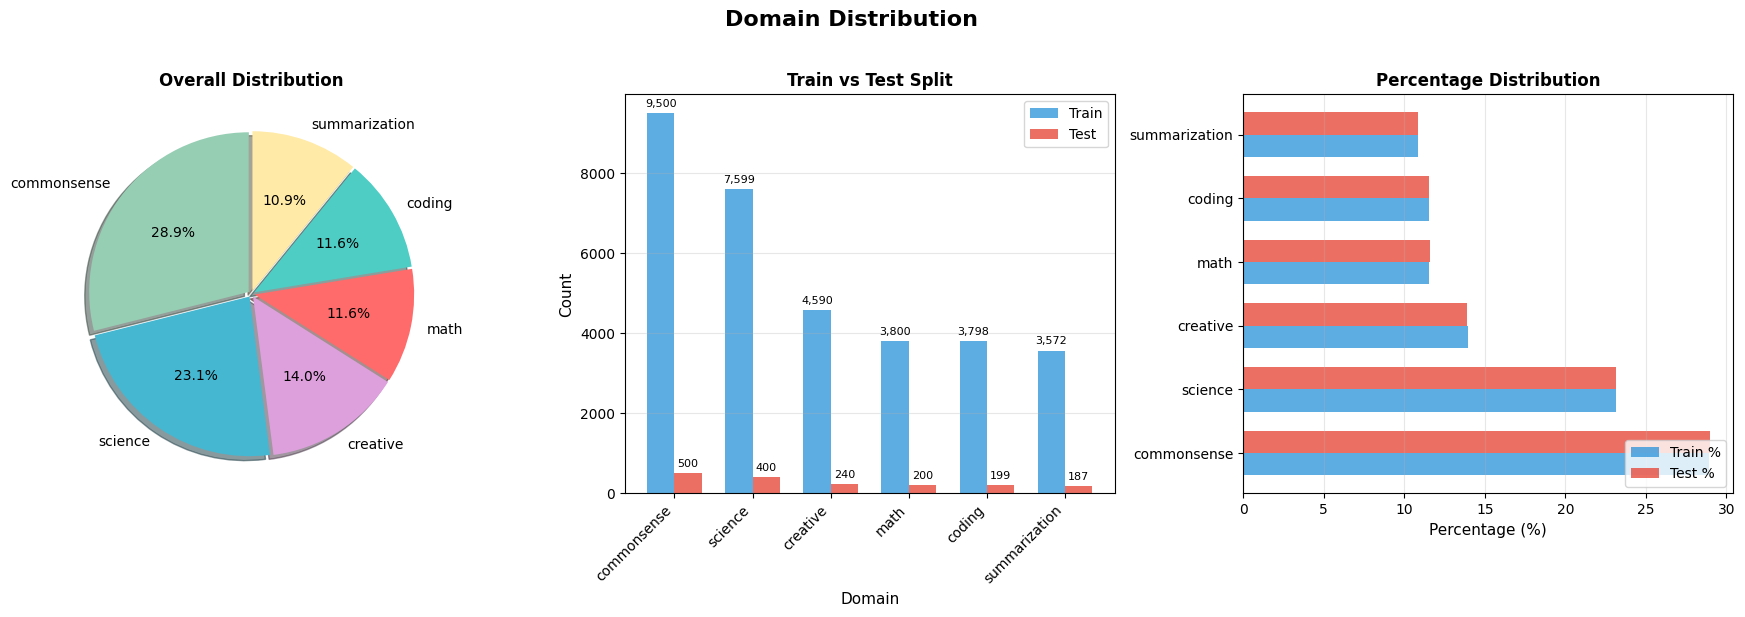

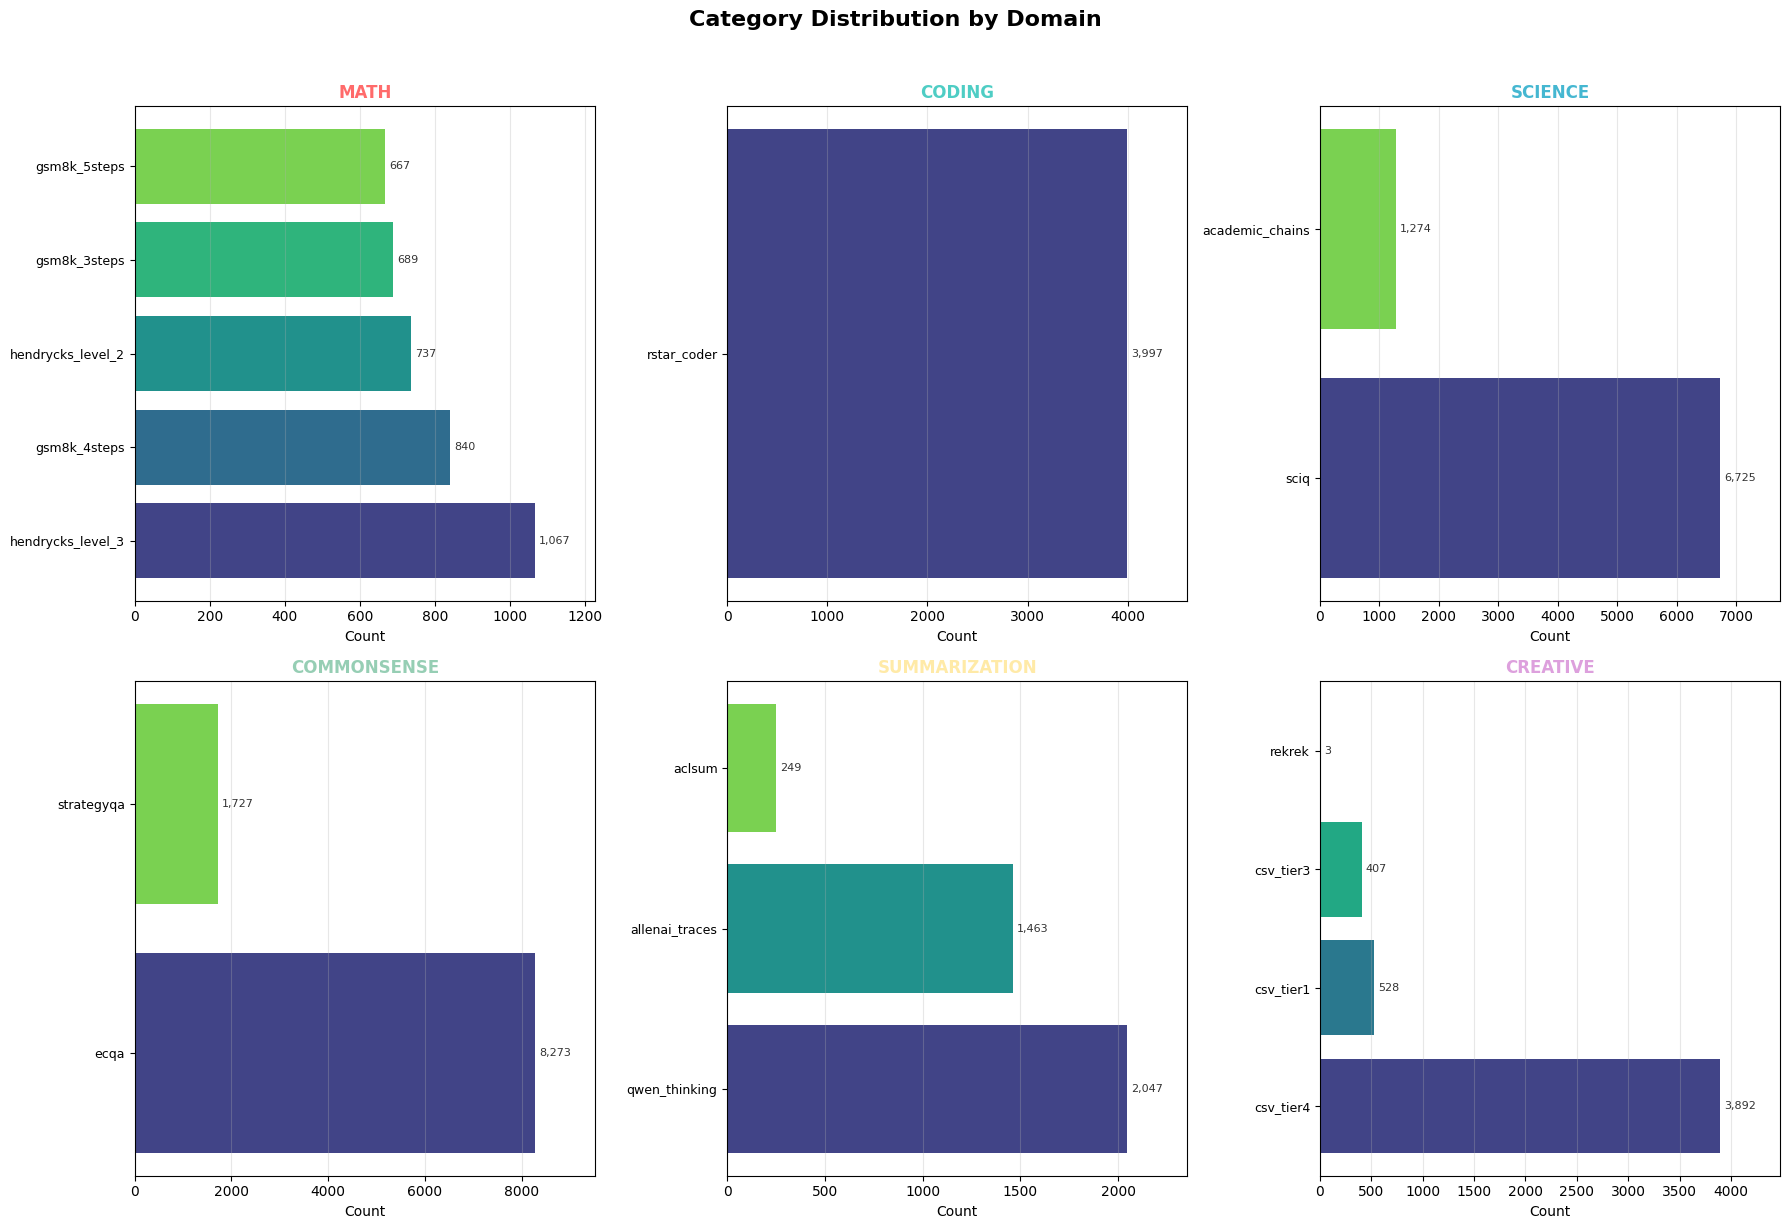

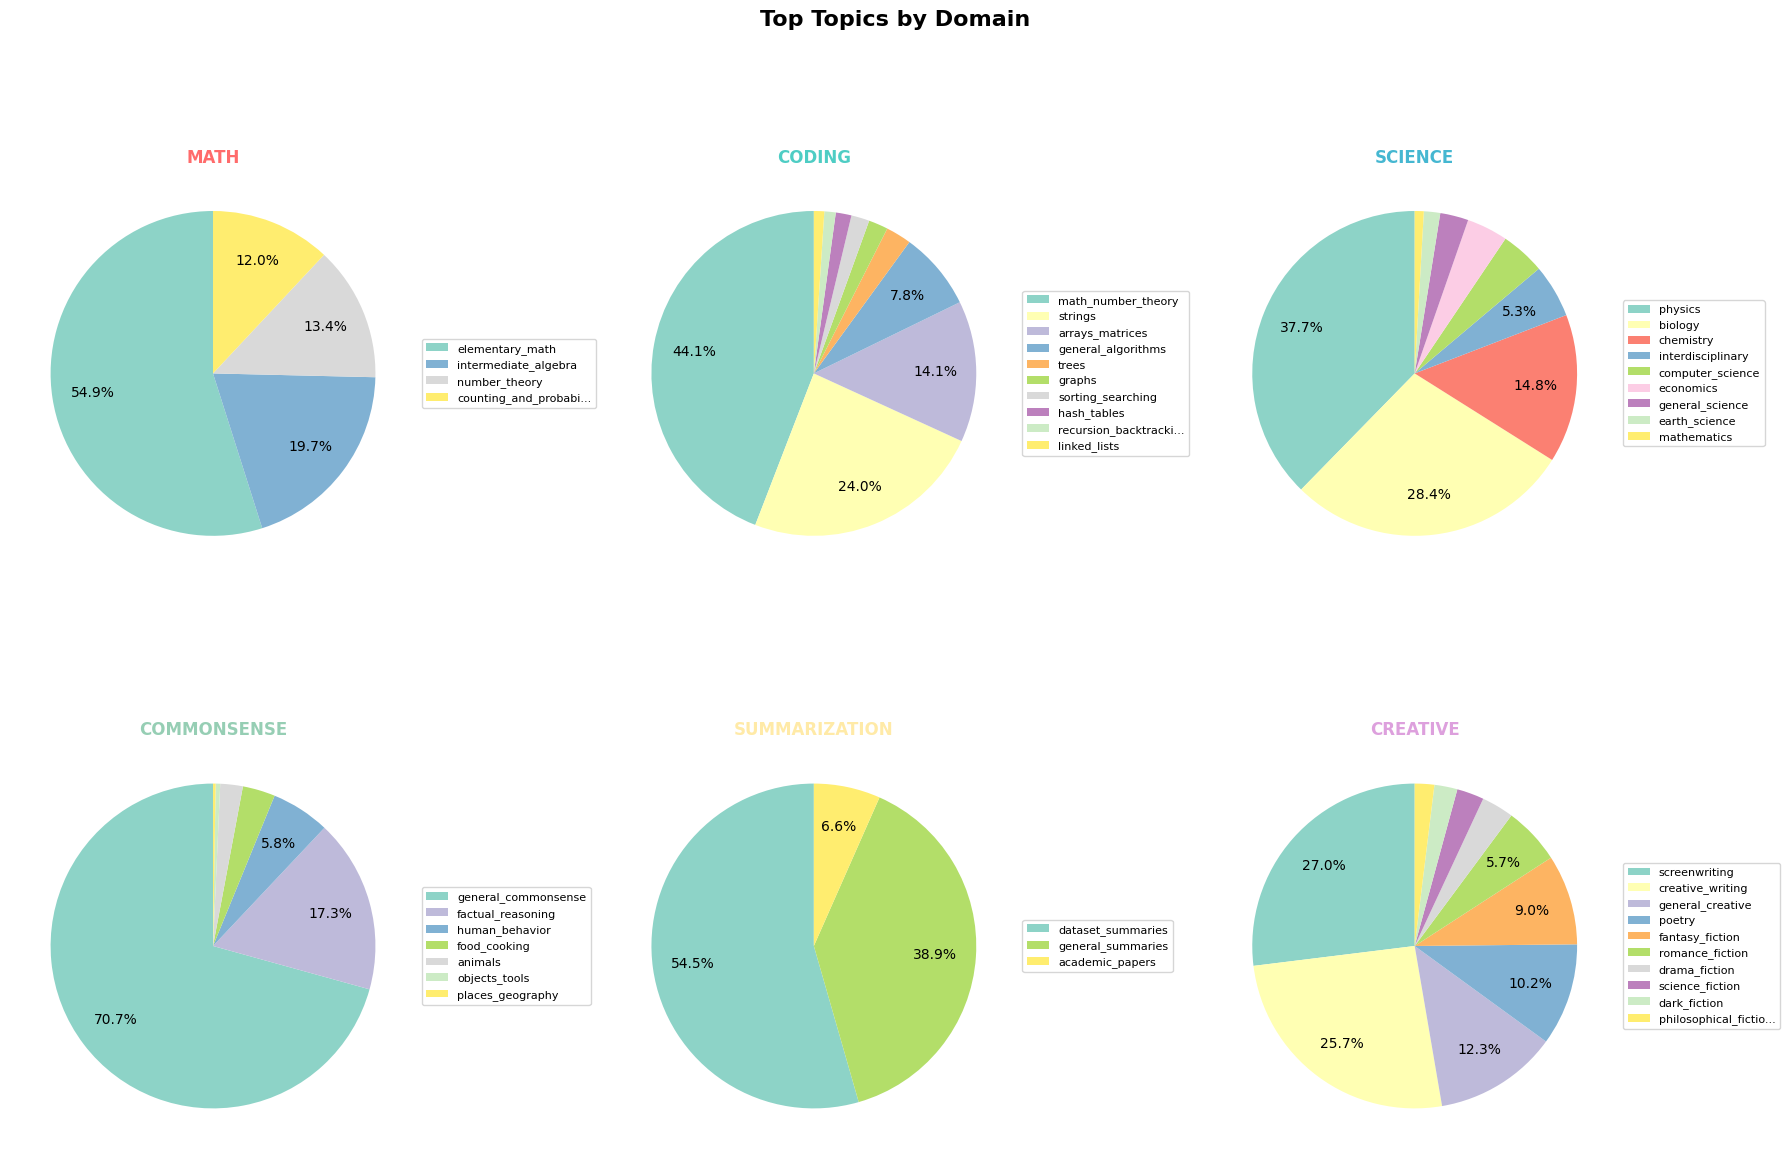

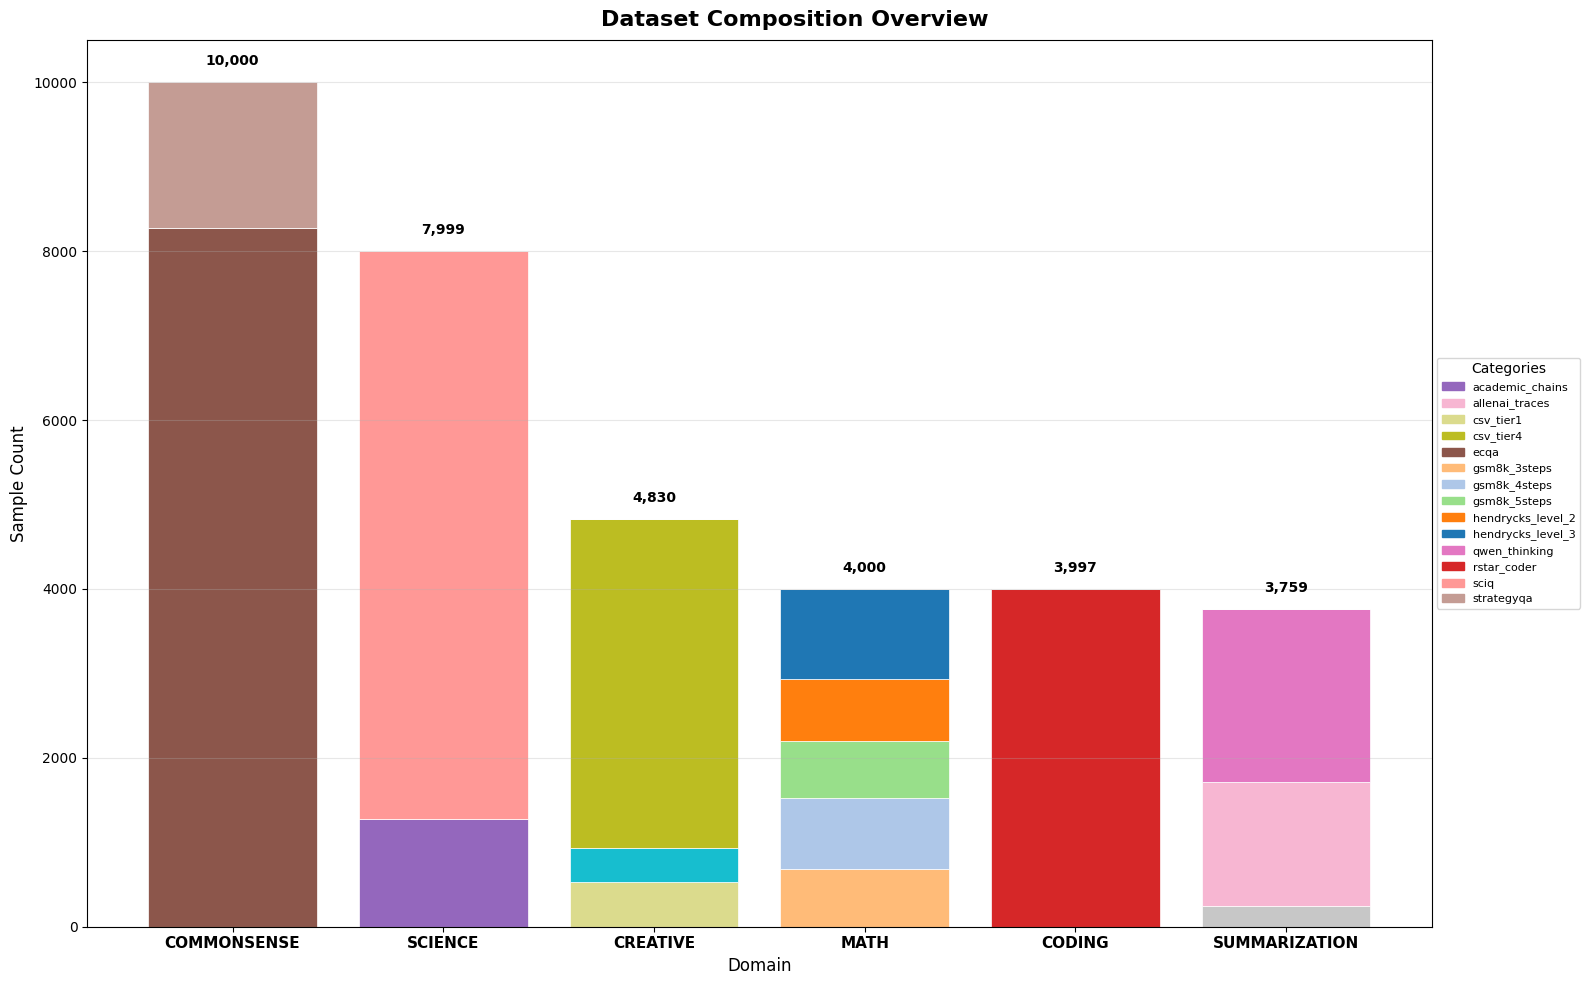

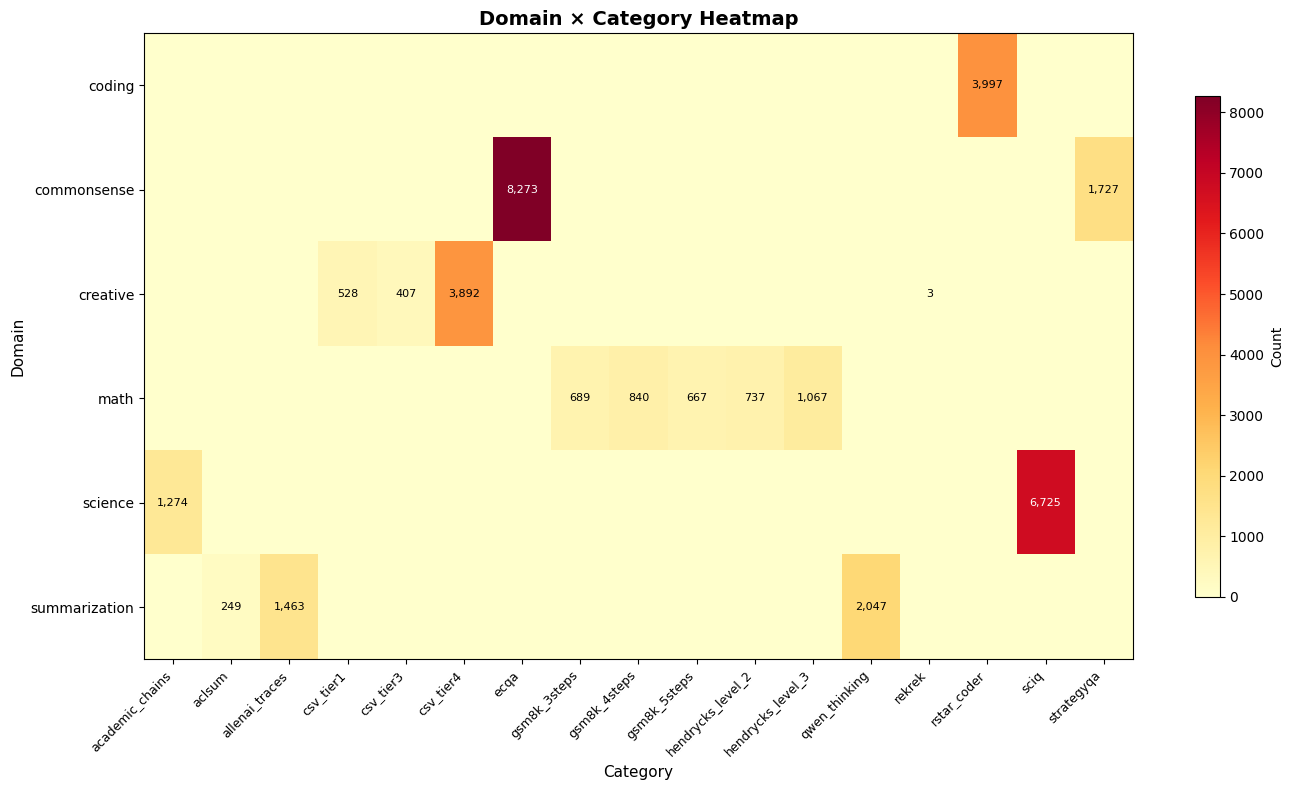


DETAILED DISTRIBUTION STATISTICS

                                OVERALL SUMMARY                                 
--------------------------------------------------------------------------------
  Total Train: 32,859
  Total Test:  1,726
  Grand Total: 34,585
  Train/Test Ratio: 95.0% / 5.0%

                                DOMAIN BREAKDOWN                                
--------------------------------------------------------------------------------
  Domain               Train       Test      Total   % of Total
  --------------- ---------- ---------- ---------- ------------
  math                 3,800        200      4,000        11.6%
  coding               3,798        199      3,997        11.6%
  science              7,599        400      7,999        23.1%
  commonsense          9,500        500     10,000        28.9%
  summarization        3,572        187      3,759        10.9%
  creative             4,590        240      4,830        14.0%

                          CAT

In [34]:
# ────────────────────────────────────────────────────────────────────────────
# GEMMA 3 DATASET DISTRIBUTION VISUALIZATION
# ────────────────────────────────────────────────────────────────────────────

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from collections import defaultdict, Counter

# Configuration
INPUT_DIR = Path("/kaggle/working/ds")
FILES = {
    'train': 'gemma3_formatted_train.jsonl',
    'test': 'gemma3_formatted_test.jsonl'
}

# Color palettes
DOMAIN_COLORS = {
    'math': '#FF6B6B',
    'coding': '#4ECDC4',
    'science': '#45B7D1',
    'commonsense': '#96CEB4',
    'summarization': '#FFEAA7',
    'creative': '#DDA0DD'
}

# Load data
print("Loading data...")
data = {'train': [], 'test': []}

for split, filename in FILES.items():
    filepath = INPUT_DIR / filename
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            ex = json.loads(line)
            data[split].append({
                'domain': ex['domain'],
                'category': ex['category'],
                'topic': ex['topic']
            })
    print(f"  {split}: {len(data[split]):,} examples loaded")

# Convert to DataFrames
df_train = pd.DataFrame(data['train'])
df_test = pd.DataFrame(data['test'])
df_all = pd.concat([df_train.assign(split='train'), df_test.assign(split='test')])

print(f"\nTotal: {len(df_all):,} examples")

# ────────────────────────────────────────────────────────────────────────────
# FIGURE 1: DOMAIN DISTRIBUTION (PIE + BAR)
# ────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Domain Distribution', fontsize=16, fontweight='bold', y=1.02)

# Pie chart - Overall
domain_counts = df_all['domain'].value_counts()
colors = [DOMAIN_COLORS.get(d, '#999999') for d in domain_counts.index]

wedges, texts, autotexts = axes[0].pie(
    domain_counts.values,
    labels=domain_counts.index,
    autopct='%1.1f%%',
    colors=colors,
    explode=[0.02] * len(domain_counts),
    shadow=True,
    startangle=90
)
axes[0].set_title('Overall Distribution', fontsize=12, fontweight='bold')

# Bar chart - Train vs Test
train_counts = df_train['domain'].value_counts().reindex(domain_counts.index, fill_value=0)
test_counts = df_test['domain'].value_counts().reindex(domain_counts.index, fill_value=0)

x = np.arange(len(domain_counts.index))
width = 0.35

bars1 = axes[1].bar(x - width/2, train_counts.values, width, label='Train', color='#3498db', alpha=0.8)
bars2 = axes[1].bar(x + width/2, test_counts.values, width, label='Test', color='#e74c3c', alpha=0.8)

axes[1].set_xlabel('Domain', fontsize=11)
axes[1].set_ylabel('Count', fontsize=11)
axes[1].set_title('Train vs Test Split', fontsize=12, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(domain_counts.index, rotation=45, ha='right')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

# Add value labels on bars
for bar in bars1:
    height = bar.get_height()
    axes[1].annotate(f'{int(height):,}', xy=(bar.get_x() + bar.get_width()/2, height),
                     xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8)
for bar in bars2:
    height = bar.get_height()
    axes[1].annotate(f'{int(height):,}', xy=(bar.get_x() + bar.get_width()/2, height),
                     xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8)

# Stacked horizontal bar - Percentage view
train_pct = train_counts / train_counts.sum() * 100
test_pct = test_counts / test_counts.sum() * 100

y = np.arange(len(domain_counts.index))
height = 0.35

axes[2].barh(y - height/2, train_pct.values, height, label='Train %', color='#3498db', alpha=0.8)
axes[2].barh(y + height/2, test_pct.values, height, label='Test %', color='#e74c3c', alpha=0.8)

axes[2].set_xlabel('Percentage (%)', fontsize=11)
axes[2].set_title('Percentage Distribution', fontsize=12, fontweight='bold')
axes[2].set_yticks(y)
axes[2].set_yticklabels(domain_counts.index)
axes[2].legend(loc='lower right')
axes[2].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(INPUT_DIR / 'distribution_domains.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

# ────────────────────────────────────────────────────────────────────────────
# FIGURE 2: CATEGORY DISTRIBUTION BY DOMAIN
# ────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('Category Distribution by Domain', fontsize=16, fontweight='bold', y=1.02)

domains = ['math', 'coding', 'science', 'commonsense', 'summarization', 'creative']

for idx, domain in enumerate(domains):
    ax = axes[idx // 3, idx % 3]
    
    domain_data = df_all[df_all['domain'] == domain]
    cat_counts = domain_data['category'].value_counts()
    
    # Horizontal bar chart
    colors_gradient = plt.cm.viridis(np.linspace(0.2, 0.8, len(cat_counts)))
    bars = ax.barh(range(len(cat_counts)), cat_counts.values, color=colors_gradient)
    
    ax.set_yticks(range(len(cat_counts)))
    ax.set_yticklabels(cat_counts.index, fontsize=9)
    ax.set_xlabel('Count', fontsize=10)
    ax.set_title(f'{domain.upper()}', fontsize=12, fontweight='bold', 
                 color=DOMAIN_COLORS.get(domain, '#333333'))
    ax.grid(axis='x', alpha=0.3)
    
    # Add value labels
    for i, (bar, val) in enumerate(zip(bars, cat_counts.values)):
        ax.text(val + max(cat_counts.values) * 0.01, i, f'{val:,}', 
                va='center', fontsize=8, color='#333333')
    
    ax.set_xlim(0, max(cat_counts.values) * 1.15)

plt.tight_layout()
plt.savefig(INPUT_DIR / 'distribution_categories.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

# ────────────────────────────────────────────────────────────────────────────
# FIGURE 3: TOPIC DISTRIBUTION BY DOMAIN (TOP 10 PER DOMAIN)
# ────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('Top Topics by Domain', fontsize=16, fontweight='bold', y=1.02)

for idx, domain in enumerate(domains):
    ax = axes[idx // 3, idx % 3]
    
    domain_data = df_all[df_all['domain'] == domain]
    topic_counts = domain_data['topic'].value_counts().head(10)
    
    # Pie chart for topics
    if len(topic_counts) > 0:
        colors_pie = plt.cm.Set3(np.linspace(0, 1, len(topic_counts)))
        wedges, texts, autotexts = ax.pie(
            topic_counts.values,
            labels=None,
            autopct=lambda pct: f'{pct:.1f}%' if pct > 5 else '',
            colors=colors_pie,
            startangle=90,
            pctdistance=0.75
        )
        
        # Legend
        ax.legend(wedges, [f'{t[:20]}...' if len(t) > 20 else t for t in topic_counts.index],
                  loc='center left', bbox_to_anchor=(1, 0.5), fontsize=8)
    
    ax.set_title(f'{domain.upper()}', fontsize=12, fontweight='bold',
                 color=DOMAIN_COLORS.get(domain, '#333333'))

plt.tight_layout()
plt.savefig(INPUT_DIR / 'distribution_topics.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

# ────────────────────────────────────────────────────────────────────────────
# FIGURE 4: COMPREHENSIVE TREEMAP-STYLE VISUALIZATION
# ────────────────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(16, 10))
fig.suptitle('Dataset Composition Overview', fontsize=16, fontweight='bold', y=0.98)

# Create hierarchical data
hierarchy_data = []
for domain in domains:
    domain_data = df_all[df_all['domain'] == domain]
    cats = domain_data['category'].value_counts()
    for cat, count in cats.items():
        hierarchy_data.append({
            'domain': domain,
            'category': cat,
            'count': count
        })

hierarchy_df = pd.DataFrame(hierarchy_data)

# Stacked bar by domain
domain_order = df_all['domain'].value_counts().index.tolist()
categories_per_domain = {}

for domain in domain_order:
    cats = hierarchy_df[hierarchy_df['domain'] == domain].set_index('category')['count'].to_dict()
    categories_per_domain[domain] = cats

# Build stacked bars
x_positions = np.arange(len(domain_order))
bottom = np.zeros(len(domain_order))

all_categories = hierarchy_df['category'].unique()
category_colors = plt.cm.tab20(np.linspace(0, 1, len(all_categories)))
cat_color_map = dict(zip(all_categories, category_colors))

legend_handles = []
legend_labels = []

for cat in sorted(all_categories):
    heights = []
    for domain in domain_order:
        heights.append(categories_per_domain[domain].get(cat, 0))
    
    heights = np.array(heights)
    if heights.sum() > 0:  # Only plot if category has data
        bars = ax.bar(x_positions, heights, bottom=bottom, label=cat, 
                     color=cat_color_map[cat], edgecolor='white', linewidth=0.5)
        bottom += heights
        
        if heights.sum() > 500:  # Only add to legend if significant
            legend_handles.append(mpatches.Patch(color=cat_color_map[cat]))
            legend_labels.append(cat)

ax.set_xticks(x_positions)
ax.set_xticklabels([d.upper() for d in domain_order], fontsize=11, fontweight='bold')
ax.set_ylabel('Sample Count', fontsize=12)
ax.set_xlabel('Domain', fontsize=12)
ax.grid(axis='y', alpha=0.3)

# Add total labels on top
for i, domain in enumerate(domain_order):
    total = df_all[df_all['domain'] == domain].shape[0]
    ax.text(i, total + 200, f'{total:,}', ha='center', fontsize=10, fontweight='bold')

# Legend outside
ax.legend(legend_handles, legend_labels, loc='center left', bbox_to_anchor=(1, 0.5), 
          fontsize=8, title='Categories', title_fontsize=10)

plt.tight_layout()
plt.savefig(INPUT_DIR / 'distribution_stacked.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

# ────────────────────────────────────────────────────────────────────────────
# FIGURE 5: HEATMAP - DOMAIN x CATEGORY MATRIX
# ────────────────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(14, 8))

# Create pivot table
pivot = pd.crosstab(df_all['domain'], df_all['category'])

# Heatmap
im = ax.imshow(pivot.values, cmap='YlOrRd', aspect='auto')

# Labels
ax.set_xticks(np.arange(len(pivot.columns)))
ax.set_yticks(np.arange(len(pivot.index)))
ax.set_xticklabels(pivot.columns, rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(pivot.index, fontsize=10)

# Add text annotations
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        val = pivot.iloc[i, j]
        if val > 0:
            text_color = 'white' if val > pivot.values.max() * 0.5 else 'black'
            ax.text(j, i, f'{val:,}', ha='center', va='center', 
                   color=text_color, fontsize=8)

ax.set_title('Domain × Category Heatmap', fontsize=14, fontweight='bold')
ax.set_xlabel('Category', fontsize=11)
ax.set_ylabel('Domain', fontsize=11)

# Colorbar
cbar = plt.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label('Count', fontsize=10)

plt.tight_layout()
plt.savefig(INPUT_DIR / 'distribution_heatmap.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

# ────────────────────────────────────────────────────────────────────────────
# PRINT DETAILED STATISTICS TABLE
# ────────────────────────────────────────────────────────────────────────────

print("\n" + "=" * 80)
print("DETAILED DISTRIBUTION STATISTICS")
print("=" * 80)

# Overall
print(f"\n{'OVERALL SUMMARY':^80}")
print("-" * 80)
print(f"  Total Train: {len(df_train):,}")
print(f"  Total Test:  {len(df_test):,}")
print(f"  Grand Total: {len(df_all):,}")
print(f"  Train/Test Ratio: {len(df_train)/len(df_all)*100:.1f}% / {len(df_test)/len(df_all)*100:.1f}%")

# Domain breakdown
print(f"\n{'DOMAIN BREAKDOWN':^80}")
print("-" * 80)
print(f"  {'Domain':<15} {'Train':>10} {'Test':>10} {'Total':>10} {'% of Total':>12}")
print(f"  {'-'*15} {'-'*10} {'-'*10} {'-'*10} {'-'*12}")

for domain in domains:
    train_c = len(df_train[df_train['domain'] == domain])
    test_c = len(df_test[df_test['domain'] == domain])
    total_c = train_c + test_c
    pct = total_c / len(df_all) * 100
    print(f"  {domain:<15} {train_c:>10,} {test_c:>10,} {total_c:>10,} {pct:>11.1f}%")

# Category breakdown by domain
print(f"\n{'CATEGORY BREAKDOWN BY DOMAIN':^80}")
print("-" * 80)

for domain in domains:
    domain_data = df_all[df_all['domain'] == domain]
    print(f"\n  {domain.upper()} ({len(domain_data):,} total)")
    print(f"  {'Category':<30} {'Count':>10} {'% of Domain':>12}")
    print(f"  {'-'*30} {'-'*10} {'-'*12}")
    
    for cat, count in domain_data['category'].value_counts().items():
        pct = count / len(domain_data) * 100
        print(f"  {cat:<30} {count:>10,} {pct:>11.1f}%")

# Topic breakdown by domain
print(f"\n{'TOP TOPICS BY DOMAIN':^80}")
print("-" * 80)

for domain in domains:
    domain_data = df_all[df_all['domain'] == domain]
    print(f"\n  {domain.upper()}")
    print(f"  {'Topic':<35} {'Count':>10} {'% of Domain':>12}")
    print(f"  {'-'*35} {'-'*10} {'-'*12}")
    
    for topic, count in domain_data['topic'].value_counts().head(8).items():
        pct = count / len(domain_data) * 100
        topic_display = topic[:32] + '...' if len(topic) > 35 else topic
        print(f"  {topic_display:<35} {count:>10,} {pct:>11.1f}%")

print("\n" + "=" * 80)
print("VISUALIZATIONS SAVED:")
print("=" * 80)
print(f"  • {INPUT_DIR / 'distribution_domains.png'}")
print(f"  • {INPUT_DIR / 'distribution_categories.png'}")
print(f"  • {INPUT_DIR / 'distribution_topics.png'}")
print(f"  • {INPUT_DIR / 'distribution_stacked.png'}")
print(f"  • {INPUT_DIR / 'distribution_heatmap.png'}")
print("=" * 80)

---

In [35]:
# Download ds/ contents
# ────────────────────────────────────────────────────────────────────────────
# ZIP ALL OUTPUT FILES FOR DOWNLOAD
# ────────────────────────────────────────────────────────────────────────────

import shutil
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/ds")
ZIP_PATH = "/kaggle/working/gemma3_dataset_v0"

# List files
print("Files to zip:")
for f in sorted(OUTPUT_DIR.iterdir()):
    print(f"  • {f.name} ({f.stat().st_size / 1024 / 1024:.2f} MB)")

# Create zip
shutil.make_archive(ZIP_PATH, 'zip', OUTPUT_DIR)

zip_file = Path(f"{ZIP_PATH}.zip")
print(f"\n✓ Created: {zip_file.name} ({zip_file.stat().st_size / 1024 / 1024:.2f} MB)")

Files to zip:
  • distribution_categories.png (0.12 MB)
  • distribution_domains.png (0.16 MB)
  • distribution_heatmap.png (0.12 MB)
  • distribution_stacked.png (0.10 MB)
  • distribution_topics.png (0.30 MB)
  • gemma3-1B-tunix-finetune-unified_test.jsonl (3.49 MB)
  • gemma3-1B-tunix-finetune-unified_test.parquet (1.67 MB)
  • gemma3-1B-tunix-finetune-unified_train.jsonl (99.15 MB)
  • gemma3-1B-tunix-finetune-unified_train.parquet (49.10 MB)
  • gemma3_formatted_test.jsonl (3.61 MB)
  • gemma3_formatted_train.jsonl (101.80 MB)
  • the_coding_test.jsonl (0.79 MB)
  • the_coding_train.jsonl (30.41 MB)
  • the_commonsense_test.jsonl (0.26 MB)
  • the_commonsense_train.jsonl (6.83 MB)
  • the_creative_test.jsonl (0.38 MB)
  • the_creative_train.jsonl (21.44 MB)
  • the_math_gsm8k_test.jsonl (0.82 MB)
  • the_math_test.jsonl (0.14 MB)
  • the_math_train.jsonl (2.77 MB)
  • the_science_test.jsonl (0.46 MB)
  • the_science_train.jsonl (16.44 MB)
  • the_summarization_test.jsonl (1.54 MB)